In [1]:
suppressPackageStartupMessages({
    library(tradeSeq)
    library(dplyr)
    library(tidyr)
    library(ggplot2)
    library(matrixStats)
    library(cluster)
    library(RColorBrewer)
    library(SingleCellExperiment)
    library(slingshot)
    library(Matrix)
    library(SingleCellExperiment)
    library(BiocParallel)
    library(ggrepel)
    library(patchwork)
    library(dplyr)
    library(tidyr)
    library(purrr)
    library(tibble)
    library(cluster)
    library(ggplot2)
    library(tibble)
    library(SingleCellExperiment)
    library(S4Vectors)
    library(dplyr)
    library(tidyr)
    library(stringr)
})

RNGversion("3.5.0") # For reproducibility
palette(brewer.pal(8, "Dark2"))

setwd('../intmd/sc-K562-1e6-to-tradeSeq/')

Warning message in RNGkind("Mersenne-Twister", "Inversion", "Rounding"):
"non-uniform 'Rounding' sampler used"


## Functions

In [2]:
feature_plot_pc_simple <- function(
  pc_df,
  feature,
  x = "PC1",
  y = "PC2",
  palette = "viridis",
  title = NULL,
  colorbar_title = NULL,
  point_size = 1.2,      # scalar, or named vector mapping categorical feature levels -> sizes
  viridis_direction = 1,
  cap = NULL,
  floor = NULL,
  alpha_col = NULL,
  midpoint = NULL,
  mid_gamma = 1,
  plot_order = NULL,     # NULL, "plot_highest_last", "plot_nonzero_last", or "plot_highest_alpha_last"
  cat_colors = NULL,     # named vector for categorical feature colors and gene highlight colors
  cat_plot_order = NULL,
  base_size = 12,
  title_size = 12,
  axis_title_size = 11,
  axis_text_size = 10,
  legend_title_size = 10,
  legend_text_size = 9,
  show_legend = TRUE,
  show_ticks = TRUE,
  show_genes = NULL,         # character vector of genes to label
  gene_color_col = "broad_cluster",
  gene_label_style = c("box", "shadow"),
  gene_label_size = 3,
  gene_point_size = NULL,
  gene_label_color = "black",
  gene_label_nudge_x = NULL,
  gene_label_nudge_y = NULL,
  gene_label_fill = grDevices::adjustcolor("white", alpha.f = 0.88),
  gene_label_padding = 0.10,     # lines, for box labels
  gene_box_padding = 0.30,
  gene_point_padding = 0.15,
  gene_label_bg_col = "white",   # halo color for shadow mode
  gene_label_bg_r = 0.12,
  gene_label_segment_color = "grey45",
  gene_label_segment_size = 0.25,
  gene_label_seed = 1,
  check_overlap = FALSE          # only relevant for shadow mode
) {
  stopifnot(is.data.frame(pc_df))
  stopifnot(all(c(x, y, feature) %in% colnames(pc_df)))
  if (!is.null(alpha_col)) stopifnot(alpha_col %in% colnames(pc_df))

  if (!is.null(plot_order)) {
    stopifnot(plot_order %in% c(
      "plot_highest_last",
      "plot_nonzero_last",
      "plot_highest_alpha_last"
    ))
  }

    gene_label_style <- match.arg(gene_label_style)
    
    palette_input <- palette
    palette_key <- tolower(palette_input)
    
    # keep your existing shorthand aliases working
    brewer_aliases <- c(
      greys   = "Greys",
      blues   = "Blues",
      reds    = "Reds",
      greens  = "Greens",
      purples = "Purples",
      ylorrd  = "YlOrRd",
      ylgnbu  = "YlGnBu",
      gnbu    = "GnBu",
      pubu    = "PuBu",
      orrd    = "OrRd",
      bugn    = "BuGn"
    )
    
    brewer_name <- NULL
    
    if (palette_key %in% c("viridis", "magma", "plasma", "inferno", "cividis", "rwb")) {
      palette <- palette_key
    } else if (palette_key %in% names(brewer_aliases)) {
      palette <- palette_key
      brewer_name <- unname(brewer_aliases[palette_key])
    } else if (requireNamespace("RColorBrewer", quietly = TRUE) &&
               palette_input %in% rownames(RColorBrewer::brewer.pal.info)) {
      palette <- palette_input
      brewer_name <- palette_input
    } else if (requireNamespace("RColorBrewer", quietly = TRUE) &&
               palette_key %in% tolower(rownames(RColorBrewer::brewer.pal.info))) {
      brewer_name <- rownames(RColorBrewer::brewer.pal.info)[
        match(palette_key, tolower(rownames(RColorBrewer::brewer.pal.info)))
      ]
      palette <- brewer_name
    } else {
      stop(
        "Unsupported palette: ", palette_input,
        ". Use a viridis option, 'rwb', one of the existing aliases, ",
        "or any valid RColorBrewer palette name."
      )
    }

  if (!is.numeric(mid_gamma) || length(mid_gamma) != 1 || mid_gamma <= 0) {
    stop("mid_gamma must be a single positive number.")
  }

  if (is.null(title)) {
    title <- paste0("PCA (", feature, ")")
  }
  if (is.null(colorbar_title)) {
    colorbar_title <- feature
  }

  df_plot <- pc_df
  df_plot$.row_id <- if (!is.null(rownames(df_plot))) rownames(df_plot) else as.character(seq_len(nrow(df_plot)))

  # Parse rownames of form {gene}_{cell_type} using the last underscore
  df_plot$.parsed_gene <- sub("_(?=[^_]+$).*", "", df_plot$.row_id, perl = TRUE)
  df_plot$.parsed_gene[df_plot$.parsed_gene == ""] <- df_plot$.row_id

  v <- df_plot[[feature]]
  is_num <- is.numeric(v)

  if (is_num) {
    if (!is.null(cap))   v[v > cap]   <- cap
    if (!is.null(floor)) v[v < floor] <- floor
    df_plot[[feature]] <- v

    lo <- min(df_plot[[feature]], na.rm = TRUE)
    hi <- max(df_plot[[feature]], na.rm = TRUE)
  } else {
    df_plot[[feature]] <- as.factor(df_plot[[feature]])
    levs <- levels(df_plot[[feature]])

    if (!is.null(cat_plot_order)) {
      if (!is.character(cat_plot_order)) {
        stop("cat_plot_order must be a character vector of factor levels.")
      }

      unknown_levs <- setdiff(cat_plot_order, levs)
      if (length(unknown_levs) > 0) {
        stop(
          "cat_plot_order contains unknown levels: ",
          paste(unknown_levs, collapse = ", ")
        )
      }

      levs <- c(cat_plot_order, setdiff(levs, cat_plot_order))
      df_plot[[feature]] <- factor(df_plot[[feature]], levels = levs)
    }

    levs <- levels(df_plot[[feature]])

    if (!is.null(cat_colors)) {
      if (!is.character(cat_colors)) {
        stop("cat_colors must be a character vector of color values.")
      }

      if (!is.null(names(cat_colors)) && all(nzchar(names(cat_colors)))) {
        missing_levs <- setdiff(levs, names(cat_colors))
        if (length(missing_levs) > 0) {
          stop(
            "cat_colors is missing colors for these levels: ",
            paste(missing_levs, collapse = ", ")
          )
        }
        cat_colors <- cat_colors[levs]
      } else {
        if (length(cat_colors) < length(levs)) {
          stop(
            "cat_colors has fewer colors than the number of categorical levels (",
            length(levs), ")."
          )
        }
        cat_colors <- cat_colors[seq_along(levs)]
        names(cat_colors) <- levs
      }
    }
  }

  # Resolve point sizes
  scalar_point_size <- is.numeric(point_size) && length(point_size) == 1 && !is.na(point_size)

  if (scalar_point_size) {
    point_size_scalar <- point_size
    use_size_mapping <- FALSE
  } else {
    if (is_num) {
      stop("If feature is numeric, point_size must be a single numeric value.")
    }
    if (!is.numeric(point_size)) {
      stop("point_size must be either a single numeric value or a numeric vector.")
    }

    levs <- levels(df_plot[[feature]])

    if (!is.null(names(point_size)) && all(nzchar(names(point_size)))) {
      missing_levs <- setdiff(levs, names(point_size))
      if (length(missing_levs) > 0) {
        stop(
          "point_size is missing sizes for these levels: ",
          paste(missing_levs, collapse = ", ")
        )
      }
      point_size_map <- point_size[levs]
    } else {
      if (length(point_size) < length(levs)) {
        stop(
          "point_size has fewer values than the number of categorical levels (",
          length(levs), ")."
        )
      }
      point_size_map <- point_size[seq_along(levs)]
      names(point_size_map) <- levs
    }

    df_plot$.point_size <- unname(point_size_map[as.character(df_plot[[feature]])])
    use_size_mapping <- TRUE
  }

  # Plotting order
  if (!is.null(plot_order)) {
    if (plot_order == "plot_highest_alpha_last") {
      if (is.null(alpha_col)) {
        stop("plot_order = 'plot_highest_alpha_last' requires alpha_col to be provided.")
      }
      ord <- order(df_plot[[alpha_col]], na.last = TRUE)
      df_plot <- df_plot[ord, , drop = FALSE]

    } else {
      if (!is_num) {
        warning("plot_order based on feature magnitude is only applied for numeric features.")
      } else {
        if (plot_order == "plot_highest_last") {
          ord <- order(df_plot[[feature]], na.last = TRUE)
        } else if (plot_order == "plot_nonzero_last") {
          ord <- order(abs(df_plot[[feature]]), na.last = TRUE)
        }
        df_plot <- df_plot[ord, , drop = FALSE]
      }
    }
  }

  if (!is_num && !is.null(cat_plot_order)) {
    ord <- order(match(as.character(df_plot[[feature]]), levels(df_plot[[feature]])), na.last = TRUE)
    df_plot <- df_plot[ord, , drop = FALSE]
  }

  if (is.null(alpha_col) && !use_size_mapping) {
    aes_map <- ggplot2::aes_string(x = x, y = y, color = feature)
  } else if (!is.null(alpha_col) && !use_size_mapping) {
    aes_map <- ggplot2::aes_string(x = x, y = y, color = feature, alpha = alpha_col)
  } else if (is.null(alpha_col) && use_size_mapping) {
    aes_map <- ggplot2::aes_string(x = x, y = y, color = feature, size = ".point_size")
  } else {
    aes_map <- ggplot2::aes_string(x = x, y = y, color = feature, alpha = alpha_col, size = ".point_size")
  }

  p <- ggplot2::ggplot(df_plot, aes_map)

  if (use_size_mapping) {
    p <- p + ggplot2::geom_point(shape = 16)
  } else {
    p <- p + ggplot2::geom_point(size = point_size_scalar, shape = 16)
  }

  p <- p +
    ggplot2::labs(
      title = title,
      x = x,
      y = y,
      color = colorbar_title
    ) +
    ggplot2::scale_x_continuous(
      breaks = c(-10, 0, 10),
      expand = ggplot2::expansion(mult = c(0.06, 0.06))
    ) +
    ggplot2::scale_y_continuous(
      breaks = c(-10, 0, 10),
      expand = ggplot2::expansion(mult = c(0.06, 0.06))
    ) +
    ggplot2::theme_classic(base_size = base_size) +
    ggplot2::theme(
      legend.position = if (show_legend) "right" else "none",
      plot.title   = ggplot2::element_text(size = title_size),
      axis.title.x = ggplot2::element_text(size = axis_title_size),
      axis.title.y = ggplot2::element_text(size = axis_title_size),
      axis.text.x  = if (show_ticks) ggplot2::element_text(size = axis_text_size) else ggplot2::element_blank(),
      axis.text.y  = if (show_ticks) ggplot2::element_text(size = axis_text_size) else ggplot2::element_blank(),
      axis.ticks.x = if (show_ticks) ggplot2::element_line() else ggplot2::element_blank(),
      axis.ticks.y = if (show_ticks) ggplot2::element_line() else ggplot2::element_blank(),
      legend.title = ggplot2::element_text(size = legend_title_size),
      legend.text  = ggplot2::element_text(size = legend_text_size),
      plot.margin  = ggplot2::margin(8, 14, 8, 14)
    ) +
    ggplot2::coord_cartesian(clip = "off")

  if (!is.null(alpha_col)) {
    p <- p + ggplot2::scale_alpha_identity()
  }

  if (use_size_mapping) {
    p <- p + ggplot2::scale_size_identity()
  }

  if (!is_num) {
    if (is.null(cat_colors)) {
      p <- p + ggplot2::scale_color_discrete(drop = FALSE)
    } else {
      p <- p + ggplot2::scale_color_manual(values = cat_colors, drop = FALSE)
    }
  } else if (palette == "rwb") {
    if (is.null(midpoint)) midpoint <- 0

    vals_raw <- seq(lo, hi, length.out = 256)
    s <- numeric(length(vals_raw))

    left <- vals_raw <= midpoint
    right <- vals_raw >= midpoint

    if (any(left)) {
      denom_left <- max(midpoint - lo, .Machine$double.eps)
      s[left] <- -((midpoint - vals_raw[left]) / denom_left)
    }
    if (any(right)) {
      denom_right <- max(hi - midpoint, .Machine$double.eps)
      s[right] <- ((vals_raw[right] - midpoint) / denom_right)
    }

    s2 <- sign(s) * abs(s)^mid_gamma
    vals_scaled <- (s2 + 1) / 2

    p <- p + ggplot2::scale_color_gradientn(
      colours = grDevices::colorRampPalette(c("blue", "white", "red"))(256),
      values = vals_scaled,
      limits = c(lo, hi),
      guide = ggplot2::guide_colorbar(title = colorbar_title)
    )
    } else if (!is.null(brewer_name)) {
      p <- p + ggplot2::scale_color_distiller(
        palette = brewer_name,
        direction = 1,
        limits = c(lo, hi),
        guide = ggplot2::guide_colorbar(title = colorbar_title))
      } else {
    p <- p + ggplot2::scale_color_viridis_c(
      option = palette,
      direction = viridis_direction,
      limits = c(lo, hi),
      guide = ggplot2::guide_colorbar(title = colorbar_title)
    )
  }

  if (!show_legend) {
    p <- p + ggplot2::guides(color = "none")
  }

  # Gene highlighting and labels
  if (!is.null(show_genes)) {
    if (!is.character(show_genes)) {
      stop("show_genes must be NULL or a character vector.")
    }

    label_match <- df_plot$.row_id %in% show_genes | df_plot$.parsed_gene %in% show_genes
    label_text <- df_plot$.parsed_gene

    if ("gene_sym" %in% colnames(df_plot)) {
      gene_sym_chr <- as.character(df_plot$gene_sym)
      label_match <- label_match | gene_sym_chr %in% show_genes
      label_text <- ifelse(!is.na(gene_sym_chr) & nzchar(gene_sym_chr), gene_sym_chr, df_plot$.parsed_gene)
    }

    label_df <- df_plot[label_match, , drop = FALSE]
    label_df$.label <- label_text[label_match]

    if (nrow(label_df) > 0) {
      # highlighted dot colors come from category colors if available
      label_df$.dot_col <- rep("black", nrow(label_df))

      if (!is.null(cat_colors) &&
          !is.null(gene_color_col) &&
          gene_color_col %in% colnames(label_df) &&
          !is.null(names(cat_colors))) {
        gene_cat <- as.character(label_df[[gene_color_col]])
        ok <- !is.na(gene_cat) & gene_cat %in% names(cat_colors)
        label_df$.dot_col[ok] <- unname(cat_colors[gene_cat[ok]])
      }

      if (is.null(gene_point_size)) {
        if (scalar_point_size) {
          gene_point_size_use <- point_size_scalar * 1.8
        } else {
          gene_point_size_use <- max(df_plot$.point_size, na.rm = TRUE) * 1.35
        }
      } else {
        gene_point_size_use <- gene_point_size
      }

      # larger colored highlight dots
      p <- p + ggplot2::geom_point(
        data = label_df,
        mapping = ggplot2::aes_string(x = x, y = y),
        inherit.aes = FALSE,
        size = gene_point_size_use,
        shape = 16,
        colour = label_df$.dot_col
      )

      if (gene_label_style == "box") {
        if (!requireNamespace("ggrepel", quietly = TRUE)) {
          stop("Please install the ggrepel package to use gene_label_style = 'box'.")
        }

        p <- p + ggrepel::geom_label_repel(
          data = label_df,
          mapping = ggplot2::aes_string(x = x, y = y, label = ".label"),
          inherit.aes = FALSE,
          colour = gene_label_color,
          fill = gene_label_fill,
          label.size = 0,
          label.padding = grid::unit(gene_label_padding, "lines"),
          box.padding = gene_box_padding,
          point.padding = gene_point_padding,
          force = 1,
          force_pull = 0.2,
          max.overlaps = Inf,
          min.segment.length = 0,
          seed = gene_label_seed,
          segment.size = gene_label_segment_size,
          segment.color = gene_label_segment_color,
          size = gene_label_size / ggplot2::.pt
        )

      } else if (gene_label_style == "shadow") {
        if (!requireNamespace("shadowtext", quietly = TRUE)) {
          stop("Please install the shadowtext package to use gene_label_style = 'shadow'.")
        }

        xr <- range(df_plot[[x]], na.rm = TRUE)
        yr <- range(df_plot[[y]], na.rm = TRUE)
        xmid <- mean(xr)
        ymid <- mean(yr)

        dx_auto <- 0.04 * diff(xr)
        dy_auto <- 0.04 * diff(yr)
        pad_x <- 0.05 * diff(xr)
        pad_y <- 0.05 * diff(yr)

        dx_use <- if (is.null(gene_label_nudge_x)) dx_auto else gene_label_nudge_x
        dy_use <- if (is.null(gene_label_nudge_y)) dy_auto else gene_label_nudge_y

        label_df$.x_lab <- label_df[[x]] + ifelse(label_df[[x]] <= xmid, dx_use, -dx_use)
        label_df$.y_lab <- label_df[[y]] + ifelse(label_df[[y]] <= ymid, dy_use, -dy_use)

        # clamp inward so labels do not collide with axes / panel edge
        label_df$.x_lab <- pmin(pmax(label_df$.x_lab, xr[1] + pad_x), xr[2] - pad_x)
        label_df$.y_lab <- pmin(pmax(label_df$.y_lab, yr[1] + pad_y), yr[2] - pad_y)

        p <- p +
          ggplot2::geom_segment(
            data = label_df,
            mapping = ggplot2::aes_string(x = x, y = y, xend = ".x_lab", yend = ".y_lab"),
            inherit.aes = FALSE,
            colour = gene_label_segment_color,
            linewidth = gene_label_segment_size
          ) +
        shadowtext::geom_shadowtext(
          data = label_df,
          mapping = ggplot2::aes(x = .x_lab, y = .y_lab, label = .label),
          inherit.aes = FALSE,
          colour = gene_label_color,
          bg.colour = gene_label_bg_col,
          bg.r = gene_label_bg_r,
          size = gene_label_size / ggplot2::.pt,
          fontface = "plain",
          check_overlap = check_overlap
        )
      }
    }
  }

  p
}

In [3]:
# plot_tradeSeq_gene_multirun_pub <- function(
#   gene,
#   gamList_ls, sce_ls, counts_sub_ls, PT_ls, sf_ls,
#   CW_ls = NULL,                    # optional named list of cellWeights per run (nCells x 1 ok)
#   q_by_gene = NULL,

#   keys = NULL,                     # which runs to include; default = names(gamList_ls)
#   key_labels = NULL,               # optional named vector/list mapping key -> legend label

#   # time handling
#   offset_map = NULL,
#   time_max_map = NULL,             # named numeric vector/list: e.g. c(THP1=110, K562_1=90, K562_2=120)
#   plot_normalized_pt = FALSE,      # FALSE => real time axis (pt * time_max); TRUE => 0..1

#   time_unit = "min",
#   x_tick_step = 20,                # in real-time units if plot_normalized_pt=FALSE
#   x_tick_labels = NULL,            # optional: custom ticks in real-time units
#   xlim = NULL,                     # optional numeric c(lo, hi) in plotted x-units

#   # plot elements
#   omit_points = FALSE,
#   nPoints = 1000,
#   ny_ticks = 5,
#   ylim = NULL,

#   # raw points style
#   color_points_by_run = TRUE,
#   points_color = "#274C77",        # used only if color_points_by_run=FALSE
#   points_alpha = 0.30,
#   points_size  = 0.75,
    
#   se_factor = 1.96,

#   # fitted curve style
#   line_width = 1.7,
#   ribbon_alpha = 0.35,

#   # labeling
#   show_title = TRUE,
#   show_legend = TRUE,

#   axis_text_size = 14,
#   axis_title_size = 16,

#   # colors per run
#   colours = NULL,                  # named vector by key or recycled
#   ribbon_alpha_mult = 0.30         # fill alpha multiplier via adjustcolor
# ) {
#   # -----------------------------
#   # 0) keys + basic checks
#   # -----------------------------
#   if (is.null(keys)) keys <- names(gamList_ls)
#   keys <- intersect(keys, Reduce(intersect, list(
#     names(gamList_ls), names(sce_ls), names(counts_sub_ls), names(PT_ls), names(sf_ls)
#   )))
#   if (!length(keys)) stop("No overlapping keys across gamList_ls/sce_ls/counts_sub_ls/PT_ls/sf_ls.")

#   # keep only runs where gene exists
#   keys <- keys[vapply(keys, function(k) {
#     gene %in% rownames(counts_sub_ls[[k]]) && !is.null(gamList_ls[[k]][[gene]])
#   }, logical(1))]
#   if (!length(keys)) stop("Gene not found in counts_sub or gamList for any provided key.")

#   # labels
#   if (is.null(key_labels)) {
#     key_labels <- setNames(keys, keys)
#     print(key_labels)
#   }

#   # colours
#   if (is.null(colours)) {
#     base_cols <- c("#1b9e77", "#d95f02", "#7570b3", "#e7298a",
#                    "#66a61e", "#e6ab02", "#a6761d", "#666666")
#     colours <- rep(base_cols, length.out = length(keys))
#     names(colours) <- keys
#   } else {
#     if (is.null(names(colours))) {
#       colours <- rep(colours, length.out = length(keys))
#       names(colours) <- keys
#     } else {
#       colours <- colours[keys]
#       if (any(is.na(colours))) stop("Named `colours` must include all requested keys.")
#     }
#   }
#   # fill colors for ribbons
#   fill_cols <- setNames(grDevices::adjustcolor(colours, alpha.f = ribbon_alpha_mult), keys)

#   # time_max_map parsing
#   get_time_max <- function(k) {
#     if (isTRUE(plot_normalized_pt)) return(1)
#     if (is.null(time_max_map) || is.na(time_max_map[[k]])) {
#       stop(paste0("time_max_map must provide a value for key: ", k,
#                   " (or set plot_normalized_pt=TRUE)."))
#     }
#     as.numeric(time_max_map[[k]])
#   }

#   # NEW: per-run x offset (in plotted x units)
#   get_offset <- function(k) {
#     if (is.null(offset_map)) return(0)
#     v <- offset_map[[k]]
#     if (is.null(v) || is.na(v)) 0 else as.numeric(v)
#   }

#   # helper: scale pt->x
#   pt_to_x <- function(pt, tm, off) {
#     x0 <- if (isTRUE(plot_normalized_pt)) pt else pt * tm
#     x0 + off
#   }

#   # optional scales::squish for oob
#   oob_fun <- if (requireNamespace("scales", quietly = TRUE)) scales::squish else function(x, ...) x

#   # -----------------------------
#   # 1) build fitted + observed data per run
#   # -----------------------------
#   fit_list <- vector("list", length(keys)); names(fit_list) <- keys
#   obs_list <- vector("list", length(keys)); names(obs_list) <- keys

#   for (k in keys) {
#     gm  <- gamList_ls[[k]][[gene]]
#     sce <- sce_ls[[k]]
#     counts_sub <- counts_sub_ls[[k]]
#     PT  <- PT_ls[[k]]
#     sf  <- sf_ls[[k]]

#     # tradeSeq dm for this run
#     dm <- SummarizedExperiment::colData(sce)$tradeSeq$dm
#     if (!("t1" %in% colnames(dm))) {
#       # still try to detect t columns; but you said single-lineage, so expect t1
#       t_cols <- grep("^t[0-9]+$", colnames(dm), value = TRUE)
#       if (!length(t_cols)) stop(paste0("[", k, "] Could not find t1/t2/... columns in dm."))
#       # pick the first available lineage as "1" for plotting
#       ell <- as.integer(sub("^t", "", t_cols[1]))
#     } else {
#       ell <- 1L
#     }

#     # size-factor ref (normalize to geometric mean library size)
#     sf_vec <- as.numeric(sf)
#     s_ref  <- exp(mean(log(sf_vec), na.rm = TRUE))
#     off_ref <- log(s_ref)

#     # fitted curve in PT space (0..1), then convert x to real time if desired
#     df_pred <- tradeSeq:::.getPredictRangeDf(dm, lineageId = ell, nPoints = nPoints)
#     t_col   <- paste0("t", ell)
#     t_pt    <- df_pred[[t_col]]

#     pr <- predict(gm, newdata = df_pred, type = "link", se.fit = TRUE,
#                   offset = rep(off_ref, nrow(df_pred)))

#     tm <- get_time_max(k)
#     off <- get_offset(k)

#     fit_df <- data.frame(
#       key   = k,
#       run   = factor(unname(key_labels[[k]]), levels = unname(key_labels[keys])),
#       pt    = t_pt,
#       x     = pt_to_x(t_pt, tm, off),
#       mu    = log1p(exp(pr$fit)),
#       lo    = log1p(exp(pr$fit - se_factor * pr$se.fit)),
#       hi    = log1p(exp(pr$fit + se_factor * pr$se.fit))
#     )
#     fit_list[[k]] <- fit_df

#     # observed points (normalized counts)
#     y_cnt <- as.numeric(counts_sub[gene, ])
#     y_cnt_norm <- y_cnt * (s_ref / sf_vec)
#     pt_vec <- as.numeric(PT)  # single-lineage PT vector
#     obs_df <- data.frame(
#       key = k,
#       run = factor(unname(key_labels[[k]]), levels = unname(key_labels[keys])),
#       pt  = pt_vec,
#       x   = pt_to_x(pt_vec, tm, off),
#       y   = log1p(y_cnt_norm)
#     )

#     # optional weights => binned weighted mean curve (helps when PT is continuous)
#     CW <- if (!is.null(CW_ls) && !is.null(CW_ls[[k]])) CW_ls[[k]] else NULL
#     if (is.null(CW)) {
#       w <- rep(1, nrow(obs_df))
#     } else {
#       CWm <- as.matrix(CW)
#       # accept nCells x 1 OR nCells x >=1 (take column 1 for single-lineage)
#       w <- as.numeric(CWm[, 1])
#       w[!is.finite(w)] <- 0
#     }

#     # bin PT into nPoints bins (same count as fitted resolution)
#     nb <- min(nPoints, 200)  # cap bins so we don't overplot mean dots
#     br <- seq(0, 1, length.out = nb + 1)
#     bin <- cut(obs_df$pt, breaks = br, include.lowest = TRUE, right = TRUE)

#     wmean <- function(x, w) {
#       s <- sum(w, na.rm = TRUE)
#       if (is.finite(s) && s > 0) sum(x * w, na.rm = TRUE) / s else NA_real_
#     }

#     pt_mid <- tapply(obs_df$pt, bin, function(v) mean(v, na.rm = TRUE))
#     y_mean <- tapply(seq_len(nrow(obs_df)), bin, function(ii) wmean(exp(obs_df$y[ii]) - 1, w[ii])) # mean on count scale
#     mean_df <- data.frame(
#       key = k,
#       run = factor(unname(key_labels[[k]]), levels = unname(key_labels[keys])),
#       pt_mid = as.numeric(pt_mid),
#       x_mid  = pt_to_x(as.numeric(pt_mid), tm, off),
#       mean_norm_log1p = log1p(as.numeric(y_mean))
#     )
#     mean_df <- mean_df[is.finite(mean_df$pt_mid) & is.finite(mean_df$mean_norm_log1p), , drop = FALSE]

#     obs_list[[k]] <- list(points = obs_df, means = mean_df)
#   }

#   fit_all <- do.call(rbind, fit_list)
#   obs_pts <- do.call(rbind, lapply(obs_list, `[[`, "points"))
#   obs_mea <- do.call(rbind, lapply(obs_list, `[[`, "means"))

#   # -----------------------------
#   # 2) subtitle with FDR (optional)
#   # -----------------------------
#   sub_txt <- NULL
#   if (!is.null(q_by_gene) && gene %in% names(q_by_gene)) {
#     qv <- unname(q_by_gene[gene])
#     if (is.finite(qv)) sub_txt <- paste0("FDR = ", formatC(qv, format = "fg", digits = 3))
#   }

#   # -----------------------------
#   # 3) auto ylim if NULL (include ribbon + mean dots + points if present)
#   # -----------------------------
#   if (is.null(ylim)) {
#     ylo <- suppressWarnings(min(fit_all$lo, na.rm = TRUE))
#     yhi <- suppressWarnings(max(fit_all$hi, na.rm = TRUE))
#     ylo2 <- suppressWarnings(min(obs_mea$mean_norm_log1p, na.rm = TRUE))
#     yhi2 <- suppressWarnings(max(obs_mea$mean_norm_log1p, na.rm = TRUE))
#     ylo <- min(ylo, ylo2, na.rm = TRUE)
#     yhi <- max(yhi, yhi2, na.rm = TRUE)
#     if (!omit_points) {
#       ylo3 <- suppressWarnings(min(obs_pts$y, na.rm = TRUE))
#       yhi3 <- suppressWarnings(max(obs_pts$y, na.rm = TRUE))
#       ylo <- min(ylo, ylo3, na.rm = TRUE)
#       yhi <- max(yhi, yhi3, na.rm = TRUE)
#     }
#     if (is.finite(ylo) && is.finite(yhi)) {
#       pad <- 0.04 * (yhi - ylo); if (!is.finite(pad) || pad == 0) pad <- 0.2
#       ylim <- c(max(0, ylo - pad), 1.3 * (yhi + pad))
#     } else {
#       ylim <- c(0, 1)
#     }
#   }

#   ylim[2] <- 1.4 * max(fit_all$mu, na.rm = TRUE)

#   # -----------------------------
#   # 4) x axis: real time vs normalized
#   # -----------------------------
#   if (isTRUE(plot_normalized_pt)) {
#     x_title <- "Pseudotime"
#     x_breaks <- seq(0, 1, by = 0.2)
#     x_labels <- x_breaks
#     x_limits <- c(0, 1)
#   } else {
#     x_title <- paste0("Time", if (!is.null(time_unit)) paste0(" (", time_unit, ")") else "")
#     # choose global max time across requested keys for axis defaults
#     tmax_all <- max(vapply(keys, get_time_max, numeric(1)), na.rm = TRUE)
#     if (is.null(x_tick_labels)) x_tick_labels <- seq(0, tmax_all, by = x_tick_step)
#     x_breaks <- x_tick_labels
#     x_labels <- x_tick_labels
#     x_limits <- c(min(x_breaks), max(x_breaks))
#   }

#   # if (!is.null(xlim)) x_limits <- xlim

#   if (is.null(xlim)) {
#     x_min <- min(fit_all$x, obs_mea$x_mid, if(!omit_points) obs_pts$x else Inf, na.rm = TRUE)
#     x_max <- max(fit_all$x, obs_mea$x_mid, if(!omit_points) obs_pts$x else -Inf, na.rm = TRUE)
#     x_limits <- c(x_min, x_max)
#   } else {
#     x_limits <- xlim
#   }

#   # y scale
#   y_scale <- scale_y_continuous(
#     breaks = if (requireNamespace("scales", quietly = TRUE)) scales::pretty_breaks(n = ny_ticks) else waiver(),
#     name = "Expression"
#   )

#   legend_pos <- if (show_legend) "right" else "none"
#   title_val  <- if (show_title) gene else NULL
#   subtitle_val <- if (show_title) sub_txt else NULL

#   # -----------------------------
#   # 5) plot
#   # -----------------------------
#   p <- ggplot()

#   if (!omit_points) {
#     if (isTRUE(color_points_by_run)) {
#       p <- p + geom_point(
#         data = obs_pts,
#         aes(x, y, colour = run),
#         size = points_size, alpha = points_alpha
#       )
#     } else {
#       p <- p + geom_point(
#         data = obs_pts,
#         aes(x, y),
#         size = points_size, alpha = points_alpha, colour = points_color
#       )
#     }
#   }

#   p <- p +
#     geom_ribbon(
#       data = fit_all,
#       aes(x, ymin = lo, ymax = hi, fill = run),
#       alpha = ribbon_alpha, colour = NA
#     ) +
#     geom_line(
#       data = fit_all,
#       aes(x, mu, colour = run),
#       linewidth = line_width
#     ) +
#     geom_point(
#       data = obs_mea,
#       aes(x_mid, mean_norm_log1p, colour = run),
#       shape = 21, fill = "white", size = 3.2, stroke = 0.9
#     ) +
#     scale_colour_manual(values = setNames(colours[keys], unname(key_labels[keys])), name = "Run") +
#     scale_fill_manual(values   = setNames(fill_cols[keys], unname(key_labels[keys])), name = "Run") +
#     y_scale +
#     coord_cartesian(expand = FALSE, ylim = ylim) +
#     scale_x_continuous(breaks = x_breaks, labels = x_labels, limits = x_limits, oob = oob_fun) +
#     labs(title = title_val, subtitle = subtitle_val, x = x_title, y = "Expression") +
#     theme_minimal(base_size = axis_text_size) +
#     theme(
#       panel.grid.minor = element_blank(),
#       panel.grid.major.x = element_line(colour = "grey88"),
#       panel.grid.major.y = element_line(colour = "grey88"),
#       axis.text  = element_text(colour = "black", size = axis_text_size),
#       axis.title = element_text(colour = "black", size = axis_title_size),
#       plot.title = element_text(face = "bold", hjust = 0, colour = "black"),
#       plot.subtitle = element_text(size = axis_text_size, colour = "black"),
#       legend.position = legend_pos
#     )

#   return(p)
# }

In [4]:
plot_tradeSeq_gene_multirun_pub <- function(
  gene,
  gamList_ls, sce_ls, counts_sub_ls, PT_ls, sf_ls,
  CW_ls = NULL,                    # optional named list of cellWeights per run (nCells x 1 ok)
  q_by_gene = NULL,

  keys = NULL,                     # which runs to include; default = names(gamList_ls)
  key_labels = NULL,               # optional named vector/list mapping key -> legend label

  # time handling
  offset_map = NULL,
  time_max_map = NULL,             # named numeric vector/list: e.g. c(THP1=110, K562_1=90, K562_2=120)
  plot_normalized_pt = FALSE,      # FALSE => real time axis (pt * time_max); TRUE => 0..1
  trim_before_zero = FALSE,        # remove anything plotted before t=0
  point_tmax_map = NULL,           # NEW: per-run max plotted time for observed/mean points only

  time_unit = "min",
  x_tick_step = 20,                # in real-time units if plot_normalized_pt=FALSE
  x_tick_labels = NULL,            # optional: custom ticks in real-time units
  xlim = NULL,                     # optional numeric c(lo, hi) in plotted x-units

  # plot elements
  omit_points = FALSE,
  nPoints = 1000,
  ny_ticks = 5,
  ylim = NULL,

  # raw points style
  color_points_by_run = TRUE,
  points_color = "#274C77",        # used only if color_points_by_run=FALSE
  points_alpha = 0.30,
  points_size  = 0.75,

  se_factor = 1.96,

  # fitted curve style
  line_width = 1.7,
  ribbon_alpha = 0.35,

  # labeling
  show_title = TRUE,
  show_legend = TRUE,

  axis_text_size = 14,
  axis_title_size = 16,

  # colors per run
  colours = NULL,                  # named vector by key or recycled
  ribbon_alpha_mult = 0.30         # fill alpha multiplier via adjustcolor
) {

  # -----------------------------
  # 0) keys + basic checks
  # -----------------------------
  if (is.null(keys)) keys <- names(gamList_ls)

  keys <- intersect(
    keys,
    Reduce(
      intersect,
      list(
        names(gamList_ls),
        names(sce_ls),
        names(counts_sub_ls),
        names(PT_ls),
        names(sf_ls)
      )
    )
  )

  if (!length(keys)) {
    stop("No overlapping keys across gamList_ls/sce_ls/counts_sub_ls/PT_ls/sf_ls.")
  }

  # keep only runs where gene exists
  keys <- keys[
    vapply(
      keys,
      function(k) {
        gene %in% rownames(counts_sub_ls[[k]]) &&
          !is.null(gamList_ls[[k]][[gene]])
      },
      logical(1)
    )
  ]

  if (!length(keys)) {
    stop("Gene not found in counts_sub or gamList for any provided key.")
  }

  # labels
  if (is.null(key_labels)) {
    key_labels <- setNames(keys, keys)
    print(key_labels)
  }

  # colours
  if (is.null(colours)) {

    base_cols <- c(
      "#1b9e77", "#d95f02", "#7570b3", "#e7298a",
      "#66a61e", "#e6ab02", "#a6761d", "#666666"
    )

    colours <- rep(base_cols, length.out = length(keys))
    names(colours) <- keys

  } else {

    if (is.null(names(colours))) {

      colours <- rep(colours, length.out = length(keys))
      names(colours) <- keys

    } else {

      colours <- colours[keys]

      if (any(is.na(colours))) {
        stop("Named `colours` must include all requested keys.")
      }
    }
  }

  # fill colors for ribbons
  fill_cols <- setNames(
    grDevices::adjustcolor(
      colours,
      alpha.f = ribbon_alpha_mult
    ),
    keys
  )

  # time_max_map parsing
  get_time_max <- function(k) {

    if (isTRUE(plot_normalized_pt)) return(1)

    if (
      is.null(time_max_map) ||
      is.na(time_max_map[[k]])
    ) {

      stop(
        paste0(
          "time_max_map must provide a value for key: ",
          k,
          " (or set plot_normalized_pt=TRUE)."
        )
      )
    }

    as.numeric(time_max_map[[k]])
  }

  # per-run x offset (in plotted x units)
  get_offset <- function(k) {

    if (is.null(offset_map)) return(0)

    v <- offset_map[[k]]

    if (is.null(v) || is.na(v)) {
      0
    } else {
      as.numeric(v)
    }
  }

  # helper: scale pt -> x
  pt_to_x <- function(pt, tm, off) {

    x0 <- if (isTRUE(plot_normalized_pt)) {
      pt
    } else {
      pt * tm
    }

    x0 + off
  }

  # optional scales::squish for oob
  oob_fun <- if (
    requireNamespace("scales", quietly = TRUE)
  ) {
    scales::squish
  } else {
    function(x, ...) x
  }

  # -----------------------------
  # 1) build fitted + observed data per run
  # -----------------------------
  fit_list <- vector("list", length(keys))
  names(fit_list) <- keys

  obs_list <- vector("list", length(keys))
  names(obs_list) <- keys

  for (k in keys) {

    gm <- gamList_ls[[k]][[gene]]
    sce <- sce_ls[[k]]
    counts_sub <- counts_sub_ls[[k]]
    PT <- PT_ls[[k]]
    sf <- sf_ls[[k]]

    # tradeSeq dm for this run
    dm <- SummarizedExperiment::colData(sce)$tradeSeq$dm

    if (!("t1" %in% colnames(dm))) {

      # still try to detect t columns; but you said single-lineage, so expect t1
      t_cols <- grep(
        "^t[0-9]+$",
        colnames(dm),
        value = TRUE
      )

      if (!length(t_cols)) {
        stop(
          paste0(
            "[",
            k,
            "] Could not find t1/t2/... columns in dm."
          )
        )
      }

      # pick the first available lineage as "1" for plotting
      ell <- as.integer(sub("^t", "", t_cols[1]))

    } else {

      ell <- 1L
    }

    # size-factor ref (normalize to geometric mean library size)
    sf_vec <- as.numeric(sf)
    s_ref <- exp(mean(log(sf_vec), na.rm = TRUE))
    off_ref <- log(s_ref)

    # fitted curve in PT space (0..1), then convert x to real time if desired
    df_pred <- tradeSeq:::.getPredictRangeDf(
      dm,
      lineageId = ell,
      nPoints = nPoints
    )

    t_col <- paste0("t", ell)
    t_pt <- df_pred[[t_col]]

    pr <- predict(
      gm,
      newdata = df_pred,
      type = "link",
      se.fit = TRUE,
      offset = rep(off_ref, nrow(df_pred))
    )

    tm <- get_time_max(k)
    off <- get_offset(k)

    fit_df <- data.frame(
      key = k,
      run = factor(
        unname(key_labels[[k]]),
        levels = unname(key_labels[keys])
      ),
      pt = t_pt,
      x = pt_to_x(t_pt, tm, off),
      mu = log1p(exp(pr$fit)),
      lo = log1p(exp(pr$fit - se_factor * pr$se.fit)),
      hi = log1p(exp(pr$fit + se_factor * pr$se.fit))
    )

    fit_list[[k]] <- fit_df

    # observed points (normalized counts)
    y_cnt <- as.numeric(counts_sub[gene, ])
    y_cnt_norm <- y_cnt * (s_ref / sf_vec)
    pt_vec <- as.numeric(PT)  # single-lineage PT vector

    obs_df <- data.frame(
      key = k,
      run = factor(
        unname(key_labels[[k]]),
        levels = unname(key_labels[keys])
      ),
      pt = pt_vec,
      x = pt_to_x(pt_vec, tm, off),
      y = log1p(y_cnt_norm)
    )

    # optional weights => binned weighted mean curve
    # (helps when PT is continuous)
    CW <- if (
      !is.null(CW_ls) &&
      !is.null(CW_ls[[k]])
    ) {
      CW_ls[[k]]
    } else {
      NULL
    }

    if (is.null(CW)) {

      w <- rep(1, nrow(obs_df))

    } else {

      CWm <- as.matrix(CW)

      # accept nCells x 1 OR nCells x >=1
      # (take column 1 for single-lineage)
      w <- as.numeric(CWm[, 1])
      w[!is.finite(w)] <- 0
    }

    # bin PT into nPoints bins
    # (same count as fitted resolution)
    nb <- min(nPoints, 200)

    br <- seq(
      0,
      1,
      length.out = nb + 1
    )

    bin <- cut(
      obs_df$pt,
      breaks = br,
      include.lowest = TRUE,
      right = TRUE
    )

    wmean <- function(x, w) {

      s <- sum(w, na.rm = TRUE)

      if (is.finite(s) && s > 0) {
        sum(x * w, na.rm = TRUE) / s
      } else {
        NA_real_
      }
    }

    pt_mid <- tapply(
      obs_df$pt,
      bin,
      function(v) mean(v, na.rm = TRUE)
    )

    y_mean <- tapply(
      seq_len(nrow(obs_df)),
      bin,
      function(ii) {
        wmean(
          exp(obs_df$y[ii]) - 1,
          w[ii]
        )
      }
    )

    mean_df <- data.frame(
      key = k,
      run = factor(
        unname(key_labels[[k]]),
        levels = unname(key_labels[keys])
      ),
      pt_mid = as.numeric(pt_mid),
      x_mid = pt_to_x(
        as.numeric(pt_mid),
        tm,
        off
      ),
      mean_norm_log1p = log1p(
        as.numeric(y_mean)
      )
    )

    mean_df <- mean_df[
      is.finite(mean_df$pt_mid) &
        is.finite(mean_df$mean_norm_log1p),
      ,
      drop = FALSE
    ]

    obs_list[[k]] <- list(
      points = obs_df,
      means = mean_df
    )
  }

  fit_all <- do.call(
    rbind,
    fit_list
  )

  obs_pts <- do.call(
    rbind,
    lapply(obs_list, `[[`, "points")
  )

  obs_mea <- do.call(
    rbind,
    lapply(obs_list, `[[`, "means")
  )

  # -----------------------------
  # optionally remove anything before t = 0
  # -----------------------------
  if (isTRUE(trim_before_zero)) {

    fit_all <- fit_all[
      fit_all$x >= 0,
      ,
      drop = FALSE
    ]

    obs_pts <- obs_pts[
      obs_pts$x >= 0,
      ,
      drop = FALSE
    ]

    obs_mea <- obs_mea[
      obs_mea$x_mid >= 0,
      ,
      drop = FALSE
    ]
  }

  # -----------------------------
  # optionally truncate observed/mean points
  # after a condition-specific plotted t_max
  # -----------------------------
  if (!is.null(point_tmax_map)) {

    keep_pts <- vapply(
      seq_len(nrow(obs_pts)),
      function(i) {
        k <- as.character(obs_pts$key[i])
        cutoff <- unname(point_tmax_map[k])

        is.na(cutoff) ||
          obs_pts$x[i] <= as.numeric(cutoff)
      },
      logical(1)
    )

    obs_pts <- obs_pts[
      keep_pts,
      ,
      drop = FALSE
    ]

    keep_mea <- vapply(
      seq_len(nrow(obs_mea)),
      function(i) {
        k <- as.character(obs_mea$key[i])
        cutoff <- unname(point_tmax_map[k])

        is.na(cutoff) ||
          obs_mea$x_mid[i] <= as.numeric(cutoff)
      },
      logical(1)
    )

    obs_mea <- obs_mea[
      keep_mea,
      ,
      drop = FALSE
    ]
  }

  # -----------------------------
  # 2) subtitle with FDR (optional)
  # -----------------------------
  sub_txt <- NULL

  if (
    !is.null(q_by_gene) &&
    gene %in% names(q_by_gene)
  ) {

    qv <- unname(q_by_gene[gene])

    if (is.finite(qv)) {
      sub_txt <- paste0(
        "FDR = ",
        formatC(
          qv,
          format = "fg",
          digits = 3
        )
      )
    }
  }

  # -----------------------------
  # 3) auto ylim if NULL
  # (include ribbon + mean dots + points if present)
  # -----------------------------
  if (is.null(ylim)) {

    ylo <- suppressWarnings(
      min(fit_all$lo, na.rm = TRUE)
    )

    yhi <- suppressWarnings(
      max(fit_all$hi, na.rm = TRUE)
    )

    ylo2 <- suppressWarnings(
      min(obs_mea$mean_norm_log1p, na.rm = TRUE)
    )

    yhi2 <- suppressWarnings(
      max(obs_mea$mean_norm_log1p, na.rm = TRUE)
    )

    ylo <- min(
      ylo,
      ylo2,
      na.rm = TRUE
    )

    yhi <- max(
      yhi,
      yhi2,
      na.rm = TRUE
    )

    if (!omit_points) {

      ylo3 <- suppressWarnings(
        min(obs_pts$y, na.rm = TRUE)
      )

      yhi3 <- suppressWarnings(
        max(obs_pts$y, na.rm = TRUE)
      )

      ylo <- min(
        ylo,
        ylo3,
        na.rm = TRUE
      )

      yhi <- max(
        yhi,
        yhi3,
        na.rm = TRUE
      )
    }

    if (
      is.finite(ylo) &&
      is.finite(yhi)
    ) {

      pad <- 0.04 * (yhi - ylo)

      if (
        !is.finite(pad) ||
        pad == 0
      ) {
        pad <- 0.2
      }

      ylim <- c(
        max(0, ylo - pad),
        1.3 * (yhi + pad)
      )

    } else {

      ylim <- c(0, 1)
    }
  }

  ylim[2] <- 1.4 * max(
    fit_all$mu,
    na.rm = TRUE
  )

  # -----------------------------
  # 4) x axis: real time vs normalized
  # -----------------------------
  if (isTRUE(plot_normalized_pt)) {

    x_title <- "Pseudotime"
    x_breaks <- seq(0, 1, by = 0.2)
    x_labels <- x_breaks
    x_limits <- c(0, 1)

  } else {

    x_title <- paste0(
      "Time",
      if (!is.null(time_unit)) {
        paste0(" (", time_unit, ")")
      } else {
        ""
      }
    )

    # choose global max time across requested keys for axis defaults
    tmax_all <- max(
      vapply(
        keys,
        get_time_max,
        numeric(1)
      ),
      na.rm = TRUE
    )

    if (is.null(x_tick_labels)) {
      x_tick_labels <- seq(
        0,
        tmax_all,
        by = x_tick_step
      )
    }

    x_breaks <- x_tick_labels
    x_labels <- x_tick_labels
    x_limits <- c(
      min(x_breaks),
      max(x_breaks)
    )
  }

  # if (!is.null(xlim)) x_limits <- xlim

  if (is.null(xlim)) {

    x_min <- min(
      fit_all$x,
      obs_mea$x_mid,
      if (!omit_points) obs_pts$x else Inf,
      na.rm = TRUE
    )

    x_max <- max(
      fit_all$x,
      obs_mea$x_mid,
      if (!omit_points) obs_pts$x else -Inf,
      na.rm = TRUE
    )

    x_limits <- c(
      x_min,
      x_max
    )

  } else {

    x_limits <- xlim
  }

  # y scale
  y_scale <- scale_y_continuous(
    breaks = if (
      requireNamespace("scales", quietly = TRUE)
    ) {
      scales::pretty_breaks(n = ny_ticks)
    } else {
      waiver()
    },
    name = "Expression"
  )

  legend_pos <- if (show_legend) {
    "right"
  } else {
    "none"
  }

  title_val <- if (show_title) {
    gene
  } else {
    NULL
  }

  subtitle_val <- if (show_title) {
    sub_txt
  } else {
    NULL
  }

  # -----------------------------
  # 5) plot
  # -----------------------------
  p <- ggplot()

  if (!omit_points) {

    if (isTRUE(color_points_by_run)) {

      p <- p +
        geom_point(
          data = obs_pts,
          aes(x, y, colour = run),
          size = points_size,
          alpha = points_alpha
        )

    } else {

      p <- p +
        geom_point(
          data = obs_pts,
          aes(x, y),
          size = points_size,
          alpha = points_alpha,
          colour = points_color
        )
    }
  }

  p <- p +
    geom_ribbon(
      data = fit_all,
      aes(
        x,
        ymin = lo,
        ymax = hi,
        fill = run
      ),
      alpha = ribbon_alpha,
      colour = NA
    ) +
    geom_line(
      data = fit_all,
      aes(
        x,
        mu,
        colour = run
      ),
      linewidth = line_width
    ) +
    geom_point(
      data = obs_mea,
      aes(
        x_mid,
        mean_norm_log1p,
        colour = run
      ),
      shape = 21,
      fill = "white",
      size = 3.2,
      stroke = 0.9
    ) +
    scale_colour_manual(
      values = setNames(
        colours[keys],
        unname(key_labels[keys])
      ),
      name = "Run"
    ) +
    scale_fill_manual(
      values = setNames(
        fill_cols[keys],
        unname(key_labels[keys])
      ),
      name = "Run"
    ) +
    y_scale +
    coord_cartesian(
      expand = FALSE,
      ylim = ylim
    ) +
    scale_x_continuous(
      breaks = x_breaks,
      labels = x_labels,
      limits = x_limits,
      oob = oob_fun
    ) +
    labs(
      title = title_val,
      subtitle = subtitle_val,
      x = x_title,
      y = "Expression"
    ) +
    theme_minimal(
      base_size = axis_text_size
    ) +
    theme(
      panel.grid.minor = element_blank(),
      panel.grid.major.x = element_line(
        colour = "grey88"
      ),
      panel.grid.major.y = element_line(
        colour = "grey88"
      ),
      axis.text = element_text(
        colour = "black",
        size = axis_text_size
      ),
      axis.title = element_text(
        colour = "black",
        size = axis_title_size
      ),
      plot.title = element_text(
        face = "bold",
        hjust = 0,
        colour = "black"
      ),
      plot.subtitle = element_text(
        size = axis_text_size,
        colour = "black"
      ),
      legend.position = legend_pos
    )

  return(p)
}

In [5]:
plot_cluster_medoids_and_top_genes <- function(
  traj_mat,
  X,
  tt,
  cl,
  D,
  asso_df.ls = NULL,
  top_n = 9,
  gene_selection = c("random", "wald"),
  gene_score_map = NULL,
  show_median_iqr = FALSE,   # NEW
  show_sil_text = TRUE,
  use_silhouette_alpha = TRUE,
  show_gene_titles = FALSE,
  gene_title_mode = c("rownames", "gene_sym"),
  gene_title_size = 2.6,
  gene_title_y = NULL,
  seed = 13,
  cat_colors = NULL,
  cluster_order = NULL,
  show_cluster_labels = TRUE,
  title = NULL,
  base_size = 11,
  sil_text_y = 2.8,
  return_data = FALSE
) {
  gene_selection <- match.arg(gene_selection)
  gene_title_mode <- match.arg(gene_title_mode)

  stopifnot(is.matrix(traj_mat), is.matrix(X))
  stopifnot(!is.null(rownames(traj_mat)), !is.null(rownames(X)))
  stopifnot(length(tt) == ncol(X))
  stopifnot(length(cl) == nrow(traj_mat))

  if (!is.factor(cl)) cl <- factor(cl)
  stopifnot(nlevels(cl) >= 1)

  if (is.null(cluster_order)) {
    cl <- factor(cl)
  } else {
    cl <- factor(cl, levels = cluster_order)
    if (any(is.na(cl))) stop("cluster_order does not include all cluster labels in cl.")
  }

  nm <- rownames(traj_mat)

  # ------------------------------------------------------------
  # 0) Parse "{gene}_{key}" and attach waldStat_1
  # ------------------------------------------------------------
  m <- regexec("^(.*)_([^_]+)$", nm, perl = TRUE)
  mm <- regmatches(nm, m)
  stopifnot(all(lengths(mm) == 3))

  gene_sym <- vapply(mm, `[[`, "", 2)
  key <- vapply(mm, `[[`, "", 3)

  direct_score <- rep(NA_real_, length(nm))
  names(direct_score) <- nm

  if (!is.null(gene_score_map)) {
    if (is.list(gene_score_map)) gene_score_map <- unlist(gene_score_map, use.names = TRUE)

    nm_map <- names(gene_score_map)
    if (is.null(nm_map) || any(!nzchar(nm_map))) {
      stop("gene_score_map must be a named numeric vector or named list with names = rownames(traj_mat).")
    }

    gene_score_map <- as.numeric(gene_score_map)
    names(gene_score_map) <- nm_map
    direct_score <- unname(gene_score_map[nm])
  }

  fallback_score <- vapply(seq_along(nm), function(i) {
    k <- key[i]
    g <- gene_sym[i]

    if (is.null(asso_df.ls)) return(NA_real_)
    adf <- asso_df.ls[[k]]
    if (is.null(adf) || !("waldStat_1" %in% names(adf))) return(NA_real_)

    rn <- rownames(adf)
    if (!is.null(rn) && all(nzchar(rn)) && g %in% rn) {
      return(as.numeric(adf[g, "waldStat_1"]))
    }

    if ("gene" %in% names(adf)) {
      j <- match(g, as.character(adf$gene))
      if (!is.na(j)) return(as.numeric(adf$waldStat_1[j]))
    }

    NA_real_
  }, numeric(1))

  waldStat_1 <- ifelse(is.na(direct_score), fallback_score, direct_score)

  wald <- data.frame(
    gene = nm,
    gene_sym = gene_sym,
    key = key,
    waldStat_1 = waldStat_1,
    stringsAsFactors = FALSE
  )

  # ------------------------------------------------------------
  # 1) Silhouette width per gene
  # ------------------------------------------------------------
  sil_obj <- cluster::silhouette(as.integer(cl), D)

  sil_df <- data.frame(
    gene = nm,
    sil_width = sil_obj[, "sil_width"],
    stringsAsFactors = FALSE
  )

  sil_to_alpha <- function(s) {
    s <- pmax(-0.2, pmin(0.8, s))
    0.15 + (s + 0.2) / 1.0 * (1.0 - 0.15)
  }

  # ------------------------------------------------------------
  # 2) gene_info + medoids + selected genes
  # ------------------------------------------------------------
  gene_info <- data.frame(
    gene = nm,
    cluster = cl,
    stringsAsFactors = FALSE
  ) %>%
    dplyr::left_join(
      wald %>% dplyr::select(gene, gene_sym, key, waldStat_1),
      by = "gene"
    ) %>%
    dplyr::left_join(sil_df, by = "gene")

  Dmat <- as.matrix(D)

  medoids <- gene_info %>%
    dplyr::group_by(cluster) %>%
    dplyr::summarise(
      medoid = {
        g <- gene
        subD <- Dmat[g, g, drop = FALSE]
        g[which.min(rowSums(subD))]
      },
      .groups = "drop"
    )

  set.seed(seed)

  select_cluster_genes <- function(df_cluster, medoid_gene, top_n, mode) {
    pool <- df_cluster %>% dplyr::filter(gene != medoid_gene)
    if (nrow(pool) == 0) return(character(0))

    if (mode == "random") {
      return(sample(pool$gene, size = min(top_n, nrow(pool)), replace = FALSE))
    }

    pool <- pool %>%
      dplyr::mutate(.ord_na = is.na(waldStat_1)) %>%
      dplyr::arrange(.ord_na, dplyr::desc(waldStat_1), gene)

    head(pool$gene, n = min(top_n, nrow(pool)))
  }

  top_genes <- gene_info %>%
    dplyr::group_by(cluster) %>%
    dplyr::group_split() %>%
    purrr::map_dfr(function(df_cl) {
      cl_val <- df_cl$cluster[1]
      medoid_gene <- medoids$medoid[match(cl_val, medoids$cluster)]

      chosen <- select_cluster_genes(
        df_cluster = df_cl,
        medoid_gene = medoid_gene,
        top_n = top_n,
        mode = gene_selection
      )

      tibble::tibble(
        cluster = cl_val,
        medoid = medoid_gene,
        top = list(chosen),
        panel_genes = list(chosen)
      )
    })

  # If median/IQR is shown, reserve panel 1 and shift genes right
  panel_offset <- as.integer(show_median_iqr)
  n_panels <- top_n + panel_offset

  panel_tbl <- top_genes %>%
    dplyr::select(cluster, panel_genes) %>%
    tidyr::unnest(panel_genes) %>%
    dplyr::group_by(cluster) %>%
    dplyr::mutate(panel_pos = dplyr::row_number() + panel_offset) %>%
    dplyr::ungroup() %>%
    dplyr::mutate(gene = panel_genes)

  # ------------------------------------------------------------
  # 3) Individual-gene plot dataframe
  # ------------------------------------------------------------
  panel_gene_set <- unique(panel_tbl$gene)
  stopifnot(all(panel_gene_set %in% rownames(X)))

  Xsub <- X[panel_gene_set, , drop = FALSE]

  tp_levels <- colnames(Xsub)
  tt_lookup <- data.frame(
    tp = tp_levels,
    t = suppressWarnings(as.numeric(tp_levels)),
    stringsAsFactors = FALSE
  )

  if (any(!is.finite(tt_lookup$t))) {
    stopifnot(length(tt) == length(tp_levels))
    tt_lookup$t <- tt
  }

  plot_df <- as.data.frame(Xsub) %>%
    dplyr::mutate(gene = rownames(Xsub)) %>%
    tidyr::pivot_longer(cols = -gene, names_to = "tp", values_to = "z") %>%
    dplyr::left_join(tt_lookup, by = "tp") %>%
    dplyr::inner_join(
      panel_tbl %>% dplyr::select(cluster, gene, panel_pos),
      by = "gene"
    ) %>%
    dplyr::left_join(
      gene_info %>% dplyr::select(gene, sil_width, waldStat_1, gene_sym, key),
      by = "gene"
    ) %>%
    dplyr::mutate(
      panel = factor(panel_pos, levels = seq_len(n_panels)),
      alpha = if (use_silhouette_alpha) sil_to_alpha(sil_width) else 1,
      sil_lab = sprintf("sil=%.2f", sil_width)
    )

  stopifnot(length(tt) == ncol(Xsub))

  plot_df2 <- plot_df %>%
    dplyr::mutate(
      t_idx = match(tp, colnames(Xsub)),
      t = tt[t_idx],
      z = as.numeric(z)
    )

  # ------------------------------------------------------------
  # NEW: median + IQR cluster summary for panel 1
  # ------------------------------------------------------------
  summary_df <- NULL

  if (show_median_iqr) {
    summary_genes <- intersect(gene_info$gene, rownames(X))
    Xall <- X[summary_genes, , drop = FALSE]

    summary_df <- as.data.frame(Xall) %>%
      dplyr::mutate(
        gene = rownames(Xall),
        cluster = factor(
          gene_info$cluster[match(rownames(Xall), gene_info$gene)],
          levels = levels(cl)
        )
      ) %>%
      tidyr::pivot_longer(
        cols = -c(gene, cluster),
        names_to = "tp",
        values_to = "z"
      ) %>%
      dplyr::mutate(
        t_idx = match(tp, colnames(Xall)),
        t = tt[t_idx],
        z = as.numeric(z)
      ) %>%
      dplyr::group_by(cluster, t) %>%
      dplyr::summarise(
        median = median(z, na.rm = TRUE),
        q25 = quantile(z, 0.25, na.rm = TRUE),
        q75 = quantile(z, 0.75, na.rm = TRUE),
        .groups = "drop"
      ) %>%
      dplyr::mutate(
        panel = factor(1, levels = seq_len(n_panels))
      )
  }

  # ------------------------------------------------------------
  # 4) Colors
  # ------------------------------------------------------------
  clus_levels <- levels(cl)
  pal <- NULL

  if (!is.null(cat_colors)) {
    if (!is.null(names(cat_colors)) && all(nzchar(names(cat_colors)))) {
      if (!all(clus_levels %in% names(cat_colors))) {
        missing_cols <- setdiff(clus_levels, names(cat_colors))
        stop(
          "cat_colors is named, but missing colors for cluster(s): ",
          paste(missing_cols, collapse = ", ")
        )
      }

      pal <- unname(cat_colors[clus_levels])
      names(pal) <- clus_levels
    } else {
      if (length(cat_colors) < length(clus_levels)) {
        stop(
          "cat_colors must have at least ", length(clus_levels),
          " entries, or be a named vector covering all clusters."
        )
      }

      pal <- setNames(cat_colors[seq_along(clus_levels)], clus_levels)
    }
  } else if (length(clus_levels) == 3) {
    pal <- setNames(c("#1f77b4", "#d62728", "#2ca02c"), clus_levels)
  }

  # ------------------------------------------------------------
  # 5) Figure size
  # ------------------------------------------------------------
  n_clusters <- nlevels(cl)

  options(
    repr.plot.width = max(14, 1.55 * n_panels),
    repr.plot.height = max(4, 1.55 * n_clusters)
  )

  if (is.null(title)) {
    pick_txt <- if (gene_selection == "random") {
      paste0("random ", top_n)
    } else {
      paste0("top ", top_n, " by waldStat_1")
    }

    if (show_median_iqr) pick_txt <- paste0("median + IQR; ", pick_txt)

    title <- paste0(
      "Approach C clusters: ", pick_txt,
      " genes (color=cluster; opacity=membership confidence via silhouette)"
    )
  }

  strip_y_el <- if (show_cluster_labels) {
    element_text(angle = 0, size = base_size, face = "bold")
  } else {
    element_blank()
  }

  p <- ggplot(plot_df2, aes(x = t, y = z, group = gene)) +
    geom_line(aes(color = cluster, alpha = alpha), linewidth = 0.95) +
    facet_grid(cluster ~ panel, switch = "y") +
    scale_alpha_identity() +
    theme_classic(base_size = base_size) +
    theme(
      strip.background = element_blank(),
      strip.placement = "outside",
      strip.text.y.left = strip_y_el,
      strip.text.x = element_blank(),
      strip.text.x.top = element_blank(),
      axis.text.x = element_blank(),
      axis.text.y = element_blank(),
      axis.title.x = element_blank(),
      axis.title.y = element_blank(),
      axis.ticks.x = element_blank(),
      axis.ticks.y = element_blank(),
      axis.line.x = element_line(),
      axis.line.y = element_line(),
      panel.spacing.x = grid::unit(0.25, "lines"),
      panel.spacing.y = grid::unit(0.35, "lines"),
      legend.position = "none",
      plot.title = element_text(hjust = 0.5, face = "bold", size = 14)
    ) +
    labs(title = title, x = NULL, y = NULL)

  # NEW: median + IQR in first panel
  if (show_median_iqr) {
    p <- p +
      geom_ribbon(
        data = summary_df,
        aes(x = t, ymin = q25, ymax = q75, fill = cluster),
        inherit.aes = FALSE,
        alpha = 0.22
      ) +
      geom_line(
        data = summary_df,
        aes(x = t, y = median, color = cluster, group = cluster),
        inherit.aes = FALSE,
        linewidth = 1.25
      )
  }

  if (!is.null(pal)) {
    p <- p + scale_color_manual(values = pal)
    if (show_median_iqr) p <- p + scale_fill_manual(values = pal)
  }

  if (show_sil_text) {
    ann <- plot_df2 %>%
      dplyr::group_by(cluster, panel, gene) %>%
      dplyr::summarise(
        alpha = dplyr::first(alpha),
        sil_lab = dplyr::first(sil_lab),
        .groups = "drop"
      ) %>%
      dplyr::mutate(
        t = min(tt) + 0.02 * diff(range(tt)),
        z = sil_text_y
      )

    p <- p + geom_text(
      data = ann,
      aes(x = t, y = z, label = sil_lab, alpha = alpha, color = cluster),
      size = 2.2,
      hjust = 0,
      vjust = 1
    )
  }

  if (show_gene_titles) {
    y_rng <- range(plot_df2$z, na.rm = TRUE)

    if (is.null(gene_title_y)) {
      gene_title_y <- y_rng[2] - 0.04 * diff(y_rng)
    }

    ann_titles <- plot_df2 %>%
      dplyr::group_by(cluster, panel, gene, gene_sym) %>%
      dplyr::summarise(
        alpha = dplyr::first(alpha),
        .groups = "drop"
      ) %>%
      dplyr::mutate(
        t = mean(range(tt)),
        z = gene_title_y,
        label = ifelse(
          gene_title_mode == "gene_sym" & !is.na(gene_sym) & nzchar(gene_sym),
          gene_sym,
          gene
        )
      )

    p <- p + geom_text(
      data = ann_titles,
      aes(x = t, y = z, label = label, alpha = alpha),
      inherit.aes = FALSE,
      size = gene_title_size,
      fontface = "bold",
      hjust = 0.5,
      vjust = 1
    )
  }

  if (return_data) {
    return(list(
      plot = p,
      gene_info = gene_info,
      medoids = medoids,
      top_genes = top_genes,
      panel_tbl = panel_tbl,
      plot_df = plot_df2,
      summary_df = summary_df,   # NEW
      pal = pal
    ))
  }

  p
}

In [6]:
plot_traj_trunc_gene <- function(traj_trunc, gene, keys = NULL,
                                 colours = NULL, lw = 1.7, show_points = FALSE,
                                 point_size = 1.2, point_alpha = 0.8,
                                 mode = c("expr", "deriv", "deriv2", "curvature")) {
  stopifnot(is.list(traj_trunc), length(traj_trunc) >= 1)
  mode <- match.arg(mode)

  if (is.null(keys)) keys <- names(traj_trunc)
  keys <- intersect(keys, names(traj_trunc))
  stopifnot(length(keys) >= 1)

  df_list <- lapply(keys, function(k) {
    mat <- traj_trunc[[k]]
    if (!(gene %in% rownames(mat))) return(NULL)

    t <- suppressWarnings(as.numeric(colnames(mat)))
    if (!all(is.finite(t))) t <- seq(0, ncol(mat) - 1)

    y <- as.numeric(mat[gene, , drop = TRUE])

    if (length(t) != length(y)) {
      stop(sprintf("Time grid and expression length mismatch for key '%s'.", k))
    }
    if (any(!is.finite(t)) || any(!is.finite(y))) {
      stop(sprintf("Non-finite values detected for key '%s'.", k))
    }

    dt <- diff(t)
    if (any(dt <= 0)) {
      stop(sprintf("Non-increasing or invalid time grid for key '%s'.", k))
    }

    if (mode == "expr") {
      return(data.frame(
        key  = k,
        time = t,
        y    = y,
        stringsAsFactors = FALSE
      ))
    }

    if (mode == "deriv") {
      # first derivative dy/dt on interval midpoints
      dy <- diff(y) / dt
      t_mid <- 0.5 * (t[-1] + t[-length(t)])

      return(data.frame(
        key  = k,
        time = t_mid,
        y    = dy,
        stringsAsFactors = FALSE
      ))
    }

    if (length(t) < 3) {
      stop(sprintf("At least 3 time points are required for mode '%s' (key '%s').",
                   mode, k))
    }

    # interior-point quantities
    t_in  <- t[2:(length(t) - 1)]
    dt_l  <- t[2:(length(t) - 1)] - t[1:(length(t) - 2)]
    dt_r  <- t[3:length(t)]       - t[2:(length(t) - 1)]

    slope_l <- (y[2:(length(y) - 1)] - y[1:(length(y) - 2)]) / dt_l
    slope_r <- (y[3:length(y)]       - y[2:(length(y) - 1)]) / dt_r

    # second derivative at interior points; works for nonuniform spacing
    d2y <- 2 * (slope_r - slope_l) / (dt_l + dt_r)

    if (mode == "deriv2") {
      return(data.frame(
        key  = k,
        time = t_in,
        y    = d2y,
        stringsAsFactors = FALSE
      ))
    }

    if (mode == "curvature") {
      # first derivative at interior points (simple central secant)
      dy_c <- (y[3:length(y)] - y[1:(length(y) - 2)]) /
              (t[3:length(t)] - t[1:(length(t) - 2)])

      kappa <- abs(d2y) / (1 + dy_c^2)^(3/2)

      return(data.frame(
        key  = k,
        time = t_in,
        y    = kappa,
        stringsAsFactors = FALSE
      ))
    }

    stop("Unsupported mode.")
  })

  df <- do.call(rbind, df_list)
  stopifnot(!is.null(df) && nrow(df) > 0)

  df$key <- factor(df$key, levels = keys)

  # colors
  if (is.null(colours)) {
    base_cols <- c("#222021", "#386cb0", "#DC143C", "#1b9e77", "#d95f02", "#7570b3")
    colours <- setNames(rep(base_cols, length.out = length(keys)), keys)
  } else {
    if (is.null(names(colours))) {
      colours <- setNames(rep(colours, length.out = length(keys)), keys)
    } else {
      colours <- colours[keys]
    }
  }

  title_txt <- switch(
    mode,
    expr = gene,
    deriv = paste0(gene, " (first derivative)"),
    deriv2 = paste0(gene, " (second derivative)"),
    curvature = paste0(gene, " (curvature)")
  )

  y_lab <- switch(
    mode,
    expr = "Expression",
    deriv = "d(Expression)/dt",
    deriv2 = "d2(Expression)/dt2",
    curvature = "Curvature"
  )

  p <- ggplot(df, aes(time, y, colour = key, group = key)) +
    geom_line(linewidth = lw)

  if (isTRUE(show_points)) {
    p <- p + geom_point(size = point_size, alpha = point_alpha)
  }

  if (mode %in% c("deriv", "deriv2")) {
    p <- p + geom_hline(yintercept = 0, linetype = "dashed", colour = "grey50")
  }

  p +
    scale_colour_manual(values = colours, name = "Run") +
    theme_classic(base_size = 13) +
    labs(
      title = title_txt,
      x = "Time (min)",
      y = y_lab
    ) +
    theme(
      legend.position = "right",
      plot.title = element_text(face = "bold", hjust = 0)
    )
}

In [7]:
estimate_onset_hinge <- function(
  t, y,
  k = 1,
  transform = c("log", "sqrt", "identity"),
  pc = NULL,
  min_seg = 3,
  baseline_minutes = NULL,
  plot = TRUE,
  plot_scale = c("original", "transformed", "both"),
  gene = NULL,
  run = NULL,
  point_size = 2.4,
  line_width = 1.2,
  baseline_line_width = 1.1
) {
  transform  <- match.arg(transform)
  plot_scale <- match.arg(plot_scale)

  stopifnot(length(t) == length(y))
  stopifnot(all(is.finite(t)), all(is.finite(y)))
  stopifnot(all(diff(t) > 0))
  stopifnot(length(k) == 1, is.finite(k), k >= 0, k == as.integer(k))
  k <- as.integer(k)

  n <- length(t)

  # ---------------------------
  # transform / inverse-transform
  # ---------------------------
  if (transform == "log") {
    if (is.null(pc)) {
      pos <- y[y > 0]
      pc <- if (length(pos)) max(min(pos) / 2, 1e-8) else 1e-8
    }
    z <- log(y + pc)
    inv_fun <- function(zhat) pmax(exp(zhat) - pc, 0)
    z_lab <- sprintf("log(Expression + %.3g)", pc)

  } else if (transform == "sqrt") {
    z <- sqrt(pmax(y, 0))
    inv_fun <- function(zhat) pmax(zhat, 0)^2
    z_lab <- "sqrt(Expression)"

  } else {
    z <- y
    inv_fun <- function(zhat) zhat
    z_lab <- "Expression"
    pc <- NA_real_
  }

  # ---------------------------
  # helper: fit continuous piecewise linear model
  # y = b0 + b1*t + sum_j aj * pmax(0, t - tau_j)
  # ---------------------------
  fit_piecewise <- function(t, z, taus) {
    X <- cbind(`(Intercept)` = 1, t = t)

    if (length(taus) > 0) {
      H <- sapply(taus, function(tt) pmax(0, t - tt))
      if (is.vector(H)) H <- matrix(H, ncol = 1)
      colnames(H) <- paste0("hinge_", seq_along(taus))
      X <- cbind(X, H)
    }

    fit <- lm.fit(x = X, y = z)
    beta <- as.numeric(fit$coefficients)
    zhat <- as.numeric(X %*% beta)
    rss  <- sum((z - zhat)^2)

    hinge_beta <- if (length(taus) > 0) beta[3:(2 + length(taus))] else numeric(0)
    segment_slopes <- beta[2] + c(0, cumsum(hinge_beta))

    list(
      breakpoints = taus,
      coefficients = beta,
      rss = rss,
      zhat = zhat,
      segment_slopes = segment_slopes,
      slope_changes = hinge_beta
    )
  }

  # ---------------------------
  # generate candidate breakpoint sets
  # ---------------------------
  if (k == 0) {
    candidate_sets <- list(numeric(0))
  } else {
    if (n < 2 * min_seg + 1) {
      stop("Not enough time points for breakpoint fitting with current min_seg.")
    }

    cand_idx <- seq(min_seg + 1, n - min_seg)

    if (length(cand_idx) < k) {
      stop("Too few admissible breakpoint locations for the requested k.")
    }

    candidate_sets <- combn(cand_idx, k, simplify = FALSE)

    # require breakpoints to be separated by at least min_seg index-steps
    candidate_sets <- candidate_sets[
      vapply(candidate_sets, function(idx) {
        if (length(idx) <= 1) return(TRUE)
        all(diff(idx) >= min_seg)
      }, logical(1))
    ]

    if (length(candidate_sets) == 0) {
      stop("No valid breakpoint combinations found. Try lowering k or min_seg.")
    }

    candidate_sets <- lapply(candidate_sets, function(idx) t[idx])
  }

  # ---------------------------
  # fit all candidate models, choose best by RSS
  # ---------------------------
  fits <- lapply(candidate_sets, function(taus) fit_piecewise(t, z, taus))

  rss_vec <- vapply(fits, `[[`, numeric(1), "rss")
  best_i  <- which.min(rss_vec)
  best    <- fits[[best_i]]

  zhat <- best$zhat
  yhat <- inv_fun(zhat)

  search_table <- data.frame(
    candidate = seq_along(fits),
    breakpoints = vapply(candidate_sets, function(taus) {
      if (length(taus) == 0) "none" else paste(signif(taus, 6), collapse = ", ")
    }, character(1)),
    rss = rss_vec,
    stringsAsFactors = FALSE
  )

  # ---------------------------
  # baseline linear regression on first N minutes
  # ---------------------------
  baseline_fit <- NULL
  df_base <- NULL

  if (!is.null(baseline_minutes)) {
    stopifnot(length(baseline_minutes) == 1,
              is.finite(baseline_minutes),
              baseline_minutes > 0)

    t0 <- min(t)
    keep <- t <= (t0 + baseline_minutes)

    if (sum(keep) < 2) {
      warning("Fewer than 2 time points fall within baseline_minutes; baseline fit skipped.")
    } else {
      lm_base <- lm(z ~ t, subset = keep)

      zhat_base <- as.numeric(predict(lm_base, newdata = data.frame(t = t)))
      yhat_base <- inv_fun(zhat_base)

      df_base <- data.frame(
        time = t,
        zhat_base = zhat_base,
        yhat_base = yhat_base
      )

      baseline_fit <- list(
        fit = lm_base,
        baseline_minutes = baseline_minutes,
        t_max_used = max(t[keep]),
        n_points = sum(keep),
        coefficients = coef(lm_base),
        r_squared = summary(lm_base)$r.squared,
        keep = keep
      )
    }
  }

  # ---------------------------
  # plotting data
  # ---------------------------
  df_raw <- data.frame(
    time = t,
    y = y,
    z = z
  )

  df_fit <- data.frame(
    time = t,
    yhat = yhat,
    zhat = zhat
  )

  df_breaks <- if (length(best$breakpoints) > 0) {
    data.frame(x = best$breakpoints)
  } else {
    NULL
  }

  main_title <- paste(
    na.omit(c(gene, if (!is.null(run)) paste0("(", run, ")"))),
    collapse = " "
  )
  if (main_title == "") main_title <- "Hinge onset fit"

  subtitle_txt <- if (k == 0) {
    "k = 0 | linear fit only"
  } else {
    paste0(
      "k = ", k,
      " | onset = ", signif(best$breakpoints[1], 4),
      " | breakpoints = ", paste(signif(best$breakpoints, 4), collapse = ", ")
    )
  }

  if (!is.null(baseline_fit)) {
    subtitle_txt <- paste0(
      subtitle_txt,
      " | baseline fit: first ", baseline_fit$baseline_minutes,
      " min (n = ", baseline_fit$n_points, ")"
    )
  }

  p_orig <- ggplot(df_raw, aes(time, y)) +
    geom_point(size = point_size) +
    geom_line(data = df_fit, aes(time, yhat), linewidth = line_width, colour = "#DC143C") +
    theme_classic(base_size = 13) +
    labs(
      title = main_title,
      subtitle = subtitle_txt,
      x = "Time (min)",
      y = "Expression"
    ) +
    theme(
      plot.title = element_text(face = "bold", hjust = 0)
    )

  if (!is.null(df_breaks)) {
    p_orig <- p_orig +
      geom_vline(
        data = df_breaks,
        aes(xintercept = x),
        inherit.aes = FALSE,
        linetype = "dashed",
        colour = "grey40"
      )
  }

  if (!is.null(df_base)) {
    p_orig <- p_orig +
      geom_line(
        data = df_base,
        aes(time, yhat_base),
        inherit.aes = FALSE,
        linewidth = baseline_line_width,
        colour = "#386cb0"
      )
  }

  p_trans <- ggplot(df_raw, aes(time, z)) +
    geom_point(size = point_size) +
    geom_line(data = df_fit, aes(time, zhat), linewidth = line_width, colour = "#DC143C") +
    theme_classic(base_size = 13) +
    labs(
      title = paste0(main_title, " [transformed scale]"),
      subtitle = subtitle_txt,
      x = "Time (min)",
      y = z_lab
    ) +
    theme(
      plot.title = element_text(face = "bold", hjust = 0)
    )

  if (!is.null(df_breaks)) {
    p_trans <- p_trans +
      geom_vline(
        data = df_breaks,
        aes(xintercept = x),
        inherit.aes = FALSE,
        linetype = "dashed",
        colour = "grey40"
      )
  }

  if (!is.null(df_base)) {
    p_trans <- p_trans +
      geom_line(
        data = df_base,
        aes(time, zhat_base),
        inherit.aes = FALSE,
        linewidth = baseline_line_width,
        colour = "#386cb0"
      )
  }

  if (isTRUE(plot)) {
    if (plot_scale == "original") {
      print(p_orig)
    } else if (plot_scale == "transformed") {
      print(p_trans)
    } else {
      print(p_orig)
      print(p_trans)
    }
  }

  list(
    onset = if (length(best$breakpoints) > 0) best$breakpoints[1] else NA_real_,
    breakpoints = best$breakpoints,
    best = c(best, list(yhat = yhat)),
    search_table = search_table,
    z = z,
    zhat = zhat,
    yhat = yhat,
    pc = pc,
    baseline_fit = baseline_fit,
    plot_original = p_orig,
    plot_transformed = p_trans
  )
}

In [8]:
sigmoid <- function(z) 1/(1+exp(-z))

# ---------------------------
# Robust SSE / TSS helpers
# ---------------------------
mask_finite <- function(y, yhat) is.finite(y) & is.finite(yhat)

sse_masked <- function(y, yhat) {
  ok <- mask_finite(y, yhat)
  if (sum(ok) < 3) return(NA_real_)
  sum((y[ok] - yhat[ok])^2)
}

tss_masked <- function(y) {
  ok <- is.finite(y)
  if (sum(ok) < 3) return(NA_real_)
  sum((y[ok] - mean(y[ok]))^2)
}

bic_from_sse <- function(sse_val, n, p, noise_floor = 1e-6) {
  if (!is.finite(sse_val)) return(NA_real_)
  sigma2 <- max(sse_val / n, noise_floor)
  n * log(sigma2) + p * log(n)
}

# ---------------------------
# Model definitions (SIGNED)
# ---------------------------
pred_linear <- function(par, t) {
  b <- par[1]; m <- par[2]
  b + m * (t - 0.5)
}

pred_logistic_signed <- function(par, t) {
  b  <- par[1]
  A  <- par[2]        # signed
  k  <- exp(par[3])   # >0
  t0 <- sigmoid(par[4])
  b + A * sigmoid(k * (t - t0))
}

# IMPULSE with baseline FIXED to first observed y (b_fixed); do NOT optimize b
# par = (A, logk1, logk2, t1_raw, dt_raw)  => 5 params
pred_impulse_fixedb <- function(par, t, b_fixed) {
  A  <- par[1]        # signed
  k1 <- exp(par[2])
  k2 <- exp(par[3])
  t1 <- sigmoid(par[4])
  dt <- sigmoid(par[5]) * (1 - t1)
  t2 <- t1 + dt
  b_fixed + A * (sigmoid(k1 * (t - t1)) - sigmoid(k2 * (t - t2)))
}

# ---------------------------
# Fit routines
# ---------------------------
fit_linear_ls <- function(y, t) {
  X <- cbind(1, (t - 0.5))
  ok <- is.finite(y) & is.finite(X[,1]) & is.finite(X[,2])
  if (sum(ok) < 3) return(list(par = c(NA_real_, NA_real_), sse = NA_real_, conv = 1))
  beta <- solve(crossprod(X[ok, , drop = FALSE]), crossprod(X[ok, , drop = FALSE], y[ok]))
  yhat <- as.numeric(X %*% beta)
  list(par = as.numeric(beta), sse = sse_masked(y, yhat), conv = 0)
}

fit_model <- function(y, t, pred_fun, p, par_init_list, maxit = 2000) {
  obj <- function(par) {
    mu <- pred_fun(par, t)
    sse_masked(y, mu)
  }
  best <- list(par = rep(NA_real_, p), sse = Inf, conv = 1)
  for (par0 in par_init_list) {
    out <- tryCatch(
      optim(par0, obj, method = "BFGS", control = list(maxit = maxit)),
      error = function(e) NULL
    )
    if (!is.null(out) && is.finite(out$value) && out$value < best$sse) {
      best$par  <- out$par
      best$sse  <- out$value
      best$conv <- out$convergence
    }
  }
  if (!is.finite(best$sse) || is.infinite(best$sse)) best$sse <- NA_real_
  best
}

# Dedicated impulse fitter with fixed b
fit_impulse_fixedb <- function(y, t, n_starts = 6, maxit = 2000) {
  i0 <- which(is.finite(y))[1]
  b_fixed <- if (!is.na(i0)) y[i0] else NA_real_
  if (!is.finite(b_fixed)) return(list(par = rep(NA_real_, 5), sse = NA_real_, conv = 1, b_fixed = b_fixed))

  obj <- function(par) {
    mu <- pred_impulse_fixedb(par, t, b_fixed = b_fixed)
    sse_masked(y, mu)
  }

  best <- list(par = rep(NA_real_, 5), sse = Inf, conv = 1, b_fixed = b_fixed)
  for (par0 in make_inits_impulse_fixedb(y, t, n = n_starts)) {
    out <- tryCatch(
      optim(par0, obj, method = "BFGS", control = list(maxit = maxit)),
      error = function(e) NULL
    )
    if (!is.null(out) && is.finite(out$value) && out$value < best$sse) {
      best$par  <- out$par
      best$sse  <- out$value
      best$conv <- out$convergence
    }
  }
  if (!is.finite(best$sse) || is.infinite(best$sse)) best$sse <- NA_real_
  best
}

# ---------------------------
# Initializations
# ---------------------------
make_inits_logistic <- function(y, t, n = 6) {
  y0 <- y[which(is.finite(y))[1]]
  y1 <- y[rev(which(is.finite(y)))[1]]
  if (!is.finite(y0) || !is.finite(y1)) y0 <- 0
  amp <- (y1 - y0)
  sd_y <- sd(y, na.rm = TRUE) + 1e-3
  out <- vector("list", n)
  for (i in seq_len(n)) {
    b  <- y0 + rnorm(1, 0, 0.2 * sd_y)
    A  <- amp + rnorm(1, 0, 0.5 * sd_y)
    k  <- log(runif(1, 2, 60))
    t0 <- qlogis(runif(1, 0.1, 0.9))
    out[[i]] <- c(b, A, k, t0)
  }
  out
}

# IMPULSE inits now have 5 params (no b)
make_inits_impulse_fixedb <- function(y, t, n = 6) {
  yr <- range(y, finite = TRUE)
  amp <- max(yr[2] - yr[1], 1e-3)
  sd_y <- sd(y, na.rm = TRUE) + 1e-3
  out <- vector("list", n)
  for (i in seq_len(n)) {
    A  <- (runif(1, -1, 1) * amp) + rnorm(1, 0, 0.2 * sd_y)
    k1 <- log(runif(1, 2, 80))
    k2 <- log(runif(1, 2, 80))
    t1 <- qlogis(runif(1, 0.05, 0.75))
    dt <- qlogis(runif(1, 0.05, 0.8))
    out[[i]] <- c(A, k1, k2, t1, dt)
  }
  out
}

# ---------------------------
# Decode interpretable params
# ---------------------------
decode_linear <- function(par) {
  list(b = par[1], m = par[2], direction = ifelse(par[2] >= 0, "up", "down"))
}
decode_logistic <- function(par) {
  list(b = par[1], A = par[2], k = exp(par[3]), t0 = sigmoid(par[4]),
       direction = ifelse(par[2] >= 0, "up", "down"))
}
decode_impulse_fixedb <- function(par, b_fixed) {
  A  <- par[1]
  k1 <- exp(par[2]); k2 <- exp(par[3])
  t1 <- sigmoid(par[4]); dt <- sigmoid(par[5])*(1 - t1); t2 <- t1 + dt
  list(b = b_fixed, A=A, k1=k1, k2=k2, t1=t1, t2=t2, dt=(t2-t1),
       polarity = ifelse(A >= 0, "bump", "dip"))
}

# ---------------------------
# Core: fit library for ONE gene + gating + plot
# ---------------------------
fit_library_gene <- function(
  gene,
  n_starts = 6,
  bic_noise_floor = 1e-6,
  BIC_GATE = 10,
  REL_IMPROVE_GATE = 0.20,
  SSE_EPS = 1e-12,
  show_plot = TRUE,
  show_all_models = TRUE
) {
  if (!gene %in% rownames(traj_mat)) stop("Gene not in traj_mat: ", gene)

  y <- as.numeric(traj_mat[gene, ])
  t <- tt
  n <- length(t)
  tss <- tss_masked(y)

  # Fit
  fit_lin <- fit_linear_ls(y, t)
  fit_log <- fit_model(y, t, pred_logistic_signed, p = 4,
                       par_init_list = make_inits_logistic(y, t, n_starts))
  fit_imp <- fit_impulse_fixedb(y, t, n_starts = n_starts)  # b fixed internally

  # Predict
  yhat_lin <- if (all(is.finite(fit_lin$par))) pred_linear(fit_lin$par, t) else rep(NA_real_, n)
  yhat_log <- if (all(is.finite(fit_log$par))) pred_logistic_signed(fit_log$par, t) else rep(NA_real_, n)
  yhat_imp <- if (all(is.finite(fit_imp$par)) && is.finite(fit_imp$b_fixed)) {
    pred_impulse_fixedb(fit_imp$par, t, b_fixed = fit_imp$b_fixed)
  } else rep(NA_real_, n)

  # Score (NOTE: impulse has p=5 now)
  bic_lin <- bic_from_sse(fit_lin$sse, n, p = 2, noise_floor = bic_noise_floor)
  bic_log <- bic_from_sse(fit_log$sse, n, p = 4, noise_floor = bic_noise_floor)
  bic_imp <- bic_from_sse(fit_imp$sse, n, p = 5, noise_floor = bic_noise_floor)

  tab <- tibble(
    model = c("linear","logistic","impulse"),
    p     = c(2,4,5),
    sse   = c(fit_lin$sse, fit_log$sse, fit_imp$sse),
    bic   = c(bic_lin, bic_log, bic_imp),
    r2    = ifelse(is.finite(tss) & tss > 0, 1 - sse / tss, NA_real_),
    conv  = c(fit_lin$conv, fit_log$conv, fit_imp$conv)
  ) %>% dplyr::arrange(bic)

  # Raw winner
  archetype_raw <- tab$model[1]

  # Best non-impulse (by BIC)
  tab_non <- tab %>% dplyr::filter(model != "impulse") %>% dplyr::slice(1)
  bic_best_non <- tab_non$bic
  sse_best_non <- tab_non$sse
  best_non     <- tab_non$model

  # Impulse gating
  dBIC_non_minus_imp <- bic_best_non - bic_imp
  rel_sse_gain <- (sse_best_non - fit_imp$sse) / max(sse_best_non, SSE_EPS)

  impulse_ok <- is.finite(dBIC_non_minus_imp) && is.finite(rel_sse_gain) &&
    (dBIC_non_minus_imp >= BIC_GATE) && (rel_sse_gain >= REL_IMPROVE_GATE)

  archetype_final <- if (impulse_ok) "impulse" else best_non

  decoded <- list(
    linear   = if (all(is.finite(fit_lin$par))) decode_linear(fit_lin$par) else NULL,
    logistic = if (all(is.finite(fit_log$par))) decode_logistic(fit_log$par) else NULL,
    impulse  = if (all(is.finite(fit_imp$par)) && is.finite(fit_imp$b_fixed)) decode_impulse_fixedb(fit_imp$par, fit_imp$b_fixed) else NULL
  )

  # Print summary
  cat("\nGene:", gene, "\n")
  cat("archetype_raw   (min BIC):", archetype_raw, "\n")
  cat("archetype_final (gated)  :", archetype_final, "\n\n")
  print(tab)

  cat("\nImpulse gate diagnostics (vs best non-impulse =", best_non, "):\n", sep = "")
  cat("  ΔBIC (nonimp - imp) =", dBIC_non_minus_imp, "  [gate >=", BIC_GATE, "]\n", sep = "")
  cat("  rel_SSE_gain        =", rel_sse_gain,        "  [gate >=", REL_IMPROVE_GATE, "]\n", sep = "")
  cat("  impulse_pass        =", impulse_ok, "\n", sep = "")
  if (is.finite(fit_imp$b_fixed)) cat("  impulse b_fixed      =", fit_imp$b_fixed, " (first finite y)\n", sep = "")

  cat("\nDecoded params:\n")
  if (!is.null(decoded[[archetype_final]])) {
    cat("  (final =", archetype_final, ")\n", sep="")
    print(decoded[[archetype_final]])
  } else {
    cat("  (final params unavailable)\n")
  }

  # Plot
  if (show_plot) {
    dfy <- tibble(t = t, y = y) %>% dplyr::filter(is.finite(y))
    dfp_all <- bind_rows(
      tibble(t=t, yhat=yhat_lin, model="linear"),
      tibble(t=t, yhat=yhat_log, model="logistic"),
      tibble(t=t, yhat=yhat_imp, model="impulse")
    ) %>% dplyr::filter(is.finite(yhat))

    # choose which curves to show
    if (!show_all_models) {
      keep <- unique(c(archetype_final, best_non))
      dfp <- dfp_all %>% dplyr::filter(model %in% keep)
    } else {
      dfp <- dfp_all
    }

    sub <- paste0(
      "raw=", archetype_raw,
      " | final=", archetype_final,
      " | ΔBIC(nonimp-imp)=", signif(dBIC_non_minus_imp, 4),
      " | relSSEgain=", signif(rel_sse_gain, 4),
      " | pass=", impulse_ok,
      if (is.finite(fit_imp$b_fixed)) paste0(" | b_fixed=", signif(fit_imp$b_fixed, 4)) else ""
    )

    p <- ggplot() +
      geom_line(data = dfy, aes(t, y), linewidth = 0.9, alpha = 0.55) +
      geom_line(data = dfp, aes(t, yhat, color = model, linetype = model), linewidth = 1.05) +
      theme_classic(base_size = 12) +
      labs(
        title = paste0("Library fit for ", gene),
        subtitle = sub,
        x = "Time (0→1)",
        y = "Expression (per-gene scale)"
      )

    if (archetype_final == "logistic" && !is.null(decoded$logistic)) {
      p <- p + geom_vline(xintercept = decoded$logistic$t0, linetype = 3, alpha = 0.35)
    }
    if (archetype_final == "impulse" && !is.null(decoded$impulse)) {
      p <- p +
        geom_vline(xintercept = decoded$impulse$t1, linetype = 3, alpha = 0.25) +
        geom_vline(xintercept = decoded$impulse$t2, linetype = 3, alpha = 0.25)
    }

    print(p)
  }

  invisible(list(
    gene = gene,
    t = t,
    y = y,
    yhat = list(linear=yhat_lin, logistic=yhat_log, impulse=yhat_imp),
    tab = tab,
    archetype_raw = archetype_raw,
    archetype_final = archetype_final,
    best_nonimp = best_non,
    dBIC_nonimp_minus_imp = dBIC_non_minus_imp,
    rel_sse_gain_imp_vs_nonimp = rel_sse_gain,
    impulse_pass = impulse_ok,
    decoded = decoded,
    impulse_b_fixed = fit_imp$b_fixed
  ))
}

In [9]:
plot_cluster_violin <- function(
  pc_df,
  feature = "t_peak",
  y_title = NULL,
  plot_title = NULL,
  compare_mode = c("across_keys_for_cluster", "across_clusters_for_key"),
  cluster_col = "cluster",
  keys_use = c("K562a", "K562b", "THP1"),
  cluster_use = 1,
  key_use = "K562b",
  clusters_use = NULL,
  use_top_k = TRUE,
  top_k = 50,
  topk_mode = c("per_group", "shared_from_ref", "union", "per_key"),
  ref_group = NULL,
  ref_key = "K562b",   # kept for backward compatibility
  trim_percentiles = FALSE,
  trim_lower = 0.05,
  trim_upper = 0.95,
  print_summary = TRUE,
  print_top_genes = TRUE,
  plot_width = 7.2,
  plot_height = 4.8
) {
  compare_mode <- match.arg(compare_mode)
  topk_mode <- match.arg(topk_mode)

  # backward compatibility
  if (identical(topk_mode, "per_key")) {
    topk_mode <- "per_group"
  }

  df0 <- pc_df

  if (!(feature %in% colnames(df0))) {
    stop("feature column not found in pc_df: ", feature)
  }
  if (!(cluster_col %in% colnames(df0))) {
    stop("cluster_col not found in pc_df: ", cluster_col)
  }

  # ---- ensure key exists ----
  if (!"key" %in% colnames(df0)) {
    df0$key <- df0$cell_type
  }

  # ---- parse base gene symbol (remove trailing _celltype) ----
  if (!"gene_symbol" %in% colnames(df0)) {
    df0$gene_symbol <- df0$gene
  }

  # ---- establish comparison mode ----
  if (compare_mode == "across_keys_for_cluster") {
    group_col <- "key"
    group_levels <- keys_use

    df_cl <- df0 %>%
      dplyr::filter(
        .data[[cluster_col]] == cluster_use,
        key %in% group_levels,
        !is.na(.data[[feature]]), is.finite(.data[[feature]]),
        !is.na(waldStat_1), is.finite(waldStat_1)
      ) %>%
      dplyr::mutate(
        .group = factor(as.character(key), levels = as.character(group_levels))
      )

    compare_desc <- paste0("compare keys within ", cluster_col, " = ", cluster_use)

    if (is.null(ref_group)) {
      ref_group <- ref_key
    }

  } else if (compare_mode == "across_clusters_for_key") {
    group_col <- cluster_col

    if (is.null(clusters_use)) {
      clusters_use <- df0 %>%
        dplyr::filter(key == key_use) %>%
        dplyr::pull(.data[[cluster_col]]) %>%
        unique()

      if (is.numeric(clusters_use)) {
        clusters_use <- sort(clusters_use)
      }
    }

    group_levels <- clusters_use

    df_cl <- df0 %>%
      dplyr::filter(
        key == key_use,
        .data[[cluster_col]] %in% group_levels,
        !is.na(.data[[feature]]), is.finite(.data[[feature]]),
        !is.na(waldStat_1), is.finite(waldStat_1)
      ) %>%
      dplyr::mutate(
        .group = factor(as.character(.data[[cluster_col]]), levels = as.character(group_levels))
      )

    compare_desc <- paste0("compare ", cluster_col, " within key = ", key_use)

    if (is.null(ref_group)) {
      ref_group <- as.character(group_levels[[1]])
    }
  }

  if (nrow(df_cl) == 0) {
    stop("No rows remain after filtering. Check compare_mode / cluster_col / cluster_use / key_use / keys_use.")
  }

  selected_shared_genes <- NULL
  selected_union_genes <- NULL

  # ---- choose plotting genes ----
  if (!isTRUE(use_top_k)) {
    df_plot <- df_cl
    selection_info <- "all genes"

  } else if (topk_mode == "per_group") {
    df_plot <- df_cl %>%
      dplyr::group_by(.group) %>%
      dplyr::arrange(dplyr::desc(waldStat_1), .by_group = TRUE) %>%
      dplyr::slice_head(n = top_k) %>%
      dplyr::ungroup()

    selection_info <- paste0("top ", top_k, " genes/group by waldStat_1")

  } else if (topk_mode == "shared_from_ref") {
    if (!(as.character(ref_group) %in% as.character(group_levels))) {
      stop("ref_group must be one of the groups being compared when topk_mode = 'shared_from_ref'.")
    }

    ref_genes <- df_cl %>%
      dplyr::filter(as.character(.group) == as.character(ref_group)) %>%
      dplyr::arrange(dplyr::desc(waldStat_1)) %>%
      dplyr::distinct(gene_symbol, .keep_all = TRUE) %>%
      dplyr::slice_head(n = top_k) %>%
      dplyr::pull(gene_symbol)

    if (length(ref_genes) == 0) {
      stop("No reference genes found for ref_group after filtering.")
    }

    df_plot <- df_cl %>%
      dplyr::filter(gene_symbol %in% ref_genes)

    selection_info <- paste0(
      "shared top ", top_k, " genes from group ", ref_group, " by waldStat_1"
    )
    selected_shared_genes <- ref_genes

  } else if (topk_mode == "union") {
    union_genes <- df_cl %>%
      dplyr::group_by(.group) %>%
      dplyr::arrange(dplyr::desc(waldStat_1), .by_group = TRUE) %>%
      dplyr::distinct(gene_symbol, .keep_all = TRUE) %>%
      dplyr::slice_head(n = top_k) %>%
      dplyr::ungroup() %>%
      dplyr::pull(gene_symbol) %>%
      unique()

    if (length(union_genes) == 0) {
      stop("No union genes found after filtering.")
    }

    df_plot <- df_cl %>%
      dplyr::filter(gene_symbol %in% union_genes)

    selection_info <- paste0(
      "union of top ", top_k, " genes/group by waldStat_1"
    )
    selected_union_genes <- union_genes
  }

  # ---- optionally trim plotting range by percentiles ----
  n_removed_trim <- 0
  if (isTRUE(trim_percentiles)) {
    if (!is.numeric(trim_lower) || !is.numeric(trim_upper) ||
        length(trim_lower) != 1 || length(trim_upper) != 1 ||
        is.na(trim_lower) || is.na(trim_upper) ||
        trim_lower < 0 || trim_upper > 1 || trim_lower >= trim_upper) {
      stop("trim_lower and trim_upper must satisfy 0 <= trim_lower < trim_upper <= 1.")
    }

    q_lo <- stats::quantile(df_plot[[feature]], trim_lower, na.rm = TRUE)
    q_hi <- stats::quantile(df_plot[[feature]], trim_upper, na.rm = TRUE)

    n_before <- nrow(df_plot)
    df_plot <- df_plot %>%
      dplyr::filter(.data[[feature]] >= q_lo, .data[[feature]] <= q_hi)
    n_removed_trim <- n_before - nrow(df_plot)

    selection_info <- paste0(
      selection_info,
      "; keeping ",
      100 * trim_lower, "th-",
      100 * trim_upper, "th percentile of ", feature
    )
  }

  if (nrow(df_plot) == 0) {
    stop("No rows remain in df_plot after applying the selection filters.")
  }

  # ---- summary table ----
  summary_tbl <- df_plot %>%
    dplyr::group_by(.group) %>%
    dplyr::summarise(
      n = dplyr::n(),
      n_unique_gene_symbols = dplyr::n_distinct(gene_symbol),
      mean_feature = mean(.data[[feature]], na.rm = TRUE),
      median_feature = stats::median(.data[[feature]], na.rm = TRUE),
      q25_feature = stats::quantile(.data[[feature]], 0.25, na.rm = TRUE),
      q75_feature = stats::quantile(.data[[feature]], 0.75, na.rm = TRUE),
      mean_wald = mean(waldStat_1, na.rm = TRUE),
      min_wald = min(waldStat_1, na.rm = TRUE),
      max_wald = max(waldStat_1, na.rm = TRUE),
      .groups = "drop"
    ) %>%
    dplyr::rename(group = .group)

  # ---- Wilcoxon tests ----
  wilcox_tbl <- NULL
  if (length(unique(df_plot$.group)) >= 2) {
    group_pairs <- combn(as.character(unique(df_plot$.group)), 2, simplify = FALSE)

    wilcox_tbl <- dplyr::bind_rows(lapply(group_pairs, function(gp) {
      x <- df_plot[[feature]][as.character(df_plot$.group) == gp[1]]
      y <- df_plot[[feature]][as.character(df_plot$.group) == gp[2]]

      wt <- suppressWarnings(stats::wilcox.test(x, y, exact = FALSE))

      data.frame(
        group1 = gp[1],
        group2 = gp[2],
        n1 = length(x),
        n2 = length(y),
        median1 = stats::median(x, na.rm = TRUE),
        median2 = stats::median(y, na.rm = TRUE),
        p_value = wt$p.value,
        stringsAsFactors = FALSE
      )
    })) %>%
      dplyr::mutate(
        p_adj_BH = stats::p.adjust(p_value, method = "BH")
      ) %>%
      dplyr::arrange(p_value)
  }

  if (isTRUE(print_summary)) {
    cat("\n===", compare_desc, ":", feature, "summary by", group_col, "===\n")
    cat("Selection mode:", selection_info, "\n")
    if (isTRUE(trim_percentiles)) {
      cat("Rows removed by percentile trimming:", n_removed_trim, "\n")
    }
    print(summary_tbl)

    if (!is.null(wilcox_tbl)) {
      cat("\n=== Pairwise Wilcoxon rank-sum tests for", feature, "===\n")
      print(wilcox_tbl)
    }
  }

  # ---- print selected genes ----
  if (isTRUE(print_top_genes) && isTRUE(use_top_k)) {
    if (topk_mode == "per_group") {
      cat("\n=== Top selected genes per group (first 20 shown) ===\n")
      print(
        df_plot %>%
          dplyr::group_by(.group) %>%
          dplyr::arrange(dplyr::desc(waldStat_1), .by_group = TRUE) %>%
          dplyr::summarise(
            top_genes = paste(head(gene, 20), collapse = ", "),
            .groups = "drop"
          ) %>%
          dplyr::rename(group = .group)
      )

    } else if (topk_mode == "shared_from_ref") {
      cat("\n=== Shared reference gene set (first 50 shown) ===\n")
      cat(paste(head(selected_shared_genes, 50), collapse = ", "), "\n")

      cat("\n=== Genes from shared set present in each group after filters (first 20 shown) ===\n")
      print(
        df_plot %>%
          dplyr::group_by(.group) %>%
          dplyr::summarise(
            genes_present = paste(head(unique(gene_symbol), 20), collapse = ", "),
            .groups = "drop"
          ) %>%
          dplyr::rename(group = .group)
      )

    } else if (topk_mode == "union") {
      cat("\n=== Union gene set (first 50 shown) ===\n")
      cat(paste(head(selected_union_genes, 50), collapse = ", "), "\n")

      cat("\n=== Genes from union set present in each group after filters (first 20 shown) ===\n")
      print(
        df_plot %>%
          dplyr::group_by(.group) %>%
          dplyr::summarise(
            genes_present = paste(head(unique(gene_symbol), 20), collapse = ", "),
            .groups = "drop"
          ) %>%
          dplyr::rename(group = .group)
      )

      cat("\n=== Top-k contributors from each group used to build the union (first 20 shown) ===\n")
      print(
        df_cl %>%
          dplyr::group_by(.group) %>%
          dplyr::arrange(dplyr::desc(waldStat_1), .by_group = TRUE) %>%
          dplyr::distinct(gene_symbol, .keep_all = TRUE) %>%
          dplyr::slice_head(n = top_k) %>%
          dplyr::summarise(
            top_genes = paste(head(gene_symbol, 20), collapse = ", "),
            .groups = "drop"
          ) %>%
          dplyr::rename(group = .group)
      )
    }
  }

  # ---- title ----
  if (is.null(plot_title)) {
    if (compare_mode == "across_keys_for_cluster") {
      plot_title <- paste0(
        cluster_col, " ", cluster_use, ": ", feature,
        " across keys (", selection_info, ")"
      )
    } else {
      plot_title <- paste0(
        "key ", key_use, ": ", feature,
        " across ", cluster_col, " (", selection_info, ")"
      )
    }
  }

  if (is.null(y_title)) {
    y_title <- feature
  }

  # ---- plot ----
  options(repr.plot.width = plot_width, repr.plot.height = plot_height)

  p <- ggplot(df_plot, aes(x = .group, y = .data[[feature]], fill = .group)) +
    geom_violin(trim = FALSE, alpha = 0.35, color = NA) +
    geom_boxplot(width = 0.18, outlier.shape = NA, alpha = 0.75) +
    geom_jitter(width = 0.12, height = 0, size = 0.5, alpha = 0.35) +
    theme_classic(base_size = 12) +
    labs(
      title = plot_title,
      x = NULL,
      y = y_title
    ) +
    guides(fill = "none")

  if (identical(feature, "t_peak") && !isTRUE(trim_percentiles)) {
    p <- p + scale_y_continuous(limits = c(0, 1))
  }

  print(p)

  invisible(list(
    plot = p,
    df_plot = df_plot,
    summary = summary_tbl,
    wilcox = wilcox_tbl,
    shared_genes = selected_shared_genes,
    union_genes = selected_union_genes,
    n_removed_trim = n_removed_trim,
    compare_mode = compare_mode,
    cluster_col = cluster_col,
    group_col = group_col,
    group_levels = group_levels
  ))
}

In [10]:
PlotGeneKeyHighlight <- function(
  query_gene,
  pc_df,
  pt_size_bg = 0.9,
  pt_size_hi = 2.2,
  lab_size   = 10,
  base_size  = 11,
  width      = 14,
  height     = 5.5,
  key_colors = NULL,   # named vector c(K562a="#..", K562b="#..", THP1="#..") to override
  legend_key_width = 0.7,
  quiet      = FALSE
) {
  stopifnot(is.character(query_gene), length(query_gene) == 1)
  stopifnot(all(c("gene","PC1","PC2") %in% names(pc_df)))

get_key <- function(x) sub("^[^_]+_", "", as.character(x))

    
  pc_df <- pc_df %>% mutate(key = get_key(rownames(.)))

  keys_present <- sort(unique(pc_df$key))
  if (length(keys_present) < 2) stop("Need >=2 shared keys between pc_df")

  target_ids <- paste0(query_gene, "_", keys_present)

  print(target_ids)

  pc_hi <- pc_df %>% filter(rownames(.) %in% target_ids)

  if (!nrow(pc_hi)) {
    stop("Query gene not found in pc_df for the expected keys.")
  }

  # ---- colors ----
  if (is.null(key_colors)) {
    base_cols <- c("#1f77b4", "#d62728", "#2ca02c", "#FFA500")
    key_colors <- setNames(
      base_cols[seq_len(min(3, length(keys_present)))],
      keys_present[seq_len(min(3, length(keys_present)))]
    )
  } else {
    stopifnot(is.character(key_colors), !is.null(names(key_colors)))
  }

  col_scale <- scale_color_manual(
    values = key_colors,
    breaks = intersect(names(key_colors), keys_present),
    drop = FALSE
  )

  add_labels <- function(p, df, x, y) {
    if (!nrow(df)) return(p)

    if (requireNamespace("ggrepel", quietly = TRUE)) {
      p + ggrepel::geom_text_repel(
        data = df,
        aes_string(x = x, y = y, label = "gene", color = "key"),
        size = lab_size / 3.0,
        max.overlaps = Inf,
        box.padding = 0.25,
        point.padding = 0.15,
        min.segment.length = 0,
        show.legend = FALSE
      )
    } else {
      p + geom_text(
        data = df,
        aes_string(x = x, y = y, label = "gene", color = "key"),
        size = lab_size / 3.0,
        nudge_x = 0.02,
        nudge_y = 0.02,
        check_overlap = TRUE,
        show.legend = FALSE
      )
    }
  }

  p_pca <- ggplot(pc_df, aes(PC1, PC2)) +
    geom_point(color = "grey80", size = pt_size_bg, shape = 16, stroke = 0) +
    geom_point(
      data = pc_hi,
      aes(color = key),
      size = pt_size_hi,
      shape = 16,
      stroke = 0
    ) +
    col_scale +
    scale_x_continuous(breaks = c(-10, 0, 10)) +
    scale_y_continuous(breaks = c(-10, 0, 10)) +
    guides(color = guide_legend(override.aes = list(shape = 16, linetype = 0))) +
    theme_classic(base_size = base_size) +
    theme(
      plot.title        = element_text(face = "bold"),
      axis.text         = element_text(color = "black"),
      axis.ticks        = element_line(color = "black"),
      axis.title.y      = element_text(margin = margin(r = -6)),
      legend.key.width  = grid::unit(legend_key_width, "lines")
    ) +
    labs(title = query_gene, color = "key", x = "PC1", y = "PC2")

  p_pca <- add_labels(p_pca, pc_hi, "PC1", "PC2")

  options(repr.plot.width = width, repr.plot.height = height)

  if (!quiet) {
    print(p_pca)
  }

  invisible(list(p_pca = p_pca, pc_hi = pc_hi, keys = keys_present))
}

In [11]:
.get_traj_from_predictSmooth <- function(
  gamList,
  features,
  nPoints = 200,
  lineage_pick = 1,
  verbose = TRUE,
  sce = NULL,
  sizeFactors = NULL,
  # optional override (rarely needed): directly provide reference offset
  off_ref = NULL,
  return_log1p = TRUE,
  # if TRUE and sce is provided, try to compute curves via predict(gam, ...) using dm + offset
  prefer_predict_gam = TRUE
) {
  features <- as.character(features)

  # -------------------------------
  # helper: parse col/row names like "lineage2_17" or "lineage2.17" or "t2_17"
  # -------------------------------
  .parse_lin_idx <- function(nms) {
    if (is.null(nms)) return(NULL)
    nms <- as.character(nms)
    m <- regexec("^(?:lineage|lin|l|t)([0-9]+)[_.]([0-9]+)$", nms, perl = TRUE)
    mm <- regmatches(nms, m)
    ok <- lengths(mm) == 3
    if (!any(ok)) return(NULL)
    data.frame(
      name = nms[ok],
      lin  = as.integer(vapply(mm[ok], `[[`, "", 2)),
      idx  = as.integer(vapply(mm[ok], `[[`, "", 3)),
      stringsAsFactors = FALSE
    )
  }

  # -------------------------------
  # 0) Reference offset logic (matches)
  # -------------------------------
  .compute_off_ref <- function(sizeFactors, off_ref) {
    if (!is.null(off_ref)) return(as.numeric(off_ref)[1])
    if (is.null(sizeFactors)) return(NULL)
    sf_vec <- as.numeric(sizeFactors)
    if (!length(sf_vec) || all(!is.finite(sf_vec))) return(NULL)
    s_ref <- exp(mean(log(sf_vec), na.rm = TRUE))
    log(s_ref)
  }
  off_ref_use <- .compute_off_ref(sizeFactors = sizeFactors, off_ref = off_ref)

  # -------------------------------
  #     predict(gam, newdata=.getPredictRangeDf(dm,...), offset=off_ref)
  #     -> mu = log1p(exp(eta)) or exp(eta) depending on return_log1p
  # -------------------------------
  if (isTRUE(prefer_predict_gam) && !is.null(sce) && is.finite(off_ref_use)) {
    dm <- tryCatch(SummarizedExperiment::colData(sce)$tradeSeq$dm, error = function(e) NULL)
    if (!is.null(dm)) {
      t_cols <- grep("^t[0-9]+$", colnames(dm), value = TRUE)
      avail_lineages <- as.integer(sub("^t", "", t_cols))
      if (length(avail_lineages) > 0L) {
        ell <- as.integer(lineage_pick)
        if (!(ell %in% avail_lineages)) ell <- avail_lineages[1]
        if (verbose) message("Using lineage = ", ell, " (predict(gam,...) w/ reference offset)")

        # build t-grid
        df_grid <- tradeSeq:::.getPredictRangeDf(dm, lineageId = ell, nPoints = nPoints)
        tcol <- paste0("t", ell)
        tt <- df_grid[[tcol]]

        traj_mat <- matrix(NA_real_, nrow = 0, ncol = length(tt))
        rownames(traj_mat) <- character(0)
        colnames(traj_mat) <- as.character(tt)

        for (g in features) {
          if (!g %in% names(gamList)) next
          gm <- gamList[[g]]
          pr <- tryCatch(
            predict(gm, newdata = df_grid, type = "link", se.fit = FALSE,
                    offset = rep(off_ref_use, nrow(df_grid))),
            error = function(e) NULL
          )
          if (is.null(pr)) next

          # pr might be numeric vector or list; standardize to eta
          eta <- if (is.list(pr) && !is.null(pr$fit)) pr$fit else as.numeric(pr)

          mu <- exp(eta)                # mean on count scale at reference offset
          y  <- if (isTRUE(return_log1p)) log1p(mu) else mu

          traj_mat <- rbind(traj_mat, y)
          rownames(traj_mat)[nrow(traj_mat)] <- g
        }

        if (nrow(traj_mat) > 0) {
          return(list(traj_mat = traj_mat, tt = as.numeric(tt)))
        }
        # if this path fails to produce anything, fall through to predictSmooth with correction below
      }
    }
  }

  # -------------------------------
  # 1) try tidy interface (predictSmooth) and then re-anchor to reference offset
  # -------------------------------
  pr <- tryCatch({
    as.data.frame(
      tradeSeq::predictSmooth(gamList, gene = features, nPoints = nPoints, tidy = TRUE),
      stringsAsFactors = FALSE
    )
  }, error = function(e) NULL)

  if (!is.null(pr) && nrow(pr) > 0) {
    gene_col <- intersect(c("gene","Gene","feature","Feature"), names(pr))[1]
    time_col <- intersect(c("t","time","pseudotime","T"), names(pr))[1]
    y_col    <- intersect(c("yhat","y","fit","fitted"), names(pr))[1]
    lin_col  <- intersect(c("lineage","Lineage","l","curve"), names(pr))[1]

    if (any(is.na(c(gene_col, time_col, y_col))))
      stop("Tidy predictSmooth output missing required columns. Columns: ", paste(names(pr), collapse = ", "))

    if (!is.na(lin_col)) {
      lin_levels <- sort(unique(pr[[lin_col]]))
      lp <- if (any(lin_levels %in% c(lineage_pick, as.character(lineage_pick))))
        lin_levels[lin_levels %in% c(lineage_pick, as.character(lineage_pick))][1]
      else lin_levels[1]
      pr <- pr[pr[[lin_col]] == lp, , drop = FALSE]
      if (verbose) message("Using lineage = ", lp, " (tidy predictSmooth)")
    }

    tt <- sort(unique(pr[[time_col]]))

    traj_df <- data.frame(
      feature = as.character(pr[[gene_col]]),
      t       = pr[[time_col]],
      y       = as.numeric(pr[[y_col]]),
      stringsAsFactors = FALSE
    )
    traj_df <- traj_df[order(traj_df$feature, traj_df$t), , drop = FALSE]

    # keep only genes that have all timepoints
    tab <- table(traj_df$feature)
    keep <- names(tab)[tab == length(tt)]
    traj_df <- traj_df[traj_df$feature %in% keep, , drop = FALSE]

    # pivot (base R)
    wide <- reshape(traj_df, idvar = "feature", timevar = "t", direction = "wide")
    rn <- wide$feature
    wide$feature <- NULL
    colnames(wide) <- sub("^y\\.", "", colnames(wide))
    traj_mat <- as.matrix(wide)
    rownames(traj_mat) <- rn

    # --- re-anchor to reference offset ---
    # predictSmooth uses an implicit offset (often the first cell). If we can get the
    # original offset used by tradeSeq, we can adjust: mu_ref = mu_ps * exp(off_ref - off_used)
    if (is.finite(off_ref_use) && !is.null(sce)) {
      dm <- tryCatch(SummarizedExperiment::colData(sce)$tradeSeq$dm, error = function(e) NULL)
      off_used <- if (!is.null(dm) && "offset" %in% colnames(dm)) as.numeric(dm$offset[1]) else NA_real_

      if (is.finite(off_used)) {
        if (verbose) message(sprintf("Re-anchoring predictSmooth using exp(off_ref - off_used) = exp(%.4f - %.4f)",
                                     off_ref_use, off_used))
        # traj_mat is on count scale (mu); rescale to reference offset
        traj_mat <- traj_mat * exp(off_ref_use - off_used)
      } else if (verbose) {
        message("Could not find dm$offset[1]; returning predictSmooth scale unchanged.")
      }
    } else if (verbose) {
      message("No reference offset available (need sizeFactors/off_ref and sce); returning predictSmooth scale unchanged.")
    }

    if (isTRUE(return_log1p)) traj_mat <- log1p(traj_mat)

    tt_num <- suppressWarnings(as.numeric(colnames(traj_mat)))
    if (any(!is.finite(tt_num))) tt_num <- seq(0, 1, length.out = ncol(traj_mat))
    return(list(traj_mat = traj_mat, tt = tt_num))
  }

  # -------------------------------
  # 2) fallback interface (many versions / shapes) from predictSmooth, then re-anchor if possible
  # -------------------------------
  ps_raw <- tryCatch(
    tradeSeq::predictSmooth(gamList, gene = features, nPoints = nPoints),
    error = function(e) e
  )
  if (inherits(ps_raw, "error")) stop("predictSmooth() failed: ", ps_raw$message)

  ps <- ps_raw
  if (is.list(ps) && !is.null(ps$yhat)) ps <- ps$yhat
  if (is.list(ps) && length(ps) == 1) ps <- ps[[1]]

  # helper to apply offset correction + scale
  .postprocess_mat <- function(mat_gene_time, tt) {
    # re-anchor if possible
    if (is.finite(off_ref_use) && !is.null(sce)) {
      dm <- tryCatch(SummarizedExperiment::colData(sce)$tradeSeq$dm, error = function(e) NULL)
      off_used <- if (!is.null(dm) && "offset" %in% colnames(dm)) as.numeric(dm$offset[1]) else NA_real_
      if (is.finite(off_used)) {
        if (verbose) message(sprintf("Re-anchoring predictSmooth using exp(off_ref - off_used) = exp(%.4f - %.4f)",
                                     off_ref_use, off_used))
        mat_gene_time <- mat_gene_time * exp(off_ref_use - off_used)
      } else if (verbose) {
        message("Could not find dm$offset[1]; returning predictSmooth scale unchanged.")
      }
    } else if (verbose) {
      message("No reference offset available (need sizeFactors/off_ref and sce); returning predictSmooth scale unchanged.")
    }

    if (isTRUE(return_log1p)) mat_gene_time <- log1p(mat_gene_time)

    list(traj_mat = mat_gene_time, tt = tt)
  }

  # -------------------------------
  # case A: 3D array: time x gene x lineage  OR gene x time x lineage
  # -------------------------------
  if (is.array(ps) && length(dim(ps)) == 3) {
    d <- dim(ps)
    lin <- min(lineage_pick, d[3])
    ps2 <- ps[, , lin, drop = TRUE]
    if (verbose) message("Using lineage slice = ", lin, " (3D array)")

    rn <- rownames(ps2); cn <- colnames(ps2)
    ov_r <- if (!is.null(rn)) sum(rn %in% features) else 0
    ov_c <- if (!is.null(cn)) sum(cn %in% features) else 0
    mat_gene_time <- if (ov_r >= ov_c) ps2 else t(ps2)

    keep <- intersect(features, rownames(mat_gene_time))
    if (!length(keep)) {
      if (verbose) message("Diagnostics rownames: ", paste(head(rownames(mat_gene_time), 10), collapse = ", "))
      stop("No matching genes after slicing 3D array output. Likely ID mismatch.")
    }
    mat_gene_time <- mat_gene_time[keep, , drop = FALSE]

    tt <- attr(ps_raw, "t")
    if (is.null(tt) || length(tt) != ncol(mat_gene_time)) {
      tt <- if (ncol(mat_gene_time) > 1) (0:(ncol(mat_gene_time)-1)) / (ncol(mat_gene_time)-1) else 0
    }
    return(.postprocess_mat(mat_gene_time, tt))
  }

  # -------------------------------
  # case B: list of lineage-specific matrices
  # -------------------------------
  if (is.list(ps) && length(ps) >= 1 &&
      all(vapply(ps, function(x) is.matrix(x) || (is.array(x) && length(dim(x))==2), TRUE))) {
    lin <- min(lineage_pick, length(ps))
    if (verbose) message("Using element ", lin, " from list predictSmooth output (list-of-matrices).")
    ps <- ps[[lin]]
  }

  if (!(is.matrix(ps) || (is.array(ps) && length(dim(ps)) == 2))) {
    stop("Unsupported predictSmooth() output type. Class: ", paste(class(ps), collapse = ", "),
         " dim: ", paste(dim(ps), collapse = "x"))
  }
  ps <- as.matrix(ps)

  rn <- rownames(ps); cn <- colnames(ps)
  ov_r <- if (!is.null(rn)) sum(rn %in% features) else 0
  ov_c <- if (!is.null(cn)) sum(cn %in% features) else 0
  mat_gene_timeish <- if (ov_r >= ov_c) ps else t(ps)

  # concatenated multi-lineage columns like "lineage1_1"
  info <- .parse_lin_idx(colnames(mat_gene_timeish))
  if (!is.null(info)) {
    lin_max <- suppressWarnings(max(info$lin, na.rm = TRUE))
    lp <- min(as.integer(lineage_pick), as.integer(lin_max))
    sel <- info$name[info$lin == lp]
    ord <- sel[order(info$idx[info$lin == lp])]

    if (!length(ord)) {
      stop("Detected lineage-coded columns but found 0 columns for lineage_pick=", lineage_pick)
    }
    if (verbose) message("Using lineage = ", lp, " (concat columns like lineage", lp, "_k).")

    mat_gene_timeish <- mat_gene_timeish[, ord, drop = FALSE]

    idx <- info$idx[info$lin == lp]
    idx <- idx[order(idx)]
    if (length(idx) == ncol(mat_gene_timeish) && all(is.finite(idx)) && length(unique(idx)) > 1) {
      tt <- (idx - min(idx)) / (max(idx) - min(idx))
    } else {
      tt <- if (ncol(mat_gene_timeish) > 1) (0:(ncol(mat_gene_timeish)-1)) / (ncol(mat_gene_timeish)-1) else 0
    }

    keep <- intersect(features, rownames(mat_gene_timeish))
    if (!length(keep)) {
      if (verbose) message("Diagnostics rownames (after lineage slicing): ",
                           paste(head(rownames(mat_gene_timeish), 10), collapse = ", "))
      stop("After lineage slicing, 0 matching genes. Likely ID mismatch (symbols vs Ensembl, etc.).")
    }
    mat_gene_timeish <- mat_gene_timeish[keep, , drop = FALSE]
    return(.postprocess_mat(mat_gene_timeish, tt))
  }

  # Otherwise: assume genes x time
  keep <- intersect(features, rownames(mat_gene_timeish))
  if (!length(keep)) {
    if (verbose) message("Diagnostics rownames: ", paste(head(rownames(mat_gene_timeish), 10), collapse = ", "))
    stop("Fallback predictSmooth produced 0 matching genes. Likely ID mismatch.")
  }
  mat_gene_timeish <- mat_gene_timeish[keep, , drop = FALSE]

  tt <- attr(ps_raw, "t")
  if (is.null(tt) || length(tt) != ncol(mat_gene_timeish)) {
    tt <- if (ncol(mat_gene_timeish) > 1) (0:(ncol(mat_gene_timeish)-1)) / (ncol(mat_gene_timeish)-1) else 0
  }
  return(.postprocess_mat(mat_gene_timeish, tt))
}

In [12]:
get_descriptors <- function(
  traj_mat, tt,
  pseudocount = 1e-5,
  N_minutes = 10,
  z_diff_threshold = 0.10,
  require_consecutive = 3,
  onset_mode = c("early_lm", "horizontal"),
  owp_onset_fraction = 0.05
) {
  onset_mode <- match.arg(onset_mode)

  trapz_simple <- function(x, y) {
    if (length(x) < 2) return(0)
    sum(diff(x) * (y[-1] + y[-length(y)]) / 2)
  }

  # OWP = positive area / area under running-max envelope.
  # Expression: subtract initial value first.
  # Derivative: zero is the natural baseline.
  compute_owp <- function(y, t, onset_fraction = 0.05, baseline = c("first", "zero")) {
    baseline <- match.arg(baseline)
    keep <- is.finite(y) & is.finite(t)
    y <- y[keep]; t <- t[keep]
    if (length(y) < 2) return(NA_real_)

    if (baseline == "first") y <- y - y[1]
    yp <- pmax(y, 0)

    ymax <- max(yp, na.rm = TRUE)
    if (!is.finite(ymax) || ymax <= 0) return(NA_real_)

    onset <- which(yp >= onset_fraction * ymax)[1]
    if (is.na(onset) || onset >= length(yp)) return(NA_real_)

    yp <- yp[onset:length(yp)]
    t  <- t[onset:length(t)]
    env <- cummax(yp)

    denom <- trapz_simple(t, env)
    if (!is.finite(denom) || denom <= 0) return(NA_real_)

    trapz_simple(t, yp) / denom
  }

  calc_shape_metrics <- function(y, tt) {
    if (length(tt) < 3) return(list(mean_curv = NA_real_, max_curv = NA_real_, mean_turn = NA_real_, max_turn = NA_real_))

    tmin <- min(tt); tmax <- max(tt)
    if (!is.finite(tmin) || !is.finite(tmax) || tmax <= tmin)
      return(list(mean_curv = NA_real_, max_curv = NA_real_, mean_turn = NA_real_, max_turn = NA_real_))

    x <- (tt - tmin) / (tmax - tmin)
    ymin <- min(y, na.rm = TRUE); ymax <- max(y, na.rm = TRUE)
    if (!is.finite(ymin) || !is.finite(ymax) || ymax <= ymin)
      return(list(mean_curv = 0, max_curv = 0, mean_turn = 0, max_turn = 0))

    z <- (y - ymin) / (ymax - ymin)
    n <- length(x)

    dx_l <- x[2:(n - 1)] - x[1:(n - 2)]
    dx_r <- x[3:n] - x[2:(n - 1)]
    slope_l <- (z[2:(n - 1)] - z[1:(n - 2)]) / dx_l
    slope_r <- (z[3:n] - z[2:(n - 1)]) / dx_r
    dz  <- (z[3:n] - z[1:(n - 2)]) / (x[3:n] - x[1:(n - 2)])
    d2z <- 2 * (slope_r - slope_l) / (dx_l + dx_r)
    kappa <- abs(d2z) / (1 + dz^2)^(3/2)

    u <- cbind(x[2:(n - 1)] - x[1:(n - 2)], z[2:(n - 1)] - z[1:(n - 2)])
    v <- cbind(x[3:n] - x[2:(n - 1)], z[3:n] - z[2:(n - 1)])
    denom <- sqrt(rowSums(u^2)) * sqrt(rowSums(v^2))

    cosang <- rep(1, length(denom))
    ok <- is.finite(denom) & denom > 0
    cosang[ok] <- rowSums(u * v)[ok] / denom[ok]
    turn_angle <- acos(pmax(-1, pmin(1, cosang))) / pi

    list(
      mean_curv = mean(kappa, na.rm = TRUE),
      max_curv = max(kappa, na.rm = TRUE),
      mean_turn = mean(turn_angle, na.rm = TRUE),
      max_turn = max(turn_angle, na.rm = TRUE)
    )
  }

  calc_onset_zdiff <- function(y, tt, N_minutes = 10, z_diff_threshold = 0.25,
                               require_consecutive = 1, mode = c("early_lm", "horizontal")) {
    mode <- match.arg(mode)
    keep <- is.finite(y) & is.finite(tt)
    y <- y[keep]; tt <- tt[keep]
    if (length(y) < 2) return(NA_real_)

    y_sd <- sd(y, na.rm = TRUE)
    if (!is.finite(y_sd) || y_sd == 0) y_sd <- 1
    df <- data.frame(time = tt, expr_z = (y - mean(y, na.rm = TRUE)) / y_sd)
    early_df <- df[df$time <= N_minutes, , drop = FALSE]
    if (nrow(early_df) < 2) return(NA_real_)

    if (mode == "early_lm") {
      fit <- lm(expr_z ~ time, data = early_df)
      df$blue_fit <- predict(fit, newdata = df)
    } else {
      df$blue_fit <- mean(early_df$expr_z, na.rm = TRUE)
    }

    above <- abs(df$expr_z - df$blue_fit) > z_diff_threshold
    if (require_consecutive <= 1) {
      onset_idx <- which(above)[1]
    } else {
      r <- rle(above)
      ends <- cumsum(r$lengths); starts <- ends - r$lengths + 1
      good <- which(r$values & r$lengths >= require_consecutive)
      onset_idx <- if (length(good)) starts[good[1]] else NA_integer_
    }

    if (is.na(onset_idx)) NA_real_ else df$time[onset_idx]
  }

  # ----------------------------------------------------------------
  # Trajectory + derivatives
  # ----------------------------------------------------------------

  baseline <- traj_mat[, 1]
  traj0 <- sweep(traj_mat, 1, baseline, "-")

  dt <- diff(tt)
  if (any(dt <= 0)) stop("Non-increasing time grid in tt.")

  dtraj <- sweep(
    traj_mat[, -1, drop = FALSE] - traj_mat[, -ncol(traj_mat), drop = FALSE],
    2, dt, "/"
  )
  t_dtraj <- (tt[-1] + tt[-length(tt)]) / 2

  ddt <- diff(t_dtraj)
  ddtraj <- sweep(
    dtraj[, -1, drop = FALSE] - dtraj[, -ncol(dtraj), drop = FALSE],
    2, ddt, "/"
  )

  # ----------------------------------------------------------------
  # Peak descriptors
  # ----------------------------------------------------------------

    peak_idx <- max.col(abs(traj0), ties.method = "first")
    t_peak <- tt[peak_idx]
    y_peak <- traj_mat[cbind(seq_len(nrow(traj_mat)), peak_idx)]
    
    peak_dexp <- expm1(y_peak) - expm1(baseline)
    
    peak_log2fc <- log2(
      (expm1(y_peak) + pseudocount) /
      (expm1(baseline) + pseudocount)
    )

  # ----------------------------------------------------------------
  # Onset + AUC + OWP
  # ----------------------------------------------------------------

  t_onset <- vapply(seq_len(nrow(traj_mat)), function(i)
    calc_onset_zdiff(
      as.numeric(traj_mat[i, ]), tt,
      N_minutes, z_diff_threshold, require_consecutive, onset_mode
    ), numeric(1))

  auc_norm <- vapply(seq_len(nrow(traj_mat)), function(i) {
    y <- as.numeric(traj_mat[i, ])
    ymin <- min(y, na.rm = TRUE); ymax <- max(y, na.rm = TRUE)
    if (!is.finite(ymin) || !is.finite(ymax) || ymax <= ymin) return(0)
    trapz_simple(tt, (y - ymin) / (ymax - ymin)) / diff(range(tt))
  }, numeric(1))

  owp <- vapply(seq_len(nrow(traj_mat)), function(i)
    compute_owp(
      as.numeric(traj_mat[i, ]), tt,
      onset_fraction = owp_onset_fraction,
      baseline = "first"
    ), numeric(1))

  owp_ddt <- vapply(seq_len(nrow(dtraj)), function(i)
    compute_owp(
      as.numeric(dtraj[i, ]), t_dtraj,
      onset_fraction = owp_onset_fraction,
      baseline = "zero"
    ), numeric(1))

  # ----------------------------------------------------------------
  # Shape descriptors
  # ----------------------------------------------------------------

  shape_metrics <- lapply(seq_len(nrow(traj_mat)), function(i)
    calc_shape_metrics(as.numeric(traj_mat[i, ]), tt))

  mean_curv <- vapply(shape_metrics, `[[`, numeric(1), "mean_curv")
  max_curv  <- vapply(shape_metrics, `[[`, numeric(1), "max_curv")
  mean_turn <- vapply(shape_metrics, `[[`, numeric(1), "mean_turn")
  max_turn  <- vapply(shape_metrics, `[[`, numeric(1), "max_turn")

  data.frame(
    gene_celltype = rownames(traj_mat),
    t_onset = t_onset,
    t_peak = t_peak,
    baseline_exp = baseline,
    peak_exp = y_peak,
    peak_dlogexp = y_peak - baseline,
    peak_dexp = peak_dexp,              # NEW
    peak_log2fc = peak_log2fc,
    auc_norm = auc_norm,
    owp = owp,
    owp_ddt = owp_ddt,
    mean_curv = mean_curv,
    max_curv = max_curv,
    mean_turn = mean_turn,
    max_turn = max_turn,
    stringsAsFactors = FALSE
  )
}

In [13]:
plot_selected_genes_same_plot <- function(
  traj_mat,
  tt,
  genes,
  normalize = FALSE,
  normalize_method = c("range01", "zscore"),
  match_by = c("gene_sym", "rownames"),
  keys = NULL,
  colours = NULL,
  pc_df = NULL,
  cat_to_color = NULL,
  linewidth = 1.1,
  alpha = 0.95,
  label_size = 4,
  label_nudge_x = NULL,
  base_size = 11,
  title = NULL,
  enforce_nonnegative_raw = TRUE,
  highlight_pos = NULL,
  return_data = FALSE
) {
  normalize_method <- match.arg(normalize_method)
  match_by <- match.arg(match_by)

  stopifnot(is.matrix(traj_mat) || is.data.frame(traj_mat))
  traj_mat <- as.matrix(traj_mat)
  stopifnot(!is.null(rownames(traj_mat)))
  stopifnot(length(tt) == ncol(traj_mat))
  stopifnot(length(genes) >= 1)

  if (is.null(label_nudge_x)) {
    label_nudge_x <- 0.03 * diff(range(tt))
  }

  if (!is.null(highlight_pos)) {
    if (length(highlight_pos) != 1 || is.na(highlight_pos) ||
        highlight_pos < 1 || highlight_pos > length(genes)) {
      stop("highlight_pos must be a single integer between 1 and length(genes).")
    }
    highlight_pos <- as.integer(highlight_pos)
  }

  nm <- rownames(traj_mat)

  # Parse rownames like "{gene}_{key}" using the last underscore
  m  <- regexec("^(.*?)(?:_([^_]+))?$", nm, perl = TRUE)
  mm <- regmatches(nm, m)

  gene_sym <- vapply(mm, function(x) x[2], character(1))
  key <- vapply(
    mm,
    function(x) if (length(x) >= 3 && nzchar(x[3])) x[3] else NA_character_,
    character(1)
  )

  gene_map <- data.frame(
    row_id = nm,
    gene_sym = gene_sym,
    key = key,
    stringsAsFactors = FALSE
  )

  keep <- if (match_by == "gene_sym") {
    gene_map$gene_sym %in% genes
  } else {
    gene_map$row_id %in% genes
  }

  if (!is.null(keys)) {
    keep <- keep & gene_map$key %in% keys
  }

  sel <- gene_map[keep, , drop = FALSE]

  if (nrow(sel) == 0) {
    stop("No requested genes were found in traj_mat.")
  }

  # Preserve requested order
  if (match_by == "gene_sym") {
    sel$requested_idx <- match(sel$gene_sym, genes)
  } else {
    sel$requested_idx <- match(sel$row_id, genes)
  }
  sel <- sel[order(sel$requested_idx, sel$key, sel$row_id), , drop = FALSE]

  # If a requested gene maps to multiple rows, label with full rowname
  dup_gene_sym <- duplicated(sel$gene_sym) | duplicated(sel$gene_sym, fromLast = TRUE)
  sel$label <- ifelse(dup_gene_sym | match_by == "rownames", sel$row_id, sel$gene_sym)

  found_ids <- if (match_by == "gene_sym") unique(sel$gene_sym) else unique(sel$row_id)
  missing_ids <- setdiff(genes, found_ids)
  if (length(missing_ids) > 0) {
    warning(
      "These requested entries were not found: ",
      paste(missing_ids, collapse = ", ")
    )
  }

  # Optional broad_cluster lookup from pc_df
  sel$broad_cluster <- NA_character_
  if (!is.null(pc_df)) {
    if (!is.data.frame(pc_df)) stop("pc_df must be a data.frame.")
    if (!"broad_cluster" %in% colnames(pc_df)) {
      stop("pc_df must contain a column named 'broad_cluster'.")
    }
    if (is.null(rownames(pc_df))) {
      stop("pc_df must have rownames matching rownames(traj_mat).")
    }

    idx <- match(sel$row_id, rownames(pc_df))
    sel$broad_cluster <- as.character(pc_df$broad_cluster[idx])
  }

  # Color grouping:
  # 1) if pc_df + cat_to_color provided -> color by broad_cluster
  # 2) else color by gene label
  use_broad_cluster_colors <- !is.null(pc_df) && !is.null(cat_to_color)

  if (use_broad_cluster_colors) {
    if (is.null(names(cat_to_color)) || any(!nzchar(names(cat_to_color)))) {
      stop("cat_to_color must be a named vector: names are broad_cluster categories.")
    }

    missing_bc <- is.na(sel$broad_cluster) | !nzchar(sel$broad_cluster)
    if (any(missing_bc)) {
      if ("other" %in% names(cat_to_color)) {
        sel$broad_cluster[missing_bc] <- "other"
      } else {
        stop(
          "Some selected genes are missing broad_cluster in pc_df, and cat_to_color has no 'other' entry."
        )
      }
    }

    missing_cols <- setdiff(unique(sel$broad_cluster), names(cat_to_color))
    if (length(missing_cols) > 0) {
      stop(
        "cat_to_color is missing colors for: ",
        paste(missing_cols, collapse = ", ")
      )
    }

    sel$colour_group <- sel$broad_cluster
  } else {
    sel$colour_group <- sel$label
  }

  # Highlight logic
  if (is.null(highlight_pos)) {
    sel$is_highlight <- TRUE
  } else {
    target_val <- genes[highlight_pos]
    if (match_by == "gene_sym") {
      sel$is_highlight <- sel$gene_sym == target_val
    } else {
      sel$is_highlight <- sel$row_id == target_val
    }
  }

  sel$line_alpha  <- ifelse(sel$is_highlight, alpha, 0.35)
  sel$label_alpha <- ifelse(sel$is_highlight, 1.0, 0.75)

  sub_mat <- traj_mat[sel$row_id, , drop = FALSE]

  plot_df <- as.data.frame(sub_mat) %>%
    mutate(row_id = rownames(sub_mat)) %>%
    pivot_longer(cols = -row_id, names_to = "tp", values_to = "value") %>%
    left_join(sel, by = "row_id") %>%
    mutate(
      tp_idx = match(tp, colnames(sub_mat)),
      t = tt[tp_idx],
      value = as.numeric(value)
    )

  norm_fun <- function(x, method = c("range01", "zscore")) {
    method <- match.arg(method)

    if (method == "range01") {
      rng <- range(x, na.rm = TRUE)
      if (!all(is.finite(rng)) || diff(rng) == 0) {
        return(rep(0, length(x)))
      }
      return((x - rng[1]) / diff(rng))
    }

    mu <- mean(x, na.rm = TRUE)
    s  <- sd(x, na.rm = TRUE)
    if (!is.finite(s) || s == 0) {
      return(rep(0, length(x)))
    }
    (x - mu) / s
  }

  if (normalize) {
    plot_df <- plot_df %>%
      group_by(row_id) %>%
      mutate(y = norm_fun(value, normalize_method)) %>%
      ungroup()
  } else {
    plot_df$y <- plot_df$value

    if (enforce_nonnegative_raw && any(plot_df$y < 0, na.rm = TRUE)) {
      stop(
        "normalize = FALSE expects non-negative expression trajectories.\n",
        "You likely passed a standardized/scaled matrix instead of raw expression.\n",
        "Please supply the raw trajectory matrix to `traj_mat`."
      )
    }
  }

  if (is.null(title)) {
    title <- if (normalize) {
      paste0("Selected genes (normalized: ", normalize_method, ")")
    } else {
      "Selected genes (raw expression)"
    }
  }

  # Label positions: place labels at the right end of each curve
  label_df <- plot_df %>%
    group_by(row_id, label, colour_group, label_alpha) %>%
    filter(t == max(t, na.rm = TRUE)) %>%
    slice_tail(n = 1) %>%
    ungroup() %>%
    mutate(x_lab = t + label_nudge_x)

  p <- ggplot(plot_df, aes(x = t, y = y, group = row_id, color = colour_group)) +
    geom_line(aes(alpha = line_alpha), linewidth = linewidth) +
    geom_text(
      data = label_df,
      aes(
        x = x_lab,
        y = y,
        label = label,
        color = colour_group,
        alpha = label_alpha
      ),
      inherit.aes = FALSE,
      hjust = 0,
      vjust = 0.5,
      size = label_size
    ) +
    scale_alpha_identity() +
    theme_classic(base_size = base_size) +
    theme(
      legend.position = "none",
      plot.title = element_text(hjust = 0.5, face = "bold"),
      plot.margin = margin(5.5, 60, 5.5, 5.5)
    ) +
    labs(
      title = title,
      x = "Time",
      y = if (normalize) "Expression z-score" else "Expression"
    ) +
    coord_cartesian(clip = "off") +
    expand_limits(x = max(label_df$x_lab, na.rm = TRUE))

  if (use_broad_cluster_colors) {
    p <- p + scale_color_manual(values = cat_to_color)
  } else if (!is.null(colours)) {
    lab_levels <- unique(sel$label)

    if (!is.null(names(colours)) && all(nzchar(names(colours)))) {
      if (!all(lab_levels %in% names(colours))) {
        missing_cols <- setdiff(lab_levels, names(colours))
        stop(
          "Named colours vector is missing: ",
          paste(missing_cols, collapse = ", ")
        )
      }
      p <- p + scale_color_manual(values = colours[lab_levels])
    } else {
      if (length(colours) < length(lab_levels)) {
        stop("Need at least ", length(lab_levels), " colours.")
      }
      p <- p + scale_color_manual(values = setNames(colours[seq_along(lab_levels)], lab_levels))
    }
  }

  if (return_data) {
    return(list(
      plot = p,
      selected_rows = sel,
      plot_df = plot_df,
      label_df = label_df
    ))
  } else {
    return(p)
  }
}

In [14]:
get_sibling_clusters <- function(hc, cl, cluster_id) {

  k0 <- length(unique(cl))

  # members of target cluster at the current cut
  target_genes <- names(cl)[cl == cluster_id]

  for (k in (k0 - 1):1) {

    cl_coarse <- cutree(hc, k = k)

    # coarse cluster containing the target
    coarse_id <- cl_coarse[target_genes[1]]

    coarse_genes <- names(cl_coarse)[cl_coarse == coarse_id]

    # which ORIGINAL k0-level clusters are now grouped together?
    original_clusters <- sort(unique(cl[coarse_genes]))

    siblings <- setdiff(
      original_clusters,
      cluster_id
    )

    if (length(siblings) > 0) {
      return(list(
        cluster = cluster_id,
        sibling_clusters = siblings,
        first_merge_at_k = k,
        n_siblings = length(siblings)
      ))
    }
  }

  NULL
}

In [15]:
plot_cluster_pair_representative_genes <- function(
  pc_df,
  cluster_list = c(1, 2),
  row_cell_type = "K562a",
  col_cell_type = "THP1",
  cluster_col = "cluster",
  gamList_ls, sce_ls, counts_sub_ls, PT_ls, sf_ls,
  CW_ls = NULL,
  colours = c(THP1 = "#222021", K562a = "#386cb0"),
  cluster_palette = NULL,
  rank_by = c("row", "col", "sum", "min"),
  qval_cut = 0.05,
  exclude_genes = NULL,
  show_legend = FALSE,
  print_gene_table = TRUE,
  overall_title = NULL,
  border_colour = "grey65",
  border_linewidth = 0.7,
  annotation_box_linewidth = 2.2,
  annotation_box_rel_size = 0.16,
  top_annotation_box_rel_size = 0.24,
  axis_label_rel_size = 0.08,
  gene_title_size = 9,
  label_size = 5.2,
  hide_subplot_axes = TRUE,
  hide_mean_fit_points = FALSE,
  ...
) {
  rank_by <- match.arg(rank_by)

  stopifnot(is.data.frame(pc_df))
  stopifnot(all(c("gene", "cell_type", cluster_col, "waldStat_1", "qval_1") %in% colnames(pc_df)))
  stopifnot(length(cluster_list) >= 1)

  if (is.na(colours[[row_cell_type]]) || is.na(colours[[col_cell_type]])) {
    stop("colours must be a named vector containing both row_cell_type and col_cell_type.")
  }

  row_clusters <- as.character(cluster_list)
  col_clusters <- as.character(cluster_list)
  n_cl <- length(cluster_list)
  cluster_ids <- as.character(unique(cluster_list))

  if (is.null(cluster_palette)) {
    pal_vals <- hcl.colors(length(cluster_ids), palette = "Dark 3")
    cluster_palette <- stats::setNames(pal_vals, cluster_ids)
  } else {
    if (!all(cluster_ids %in% names(cluster_palette))) {
      stop("cluster_palette must be a named vector with names matching as.character(cluster_list).")
    }
    cluster_palette <- cluster_palette[cluster_ids]
  }

  # -----------------------------------
  # prepare shared-gene assignment table
  # -----------------------------------
  df_row <- pc_df %>%
    dplyr::filter(.data$cell_type == row_cell_type) %>%
    dplyr::transmute(
      gene = .data$gene,
      cluster_row = as.character(.data[[cluster_col]]),
      wald_row = .data$waldStat_1,
      qval_row = .data$qval_1
    )

  df_col <- pc_df %>%
    dplyr::filter(.data$cell_type == col_cell_type) %>%
    dplyr::transmute(
      gene = .data$gene,
      cluster_col = as.character(.data[[cluster_col]]),
      wald_col = .data$waldStat_1,
      qval_col = .data$qval_1
    )

  shared_df <- dplyr::inner_join(df_row, df_col, by = "gene") %>%
    dplyr::mutate(
      pass_qval_both = !is.na(.data$qval_row) & !is.na(.data$qval_col) &
        (.data$qval_row < qval_cut) & (.data$qval_col < qval_cut),
      score = dplyr::case_when(
        rank_by == "row" ~ .data$wald_row,
        rank_by == "col" ~ .data$wald_col,
        rank_by == "sum" ~ .data$wald_row + .data$wald_col,
        rank_by == "min" ~ pmin(.data$wald_row, .data$wald_col),
        TRUE ~ .data$wald_row
      )
    )

  # -----------------------------------
  # helpers
  # -----------------------------------
  add_box_theme <- function(p) {
    p +
      theme(
        panel.border = element_rect(
          colour = border_colour,
          fill = NA,
          linewidth = border_linewidth
        ),
        plot.margin = margin(2, 2, 2, 2)
      )
  }

  hide_axes_theme <- theme(
    axis.title = element_blank(),
    axis.text = element_blank(),
    axis.ticks = element_blank(),
    axis.line = element_blank()
  )

  remove_point_layers <- function(p) {
    keep <- vapply(
      p$layers,
      function(lyr) !inherits(lyr$geom, "GeomPoint"),
      logical(1)
    )
    p$layers <- p$layers[keep]
    p
  }

  make_empty_panel <- function() {
    add_box_theme(
      ggplot() +
        xlim(0, 1) + ylim(0, 1) +
        theme_void()
    )
  }

  make_annotation_panel <- function(cluster_id) {
    fill_col <- cluster_palette[[as.character(cluster_id)]]

    ggplot() +
      annotate(
        "rect",
        xmin = 0, xmax = 1, ymin = 0, ymax = 1,
        fill = fill_col,
        colour = fill_col,
        linewidth = annotation_box_linewidth
      ) +
      xlim(0, 1) + ylim(0, 1) +
      theme_void() +
      theme(plot.margin = margin(2, 2, 2, 2))
  }

  make_axis_label_panel <- function(label, angle = 0, face = "bold") {
    ggplot() +
      annotate(
        "text",
        x = 0.5, y = 0.5,
        label = label,
        angle = angle,
        hjust = 0.5,
        vjust = 0.5,
        size = label_size,
        fontface = face
      ) +
      xlim(0, 1) + ylim(0, 1) +
      theme_void() +
      theme(plot.margin = margin(0, 0, 0, 0))
  }

  # -----------------------------------
  # choose representative gene for each cell
  #
  # normally exclude specified genes;
  # if no non-excluded qval-passing gene
  # demonstrates a given reassignment,
  # allow excluded genes back in as fallback
  # -----------------------------------
  chosen_df <- do.call(
    rbind,
    lapply(row_clusters, function(rcl) {
      do.call(
        rbind,
        lapply(col_clusters, function(ccl) {

          # all genes demonstrating this assignment/reassignment
          cand_all <- shared_df %>%
            dplyr::filter(
              .data$cluster_row == as.character(rcl),
              .data$cluster_col == as.character(ccl)
            )

          # first choice: non-excluded genes
          cand <- cand_all

          if (!is.null(exclude_genes)) {
            cand <- cand %>%
              dplyr::filter(!.data$gene %in% exclude_genes)
          }

          cand <- cand %>%
            dplyr::filter(.data$pass_qval_both) %>%
            dplyr::arrange(
              dplyr::desc(.data$score),
              dplyr::desc(.data$wald_row)
            )

          # FALLBACK:
          # if no non-excluded gene works, allow excluded genes
          # that demonstrate this same reassignment
          if (nrow(cand) == 0 && !is.null(exclude_genes)) {
            cand <- cand_all %>%
              dplyr::filter(
                .data$gene %in% exclude_genes,
                .data$pass_qval_both
              ) %>%
              dplyr::arrange(
                dplyr::desc(.data$score),
                dplyr::desc(.data$wald_row)
              )
          }

          if (nrow(cand) == 0) {
            data.frame(
              row_cluster = rcl,
              col_cluster = ccl,
              gene = NA_character_,
              wald_row = NA_real_,
              wald_col = NA_real_,
              qval_row = NA_real_,
              qval_col = NA_real_,
              score = NA_real_,
              n_candidates_all = nrow(cand_all),
              n_candidates_qpass = 0L,
              stringsAsFactors = FALSE
            )
          } else {
            data.frame(
              row_cluster = rcl,
              col_cluster = ccl,
              gene = cand$gene[1],
              wald_row = cand$wald_row[1],
              wald_col = cand$wald_col[1],
              qval_row = cand$qval_row[1],
              qval_col = cand$qval_col[1],
              score = cand$score[1],
              n_candidates_all = nrow(cand_all),
              n_candidates_qpass = nrow(cand),
              stringsAsFactors = FALSE
            )
          }
        })
      )
    })
  )

  rownames(chosen_df) <- NULL

  if (print_gene_table) {
    print(chosen_df)
  }

  # -----------------------------------
  # interior plot panels
  # -----------------------------------
  keys_use <- c(row_cell_type, col_cell_type)
  colours_use <- colours[keys_use]

  panel_lookup <- vector("list", nrow(chosen_df))

  for (i in seq_len(nrow(chosen_df))) {
    g <- chosen_df$gene[i]

    if (is.na(g)) {
      panel_lookup[[i]] <- make_empty_panel()
      next
    }

    utils::capture.output({
      p <- suppressMessages(
        suppressWarnings(
          plot_tradeSeq_gene_multirun_pub(
            gamList_ls = gamList_ls,
            sce_ls = sce_ls,
            counts_sub_ls = counts_sub_ls,
            PT_ls = PT_ls,
            sf_ls = sf_ls,
            CW_ls = CW_ls,
            keys = keys_use,
            colours = colours_use,
            key_labels = NULL,
            gene = g,
            show_legend = show_legend,
            ...
          )
        )
      )
    })

    if (isTRUE(hide_mean_fit_points)) {
      p <- remove_point_layers(p)
    }

    p <- p +
      ggtitle(g) +
      theme(
        plot.title = element_text(
          size = gene_title_size,
          face = "bold",
          hjust = 0.5
        ),
        plot.margin = margin(2, 2, 2, 2)
      )

    if (isTRUE(hide_subplot_axes)) {
      p <- p + hide_axes_theme
    }

    panel_lookup[[i]] <- add_box_theme(p)
  }

  # -----------------------------------
  # assemble central grid
  # -----------------------------------
  full_panels <- list()
  full_panels[[1]] <- patchwork::plot_spacer()

  for (ccl in col_clusters) {
    full_panels[[length(full_panels) + 1]] <- make_annotation_panel(ccl)
  }

  idx <- 1

  for (rcl in row_clusters) {
    full_panels[[length(full_panels) + 1]] <- make_annotation_panel(rcl)

    for (ccl in col_clusters) {
      full_panels[[length(full_panels) + 1]] <- panel_lookup[[idx]]
      idx <- idx + 1
    }
  }

  main_grid <- wrap_plots(
    full_panels,
    ncol = n_cl + 1,
    byrow = TRUE
  ) +
    plot_layout(
      widths = c(annotation_box_rel_size, rep(1, n_cl)),
      heights = c(top_annotation_box_rel_size, rep(1, n_cl))
    )

  y_axis_panel <- make_axis_label_panel(
    label = row_cell_type,
    angle = 90
  )

  x_axis_panel <- make_axis_label_panel(
    label = col_cell_type,
    angle = 0
  )

  x_label_row <- wrap_plots(
    list(
      patchwork::plot_spacer(),
      x_axis_panel
    ),
    ncol = 2,
    widths = c(axis_label_rel_size, 1)
  )

  grid_row <- wrap_plots(
    list(
      y_axis_panel,
      main_grid
    ),
    ncol = 2,
    widths = c(axis_label_rel_size, 1)
  )

  p_out <- x_label_row / grid_row +
    plot_layout(
      heights = c(axis_label_rel_size, 1)
    )

  if (!is.null(overall_title)) {
    p_out <- p_out +
      plot_annotation(title = overall_title)
  }

  print(p_out)

  invisible(
    list(
      plot = p_out,
      chosen_genes = chosen_df,
      shared_df = shared_df,
      cluster_palette = cluster_palette
    )
  )
}

In [16]:
plot_cluster_reassignment_sankey <- function(
  pc_df,
  source_cell_type = "K562a",
  target_cell_type = "THP1",
  cluster_col = "cluster",
  gene_col = "gene",
  rank_col = "waldStat_1",
  top_k = 300,
  rank_desc = TRUE,
  clusters_use = c(1, 2, 3, 4, 9),
  min_flow = 1,
  stratum_gap = NULL,
  stratum_width = 0.28,
  show_legend = FALSE,
  cluster_palette = NULL,
  low_significance_label = "low_significance",
  low_significance_col = "grey80",
  treat_missing_as_low_significance = FALSE,
  low_significance_action = c("drop", "hide", "show"),
  title = NULL,
  subtitle = NULL,
  base_size = 13
) {

  low_significance_action <- match.arg(low_significance_action)

  stopifnot(
    is.data.frame(pc_df),
    all(c("cell_type", cluster_col, gene_col, rank_col) %in% names(pc_df))
  )

  # ------------------------------------------------------------
  # Helpers
  # ------------------------------------------------------------

  arrange_rank <- function(x) {
    if (rank_desc) dplyr::arrange(x, dplyr::desc(.data$rank_val))
    else dplyr::arrange(x, .data$rank_val)
  }

  get_ann <- function(ct, cl_name, rank_name) {
    pc_df %>%
      dplyr::filter(.data$cell_type == ct) %>%
      dplyr::transmute(
        gene = as.character(.data[[gene_col]]),
        cluster = as.character(.data[[cluster_col]]),
        rank_val = .data[[rank_col]]
      ) %>%
      dplyr::filter(!is.na(.data$rank_val), is.finite(.data$rank_val)) %>%
      arrange_rank() %>%
      dplyr::distinct(.data$gene, .keep_all = TRUE) %>%
      dplyr::rename(
        !!cl_name := .data$cluster,
        !!rank_name := .data$rank_val
      )
  }

  # ------------------------------------------------------------
  # Gene annotations + cluster universe
  # ------------------------------------------------------------

  df_src_all <- get_ann(source_cell_type, "source_cluster", "source_rank")
  df_tgt_all <- get_ann(target_cell_type, "target_cluster", "target_rank")

  base_clusters <- if (is.null(clusters_use)) {
    sort(unique(c(df_src_all$source_cluster, df_tgt_all$target_cluster)))
  } else {
    as.character(clusters_use)
  }

  base_clusters <- setdiff(unique(base_clusters), low_significance_label)

  plot_clusters <- if (low_significance_action == "show") {
    c(base_clusters, low_significance_label)
  } else {
    base_clusters
  }

  if (!length(plot_clusters)) stop("No clusters remain for plotting.")

  # ------------------------------------------------------------
  # Top-k union
  # ------------------------------------------------------------

  df_src_topk <- dplyr::slice_head(df_src_all, n = top_k)
  df_tgt_topk <- dplyr::slice_head(df_tgt_all, n = top_k)

  union_genes <- union(df_src_topk$gene, df_tgt_topk$gene)
  if (!length(union_genes)) stop("No genes remain in the top-k union.")

  flow_genes_pre <- data.frame(gene = union_genes) %>%
    dplyr::left_join(
      dplyr::filter(df_src_all, .data$gene %in% union_genes),
      by = "gene"
    ) %>%
    dplyr::left_join(
      dplyr::filter(df_tgt_all, .data$gene %in% union_genes),
      by = "gene"
    ) %>%
    dplyr::mutate(
      missing_source_assignment = is.na(.data$source_cluster),
      missing_target_assignment = is.na(.data$target_cluster)
    )

  genes_with_missing_assignments <- flow_genes_pre %>%
    dplyr::filter(
      .data$missing_source_assignment |
        .data$missing_target_assignment
    ) %>%
    dplyr::pull(.data$gene) %>%
    unique()

  imputed_missing_assignments_df <- dplyr::bind_rows(
    flow_genes_pre %>%
      dplyr::filter(.data$missing_source_assignment) %>%
      dplyr::transmute(
        gene, cell_type = source_cell_type,
        side = "source",
        imputed_cluster = low_significance_label
      ),
    flow_genes_pre %>%
      dplyr::filter(.data$missing_target_assignment) %>%
      dplyr::transmute(
        gene, cell_type = target_cell_type,
        side = "target",
        imputed_cluster = low_significance_label
      )
  )

  if (treat_missing_as_low_significance) {
    flow_genes_pre$source_cluster[
      flow_genes_pre$missing_source_assignment
    ] <- low_significance_label

    flow_genes_pre$target_cluster[
      flow_genes_pre$missing_target_assignment
    ] <- low_significance_label
  }

  # ------------------------------------------------------------
  # Classify assignments
  # ------------------------------------------------------------

  flow_genes_pre <- flow_genes_pre %>%
    dplyr::mutate(
      source_low = !is.na(.data$source_cluster) &
        .data$source_cluster == low_significance_label,
      target_low = !is.na(.data$target_cluster) &
        .data$target_cluster == low_significance_label,

      source_base = !is.na(.data$source_cluster) &
        .data$source_cluster %in% base_clusters,
      target_base = !is.na(.data$target_cluster) &
        .data$target_cluster %in% base_clusters,

      source_any = .data$source_base | .data$source_low,
      target_any = .data$target_base | .data$target_low,

      base_pair = .data$source_base & .data$target_base,
      show_pair = .data$source_any & .data$target_any,

      one_sided_low =
        (.data$source_base & .data$target_low) |
        (.data$source_low & .data$target_base)
    )

  # Genes represented by actual ribbons
  flow_genes_visible <- if (low_significance_action == "show") {
    dplyr::filter(flow_genes_pre, .data$show_pair)
  } else {
    dplyr::filter(flow_genes_pre, .data$base_pair)
  }

  hidden_low_significance_genes <- if (low_significance_action == "hide") {
    dplyr::filter(flow_genes_pre, .data$one_sided_low)
  } else {
    flow_genes_pre[0, ]
  }

  flow_genes <- switch(
    low_significance_action,
    drop = dplyr::filter(flow_genes_pre, .data$base_pair),
    hide = dplyr::filter(
      flow_genes_pre,
      .data$base_pair | .data$one_sided_low
    ),
    show = dplyr::filter(flow_genes_pre, .data$show_pair)
  )

  # ------------------------------------------------------------
  # Visible ribbons
  # ------------------------------------------------------------

  flow_df_all <- flow_genes_visible %>%
    dplyr::count(
      .data$source_cluster,
      .data$target_cluster,
      name = "n"
    )

  flow_df <- flow_df_all %>%
    dplyr::filter(.data$n >= min_flow)

  if (!nrow(flow_df_all))
    stop("No source-target cluster pairs remain.")

  # ------------------------------------------------------------
  # Bar membership
  #
  # hide: valid blocks retain genes whose other side is low
  # show: low-significance is an ordinary displayed block
  # drop: only base-to-base genes remain
  # ------------------------------------------------------------

  if (low_significance_action == "hide") {

    source_bar_genes <- flow_genes_pre %>%
      dplyr::filter(
        .data$source_base &
          (.data$target_base | .data$target_low)
      )

    target_bar_genes <- flow_genes_pre %>%
      dplyr::filter(
        .data$target_base &
          (.data$source_base | .data$source_low)
      )

  } else {

    source_bar_genes <- flow_genes_visible
    target_bar_genes <- flow_genes_visible
  }

  cluster_template <- data.frame(
    cluster = plot_clusters,
    stringsAsFactors = FALSE
  )

  source_totals <- source_bar_genes %>%
    dplyr::count(.data$source_cluster, name = "n") %>%
    dplyr::rename(cluster = .data$source_cluster) %>%
    dplyr::right_join(cluster_template, by = "cluster") %>%
    dplyr::mutate(n = tidyr::replace_na(.data$n, 0))

  target_totals <- target_bar_genes %>%
    dplyr::count(.data$target_cluster, name = "n") %>%
    dplyr::rename(cluster = .data$target_cluster) %>%
    dplyr::right_join(cluster_template, by = "cluster") %>%
    dplyr::mutate(n = tidyr::replace_na(.data$n, 0))

  # Restore explicit plotting order after joins
  source_totals <- cluster_template %>%
    dplyr::left_join(source_totals, by = "cluster")
  target_totals <- cluster_template %>%
    dplyr::left_join(target_totals, by = "cluster")

  # ------------------------------------------------------------
  # Palette
  # ------------------------------------------------------------

  if (is.null(cluster_palette)) {
    vals <- grDevices::hcl.colors(
      max(length(base_clusters), 1),
      "Dark 3"
    )[seq_along(base_clusters)]

    cluster_palette <- stats::setNames(vals, base_clusters)
  } else {
    cluster_palette <- unlist(cluster_palette)
  }

  missing_base <- setdiff(base_clusters, names(cluster_palette))
  if (length(missing_base)) {
    stop(
      "cluster_palette is missing: ",
      paste(missing_base, collapse = ", ")
    )
  }

  if (low_significance_action == "show") {
    cluster_palette[low_significance_label] <- low_significance_col
  }

  cluster_palette <- cluster_palette[plot_clusters]

  # ------------------------------------------------------------
  # Bar heights / vertical layout
  # ------------------------------------------------------------

  max_n <- max(c(source_totals$n, target_totals$n, 1))

  if (is.null(stratum_gap))
    stratum_gap <- max(0.015 * max_n, 0.6)

  empty_box_size <- max(0.15, 0.25 * stratum_gap)

  source_totals <- source_totals %>%
    dplyr::mutate(
      n_display = dplyr::if_else(
        .data$n > 0,
        as.numeric(.data$n),
        empty_box_size
      )
    )

  target_totals <- target_totals %>%
    dplyr::mutate(
      n_display = dplyr::if_else(
        .data$n > 0,
        as.numeric(.data$n),
        empty_box_size
      )
    )

  src_sum <- sum(source_totals$n_display)
  tgt_sum <- sum(target_totals$n_display)
  common_height <- max(src_sum, tgt_sum, 1)

  source_scale <- common_height / src_sum
  target_scale <- common_height / tgt_sum

  source_totals$height <- source_totals$n_display * source_scale
  target_totals$height <- target_totals$n_display * target_scale

  total_plot_height <-
    common_height +
    stratum_gap * (length(plot_clusters) - 1)

  position_blocks <- function(df, side, x) {
    top <- total_plot_height
    out <- vector("list", nrow(df))

    for (i in seq_len(nrow(df))) {
      ymax <- top
      ymin <- ymax - df$height[i]

      out[[i]] <- data.frame(
        side = side,
        cluster = df$cluster[i],
        n = df$n[i],
        height = df$height[i],
        xmin = x - stratum_width / 2,
        xmax = x + stratum_width / 2,
        ymin = ymin,
        ymax = ymax,
        x = x,
        y = (ymin + ymax) / 2
      )

      top <- ymin - stratum_gap
    }

    dplyr::bind_rows(out)
  }

  source_blocks <- position_blocks(source_totals, "source", 1)
  target_blocks <- position_blocks(target_totals, "target", 2)

  stratum_df <- dplyr::bind_rows(source_blocks, target_blocks) %>%
    dplyr::mutate(
      ymin = pmax(.data$ymin, 0),
      ymax = pmin(.data$ymax, total_plot_height),
      y = (.data$ymin + .data$ymax) / 2
    )

  # ------------------------------------------------------------
  # Ribbon coordinates
  # ------------------------------------------------------------

  cluster_order <- stats::setNames(
    seq_along(plot_clusters),
    plot_clusters
  )

  flow_layout <- flow_df %>%
    dplyr::mutate(
      source_order = unname(cluster_order[.data$source_cluster]),
      target_order = unname(cluster_order[.data$target_cluster]),
      source_height = .data$n * source_scale,
      target_height = .data$n * target_scale
    )

  src_coords <- flow_layout %>%
    dplyr::left_join(
      dplyr::select(
        source_blocks,
        source_cluster = cluster,
        source_bar_ymax = ymax
      ),
      by = "source_cluster"
    ) %>%
    dplyr::group_by(.data$source_cluster) %>%
    dplyr::arrange(.data$target_order, .by_group = TRUE) %>%
    dplyr::mutate(
      cum = cumsum(.data$source_height),
      source_ymax =
        .data$source_bar_ymax - .data$cum + .data$source_height,
      source_ymin =
        .data$source_ymax - .data$source_height
    ) %>%
    dplyr::ungroup() %>%
    dplyr::select(
      source_cluster, target_cluster,
      source_ymin, source_ymax
    )

  tgt_coords <- flow_layout %>%
    dplyr::left_join(
      dplyr::select(
        target_blocks,
        target_cluster = cluster,
        target_bar_ymax = ymax
      ),
      by = "target_cluster"
    ) %>%
    dplyr::group_by(.data$target_cluster) %>%
    dplyr::arrange(.data$source_order, .by_group = TRUE) %>%
    dplyr::mutate(
      cum = cumsum(.data$target_height),
      target_ymax =
        .data$target_bar_ymax - .data$cum + .data$target_height,
      target_ymin =
        .data$target_ymax - .data$target_height
    ) %>%
    dplyr::ungroup() %>%
    dplyr::select(
      source_cluster, target_cluster,
      target_ymin, target_ymax
    )

  flow_layout <- flow_layout %>%
    dplyr::left_join(
      src_coords,
      by = c("source_cluster", "target_cluster")
    ) %>%
    dplyr::left_join(
      tgt_coords,
      by = c("source_cluster", "target_cluster")
    ) %>%
    dplyr::mutate(flow_id = dplyr::row_number())

  make_ribbon <- function(
    x0, x1, y0lo, y0hi, y1lo, y1hi, id, n = 60
  ) {
    t <- seq(0, 1, length.out = n)
    s <- 3 * t^2 - 2 * t^3
    x <- x0 + (x1 - x0) * t

    lo <- y0lo + (y1lo - y0lo) * s
    hi <- y0hi + (y1hi - y0hi) * s

    data.frame(
      flow_id = id,
      x = c(x, rev(x)),
      y = c(lo, rev(hi))
    )
  }

  ribbon_df <- if (nrow(flow_layout)) {
    dplyr::bind_rows(lapply(seq_len(nrow(flow_layout)), function(i) {
      make_ribbon(
        1 + stratum_width / 2,
        2 - stratum_width / 2,
        flow_layout$source_ymin[i],
        flow_layout$source_ymax[i],
        flow_layout$target_ymin[i],
        flow_layout$target_ymax[i],
        flow_layout$flow_id[i]
      )
    }))
  } else {
    data.frame(
      flow_id = integer(),
      x = numeric(),
      y = numeric()
    )
  }

  # ------------------------------------------------------------
  # Bookkeeping
  # ------------------------------------------------------------

  genes_touching_low_significance <- flow_genes_pre %>%
    dplyr::filter(.data$source_low | .data$target_low) %>%
    dplyr::pull(.data$gene) %>%
    unique()

  dropped_low_significance_genes <- switch(
    low_significance_action,
    drop = genes_touching_low_significance,
    hide = setdiff(
      genes_touching_low_significance,
      hidden_low_significance_genes$gene
    ),
    show = character(0)
  )

  dropped_incomplete_genes <- if (treat_missing_as_low_significance) {
    character(0)
  } else {
    genes_with_missing_assignments
  }

  dropped_invalid_cluster_genes <- setdiff(
    flow_genes_pre$gene,
    unique(c(
      flow_genes$gene,
      dropped_incomplete_genes,
      dropped_low_significance_genes
    ))
  )

  hidden_flow_df <- if (low_significance_action == "hide") {
    hidden_low_significance_genes %>%
      dplyr::count(
        .data$source_cluster,
        .data$target_cluster,
        name = "n"
      )
  } else {
    flow_df_all[0, ]
  }

  # ------------------------------------------------------------
  # Plot
  # ------------------------------------------------------------

  if (is.null(title)) {
    title <- paste0(
      source_cell_type, " \u2192 ",
      target_cell_type, " mode reassignments"
    )
  }

  if (is.null(subtitle)) {
    subtitle <- paste0(
      "Union of top ", top_k,
      " genes = ", scales::comma(length(union_genes))
    )
  }

  p <- ggplot2::ggplot() +
    ggplot2::geom_polygon(
      data = ribbon_df,
      ggplot2::aes(x, y, group = flow_id),
      fill = "grey70",
      alpha = 0.65,
      color = NA
    ) +
    ggplot2::geom_rect(
      data = stratum_df,
      ggplot2::aes(
        xmin = xmin, xmax = xmax,
        ymin = ymin, ymax = ymax,
        fill = cluster
      ),
      color = "grey25",
      linewidth = 0.6
    ) +
    ggplot2::scale_fill_manual(
      values = cluster_palette,
      breaks = plot_clusters,
      drop = FALSE
    ) +
    ggplot2::scale_x_continuous(
      breaks = c(1, 2),
      labels = c(source_cell_type, target_cell_type),
      limits = c(0.82, 2.18),
      expand = c(0, 0)
    ) +
    ggplot2::scale_y_continuous(expand = c(0, 0)) +
    ggplot2::coord_cartesian(
      ylim = c(0, total_plot_height),
      clip = "off"
    ) +
    ggplot2::labs(
      title = title,
      subtitle = subtitle,
      x = NULL, y = NULL,
      fill = "Cluster"
    ) +
    ggplot2::theme_classic(base_size = base_size) +
    ggplot2::theme(
      legend.position = if (show_legend) "right" else "none",
      axis.line = ggplot2::element_blank(),
      axis.ticks = ggplot2::element_blank(),
      axis.text.y = ggplot2::element_blank(),
      axis.title.y = ggplot2::element_blank(),
      plot.title.position = "plot",
      plot.margin = ggplot2::margin(8, 12, 8, 8)
    )

  invisible(list(
    plot = p,
    flow_df = flow_df,
    flow_df_all = flow_df_all,
    flow_layout = flow_layout,
    ribbon_df = ribbon_df,
    flow_genes = flow_genes,
    flow_genes_visible = flow_genes_visible,
    flow_genes_pre = flow_genes_pre,
    hidden_low_significance_genes = hidden_low_significance_genes,
    hidden_flow_df = hidden_flow_df,
    union_genes = union_genes,
    df_src_topk = df_src_topk,
    df_tgt_topk = df_tgt_topk,
    df_src_all = df_src_all,
    df_tgt_all = df_tgt_all,
    stratum_df = stratum_df,
    source_totals = source_totals,
    target_totals = target_totals,
    source_scale = source_scale,
    target_scale = target_scale,
    stratum_gap = stratum_gap,
    empty_box_size = empty_box_size,
    genes_with_missing_assignments = genes_with_missing_assignments,
    genes_touching_low_significance = genes_touching_low_significance,
    imputed_missing_assignments_df = imputed_missing_assignments_df,
    dropped_incomplete_genes = dropped_incomplete_genes,
    dropped_low_significance_genes = dropped_low_significance_genes,
    dropped_invalid_cluster_genes = dropped_invalid_cluster_genes,
    low_significance_label = low_significance_label,
    treat_missing_as_low_significance = treat_missing_as_low_significance,
    low_significance_action = low_significance_action
  ))
}

In [17]:
plot_cluster_reassignment_chord_pairwise <- function(
  pc_df,
  compare_cell_types,
  cluster_col = "broad_cluster_ls",
  gene_col = "gene",
  rank_col = "waldStat_1",
  top_k = 300,
  topk_set_mode = c("union", "intersection"),
  rank_desc = TRUE,
  clusters_use = NULL,
  keep_empty_clusters = TRUE,
  empty_sector_size = 0.5,
  cluster_palette = NULL,
  cell_type_palette = NULL,
  chord_color = TRUE,   # FALSE => all grey; TRUE => same-category links get category color
  chord_alpha = 0.55,
  link_lwd = 0.5,
  min_flow = 1,

  # Low-significance / missing-assignment handling
  show_low_significance = TRUE,
  low_significance_label = "low_significance",
  treat_missing_as_low_significance = FALSE,
  hidden_low_significance_mode = c("none", "bar"),
  hidden_bar_col = "grey70",
  hidden_bar_alpha = 0.9,
  hidden_bar_track_height = 0.03,

  big_gap = 14,
  small_gap = 2,
  start_degree = 90,
  cluster_track_height = 0.10,
  celltype_track_height = 0.06,
  ring_gap = 0.01,
  show_legend = TRUE,
  legend_title = "Cluster",
  legend_cex = 0.9,
  legend_ncol = 1,
  legend_inset = c(-0.50, 0),
  legend_mar_right = 16,
  title = NULL,
  return_data = FALSE
) {
  stopifnot(is.data.frame(pc_df))
  stopifnot(all(c("cell_type", cluster_col, gene_col, rank_col) %in% colnames(pc_df)))

  topk_set_mode <- match.arg(topk_set_mode)
  hidden_low_significance_mode <- match.arg(hidden_low_significance_mode)
  compare_cell_types <- as.character(compare_cell_types)

  if (length(compare_cell_types) < 2) {
    stop("compare_cell_types must contain at least two cell types.")
  }

  if (!all(compare_cell_types %in% unique(as.character(pc_df$cell_type)))) {
    stop("All compare_cell_types must exist in pc_df$cell_type.")
  }

  arrange_by_rank <- function(df) {
    ord <- order(df$rank_val, decreasing = isTRUE(rank_desc), na.last = NA)
    df[ord, , drop = FALSE]
  }

  get_gene_annotations <- function(df, cell_type_value) {
    out <- df %>%
      dplyr::filter(.data$cell_type == cell_type_value) %>%
      dplyr::transmute(
        gene = as.character(.data[[gene_col]]),
        cluster_value = as.character(.data[[cluster_col]]),
        rank_val = .data[[rank_col]]
      ) %>%
      dplyr::filter(!is.na(.data$rank_val), is.finite(.data$rank_val))

    out <- arrange_by_rank(out)

    out %>%
      dplyr::distinct(.data$gene, .keep_all = TRUE)
  }

  # ----------------------------
  # Ranked annotations per cell type
  # ----------------------------
  all_ann <- lapply(compare_cell_types, function(ct) get_gene_annotations(pc_df, ct))
  names(all_ann) <- compare_cell_types

  # ----------------------------
  # Full cluster universe used for assignment validity
  # ----------------------------
  observed_clusters_chr <- sort(unique(unlist(lapply(all_ann, function(df) {
    as.character(df$cluster_value)
  }))))

  if (is.null(clusters_use)) {
    all_clusters_chr <- observed_clusters_chr
  } else {
    all_clusters_chr <- as.character(clusters_use)
  }

  # If missing genes are treated as low_significance, make sure that label
  # is considered a valid cluster even if it was not supplied in clusters_use.
  if (isTRUE(treat_missing_as_low_significance) &&
      !(low_significance_label %in% all_clusters_chr)) {
    all_clusters_chr <- c(all_clusters_chr, low_significance_label)
  }

  all_clusters_chr <- unique(all_clusters_chr)

  # Displayed clusters
  if (isTRUE(show_low_significance)) {
    display_clusters_chr <- all_clusters_chr
  } else {
    display_clusters_chr <- setdiff(all_clusters_chr, low_significance_label)
  }

  if (length(display_clusters_chr) == 0) {
    stop("No displayed clusters remain.")
  }

  # ----------------------------
  # Top-k gene sets define global universe
  # ----------------------------
  topk_ann <- lapply(all_ann, function(df) dplyr::slice_head(df, n = top_k))
  topk_gene_sets <- lapply(topk_ann, function(df) as.character(df$gene))

  gene_universe <- switch(
    topk_set_mode,
    union = Reduce(union, topk_gene_sets),
    intersection = Reduce(intersect, topk_gene_sets)
  )

  if (length(gene_universe) == 0) {
    stop("No genes remain in the selected global gene universe.")
  }

  # ----------------------------
  # Use all available annotations for selected universe
  # ----------------------------
  gene_assign_df <- data.frame(
    gene = gene_universe,
    stringsAsFactors = FALSE,
    check.names = FALSE
  )

  missing_assignment_mat <- matrix(
    FALSE,
    nrow = length(gene_universe),
    ncol = length(compare_cell_types),
    dimnames = list(NULL, compare_cell_types)
  )

  for (ct in compare_cell_types) {
    vec <- stats::setNames(
      as.character(all_ann[[ct]]$cluster_value),
      all_ann[[ct]]$gene
    )

    vals <- unname(vec[gene_assign_df$gene])

    missing_assignment_mat[, ct] <- is.na(vals)
    gene_assign_df[[ct]] <- vals
  }

  genes_with_missing_assignments <- unique(
    gene_assign_df$gene[rowSums(missing_assignment_mat) > 0]
  )

  imputed_missing_assignments_df <- dplyr::bind_rows(
    lapply(compare_cell_types, function(ct) {
      idx <- missing_assignment_mat[, ct]

      if (!any(idx)) {
        return(data.frame(
          gene = character(),
          cell_type = character(),
          imputed_cluster = character(),
          stringsAsFactors = FALSE
        ))
      }

      data.frame(
        gene = gene_assign_df$gene[idx],
        cell_type = ct,
        imputed_cluster = low_significance_label,
        stringsAsFactors = FALSE
      )
    })
  )

  if (isTRUE(treat_missing_as_low_significance)) {
    for (ct in compare_cell_types) {
      idx <- missing_assignment_mat[, ct]
      gene_assign_df[[ct]][idx] <- low_significance_label
    }
  }

  # Keep genes with valid assignments in every compared cell type.
  # If treat_missing_as_low_significance = TRUE, missing assignments have
  # already been replaced by low_significance_label.
  keep_valid <- apply(
    gene_assign_df[, compare_cell_types, drop = FALSE],
    1,
    function(x) all(!is.na(x) & x %in% all_clusters_chr)
  )

  if (isTRUE(treat_missing_as_low_significance)) {
    dropped_incomplete_genes <- character(0)
  } else {
    dropped_incomplete_genes <- genes_with_missing_assignments
  }

  dropped_invalid_cluster_genes <- setdiff(
    gene_assign_df$gene[!keep_valid],
    dropped_incomplete_genes
  )

  gene_assign_df <- gene_assign_df[keep_valid, , drop = FALSE]

  if (nrow(gene_assign_df) == 0) {
    if (isTRUE(treat_missing_as_low_significance)) {
      stop("No genes have valid assignments across compare_cell_types after imputing missing assignments as low_significance.")
    } else {
      stop("No genes have complete valid assignments across all compare_cell_types.")
    }
  }

  n_ct <- length(compare_cell_types)

  # ----------------------------
  # Sector sizes for displayed clusters only
  # ----------------------------
  sector_df <- expand.grid(
    cell_type = compare_cell_types,
    cluster   = display_clusters_chr,
    stringsAsFactors = FALSE,
    KEEP.OUT.ATTRS = FALSE
  )

  sector_df$sector <- paste0(sector_df$cell_type, "::", sector_df$cluster)

  sector_df$unique_n <- vapply(seq_len(nrow(sector_df)), function(i) {
    ct <- sector_df$cell_type[i]
    cl <- sector_df$cluster[i]
    sum(gene_assign_df[[ct]] == cl)
  }, numeric(1))

  if (isTRUE(keep_empty_clusters)) {
    sector_df$block_n <- ifelse(
      sector_df$unique_n > 0,
      sector_df$unique_n,
      empty_sector_size
    )
    sector_df$plot_n <- sector_df$block_n * (n_ct - 1)
  } else {
    sector_df <- sector_df[sector_df$unique_n > 0, , drop = FALSE]
    sector_df$block_n <- sector_df$unique_n
    sector_df$plot_n <- sector_df$block_n * (n_ct - 1)
  }

  if (nrow(sector_df) == 0) {
    stop("No sectors remain after filtering.")
  }

  # Sector order: grouped by cell type, then cluster
  sector_order_all <- unlist(lapply(compare_cell_types, function(ct) {
    paste0(ct, "::", display_clusters_chr)
  }), use.names = FALSE)

  sector_order <- sector_order_all[sector_order_all %in% sector_df$sector]
  sector_df <- sector_df[match(sector_order, sector_df$sector), , drop = FALSE]

  # ----------------------------
  # Palettes
  # ----------------------------
  if (is.null(cluster_palette)) {
    pal_vals <- grDevices::hcl.colors(length(all_clusters_chr), palette = "Dark 3")
    cluster_palette <- stats::setNames(pal_vals, all_clusters_chr)
  } else {
    if (is.list(cluster_palette)) {
      cluster_palette <- unlist(cluster_palette)
    }

    missing_palette_clusters <- setdiff(all_clusters_chr, names(cluster_palette))

    # Be permissive if the only missing color is the low-significance label.
    # This matters when missing assignments are imputed as low_significance
    # but that label is hidden and represented by hidden_bar_col.
    if (length(missing_palette_clusters) > 0) {
      if (all(missing_palette_clusters %in% low_significance_label)) {
        cluster_palette <- c(
          cluster_palette,
          stats::setNames(hidden_bar_col, low_significance_label)
        )
      } else {
        stop("cluster_palette must be a named vector containing all clusters in clusters_use/data.")
      }
    }

    cluster_palette <- cluster_palette[all_clusters_chr]
  }

  if (is.null(cell_type_palette)) {
    ct_cols <- grDevices::hcl.colors(length(compare_cell_types), palette = "Set 2")
    cell_type_palette <- stats::setNames(ct_cols, compare_cell_types)
  } else {
    if (is.list(cell_type_palette)) {
      cell_type_palette <- unlist(cell_type_palette)
    }

    if (!all(compare_cell_types %in% names(cell_type_palette))) {
      stop("cell_type_palette must be a named vector containing all compare_cell_types.")
    }

    cell_type_palette <- cell_type_palette[compare_cell_types]
  }

  grid.col <- stats::setNames(
    unname(cluster_palette[sub("^.*::", "", sector_df$sector)]),
    sector_df$sector
  )

  # ----------------------------
  # Split each displayed sector into one block per OTHER cell type
  # ----------------------------
  block_rows <- list()
  block_idx  <- 1L

  for (i in seq_len(nrow(sector_df))) {
    ct      <- sector_df$cell_type[i]
    sec     <- sector_df$sector[i]
    cl      <- sector_df$cluster[i]
    block_n <- sector_df$block_n[i]
    partners <- compare_cell_types[compare_cell_types != ct]

    x_left <- 0

    for (partner in partners) {
      block_rows[[block_idx]] <- data.frame(
        sector    = sec,
        cell_type = ct,
        cluster   = cl,
        partner   = partner,
        x1        = x_left,
        x2        = x_left + block_n,
        block_n   = block_n,
        stringsAsFactors = FALSE
      )

      x_left <- x_left + block_n
      block_idx <- block_idx + 1L
    }
  }

  block_df <- dplyr::bind_rows(block_rows)

  # Running offsets inside each sector-partner block
  block_offset <- stats::setNames(
    block_df$x1,
    paste(block_df$sector, block_df$partner, sep = "||")
  )

  # ----------------------------
  # Build links
  # ----------------------------
  ct_pairs <- utils::combn(compare_cell_types, 2, simplify = FALSE)

  link_rows <- list()
  stub_rows <- list()
  link_idx  <- 1L
  stub_idx  <- 1L

  for (pair in ct_pairs) {
    ct1 <- pair[1]
    ct2 <- pair[2]

    for (cl1 in all_clusters_chr) {
      for (cl2 in all_clusters_chr) {
        n_ij <- sum(gene_assign_df[[ct1]] == cl1 & gene_assign_df[[ct2]] == cl2)
        if (n_ij <= 0) next

        vis1 <- cl1 %in% display_clusters_chr
        vis2 <- cl2 %in% display_clusters_chr

        # Case 1: both endpoints displayed -> normal chord
        if (vis1 && vis2) {
          sec1 <- paste0(ct1, "::", cl1)
          sec2 <- paste0(ct2, "::", cl2)

          key1 <- paste(sec1, ct2, sep = "||")
          key2 <- paste(sec2, ct1, sep = "||")

          x1 <- block_offset[[key1]]
          x2 <- x1 + n_ij
          block_offset[[key1]] <- x2

          y1 <- block_offset[[key2]]
          y2 <- y1 + n_ij
          block_offset[[key2]] <- y2

          if (isTRUE(chord_color) &&
              identical(cl1, cl2) &&
              !identical(cl1, low_significance_label)) {
            col_ij <- unname(cluster_palette[cl1])
          } else {
            col_ij <- "grey70"
          }

          link_rows[[link_idx]] <- data.frame(
            cell_type_1 = ct1,
            cluster_1   = cl1,
            sector1     = sec1,
            x1          = x1,
            x2          = x2,
            cell_type_2 = ct2,
            cluster_2   = cl2,
            sector2     = sec2,
            y1          = y1,
            y2          = y2,
            n           = n_ij,
            visible     = n_ij >= min_flow,
            col         = col_ij,
            stringsAsFactors = FALSE
          )

          link_idx <- link_idx + 1L
        }

        # Case 2: visible -> hidden low_significance
        else if (!show_low_significance &&
                 vis1 &&
                 identical(cl2, low_significance_label)) {
          sec1 <- paste0(ct1, "::", cl1)
          key1 <- paste(sec1, ct2, sep = "||")

          x1 <- block_offset[[key1]]
          x2 <- x1 + n_ij
          block_offset[[key1]] <- x2

          if (hidden_low_significance_mode == "bar") {
            stub_rows[[stub_idx]] <- data.frame(
              sector = sec1,
              x1 = x1,
              x2 = x2,
              n = n_ij,
              cell_type = ct1,
              cluster = cl1,
              partner_cell_type = ct2,
              hidden_cluster = cl2,
              stringsAsFactors = FALSE
            )

            stub_idx <- stub_idx + 1L
          }
        }

        # Case 3: hidden low_significance -> visible
        else if (!show_low_significance &&
                 identical(cl1, low_significance_label) &&
                 vis2) {
          sec2 <- paste0(ct2, "::", cl2)
          key2 <- paste(sec2, ct1, sep = "||")

          y1 <- block_offset[[key2]]
          y2 <- y1 + n_ij
          block_offset[[key2]] <- y2

          if (hidden_low_significance_mode == "bar") {
            stub_rows[[stub_idx]] <- data.frame(
              sector = sec2,
              x1 = y1,
              x2 = y2,
              n = n_ij,
              cell_type = ct2,
              cluster = cl2,
              partner_cell_type = ct1,
              hidden_cluster = cl1,
              stringsAsFactors = FALSE
            )

            stub_idx <- stub_idx + 1L
          }
        }

        # Case 4: hidden -> hidden, or any non-displayed category pair
        else {
          next
        }
      }
    }
  }

  link_df <- if (length(link_rows) > 0) {
    dplyr::bind_rows(link_rows)
  } else {
    data.frame(
      cell_type_1 = character(),
      cluster_1   = character(),
      sector1     = character(),
      x1          = numeric(),
      x2          = numeric(),
      cell_type_2 = character(),
      cluster_2   = character(),
      sector2     = character(),
      y1          = numeric(),
      y2          = numeric(),
      n           = numeric(),
      visible     = logical(),
      col         = character(),
      stringsAsFactors = FALSE
    )
  }

  hidden_bar_df <- if (length(stub_rows) > 0) {
    dplyr::bind_rows(stub_rows)
  } else {
    data.frame(
      sector = character(),
      x1 = numeric(),
      x2 = numeric(),
      n = numeric(),
      cell_type = character(),
      cluster = character(),
      partner_cell_type = character(),
      hidden_cluster = character(),
      stringsAsFactors = FALSE
    )
  }

  if (nrow(link_df) > 0) {
    link_df <- link_df[order(link_df$visible, link_df$n), , drop = FALSE]
  }

  # ----------------------------
  # Circos layout
  # ----------------------------
  gap.after <- unlist(lapply(compare_cell_types, function(ct) {
    n_ct_sectors <- sum(sector_df$cell_type == ct)
    c(rep(small_gap, max(n_ct_sectors - 1, 0)), big_gap)
  }), use.names = FALSE)

  if (is.null(title)) {
    title <- ""
  }

  link_lwd_scalar <- as.numeric(link_lwd)[1]

  if (!is.finite(link_lwd_scalar) || link_lwd_scalar < 0) {
    link_lwd_scalar <- 0.5
  }

  old_par <- par(no.readonly = TRUE)
  on.exit(par(old_par), add = TRUE)

  if (isTRUE(show_legend)) {
    par(mar = c(1, 1, 3, legend_mar_right), xpd = NA)
  } else {
    par(mar = c(1, 1, 3, 1), xpd = NA)
  }

  circlize::circos.clear()
  on.exit(circlize::circos.clear(), add = TRUE)

  circlize::circos.par(
    start.degree = start_degree,
    gap.after = gap.after,
    cell.padding = c(0, 0, 0, 0),
    track.margin = c(ring_gap, ring_gap),
    points.overflow.warning = FALSE
  )

  circlize::circos.initialize(
    factors = factor(sector_df$sector, levels = sector_df$sector),
    xlim = cbind(rep(0, nrow(sector_df)), sector_df$plot_n)
  )

  # ----------------------------
  # Outer cell-type band
  # ----------------------------
  circlize::circos.trackPlotRegion(
    ylim = c(0, 1),
    track.height = celltype_track_height,
    bg.border = NA,
    bg.col = NA,
    panel.fun = function(x, y) {}
  )

  for (ct in compare_cell_types) {
    ct_sectors <- sector_df$sector[sector_df$cell_type == ct]
    if (length(ct_sectors) == 0) next

    circlize::highlight.sector(
      sector.index = ct_sectors,
      track.index  = 1,
      col          = grDevices::adjustcolor(cell_type_palette[ct], alpha.f = 0.95),
      border       = NA,
      text         = ct,
      cex          = 1.0,
      text.col     = "black",
      niceFacing   = TRUE,
      font         = 2
    )
  }

  # ----------------------------
  # Cluster band
  # ----------------------------
  circlize::circos.trackPlotRegion(
    ylim = c(0, 1),
    track.height = cluster_track_height,
    bg.border = NA,
    bg.col = NA,
    panel.fun = function(x, y) {
      sec <- circlize::get.cell.meta.data("sector.index")
      xl  <- circlize::get.cell.meta.data("xlim")

      circlize::circos.rect(
        xleft  = xl[1],
        ybottom = 0,
        xright = xl[2],
        ytop    = 1,
        col    = grid.col[sec],
        border = "grey30",
        lwd    = 0.6
      )
    }
  )

  # ----------------------------
  # Optional inner gray bars for hidden low_significance flows
  # ----------------------------
  if (!show_low_significance &&
      hidden_low_significance_mode == "bar" &&
      nrow(hidden_bar_df) > 0 &&
      hidden_bar_track_height > 0) {

    circlize::circos.trackPlotRegion(
      ylim = c(0, 1),
      track.height = hidden_bar_track_height,
      bg.border = NA,
      bg.col = NA,
      panel.fun = function(x, y) {
        sec <- circlize::get.cell.meta.data("sector.index")
        rows <- hidden_bar_df[hidden_bar_df$sector == sec, , drop = FALSE]

        if (nrow(rows) == 0) return(NULL)

        for (j in seq_len(nrow(rows))) {
          circlize::circos.rect(
            xleft  = rows$x1[j],
            ybottom = 0,
            xright = rows$x2[j],
            ytop   = 1,
            col    = grDevices::adjustcolor(hidden_bar_col, alpha.f = hidden_bar_alpha),
            border = NA
          )
        }
      }
    )
  }

  # ----------------------------
  # Draw links
  # ----------------------------
  if (nrow(link_df) > 0) {
    link_df_draw <- link_df[link_df$visible, , drop = FALSE]

    for (i in seq_len(nrow(link_df_draw))) {
      circlize::circos.link(
        sector.index1 = link_df_draw$sector1[i],
        point1        = c(link_df_draw$x1[i], link_df_draw$x2[i]),
        sector.index2 = link_df_draw$sector2[i],
        point2        = c(link_df_draw$y1[i], link_df_draw$y2[i]),
        col           = grDevices::adjustcolor(link_df_draw$col[i], alpha.f = chord_alpha),
        border        = NA,
        lwd           = link_lwd_scalar
      )
    }
  }

  title(main = title)

  # ----------------------------
  # Legend
  # ----------------------------
  if (isTRUE(show_legend)) {
    if (!show_low_significance && hidden_low_significance_mode == "bar") {
      legend_labels <- c(display_clusters_chr, low_significance_label)
      legend_fills <- c(
        unname(cluster_palette[display_clusters_chr]),
        hidden_bar_col
      )
    } else {
      legend_labels <- display_clusters_chr
      legend_fills <- unname(cluster_palette[legend_labels])
    }

    legend(
      "right",
      inset  = legend_inset,
      legend = legend_labels,
      fill   = legend_fills,
      border = "grey30",
      bty    = "n",
      title  = legend_title,
      cex    = legend_cex,
      ncol   = legend_ncol,
      xpd    = NA
    )
  }

  # ----------------------------
  # Directed summary table
  # ----------------------------
  directed_link_df <- dplyr::bind_rows(
    link_df %>%
      dplyr::transmute(
        src_cell_type = cell_type_1,
        src_cluster   = cluster_1,
        dst_cell_type = cell_type_2,
        dst_cluster   = cluster_2,
        n
      ),
    link_df %>%
      dplyr::transmute(
        src_cell_type = cell_type_2,
        src_cluster   = cluster_2,
        dst_cell_type = cell_type_1,
        dst_cluster   = cluster_1,
        n
      )
  )

  out <- list(
    gene_universe = gene_universe,
    dropped_incomplete_genes = dropped_incomplete_genes,
    genes_with_missing_assignments = genes_with_missing_assignments,
    imputed_missing_assignments_df = imputed_missing_assignments_df,
    dropped_invalid_cluster_genes = dropped_invalid_cluster_genes,
    gene_assign_df = gene_assign_df,
    sector_df = sector_df,
    block_df = block_df,
    link_df = link_df,
    hidden_bar_df = hidden_bar_df,
    directed_link_df = directed_link_df,
    compare_cell_types = compare_cell_types,
    topk_set_mode = topk_set_mode,
    cluster_palette = cluster_palette,
    cell_type_palette = cell_type_palette,
    chord_color = chord_color,
    show_low_significance = show_low_significance,
    low_significance_label = low_significance_label,
    treat_missing_as_low_significance = treat_missing_as_low_significance,
    hidden_low_significance_mode = hidden_low_significance_mode
  )

  if (isTRUE(return_data)) {
    return(out)
  } else {
    invisible(out)
  }
}

In [18]:
plot_cluster_confusion <- function(
  df,
  cluster_x,
  cluster_y,
  normalize = c("none", "row", "column")
) {
  normalize <- match.arg(normalize)

  tab <- table(df[[cluster_y]], df[[cluster_x]])

  if (normalize == "row") {
    tab <- prop.table(tab, margin = 1)
  } else if (normalize == "column") {
    tab <- prop.table(tab, margin = 2)
  }

  plot_df <- as.data.frame(tab)
  colnames(plot_df) <- c("cluster_y", "cluster_x", "value")

  ggplot(plot_df, aes(x = cluster_x, y = cluster_y, fill = value)) +
    geom_tile() +
    geom_text(
      aes(label = if (normalize == "none") value else sprintf("%.2f", value)),
      size = 3
    ) +
    scale_fill_viridis_c() +
    labs(
      x = cluster_x,
      y = cluster_y,
      fill = if (normalize == "none") "Count" else "Proportion"
    ) +
    theme_classic() +
    theme(
      axis.text.x = element_text(angle = 90, hjust = 1),
      axis.ticks = element_blank()
    )
}

## Load original data objects

In [12]:
setwd('../')

traj_mat = readRDS('traj_mat.rds')
X = readRDS('X.rds')
pc = readRDS('pc.rds')
tt = readRDS('tt.rds')
asso_df.ls = readRDS('asso_df_ls.rds')

gamList.ls = readRDS('gamList_ls.rds')
sce.ls = readRDS('sce_ls.rds')
counts_sub.ls = readRDS('counts_sub_ls.rds')
PT.ls = readRDS('PT_ls.rds')
CW.ls = readRDS('CW_ls.rds')
sf.ls = readRDS('sf_ls.rds')

ConstructOffsetMat <- function(sf, counts) {
    offset_mat = matrix(log(sf), nrow = nrow(counts), ncol = ncol(counts), byrow = TRUE)
    return(offset_mat)
}

offset_mat.ls = mapply(FUN = ConstructOffsetMat, sf = sf.ls, counts = counts_sub.ls)

# 1.  Extend to include new genes that pass the old filters

In [814]:
incl_genes.ls = list()
incl_genes.ls[['K562a']] = setdiff(read.csv('../../../k562-tnfa.hg38.rep/intmd/sc-K562-1e4_to_tradeSeq.fixed/subset_genes..csv')$gene, read.csv('../../../k562-tnfa.hg38.rep/intmd/sc-K562-1e4_to_tradeSeq/subset_genes.csv')$gene)
incl_genes.ls[['K562_puro']] = setdiff(read.csv('../sc-K562-1e6-to-tradeSeq.fixed//subset_genes..csv')$gene, read.csv('../sc-K562-1e6-to-tradeSeq/subset_genes.csv')$gene)
incl_genes.ls[['K562b']]= setdiff(read.csv('../../../thp1-k562-lps.hg38.rep/intmd/sc-K562_to_tradeSeq.fixed/subset_genes..csv')$gene, read.csv('../../../thp1-k562-lps.hg38.rep/intmd/sc-K562_to_tradeSeq/subset_genes.csv')$gene)
incl_genes.ls[['THP1']] = setdiff(read.csv('../../../thp1-k562-lps.hg38.rep/intmd/sc-THP1_to_tradeSeq.fixed/subset_genes..csv')$gene, read.csv('../../../thp1-k562-lps.hg38.rep/intmd/sc-THP1_to_tradeSeq/subset_genes.csv')$gene)

for (name in names(incl_genes.ls)) {
    print(length(incl_genes.ls[[name]]))
}

sce_ext.ls = list()
gamList_ext.ls = list()
counts_sub_ext.ls = list()
asso_df_ext.ls = list()

[1] 665
[1] 0
[1] 779
[1] 1863


No overlap with pc_df, genuinely new

## K562a

In [822]:
setwd('../../../k562-tnfa.hg38.rep/intmd/sc-K562-1e4_to_tradeSeq.fixed/')
key = 'K562a'

counts <- as.matrix(read.csv(gzfile("counts_genes_x_cells..csv.gz"), row.names = 1, check.names = FALSE))
storage.mode(counts) <- "integer"

genes_sub = incl_genes.ls[[key]]
genes_keep = intersect(genes_sub, rownames(counts))
stopifnot(length(genes_keep) == length(genes_keep))

counts_sub = counts[genes_keep, , drop = FALSE]

libs_full  = read.csv("cell_libsize_full.csv", stringsAsFactors = FALSE)
lib_full = setNames(libs_full$libsize_full, libs_full$cell_id)[ colnames(counts) ]
sf = as.numeric(lib_full)
sf = sf/mean(sf)

offset_mat = matrix(log(sf), nrow = nrow(counts_sub), ncol = ncol(counts_sub), byrow = TRUE)
PT = PT.ls[[key]]
CW = CW.ls[[key]]

sce_ext.ls[[key]] = fitGAM(counts = counts_sub, pseudotime  = PT, cellWeights = CW, offset = offset_mat, nknots = 4, 
             BPPARAM  = BiocParallel::MulticoreParam(workers = 4), verbose = TRUE)

assoRes = associationTest(sce_ext.ls[[key]], global = FALSE, lineages = TRUE, inverse='Chol', nPoints=6)
assoRes = assoRes[order(assoRes[, 'waldStat_1'], decreasing = T), ]
asso_df = as.data.frame(assoRes)

if (!"meanLogFC" %in% names(asso_df) && ncol(asso_df) == 4)
  names(asso_df) = c("waldStat_1","df_1","pvalue_1","meanLogFC")
asso_df_ext.ls[[key]] = asso_df

genes_keep = rownames(asso_df %>% filter(pvalue_1 < 0.05))

counts_sub = counts_sub[genes_keep, ]
dim(counts_sub)
counts_sub_ext.ls[[key]] = counts_sub

sce_ext.ls[[key]] = fitGAM(counts = counts_sub, pseudotime  = PT, cellWeights = CW, offset = offset_mat, nknots = 8, 
             BPPARAM  = BiocParallel::MulticoreParam(workers = 4), verbose = TRUE)

gamList_ext.ls[[key]] = fitGAM(counts = counts_sub, pseudotime = PT, cellWeights = CW, offset = offset_mat, nknots = 8,
            sce = FALSE, BPPARAM = BiocParallel::MulticoreParam(workers = 4), verbose = TRUE)

[1]  347 6857

## K562b

In [823]:
setwd('../../../thp1-k562-lps.hg38.rep/intmd/sc-K562_to_tradeSeq.fixed/')
key = 'K562b'

counts <- as.matrix(read.csv(gzfile("counts_genes_x_cells..csv.gz"), row.names = 1, check.names = FALSE))
storage.mode(counts) <- "integer"

genes_sub = incl_genes.ls[[key]]
genes_keep = intersect(genes_sub, rownames(counts))
stopifnot(length(genes_keep) == length(genes_keep))

counts_sub = counts[genes_keep, , drop = FALSE]

libs_full  = read.csv("cell_libsize_full.csv", stringsAsFactors = FALSE)
lib_full = setNames(libs_full$libsize_full, libs_full$cell_id)[ colnames(counts) ]
sf = as.numeric(lib_full)
sf = sf/mean(sf)

offset_mat = matrix(log(sf), nrow = nrow(counts_sub), ncol = ncol(counts_sub), byrow = TRUE)
PT = PT.ls[[key]]
CW = CW.ls[[key]]

sce_ext.ls[[key]] = fitGAM(counts = counts_sub, pseudotime  = PT, cellWeights = CW, offset = offset_mat, nknots = 4, 
             BPPARAM  = BiocParallel::MulticoreParam(workers = 4), verbose = TRUE)

assoRes = associationTest(sce_ext.ls[[key]], global = FALSE, lineages = TRUE, inverse='Chol', nPoints=6)
assoRes = assoRes[order(assoRes[, 'waldStat_1'], decreasing = T), ]
asso_df = as.data.frame(assoRes)

if (!"meanLogFC" %in% names(asso_df) && ncol(asso_df) == 4)
  names(asso_df) = c("waldStat_1","df_1","pvalue_1","meanLogFC")
asso_df_ext.ls[[key]] = asso_df

genes_keep = rownames(asso_df %>% filter(pvalue_1 < 0.05))

counts_sub = counts_sub[genes_keep, ]
dim(counts_sub)
counts_sub_ext.ls[[key]] = counts_sub

sce_ext.ls[[key]] = fitGAM(counts = counts_sub, pseudotime  = PT, cellWeights = CW, offset = offset_mat, nknots = 8, 
             BPPARAM  = BiocParallel::MulticoreParam(workers = 4), verbose = TRUE)

gamList_ext.ls[[key]] = fitGAM(counts = counts_sub, pseudotime = PT, cellWeights = CW, offset = offset_mat, nknots = 8,
            sce = FALSE, BPPARAM = BiocParallel::MulticoreParam(workers = 4), verbose = TRUE)

[1]  168 3128

## THP1

In [824]:
setwd('../../../thp1-k562-lps.hg38.rep/intmd/sc-THP1_to_tradeSeq.fixed/')
key = 'THP1'

counts <- as.matrix(read.csv(gzfile("counts_genes_x_cells..csv.gz"), row.names = 1, check.names = FALSE))
storage.mode(counts) <- "integer"

genes_sub = incl_genes.ls[[key]]
genes_keep = intersect(genes_sub, rownames(counts))
stopifnot(length(genes_keep) == length(genes_keep))

counts_sub = counts[genes_keep, , drop = FALSE]

libs_full  = read.csv("cell_libsize_full.csv", stringsAsFactors = FALSE)
lib_full = setNames(libs_full$libsize_full, libs_full$cell_id)[ colnames(counts) ]
sf = as.numeric(lib_full)
sf = sf/mean(sf)

offset_mat = matrix(log(sf), nrow = nrow(counts_sub), ncol = ncol(counts_sub), byrow = TRUE)
PT = PT.ls[[key]]
CW = CW.ls[[key]]

sce_ext.ls[[key]] = fitGAM(counts = counts_sub, pseudotime  = PT, cellWeights = CW, offset = offset_mat, nknots = 4, 
             BPPARAM  = BiocParallel::MulticoreParam(workers = 4), verbose = TRUE)

assoRes = associationTest(sce_ext.ls[[key]], global = FALSE, lineages = TRUE, inverse='Chol', nPoints=6)
assoRes = assoRes[order(assoRes[, 'waldStat_1'], decreasing = T), ]
asso_df = as.data.frame(assoRes)

if (!"meanLogFC" %in% names(asso_df) && ncol(asso_df) == 4)
  names(asso_df) = c("waldStat_1","df_1","pvalue_1","meanLogFC")
asso_df_ext.ls[[key]] = asso_df

genes_keep = rownames(asso_df %>% filter(pvalue_1 < 0.05))

counts_sub = counts_sub[genes_keep, ]
dim(counts_sub)
counts_sub_ext.ls[[key]] = counts_sub

sce_ext.ls[[key]] = fitGAM(counts = counts_sub, pseudotime  = PT, cellWeights = CW, offset = offset_mat, nknots = 8, 
             BPPARAM  = BiocParallel::MulticoreParam(workers = 4), verbose = TRUE)

gamList_ext.ls[[key]] = fitGAM(counts = counts_sub, pseudotime = PT, cellWeights = CW, offset = offset_mat, nknots = 8,
            sce = FALSE, BPPARAM = BiocParallel::MulticoreParam(workers = 4), verbose = TRUE)

[1]  54 787

## K562+puro

In [13]:
# setwd('../../../k562-tnfa-puromycin.hg38/intmd/sc-K562-1e6-to-tradeSeq.fixed/')
# key = 'K562_puro'

# counts <- as.matrix(read.csv(gzfile("counts_genes_x_cells..csv.gz"), row.names = 1, check.names = FALSE))
# storage.mode(counts) <- "integer"

# genes_sub = incl_genes.ls[[key]]
# genes_keep = intersect(genes_sub, rownames(counts))
# stopifnot(length(genes_keep) == length(genes_keep))

# counts_sub = counts[genes_keep, , drop = FALSE]

# libs_full  = read.csv("cell_libsize_full.csv", stringsAsFactors = FALSE)
# lib_full = setNames(libs_full$libsize_full, libs_full$cell_id)[ colnames(counts) ]
# sf = as.numeric(lib_full)
# sf = sf/mean(sf)

# offset_mat = matrix(log(sf), nrow = nrow(counts_sub), ncol = ncol(counts_sub), byrow = TRUE)
# PT = PT.ls[[key]]
# CW = CW.ls[[key]]

# sce_ext.ls[[key]] = fitGAM(counts = counts_sub, pseudotime  = PT, cellWeights = CW, offset = offset_mat, nknots = 4, 
#              BPPARAM  = BiocParallel::MulticoreParam(workers = 4), verbose = TRUE)

# assoRes = associationTest(sce_ext.ls[[key]], global = FALSE, lineages = TRUE, inverse='Chol', nPoints=6)
# assoRes = assoRes[order(assoRes[, 'waldStat_1'], decreasing = T), ]
# asso_df = as.data.frame(assoRes)

# if (!"meanLogFC" %in% names(asso_df) && ncol(asso_df) == 4)
#   names(asso_df) = c("waldStat_1","df_1","pvalue_1","meanLogFC")
# asso_df_ext.ls[[key]] = asso_df

# genes_keep = rownames(asso_df %>% filter(pvalue_1 < 0.05))

# counts_sub = counts_sub[genes_keep, ]
# dim(counts_sub)
# counts_sub_ext.ls[[key]] = counts_sub

# sce_ext.ls[[key]] = fitGAM(counts = counts_sub, pseudotime  = PT, cellWeights = CW, offset = offset_mat, nknots = 8, 
#              BPPARAM  = BiocParallel::MulticoreParam(workers = 4), verbose = TRUE)

# gamList_ext.ls[[key]] = fitGAM(counts = counts_sub, pseudotime = PT, cellWeights = CW, offset = offset_mat, nknots = 8,
#             sce = FALSE, BPPARAM = BiocParallel::MulticoreParam(workers = 4), verbose = TRUE)

## Save data object extensions

In [826]:
names(gamList_ext.ls)
names(sce_ext.ls)

setwd('../global_analysis/extended/')

saveRDS(sce_ext.ls[['K562a']], 'K562a_sce_ext.rds')
saveRDS(sce_ext.ls[['K562b']], 'K562b_sce_ext.rds')
saveRDS(sce_ext.ls[['THP1']], 'THP1_sce_ext.rds')

saveRDS(gamList_ext.ls[['K562a']], 'K562a_gamList_ext.rds')
saveRDS(gamList_ext.ls[['K562b']], 'K562b_gamList_ext.rds')
saveRDS(gamList_ext.ls[['THP1']], 'THP1_gamList_ext.rds')

[1] "K562a" "K562b" "THP1"

[1] "K562a" "K562b" "THP1"

## Extend original data objects

In [842]:
# ------------------------------------------------------------
# helper: add missing rowData columns so two SCEs can be rbind'ed
# ------------------------------------------------------------
.align_rowData_for_rbind <- function(sce1, sce2) {
  rd1 <- rowData(sce1)
  rd2 <- rowData(sce2)
  
  cols1 <- colnames(rd1)
  cols2 <- colnames(rd2)
  all_cols <- union(cols1, cols2)
  
  add_missing_cols <- function(rd, target_cols) {
    miss <- setdiff(target_cols, colnames(rd))
    if (length(miss) > 0) {
      for (nm in miss) {
        rd[[nm]] <- NA
      }
    }
    rd[, target_cols, drop = FALSE]
  }
  
  rowData(sce1) <- add_missing_cols(rd1, all_cols)
  rowData(sce2) <- add_missing_cols(rd2, all_cols)
  
  list(sce1 = sce1, sce2 = sce2)
}

# ------------------------------------------------------------
# helper: extend one gamList
# ------------------------------------------------------------
.extend_gamList <- function(old, new) {
  if (is.null(old) || length(old) == 0) return(new)
  if (is.null(new) || length(new) == 0) return(old)
  
  new_only <- new[setdiff(names(new), names(old))]
  c(old, new_only)
}

# ------------------------------------------------------------
# helper: extend one SCE by row-binding new genes
# ------------------------------------------------------------
.extend_sce <- function(old, new) {
  if (is.null(old)) return(new)
  if (is.null(new)) return(old)
  
  # keep only truly new genes
  genes_new_only <- setdiff(rownames(new), rownames(old))
  if (length(genes_new_only) == 0) return(old)
  new <- new[genes_new_only, , drop = FALSE]
  
  # make sure cells are aligned
  if (!identical(colnames(old), colnames(new))) {
    common_cells <- intersect(colnames(old), colnames(new))
    if (length(common_cells) == 0) {
      stop("No overlapping cells between old and new SCE.")
    }
    old <- old[, common_cells, drop = FALSE]
    new <- new[, common_cells, drop = FALSE]
  }

  # b/c numerical error
  new <- new[, colnames(old), drop = FALSE]  
  colData(new) <- colData(old)
    
  # make sure rowData columns match
  aligned <- .align_rowData_for_rbind(old, new)
  old <- aligned$sce1
  new <- aligned$sce2
  
  # row-bind genes
  out <- rbind(old, new)
  
  # preserve original metadata
  metadata(out) <- metadata(old)
  
  out
}

# ------------------------------------------------------------
# extend in-place for all keys present in ext objects
# ------------------------------------------------------------
keys <- intersect(names(sce_ext.ls), names(sce.ls))
keys <- intersect(keys, intersect(names(gamList_ext.ls), names(gamList.ls)))

for (key in keys) {
  cat("Extending:", key, "\n")
  
  # --- gamList ---
  n_gam_before <- length(gamList.ls[[key]])
  gamList.ls[[key]] <- .extend_gamList(gamList.ls[[key]], gamList_ext.ls[[key]])
  n_gam_after  <- length(gamList.ls[[key]])
  
  # --- sce ---
  n_sce_before <- nrow(sce.ls[[key]])
  sce.ls[[key]] <- .extend_sce(sce.ls[[key]], sce_ext.ls[[key]])
  n_sce_after  <- nrow(sce.ls[[key]])
  
  cat(sprintf("  gamList: %d -> %d (+%d)\n",
              n_gam_before, n_gam_after, n_gam_after - n_gam_before))
    
  cat(sprintf("  sce rows: %d -> %d (+%d)\n\n",
              n_sce_before, n_sce_after, n_sce_after - n_sce_before))
}

Extending: K562a 
  gamList: 3709 -> 3709 (+0)
  sce rows: 3362 -> 3709 (+347)

Extending: K562b 
  gamList: 3722 -> 3890 (+168)
  sce rows: 3722 -> 3890 (+168)

Extending: THP1 
  gamList: 4255 -> 4309 (+54)
  sce rows: 4255 -> 4309 (+54)



In [859]:
names(counts_sub_ext.ls)
names(counts_sub.ls)

counts_sub.ls[['K562a']] = rbind(counts_sub.ls[['K562a']], counts_sub_ext.ls[['K562a']])
counts_sub.ls[['K562b']] = rbind(counts_sub.ls[['K562b']], counts_sub_ext.ls[['K562b']])
counts_sub.ls[['THP1']] = rbind(counts_sub.ls[['THP1']], counts_sub_ext.ls[['THP1']])

names(asso_df_ext.ls)
names(asso_df.ls)

asso_df_ext.ls[['K562a']]$qval_1 = -1
asso_df.ls[['K562a']] = rbind(asso_df.ls[['K562a']], asso_df_ext.ls[['K562a']])

asso_df_ext.ls[['K562b']]$qval_1 = -1
asso_df.ls[['K562b']] = rbind(asso_df.ls[['K562b']], asso_df_ext.ls[['K562b']])

asso_df_ext.ls[['THP1']]$qval_1 = -1
asso_df.ls[['THP1']] = rbind(asso_df.ls[['THP1']], asso_df_ext.ls[['THP1']])

[1] "K562a" "K562b" "THP1"

[1] "K562_puro" "K562a"     "K562b"     "THP1"

## Visualize gene expression fits

In [873]:
options(repr.plot.width = 4.8, repr.plot.height = 3.6, repr.plot.res = 300)

time_map <- c(K562a = 110, K562_puro = 110, THP1 = 165, K562b = 165)  # adjust as needed
offset_map   = c(K562a = 0, K562_puro = 0, THP1 = -10, K562b = -68)

p <- plot_tradeSeq_gene_multirun_pub(
  gamList_ls     = gamList.ls,
  sce_ls         = sce.ls,
  counts_sub_ls  = counts_sub.ls,
  PT_ls          = PT.ls,
  sf_ls          = sf.ls,
  CW_ls          = CW.ls,          # or NULL
  keys           = c("THP1","K562a","K562b", "K562_puro"),



  key_labels     = NULL,
  colours        = c(THP1="#222021", K562a="#386cb0", K562b="#DC143C", K562_puro="#FFA500"),

  # offset_map = offset_map,
  time_max_map   = time_map,
  plot_normalized_pt = FALSE,

  x_tick_step    = 30,
  color_points_by_run = TRUE,
  points_size    = 0.75,
  points_alpha   = 0.30,

  show_legend    = TRUE,
  gene = "NFKBIA"
)
print(p)

       THP1       K562a       K562b   K562_puro 
     "THP1"     "K562a"     "K562b" "K562_puro" 


In [872]:
options(repr.plot.width = 4.8, repr.plot.height = 3.6, repr.plot.res = 300)

time_map <- c(K562a = 110, K562_puro = 110, THP1 = 165, K562b = 165)  # adjust as needed
offset_map   = c(K562a = 0, K562_puro = 0, THP1 = -10, K562b = -68)

p <- plot_tradeSeq_gene_multirun_pub(
  gamList_ls     = gamList.ls,
  sce_ls         = sce.ls,
  counts_sub_ls  = counts_sub.ls,
  PT_ls          = PT.ls,
  sf_ls          = sf.ls,
  CW_ls          = CW.ls,          # or NULL
  keys           = c("THP1","K562a","K562b", "K562_puro"),



  key_labels     = NULL,
  colours        = c(THP1="#222021", K562a="#386cb0", K562b="#DC143C", K562_puro="#FFA500"),

  # offset_map = offset_map,
  time_max_map   = time_map,
  plot_normalized_pt = FALSE,

  x_tick_step    = 30,
  color_points_by_run = TRUE,
  points_size    = 0.75,
  points_alpha   = 0.30,

  show_legend    = TRUE,
  gene = "EGR1"
)
print(p)

       THP1       K562a       K562b   K562_puro 
     "THP1"     "K562a"     "K562b" "K562_puro" 


## Save extended data objects

In [875]:
saveRDS(sce.ls[['K562a']], 'K562a_sce.rds')
saveRDS(sce.ls[['K562b']], 'K562b_sce.rds')
saveRDS(sce.ls[['THP1']], 'THP1_sce.rds')

saveRDS(gamList.ls[['K562a']], 'K562a_gamList.rds')
saveRDS(gamList.ls[['K562b']], 'K562b_gamList.rds')
saveRDS(gamList.ls[['THP1']], 'THP1_gamList.rds')

saveRDS(counts_sub.ls[['K562a']], 'K562a_counts-sub.rds')
saveRDS(counts_sub.ls[['K562b']], 'K562b_counts-sub.rds')
saveRDS(counts_sub.ls[['THP1']], 'THP1_counts-sub.rds')

saveRDS(asso_df.ls[['K562a']], 'K562a_asso-df.rds')
saveRDS(asso_df.ls[['K562b']], 'K562b_asso-df.rds')
saveRDS(asso_df.ls[['THP1']], 'THP1_asso-df.rds')

# 2. Construct trajectory matrix

In [910]:
features.ls = list()
avail_genes.ls = list()

for (key in c('K562a', 'K562_puro', 'K562b', 'THP1')) {
    tmp = asso_df.ls[[key]]
    avail_genes.ls[[key]] = names(gamList.ls[[key]])

    tmp = tmp[tmp$pvalue_1 < 0.05, ]
    features.ls[[key]] = rownames(tmp)
}

features = union(union(features.ls[['K562a']], features.ls[['K562b']]), features.ls[['THP1']])
features = union(features, features.ls[['K562_puro']])

avail_genes = intersect(intersect(avail_genes.ls[['K562a']], avail_genes.ls[['K562b']]), avail_genes.ls[['THP1']])
avail_genes = intersect(avail_genes, avail_genes.ls[['K562_puro']])

length(features)
length(avail_genes)
length(intersect(features, avail_genes))

[1] 4639

[1] 3350

[1] 3350

## Interpolate gene trajectories at 1-min intervals

In [911]:
traj.ls = list()

for (key in c('K562a', 'K562_puro', 'K562b', 'THP1')) {
    if (key %in% c('K562a', 'K562_puro')) {
        t_max = 110
        t_interval = 10
    } else {
        t_max = 165
        t_interval = 15
    }

    nPoints = 1+((length(unique(PT.ls[[key]]))-1)*t_interval)
    
    tmp <- .get_traj_from_predictSmooth(gamList.ls[[key]], features, nPoints = nPoints, lineage_pick = 1, 
                                        sce = sce.ls[[key]], sizeFactors = sf.ls[[key]])
    print(tmp$tt * t_max)
    traj.ls[[key]] = tmp
    rm(tmp) 
}

Using lineage = 1 (predict(gam,...) w/ reference offset)



  [1]   0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
 [19]  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
 [37]  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53
 [55]  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71
 [73]  72  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89
 [91]  90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107
[109] 108 109 110


Using lineage = 1 (predict(gam,...) w/ reference offset)



  [1]   0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
 [19]  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
 [37]  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53
 [55]  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71
 [73]  72  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89
 [91]  90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107
[109] 108 109 110


Using lineage = 1 (predict(gam,...) w/ reference offset)



  [1]   0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
 [19]  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
 [37]  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53
 [55]  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71
 [73]  72  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89
 [91]  90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107
[109] 108 109 110 111 112 113 114 115 116 117 118 119 120 121 122 123 124 125
[127] 126 127 128 129 130 131 132 133 134 135 136 137 138 139 140 141 142 143
[145] 144 145 146 147 148 149 150 151 152 153 154 155 156 157 158 159 160 161
[163] 162 163 164 165


Using lineage = 1 (predict(gam,...) w/ reference offset)



  [1]   0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
 [19]  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
 [37]  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53
 [55]  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71
 [73]  72  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89
 [91]  90  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107
[109] 108 109 110 111 112 113 114 115 116 117 118 119 120 121 122 123 124 125
[127] 126 127 128 129 130 131 132 133 134 135 136 137 138 139 140 141 142 143
[145] 144 145 146 147 148 149 150 151 152 153 154 155 156 157 158 159 160 161
[163] 162 163 164 165


In [912]:
dim(traj.ls[['K562a']]$traj_mat)
dim(traj.ls[['K562_puro']]$traj_mat)
dim(traj.ls[['K562b']]$traj_mat)
dim(traj.ls[['THP1']]$traj_mat)

saveRDS(traj.ls, 'traj_ls.rds')

[1] 3709  111

[1] 4317  111

[1] 3823  166

[1] 3738  166

## Rescale trajectories with different latent time scales and re-align

In [915]:
stopifnot(exists("traj.ls"), exists("time_map"), exists("offset_map"))

keys_use <- intersect(intersect(names(traj.ls), names(time_map)), names(offset_map))
stopifnot(length(keys_use) >= 2)

# ---- default scale factors ----
default_scale_map <- stats::setNames(rep(1, length(keys_use)), keys_use)
if ("THP1" %in% keys_use) default_scale_map["THP1"] <- 0.65

# allow user override via scale_map
if (exists("scale_map")) {
  scale_map_use <- default_scale_map
  nm <- intersect(names(scale_map_use), names(scale_map))
  scale_map_use[nm] <- as.numeric(unlist(scale_map[nm]))
} else {
  scale_map_use <- default_scale_map
}

stopifnot(all(is.finite(scale_map_use)), all(scale_map_use > 0))

# ---- helper: interpolate each gene to a new time grid ----
.interpolate_rows <- function(mat, x, xout) {
  stopifnot(is.matrix(mat), length(x) == ncol(mat), length(xout) >= 1)

  ord <- order(x)
  x   <- x[ord]
  mat <- mat[, ord, drop = FALSE]

  if (anyDuplicated(x)) {
    stop("Duplicated time points encountered after rescaling; choose a different scale_factor or collapse duplicates first.")
  }

  out <- t(vapply(
    seq_len(nrow(mat)),
    function(i) {
      stats::approx(
        x = x,
        y = mat[i, ],
        xout = xout,
        method = "linear",
        rule = 1,
        ties = "ordered"
      )$y
    },
    numeric(length(xout))
  ))

  rownames(out) <- rownames(mat)
  colnames(out) <- as.character(xout)
  out
}

# ---- build per-key aligned + resampled matrices ----
traj_rescaled <- list()
t_aligned_by_key <- list()

for (k in keys_use) {
  obj <- traj.ls[[k]]

  mat <- obj$traj_mat
  tt  <- as.numeric(obj$tt)
  stopifnot(is.matrix(mat), length(tt) == ncol(mat))

  TMAX <- as.numeric(time_map[[k]])
  off  <- as.numeric(offset_map[[k]])
  sf   <- as.numeric(scale_map_use[[k]])

  # original real-time grid in minutes
  t_real <- round(tt * TMAX, 6)

  # rescale time axis first, then apply offset
  t_aligned <- (t_real * sf) + off

  # drop negative aligned times
  keep <- which(is.finite(t_aligned) & t_aligned >= 0)
  if (!length(keep)) {
    stop(sprintf("[%s] scale_factor=%g and offset=%g remove all timepoints.", k, sf, off))
  }

  mat_obs <- mat[, keep, drop = FALSE]
  t_obs   <- t_aligned[keep]

  # resample to every integer minute within observed nonnegative range
  t_grid <- seq(
    from = ceiling(min(t_obs) - 1e-9),
    to   = floor(max(t_obs) + 1e-9),
    by   = 1
  )
  if (!length(t_grid)) {
    stop(sprintf("[%s] no integer-minute grid remains after rescaling/offset.", k))
  }

  mat_resamp <- .interpolate_rows(mat_obs, x = t_obs, xout = t_grid)

  traj_rescaled[[k]] <- mat_resamp
  t_aligned_by_key[[k]] <- t_grid

  cat(sprintf(
    "[%s] TMAX=%g, scale=%g, offset=%g => aligned range %.2f..%.2f, resampled to %d minute points\n",
    k, TMAX, sf, off, min(t_obs), max(t_obs), length(t_grid)
  ))
}

# ---- truncate to shortest aligned end time across keys ----
t_end <- min(vapply(t_aligned_by_key, max, numeric(1), na.rm = TRUE))
t_end <- floor(t_end + 1e-9)

cat("Shortest aligned end time across keys after rescaling:", t_end, "min\n")

traj_trunc <- lapply(keys_use, function(k) {
  m <- traj_rescaled[[k]]
  t <- as.numeric(colnames(m))
  keep <- which(is.finite(t) & t >= 0 & t <= t_end)
  m2 <- m[, keep, drop = FALSE]
  colnames(m2) <- as.character(round(as.numeric(colnames(m2))))
  m2
})
names(traj_trunc) <- keys_use

# ---- ensure identical shared minute grid across all keys ----
shared_minutes <- Reduce(intersect, lapply(traj_trunc, colnames))
shared_minutes <- as.character(sort(as.numeric(shared_minutes)))

if (length(shared_minutes) == 0) {
  stop("No shared aligned minute grid remains across trajectories after rescaling.")
}

traj_trunc_rescaled.ls <- lapply(traj_trunc, function(m) {
  m[, shared_minutes, drop = FALSE]
})

# ---- optional: force shared genes across keys ----
# shared_genes <- Reduce(intersect, lapply(traj_trunc_rescaled.ls, rownames))
# traj_trunc_rescaled.ls <- lapply(traj_trunc_rescaled.ls, function(m) {
#   m[shared_genes, , drop = FALSE]
# })

# ---- output ----
# traj_trunc_rescaled.ls[[k]] : genes x shared aligned minutes
cat("Final shared aligned minute range:",
    min(as.numeric(shared_minutes)), "..", max(as.numeric(shared_minutes)),
    " (n =", length(shared_minutes), ")\n")

traj_trunc_rescaled.ls

[K562a] TMAX=110, scale=1, offset=0 => aligned range 0.00..110.00, resampled to 111 minute points
[K562_puro] TMAX=110, scale=1, offset=0 => aligned range 0.00..110.00, resampled to 111 minute points
[K562b] TMAX=165, scale=1, offset=-68 => aligned range 0.00..97.00, resampled to 98 minute points
[THP1] TMAX=165, scale=0.65, offset=-10 => aligned range 0.40..97.25, resampled to 97 minute points
Shortest aligned end time across keys after rescaling: 97 min
Final shared aligned minute range: 1 .. 97  (n = 97 )


,1,2,3,4,5,6,7,8,9,10,...,88,89,90,91,92,93,94,95,96,97
NFKBIA,0.211178401,0.214271554,0.217802748,0.221992154,0.227077836,0.233322360,0.241021725,0.250517019,0.262209318,0.276578511,...,1.25463323,1.25064935,1.24696454,1.24356168,1.24042386,1.23753430,1.23487640,1.23243366,1.23018971,1.22812831
CXCL3,0.075631228,0.080087695,0.084904085,0.090169321,0.095989101,0.102489378,0.109820865,0.118164819,0.127740438,0.138814249,...,0.86729994,0.86521268,0.86294202,0.86052255,0.85798871,0.85537470,0.85271450,0.85004184,0.84739016,0.84479267
CD69,0.031878498,0.034157883,0.036655111,0.039424468,0.042532351,0.046060259,0.050108771,0.054802838,0.060298815,0.066793826,...,0.56243191,0.55575158,0.54938195,0.54344083,0.53804249,0.53329835,0.52931804,0.52621048,0.52408534,0.52305460
CD83,0.025841400,0.026713455,0.027617094,0.028554835,0.029529418,0.030543826,0.031601303,0.032705379,0.033859893,0.035069023,...,0.31953525,0.32374039,0.32804377,0.33244801,0.33695584,0.34157003,0.34629342,0.35112895,0.35607961,0.36114848
ARL4A,1.103865440,1.103906359,1.104046358,1.104335007,1.104821929,1.105556845,1.106589629,1.107970374,1.109749468,1.111977690,...,1.48520407,1.48627861,1.48700775,1.48736881,1.48733921,1.48689651,1.48601843,1.48468286,1.48286791,1.48055194
ICAM1,0.016298625,0.016782796,0.017291119,0.017829997,0.018406560,0.019028773,0.019705577,0.020447059,0.021264676,0.022171514,...,0.33847034,0.33580920,0.33325069,0.33084833,0.32865440,0.32672021,0.32509641,0.32383340,0.32298176,0.32259280
CXCL8,0.023481320,0.025148971,0.026954711,0.028922388,0.031080349,0.033462314,0.036108467,0.039066818,0.042394913,0.046161973,...,0.41800921,0.41653461,0.41534329,0.41448857,0.41402400,0.41400373,0.41448296,0.41551847,0.41716916,0.41949672
BTG2,0.109772110,0.115197277,0.120924617,0.126997419,0.133464805,0.140382448,0.147813413,0.155829141,0.164510600,0.173949620,...,0.49797889,0.49379544,0.48969564,0.48569631,0.48181382,0.47806417,0.47446296,0.47102545,0.46776663,0.46470121
BIRC3,0.009587813,0.008989367,0.008446031,0.007960722,0.007535136,0.007170203,0.006866514,0.006624734,0.006446005,0.006332357,...,0.24707336,0.24954711,0.25222273,0.25511287,0.25823087,0.26159089,0.26520795,0.26909802,0.27327808,0.27776626
DDIT4,0.152857985,0.157166944,0.161602494,0.166175688,0.170898440,0.175783573,0.180844880,0.186097187,0.191556422,0.197239694,...,0.56314503,0.56404201,0.56491996,0.56576907,0.56657951,0.56734141,0.56804485,0.56867990,0.56923662,0.56970506


## Visualize rescaled/realigned trajectories

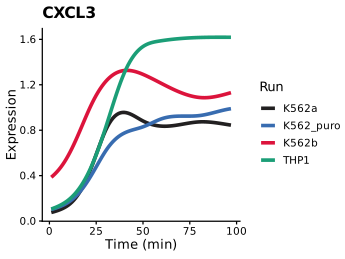

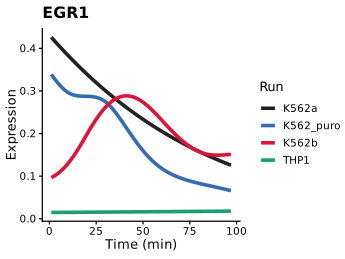

In [932]:
# ---- examples ----
gene_query <- "CXCL3"
print(plot_traj_trunc_gene(traj_trunc_rescaled.ls, gene_query, mode = "expr"))

gene_query <- "EGR1"
print(plot_traj_trunc_gene(traj_trunc_rescaled.ls, gene_query, mode = "expr"))

## Construct and save trajectory feature matrix

In [914]:
ConstructTrajMat = function(traj) {
    t_max = dim(traj[['K562a']])[2]
    tt = c(1:t_max)/t_max
    
    cn0 <- colnames(traj[[1]])
    stopifnot(all(vapply(traj, function(m) is.matrix(m) && identical(colnames(m), cn0), logical(1))))
    
    traj_all <- do.call(rbind, Map(function(mat, key) {
      rownames(mat) <- paste0(rownames(mat), "_", key)
      mat
    }, traj, names(traj)))
    
    dim(traj_all)
    
    traj_mat = as.matrix(traj_all)
    storage.mode(traj_mat) <- "double"
    message("Valid trajectories: ", nrow(traj_mat), " genes x ", ncol(traj_mat), " timepoints.")
    orig_label = rownames(traj_mat)
    
    return(list(a = tt, b = traj_mat))
}

res = ConstructTrajMat(traj_trunc_rescaled.ls)
tt = res$a
traj_mat = res$b

saveRDS(traj_mat, 'traj_mat.rds')
saveRDS(tt, 'tt.rds')

## LOAD CHECKPOINT

In [19]:
setwd('../global_analysis/extended/')

traj_mat = readRDS('traj_mat.rds')
tt = readRDS('tt.rds')

asso_df.ls = list()
asso_df.ls[['K562_puro']] = readRDS('asso_df_ls.rds')[['K562_puro']]
asso_df.ls[['K562a']] = readRDS('K562a_asso-df.rds')
asso_df.ls[['K562b']] =  readRDS('K562b_asso-df.rds')
asso_df.ls[['THP1']] = readRDS('THP1_asso-df.rds')

sce.ls = list()
sce.ls[['K562_puro']] = readRDS('sce_ls.rds')[['K562_puro']]
sce.ls[['K562a']] = readRDS('K562a_sce.rds')
sce.ls[['K562b']] =  readRDS('K562b_sce.rds')
sce.ls[['THP1']] = readRDS('THP1_sce.rds')

gamList.ls = list()
gamList.ls[['K562_puro']] = readRDS('gamList_ls.rds')[['K562_puro']]
gamList.ls[['K562a']] = readRDS('K562a_gamList.rds')
gamList.ls[['K562b']] =  readRDS('K562b_gamList.rds')
gamList.ls[['THP1']] = readRDS('THP1_gamList.rds')

counts_sub.ls = list()
counts_sub.ls[['K562_puro']] = readRDS('counts_sub_ls.rds')[['K562_puro']]
counts_sub.ls[['K562a']] = readRDS('K562a_counts-sub.rds')
counts_sub.ls[['K562b']] =  readRDS('K562b_counts-sub.rds')
counts_sub.ls[['THP1']] = readRDS('THP1_counts-sub.rds')

PT.ls = readRDS('../PT_ls.rds')
sf.ls = readRDS('../sf_ls.rds')
CW.ls = readRDS('../CW_ls.rds')

In [2421]:
# saveRDS(gamList.ls, 'gamList_ls.2.rds')
# saveRDS(sce.ls, 'sce_ls.2.rds')
# saveRDS(counts_sub.ls, 'counts_sub_ls.2.rds')
# saveRDS(asso_df.ls, 'asso_df_ls.2.rds')

# 3. Dimensionality reduction & additional processing

In [195]:
set.seed(1)

z_row <- function(M) {
  mu <- rowMeans(M, na.rm = TRUE)
  sd <- matrixStats::rowSds(M, na.rm = TRUE)
  sd[!is.finite(sd) | sd == 0] <- 1
  sweep(sweep(M, 1, mu, "-"), 1, sd, "/")
}

sil_to_alpha <- function(s) {
  s <- pmax(-0.2, pmin(0.8, s))
  0.15 + (s + 0.2) / (0.8 + 0.2) * (1.0 - 0.15)
}

desc = get_descriptors(traj_mat, tt, N_minutes = 10/length(tt), z_diff_threshold = 0.2, require_consecutive = 30, onset_mode = 'horizontal', pseudocount=1e-2)
gene_celltype <- rownames(traj_mat)

In [ ]:
# pc_df$owp = desc[rownames(pc_df), 'owp']
# pc_df$owp_ddt = desc[rownames(pc_df), 'owp_ddt']

In [18]:
pc_df <- data.frame(gene_celltype = gene_celltype,
                    gene = sapply(gene_celltype, function(x) { strsplit(x, '_')[[1]][1] }, USE.NAMES = F),
                    cell_type = sub("^[^_]+_", "", gene_celltype)) %>% left_join(desc, by = c('gene_celltype'))
rownames(pc_df) = pc_df$gene_celltype
pc_df = pc_df %>% select(-gene_celltype)

for (nm in c("waldStat_1", "meanLogFC", "pvalue_1", "qval_1")) {
    pc_df[[nm]] <- NA_real_
}

# Build lookup table from asso_df.ls
lookup_df <- do.call(rbind, lapply(names(asso_df.ls), function(ct) {
                                df <- asso_df.ls[[ct]]
                                if (is.null(df) || nrow(df) == 0) return(NULL)
                            
                                out <- data.frame(cell_type = ct, gene = rownames(df), stringsAsFactors = FALSE, row.names = NULL)
                            
                                for (nm in c("waldStat_1", "meanLogFC", "pvalue_1", "qval_1")) {
                                  out[[paste0(nm, "_lookup")]] <- if (nm %in% colnames(df)) df[[nm]] else NA_real_
                                }
                        
                                out
                              })
                    )

pc_df <- pc_df %>% rownames_to_column("row_id") %>% left_join(lookup_df, by = c("cell_type", "gene")) %>%
                   mutate(
                     waldStat_1 = ifelse(is.na(waldStat_1), waldStat_1_lookup, waldStat_1),
                     meanLogFC  = ifelse(is.na(meanLogFC),  meanLogFC_lookup,  meanLogFC),
                     pvalue_1   = ifelse(is.na(pvalue_1),   pvalue_1_lookup,   pvalue_1),
                     qval_1     = ifelse(is.na(qval_1),     qval_1_lookup,     qval_1)) %>%
                   select(-waldStat_1_lookup, -meanLogFC_lookup, -pvalue_1_lookup, -qval_1_lookup) %>% column_to_rownames("row_id")

# Quick sanity check
cat("Remaining NA counts:\n")
print(colSums(is.na(pc_df[, c("waldStat_1", "meanLogFC", "pvalue_1", "qval_1")])))
print(head(pc_df[, c("gene", "waldStat_1", "meanLogFC", "pvalue_1", "qval_1")], 10))

Remaining NA counts:
waldStat_1  meanLogFC   pvalue_1     qval_1 
         4          4          4          4 
               gene waldStat_1 meanLogFC pvalue_1 qval_1
NFKBIA_K562a NFKBIA  1967.3776 2.8062932        0      0
CXCL3_K562a   CXCL3   742.3239 2.7863760        0      0
CD69_K562a     CD69   602.3647 3.4546323        0      0
CD83_K562a     CD83   566.9987 2.1289979        0      0
ARL4A_K562a   ARL4A   466.5694 0.3653517        0      0
ICAM1_K562a   ICAM1   439.2142 2.9057450        0      0
CXCL8_K562a   CXCL8   426.5580 3.1128228        0      0
BTG2_K562a     BTG2   351.1097 1.7552631        0      0
BIRC3_K562a   BIRC3   322.0169 3.6008999        0      0
DDIT4_K562a   DDIT4   302.2627 1.3388896        0      0


In [19]:
X <- z_row(traj_mat)

dt <- diff(tt)
Xd <- traj_mat[, -1, drop = FALSE] - traj_mat[, -ncol(traj_mat), drop = FALSE]
Xd <- sweep(Xd, 2, dt, "/")
Xd <- z_row(Xd)
stopifnot(nrow(X) == nrow(Xd)) # sanity

### Remove low significance genes

In [20]:
dim(X)
dim(Xd)

X = X[rownames(pc_df %>% filter(pvalue_1 < 0.05)), ]
Xd = Xd[rownames(pc_df %>% filter(pvalue_1 < 0.05)), ]

dim(X)
dim(Xd)

[1] 15587    97

[1] 15587    96

[1] 7121   97

[1] 7121   96

### Remove genes dominated by time tag bias

In [21]:
excl_genes.k562a = read.csv('../../../../k562-tnfa.hg38.rep/notebooks/exclude_time-tag-bias_genes.csv')$X0
excl_genes.k562b = read.csv('../../../../thp1-k562-lps.hg38.rep/notebooks/exclude_time-tag-bias_genes.k562.csv')$X0
excl_genes.thp1 = read.csv('../../../../thp1-k562-lps.hg38.rep/notebooks/exclude_time-tag-bias_genes.thp1.csv')$X0
excl_genes.puro = read.csv('../../../../k562-tnfa-puromycin.hg38/notebooks/exclude_time-tag-bias_genes.csv')$X0

excl.genes = c(rownames(pc_df %>% filter(cell_type == 'K562a', gene %in% excl_genes.k562a)),
               rownames(pc_df %>% filter(cell_type == 'K562b', gene %in% excl_genes.k562b)),
               rownames(pc_df %>% filter(cell_type == 'THP1', gene %in% excl_genes.thp1)),
               rownames(pc_df %>% filter(cell_type == 'K562_puro', gene %in% excl_genes.puro)))
length(excl.genes)
head(excl.genes)

X = X[!rownames(X) %in% excl.genes,]
Xd = Xd[!rownames(Xd) %in% excl.genes,]

dim(X)
dim(Xd)

[1] 831

[1] "H2AC12_K562a"  "STMN1_K562a"   "NEAT1_K562a"   "EIF5A_K562a"  
[5] "HNRNPA1_K562a" "PRAME_K562a"

[1] 6749   97

[1] 6749   96

### Remove low count genes with otherwise significant dynamics

In [22]:
excl_genes.k562a = read.csv('../../../../k562-tnfa.hg38.rep/notebooks/exclude_low-count-genes.k562.csv')$X0
excl_genes.k562b = read.csv('../../../../thp1-k562-lps.hg38.rep/notebooks/exclude_low-count-genes.k562.csv')$X0
excl_genes.thp1 = read.csv('../../../../thp1-k562-lps.hg38.rep/notebooks/exclude_low-count-genes.thp1.csv')$X0
excl_genes.puro = read.csv('../../../../k562-tnfa-puromycin.hg38/notebooks/exclude_low-count-genes.k562.csv')$X0

excl.genes = c(rownames(pc_df %>% filter(cell_type == 'K562a', gene %in% excl_genes.k562a)),
               rownames(pc_df %>% filter(cell_type == 'K562b', gene %in% excl_genes.k562b)),
               rownames(pc_df %>% filter(cell_type == 'THP1', gene %in% excl_genes.thp1)),
               rownames(pc_df %>% filter(cell_type == 'K562_puro', gene %in% excl_genes.puro)))
length(excl.genes)

X = X[!rownames(X) %in% excl.genes,]
Xd = Xd[!rownames(Xd) %in% excl.genes,]

dim(X)
dim(Xd)

X_mat  <- as.matrix(X)
Xd_mat <- as.matrix(Xd)

[1] 554

[1] 6724   97

[1] 6724   96

# 4. Run PCA

In [23]:
# pc <- prcomp(X, center = FALSE, scale. = FALSE)
# pc_d <- prcomp(Xd, center = FALSE, scale. = FALSE)

In [24]:
pca_X <- prcomp(X_mat, center = TRUE, scale. = FALSE)
cumvar <- cumsum(pca_X$sdev^2) / sum(pca_X$sdev^2)
n_pc <- which(cumvar >= 0.99)[1] # retain enough PCs for 95% variance

X_pc <- pca_X$x[ , seq_len(n_pc), drop = FALSE]
n_pc

[1] 4

In [238]:
pca_Xd <- prcomp(Xd_mat, center = TRUE, scale. = FALSE)
cumvar <- cumsum(pca_Xd$sdev^2) / sum(pca_Xd$sdev^2)
n_pc <- which(cumvar >= 0.99)[1] # retain enough PCs for 95% variance

Xd_pc <- pca_Xd$x[ , seq_len(n_pc), drop = FALSE]
n_pc

[1] 5

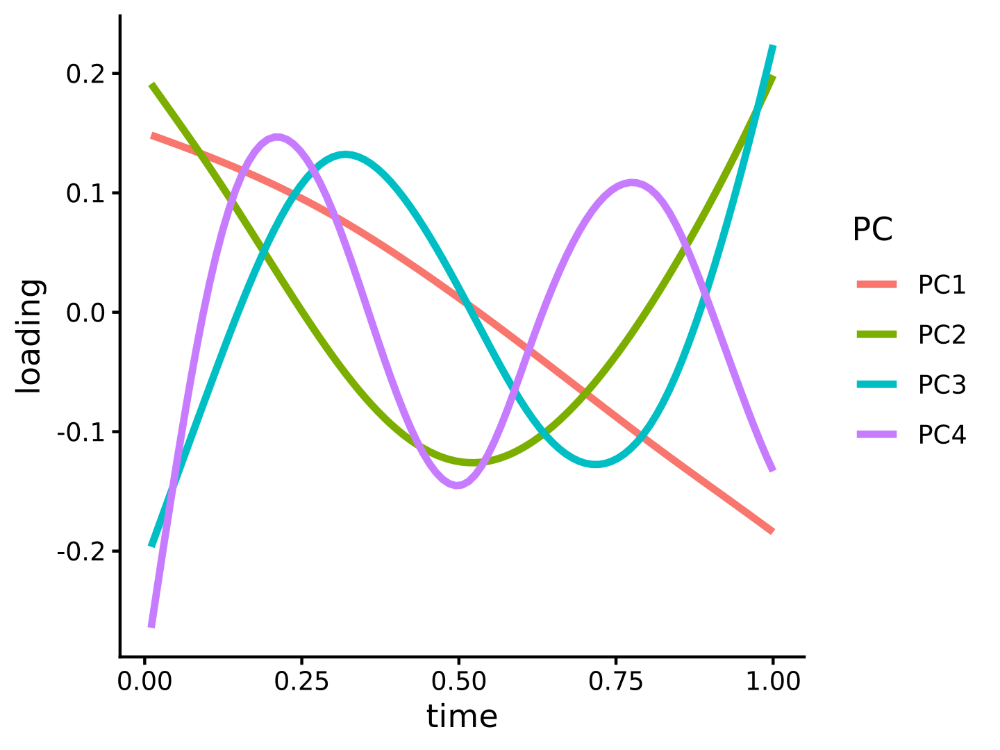

In [25]:
options(repr.plot.width = 4.8, repr.plot.height = 3.6, repr.plot.res = 300)

load_df_long <- data.frame(time = tt,
                           PC1 = pca_X$rotation[, 1],
                           PC2 = pca_X$rotation[, 2],
                           PC3 = pca_X$rotation[, 3],
                           PC4 = pca_X$rotation[, 4]) %>%
                pivot_longer(-time, names_to = "PC", values_to = "loading")


ggplot(load_df_long, aes(x = time, y = loading, color = PC)) + geom_line(linewidth = 1.2) + theme_classic()

In [26]:
plot_pca_reconstruction <- function(gene, X_mat, pca_X, time = tt, n_pcs = c(3, 4)) {
  stopifnot(gene %in% rownames(X_mat))

  gene_idx <- match(gene, rownames(X_mat))
  original <- X_mat[gene_idx, ]

  reconstruct_k <- function(K) {
    scores   <- pca_X$x[gene_idx, seq_len(K), drop = FALSE]
    loadings <- pca_X$rotation[, seq_len(K), drop = FALSE]

    reconstructed <- as.numeric(scores %*% t(loadings))

    if (!is.null(pca_X$scale) && !identical(pca_X$scale, FALSE)) {
      reconstructed <- reconstructed * pca_X$scale
    }

    if (!is.null(pca_X$center) && !identical(pca_X$center, FALSE)) {
      reconstructed <- reconstructed + pca_X$center
    }

    reconstructed
  }

  plot_df <- data.frame(time = time, Original = original)

  for (K in n_pcs) {
    plot_df[[paste0("PC1-", K)]] <- reconstruct_k(K)
  }

  plot_df_long <- plot_df %>%
    tidyr::pivot_longer(
      cols = -time,
      names_to = "trajectory",
      values_to = "value"
    )

  ggplot(plot_df_long, aes(x = time, y = value, linetype = trajectory)) +
    geom_line(linewidth = 1.1) +
    labs(
      title = paste0(gene, ": PCA trajectory reconstruction"),
      x = "Time",
      y = "Normalized trajectory",
      linetype = NULL
    ) +
    theme_classic()
}

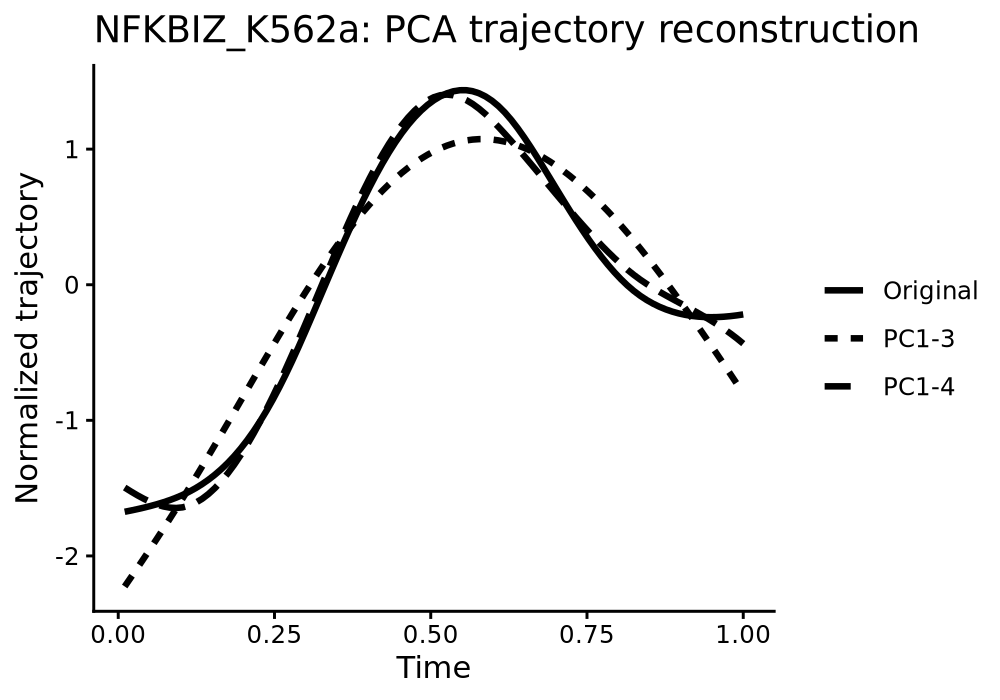

In [27]:
options(repr.plot.width = 5, repr.plot.height = 3.5, repr.plot.res = 200)

plot_pca_reconstruction(gene = "NFKBIZ_K562a", n_pcs = c(3, 4),
                        X_mat = X_mat, pca_X = pca_X, time = tt)

In [35]:
pc_df = pc_df[rownames(pca_X$x), ]
pc_df$PC1 = pca_X$x[, 1]
pc_df$PC2 = pca_X$x[, 2]
pc_df$PC3 = pca_X$x[, 3]
pc_df$PC4 = pca_X$x[, 4]

# 5. Initial attempts at clustering

In [1647]:
# cl.ls = list()
# sil_df.ls = list()
# D.ls = list()

In [1646]:
# # ============================================================
# # 2. Plot clustering metrics
# # ============================================================

# plot_trajectory_clustering_metrics <- function(
#   x,
#   metrics_to_plot = c(
#     "WSS",
#     "p90_centroid_distance",
#     "resolution",
#     "mean_silhouette"
#   ),
#   overlay = FALSE,
#   show_k = c("resolution", "elbow", "silhouette"),
#   point_size = 1.8,
#   line_width = 0.6
# ) {
#   metrics <- x$metrics
#   sel <- x$selection

#   metric_labels <- c(
#     WSS = "Within-cluster sum of squares",
#     p90_centroid_distance = "90th percentile distance to centroid",
#     resolution = "Fraction of achievable WSS improvement",
#     mean_silhouette = "Mean silhouette"
#   )

#   df_long <- metrics %>%
#     dplyr::select(K, dplyr::all_of(metrics_to_plot)) %>%
#     tidyr::pivot_longer(-K, names_to = "metric", values_to = "value") %>%
#     dplyr::mutate(
#       metric = factor(
#         metric,
#         levels = metrics_to_plot,
#         labels = metric_labels[metrics_to_plot]
#       )
#     )

#   selection_df <- tibble::tibble(
#     selection = c("resolution", "elbow", "silhouette"),
#     K = c(sel$k_resolution, sel$k_elbow, sel$k_silhouette)
#   ) %>%
#     dplyr::filter(selection %in% show_k, !is.na(K)) %>%
#     dplyr::mutate(
#       selection = dplyr::recode(
#         selection,
#         resolution = paste0(round(100 * sel$wss_fraction), "% WSS resolution"),
#         elbow = "Elbow",
#         silhouette = "Maximum silhouette"
#       )
#     )

#   if (!overlay) {
#     return(
#       ggplot2::ggplot(df_long, ggplot2::aes(K, value)) +
#         ggplot2::geom_line(linewidth = line_width) +
#         ggplot2::geom_point(size = point_size, shape = 1) +
#         ggplot2::geom_vline(
#           data = selection_df,
#           ggplot2::aes(xintercept = K, linetype = selection),
#           linewidth = 0.7
#         ) +
#         ggplot2::facet_wrap(~ metric, scales = "free_y", ncol = 1) +
#         ggplot2::labs(x = "K", y = NULL, linetype = "K selection") +
#         ggplot2::theme_bw() +
#         ggplot2::theme(
#           strip.background = ggplot2::element_blank(),
#           strip.text = ggplot2::element_text(face = "bold"),
#           legend.position = "top"
#         )
#     )
#   }

#   df_overlay <- df_long %>%
#     dplyr::group_by(metric) %>%
#     dplyr::mutate(
#       value_scaled = {
#         rng <- range(value, na.rm = TRUE)
#         if (diff(rng) == 0) rep(0, dplyr::n()) else (value - rng[1]) / diff(rng)
#       }
#     ) %>%
#     dplyr::ungroup()

#   ggplot2::ggplot(
#     df_overlay,
#     ggplot2::aes(K, value_scaled, linetype = metric)
#   ) +
#     ggplot2::geom_line(linewidth = line_width) +
#     ggplot2::geom_point(size = point_size, shape = 1) +
#     ggplot2::geom_vline(
#       data = selection_df,
#       ggplot2::aes(xintercept = K),
#       inherit.aes = FALSE,
#       linewidth = 0.6,
#       linetype = 2
#     ) +
#     ggplot2::labs(
#       x = "K",
#       y = "Metric scaled to [0,1]",
#       linetype = "Metric"
#     ) +
#     ggplot2::theme_bw() +
#     ggplot2::theme(legend.position = "top")
# }

## K-means clustering

In [1539]:
# # ============================================================
# # K-means clustering across K
# # ============================================================

# set.seed(1)
# K_grid <- 3:100

# kmeans_fits <- lapply(K_grid, function(K) { kmeans(X_pc, centers = K, nstart = 20, iter.max = 100) })

# names(kmeans_fits) <- as.character(K_grid)
# kmeans_assignments <- lapply(kmeans_fits, `[[`, "cluster")


# # ============================================================
# # Calculate K-means clustering metrics across K
# # ============================================================

# wss_fraction <- 0.95
# D_kmeans <- dist(X_pc, method = "euclidean")

# kmeans_metrics <- lapply(K_grid, function(K) {
#   fit <- kmeans_fits[[as.character(K)]]
#   cl  <- fit$cluster

#   gene_centroids <- fit$centers[cl, , drop = FALSE]
#   d_to_centroid  <- sqrt(rowSums((X_pc - gene_centroids)^2))

#   sil <- cluster::silhouette(cl, D_kmeans)

#   data.frame(
#     K = K,
#     WSS = fit$tot.withinss,
#     p90_centroid_distance = unname(quantile(d_to_centroid, 0.90, na.rm = TRUE)),
#     mean_silhouette = mean(sil[, "sil_width"], na.rm = TRUE)
#   )
# }) %>%
#   bind_rows()

# # ------------------------------------------------------------
# # Resolution + elbow score
# # ------------------------------------------------------------

# WSS_minK <- kmeans_metrics$WSS[1]
# WSS_maxK <- kmeans_metrics$WSS[nrow(kmeans_metrics)]

# kmeans_metrics <- kmeans_metrics %>%
#   mutate(
#     resolution = (WSS_minK - WSS) / (WSS_minK - WSS_maxK),
#     k_norm = (K - min(K)) / (max(K) - min(K)),
#     elbow_score = resolution - k_norm
#   )

# # ------------------------------------------------------------
# # K-selection summaries
# # ------------------------------------------------------------

# eligible <- which(kmeans_metrics$resolution >= wss_fraction)

# k_resolution <- if (length(eligible)) kmeans_metrics$K[min(eligible)] else NA_integer_
# k_elbow      <- kmeans_metrics$K[which.max(kmeans_metrics$elbow_score)]
# k_silhouette <- kmeans_metrics$K[which.max(kmeans_metrics$mean_silhouette)]

# kmeans_selection <- list(
#   k_resolution = k_resolution,
#   k_elbow = k_elbow,
#   k_silhouette = k_silhouette,
#   max_mean_silhouette = max(kmeans_metrics$mean_silhouette),
#   wss_fraction = wss_fraction
# )

# kmeans_eval <- list(
#   metrics = kmeans_metrics,
#   selection = kmeans_selection
# )

# kmeans_selection
# head(kmeans_metrics)

# options(repr.plot.width = 7.5, repr.plot.height = 5)

# plot_trajectory_clustering_metrics(kmeans_eval, overlay = FALSE)

In [1540]:
# name <- "kmeans_elbow"
# K_best <- kmeans_selection$k_elbow

# cl <- kmeans_assignments[[as.character(K_best)]]
# if (is.null(names(cl))) { names(cl) <- rownames(X_pc) }

# sil_obj <- cluster::silhouette(as.integer(cl), D_kmeans)
# disp_df <- data.frame(gene = names(cl), sil_width = sil_obj[, "sil_width"], stringsAsFactors = FALSE)
# rownames(disp_df) <- disp_df$gene

# cl.ls[[name]] <- cl
# sil_df.ls[[name]] <- disp_df

# #####

# name <- "kmeans_resolution"
# K_best <- kmeans_selection$k_resolution

# cl <- kmeans_assignments[[as.character(K_best)]]
# if (is.null(names(cl))) { names(cl) <- rownames(X_pc) }

# sil_obj <- cluster::silhouette(as.integer(cl), D_kmeans)
# disp_df <- data.frame(gene = names(cl), sil_width = sil_obj[, "sil_width"], stringsAsFactors = FALSE)
# rownames(disp_df) <- disp_df$gene

# cl.ls[[name]] <- cl
# sil_df.ls[[name]] <- disp_df

In [1541]:
# XXd_pc = cbind(X_pc, Xd_pc)
# colnames(XXd_pc) = c('PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6', 'PC7', 'PC8', 'PC9')

In [1634]:
# # ============================================================
# # K-means clustering across K
# # ============================================================

# set.seed(1)
# K_grid <- 3:100

# kmeans_fits <- lapply(K_grid, function(K) { kmeans(XXd_pc, centers = K, nstart = 20, iter.max = 100) })

# names(kmeans_fits) <- as.character(K_grid)
# kmeans_assignments <- lapply(kmeans_fits, `[[`, "cluster")


# # ============================================================
# # Calculate K-means clustering metrics across K
# # ============================================================

# wss_fraction <- 0.95
# D_kmeans <- dist(XXd_pc, method = "euclidean")

# kmeans_metrics <- lapply(K_grid, function(K) {
#   fit <- kmeans_fits[[as.character(K)]]
#   cl  <- fit$cluster

#   gene_centroids <- fit$centers[cl, , drop = FALSE]
#   d_to_centroid  <- sqrt(rowSums((XXd_pc - gene_centroids)^2))

#   sil <- cluster::silhouette(cl, D_kmeans)

#   data.frame(
#     K = K,
#     WSS = fit$tot.withinss,
#     p90_centroid_distance = unname(quantile(d_to_centroid, 0.90, na.rm = TRUE)),
#     mean_silhouette = mean(sil[, "sil_width"], na.rm = TRUE)
#   )
# }) %>%
#   bind_rows()

# # ------------------------------------------------------------
# # Resolution + elbow score
# # ------------------------------------------------------------

# WSS_minK <- kmeans_metrics$WSS[1]
# WSS_maxK <- kmeans_metrics$WSS[nrow(kmeans_metrics)]

# kmeans_metrics <- kmeans_metrics %>%
#   mutate(
#     resolution = (WSS_minK - WSS) / (WSS_minK - WSS_maxK),
#     k_norm = (K - min(K)) / (max(K) - min(K)),
#     elbow_score = resolution - k_norm
#   )

# # ------------------------------------------------------------
# # K-selection summaries
# # ------------------------------------------------------------

# eligible <- which(kmeans_metrics$resolution >= wss_fraction)

# k_resolution <- if (length(eligible)) kmeans_metrics$K[min(eligible)] else NA_integer_
# k_elbow      <- kmeans_metrics$K[which.max(kmeans_metrics$elbow_score)]
# k_silhouette <- kmeans_metrics$K[which.max(kmeans_metrics$mean_silhouette)]

# kmeans_selection <- list(
#   k_resolution = k_resolution,
#   k_elbow = k_elbow,
#   k_silhouette = k_silhouette,
#   max_mean_silhouette = max(kmeans_metrics$mean_silhouette),
#   wss_fraction = wss_fraction
# )

# kmeans_eval <- list(
#   metrics = kmeans_metrics,
#   selection = kmeans_selection
# )

# kmeans_selection
# head(kmeans_metrics)

# options(repr.plot.width = 7.5, repr.plot.height = 5)

# plot_trajectory_clustering_metrics(kmeans_eval, overlay = FALSE)

In [1635]:
# name <- "kmeans_elbow_2"
# K_best <- kmeans_selection$k_elbow

# cl <- kmeans_assignments[[as.character(K_best)]]
# if (is.null(names(cl))) { names(cl) <- rownames(X_pc) }

# sil_obj <- cluster::silhouette(as.integer(cl), D_kmeans)
# disp_df <- data.frame(gene = names(cl), sil_width = sil_obj[, "sil_width"], stringsAsFactors = FALSE)
# rownames(disp_df) <- disp_df$gene

# cl.ls[[name]] <- cl
# sil_df.ls[[name]] <- disp_df

# #####

# name <- "kmeans_resolution_2"
# K_best <- kmeans_selection$k_resolution

# cl <- kmeans_assignments[[as.character(K_best)]]
# if (is.null(names(cl))) { names(cl) <- rownames(X_pc) }

# sil_obj <- cluster::silhouette(as.integer(cl), D_kmeans)
# disp_df <- data.frame(gene = names(cl), sil_width = sil_obj[, "sil_width"], stringsAsFactors = FALSE)
# rownames(disp_df) <- disp_df$gene

# cl.ls[[name]] <- cl
# sil_df.ls[[name]] <- disp_df

## Gaussian mixture models

In [1535]:
# suppressPackageStartupMessages({
#   library(mclust)
# })

In [1536]:
# # ============================================================
# # Gaussian mixture model clustering across K
# # ============================================================

# set.seed(1)
# K_grid <- 3:91

# gmm_fits <- vector("list", length(K_grid))
# names(gmm_fits) <- as.character(K_grid)

# for (i in seq_along(K_grid)) {
#   K <- K_grid[i]

#   cat(sprintf("Fitting GMM: K = %d  [%d/%d] ... ", K, i, length(K_grid)))
#   flush.console()

#   fit <- mclust::Mclust(
#     X_pc,
#     G = K,
#     modelNames = "VVI",
#     verbose = FALSE
#   )

#   # [i] <- list(fit) preserves the list element even if fit is NULL
#   gmm_fits[i] <- list(fit)

#   cat(if (is.null(fit)) "FAILED\n" else "done\n")
#   flush.console()
# }

# failed_K <- K_grid[vapply(gmm_fits, is.null, logical(1))]
# cat("Failed K:", paste(failed_K, collapse = ", "), "\n")

# gmm_assignments   <- lapply(gmm_fits, function(x) if (!is.null(x)) x$classification else NULL)
# gmm_probabilities <- lapply(gmm_fits, function(x) if (!is.null(x)) x$z else NULL)
# gmm_uncertainty   <- lapply(gmm_fits, function(x) if (!is.null(x)) x$uncertainty else NULL)
# names(gmm_fits) = as.character(K_grid)

In [1537]:
# # ============================================================
# # Calculate GMM clustering metrics across K
# # ============================================================

# wss_fraction <- 0.95
# D_gmm <- dist(X_pc, method = "euclidean")

# gmm_metrics <- lapply(K_grid, function(K) {
#   fit <- gmm_fits[[as.character(K)]]
#   cl  <- fit$classification
#   z   <- fit$z

#   # Empirical centroids of hard-assignment clusters
#   centroids <- rowsum(X_pc, group = cl) / as.vector(table(cl))
#   gene_centroids <- centroids[as.character(cl), , drop = FALSE]
#   d_to_centroid <- sqrt(rowSums((X_pc - gene_centroids)^2))

#   sil <- cluster::silhouette(as.integer(cl), D_gmm)

#   # Posterior diagnostics
#   max_posterior <- apply(z, 1, max)
#   entropy <- -rowSums(z * log(pmax(z, .Machine$double.eps)))
#   norm_entropy <- entropy / log(K)

#   # mclust BIC convention: larger is better
#   BIC <- as.numeric(fit$bic)

#   # ICL = BIC - 2 * posterior classification entropy
#   ICL <- BIC - 2 * sum(entropy)

#   data.frame(
#     K = K,
#     K_hard = length(unique(cl)),
#     WSS = sum(d_to_centroid^2),
#     p90_centroid_distance = unname(quantile(d_to_centroid, 0.90, na.rm = TRUE)),
#     mean_silhouette = mean(sil[, "sil_width"], na.rm = TRUE),
#     BIC = BIC,
#     ICL = ICL,
#     logLik = as.numeric(fit$loglik),
#     mean_uncertainty = mean(1 - max_posterior),
#     mean_max_posterior = mean(max_posterior),
#     mean_norm_entropy = mean(norm_entropy)
#   )
# }) %>%
#   bind_rows()

# # ------------------------------------------------------------
# # Resolution + elbow
# # ------------------------------------------------------------

# WSS_minK <- gmm_metrics$WSS[1]
# WSS_maxK <- gmm_metrics$WSS[nrow(gmm_metrics)]

# gmm_metrics <- gmm_metrics %>%
#   mutate(
#     resolution = (WSS_minK - WSS) / (WSS_minK - WSS_maxK),
#     k_norm = (K - min(K)) / (max(K) - min(K)),
#     elbow_score = resolution - k_norm
#   )

# # ------------------------------------------------------------
# # K-selection summaries
# # ------------------------------------------------------------

# eligible <- which(gmm_metrics$resolution >= wss_fraction)

# k_resolution <- if (length(eligible)) gmm_metrics$K[min(eligible)] else NA_integer_
# k_elbow      <- gmm_metrics$K[which.max(gmm_metrics$elbow_score)]
# k_silhouette <- gmm_metrics$K[which.max(gmm_metrics$mean_silhouette)]
# k_bic        <- gmm_metrics$K[which.max(gmm_metrics$BIC)]
# k_icl        <- gmm_metrics$K[which.max(gmm_metrics$ICL)]

# gmm_selection <- list(
#   k_resolution = k_resolution,
#   k_elbow = k_elbow,
#   k_silhouette = k_silhouette,
#   k_bic = k_bic,
#   k_icl = k_icl,
#   max_mean_silhouette = max(gmm_metrics$mean_silhouette),
#   max_BIC = max(gmm_metrics$BIC),
#   max_ICL = max(gmm_metrics$ICL),
#   wss_fraction = wss_fraction
# )

# gmm_eval <- list(
#   metrics = gmm_metrics,
#   selection = gmm_selection
# )

# gmm_selection
# gmm_metrics

In [1538]:
# options(repr.plot.width = 7.5, repr.plot.height = 5)

# plot_trajectory_clustering_metrics(
#   gmm_eval,
#   overlay = FALSE
# )

In [1532]:
# # ============================================================
# # Plot GMM-specific metrics
# # ============================================================

# gmm_specific_long <- gmm_metrics %>%
#   select(K, BIC, ICL, mean_uncertainty, mean_norm_entropy) %>%
#   tidyr::pivot_longer(-K, names_to = "metric", values_to = "value") %>%
#   mutate(
#     metric = recode(
#       metric,
#       BIC = "BIC",
#       ICL = "ICL",
#       mean_uncertainty = "Mean assignment uncertainty",
#       mean_norm_entropy = "Mean normalized posterior entropy"
#     )
#   )

# gmm_selection_lines <- data.frame(
#   metric = c("BIC", "ICL"),
#   K = c(gmm_selection$k_bic, gmm_selection$k_icl)
# )

# options(repr.plot.width = 7.5, repr.plot.height = 5)

# ggplot(gmm_specific_long, aes(K, value)) +
#   geom_line(linewidth = 0.7) +
#   geom_point(shape = 1, size = 2) +
#   geom_vline(
#     data = gmm_selection_lines,
#     aes(xintercept = K),
#     linetype = 2,
#     linewidth = 0.7
#   ) +
#   facet_wrap(~ metric, scales = "free_y", ncol = 1) +
#   labs(x = "K", y = NULL) +
#   theme_bw() +
#   theme(
#     strip.background = element_blank(),
#     strip.text = element_text(face = "bold")
#   )

In [1533]:
# gmm_metrics <- gmm_metrics %>%
#   mutate(
#     delta_BIC = max(BIC) - BIC,
#     delta_ICL = max(ICL) - ICL
#   )

# ggplot(gmm_metrics, aes(K, delta_BIC)) +
#   geom_line() +
#   geom_point(shape = 1) +
#   theme_classic() +
#   labs(x = "K", y = "ΔBIC from optimum")

# ggplot(gmm_metrics, aes(K, delta_ICL)) +
#   geom_line() +
#   geom_point(shape = 1) +
#   theme_classic() +
#   labs(x = "K", y = "ΔICL from optimum")

In [1534]:
# # ============================================================
# # Final GMM clusterings: elbow + 95% WSS resolution
# # ============================================================

# gmm_final <- c(
#   gmm_elbow = gmm_selection$k_elbow,
#   gmm_resolution = gmm_selection$k_resolution
# )

# for (name in names(gmm_final)) {
#   k_selected <- gmm_final[[name]]
#   fit <- gmm_fits[[as.character(k_selected)]]
#   cl <- fit$classification
#   names(cl) <- rownames(X_pc)

#   gene_cluster_distance <- rep(NA_real_, nrow(X_pc))
#   names(gene_cluster_distance) <- rownames(X_pc)

#   for (k in sort(unique(cl))) {
#     idx <- which(cl == k)
#     Xi <- X_pc[idx, , drop = FALSE]
#     centroid <- colMeans(Xi)
#     gene_cluster_distance[idx] <- sqrt(rowSums(sweep(Xi, 2, centroid, "-")^2))
#   }

#   disp_df <- data.frame(
#     gene = rownames(X_pc),
#     cluster = cl,
#     centroid_dist = gene_cluster_distance,
#     max_posterior = apply(fit$z, 1, max),
#     uncertainty = fit$uncertainty,
#     stringsAsFactors = FALSE
#   )

#   cl.ls[[name]] <- cl
#   sil_df.ls[[name]] <- disp_df
#   D.ls[[name]] <- D_gmm
# }

## Ward.D2 hierarchical clustering

In [1636]:
# K_grid <- 3:100

# D <- dist(X_mat, method = "euclidean")
# hc <- hclust(D, method = "ward.D2")

In [1553]:
# # ============================================================
# # 1. Calculate clustering metrics across K
# # ============================================================

# calculate_trajectory_clustering_metrics <- function(
#   X_mat,
#   D,
#   hc,
#   K_grid = 3:200,
#   wss_fraction = 0.95,
#   select_k_by = c("resolution", "elbow", "silhouette")
# ) {
#   select_k_by <- match.arg(select_k_by)

#   X_mat <- as.matrix(X_mat)
#   n <- nrow(X_mat)

#   if (!inherits(D, "dist")) stop("D must be a 'dist' object.")
#   if (!inherits(hc, "hclust")) stop("hc must be an 'hclust' object.")
#   if (attr(D, "Size") != n) stop("X_mat and D contain different numbers of observations.")
#   if (length(hc$order) != n) stop("X_mat and hc contain different numbers of observations.")
#   if (max(K_grid) >= n) stop("max(K_grid) must be smaller than the number of genes.")

#   calc_for_k <- function(K) {
#     cl <- cutree(hc, k = K)

#     centroids <- rowsum(X_mat, group = cl) / as.vector(table(cl))
#     gene_centroids <- centroids[as.character(cl), , drop = FALSE]
#     d_to_centroid <- sqrt(rowSums((X_mat - gene_centroids)^2))

#     sil <- cluster::silhouette(cl, D)

#     data.frame(
#       K = K,
#       WSS = sum(d_to_centroid^2),
#       p90_centroid_distance = unname(quantile(d_to_centroid, 0.90, na.rm = TRUE)),
#       mean_silhouette = mean(sil[, "sil_width"], na.rm = TRUE)
#     )
#   }

#   metrics <- dplyr::bind_rows(lapply(K_grid, calc_for_k))

#   WSS_minK <- metrics$WSS[1]
#   WSS_maxK <- metrics$WSS[nrow(metrics)]

#   metrics <- metrics %>%
#     dplyr::mutate(
#       resolution = (WSS_minK - WSS) / (WSS_minK - WSS_maxK),
#       k_norm = (K - min(K)) / (max(K) - min(K)),
#       elbow_score = resolution - k_norm
#     )

#   eligible <- which(metrics$resolution >= wss_fraction)

#   k_resolution <- if (length(eligible)) metrics$K[min(eligible)] else NA_integer_
#   k_elbow <- metrics$K[which.max(metrics$elbow_score)]
#   k_silhouette <- metrics$K[which.max(metrics$mean_silhouette)]

#   k_selected <- switch(
#     select_k_by,
#     resolution = k_resolution,
#     elbow = k_elbow,
#     silhouette = k_silhouette
#   )

#   out <- list(
#     metrics = metrics,
#     selection = list(
#       select_k_by = select_k_by,
#       k_selected = k_selected,
#       k_resolution = k_resolution,
#       k_elbow = k_elbow,
#       k_silhouette = k_silhouette,
#       max_mean_silhouette = max(metrics$mean_silhouette, na.rm = TRUE),
#       wss_fraction = wss_fraction
#     )
#   )

#   class(out) <- c("trajectory_clustering_metrics", class(out))
#   out
# }

In [1637]:
# # ============================================================
# # 1. Calculate clustering metrics across K
# # ============================================================

# calculate_trajectory_clustering_metrics <- function(
#   X_mat,
#   D,
#   hc = NULL,
#   kmeans_fits = NULL,
#   K_grid = 3:200,
#   wss_fraction = 0.95,
#   select_k_by = c("resolution", "elbow", "silhouette")
# ) {
#   select_k_by <- match.arg(select_k_by)

#   X_mat <- as.matrix(X_mat)
#   n <- nrow(X_mat)

#   if (!inherits(D, "dist")) stop("D must be a 'dist' object.")
#   if (attr(D, "Size") != n) stop("X_mat and D contain different numbers of observations.")

#   # Provide either hierarchical clustering OR k-means fits
#   if (is.null(hc) == is.null(kmeans_fits)) {
#     stop("Provide exactly one of 'hc' or 'kmeans_fits'.")
#   }

#   if (!is.null(hc)) {
#     if (!inherits(hc, "hclust")) stop("hc must be an 'hclust' object.")
#     if (length(hc$order) != n) stop("X_mat and hc contain different numbers of observations.")
#   }

#   if (!is.null(kmeans_fits)) {
#     if (is.null(names(kmeans_fits))) {
#       stop("kmeans_fits must be named by K.")
#     }

#     # If K_grid wasn't supplied, use the fitted K values
#     if (missing(K_grid)) {
#       K_grid <- as.integer(names(kmeans_fits))
#     }

#     if (!all(as.character(K_grid) %in% names(kmeans_fits))) {
#       stop("Some values in K_grid are not present in kmeans_fits.")
#     }
#   }

#   if (max(K_grid) >= n) stop("max(K_grid) must be smaller than the number of genes.")

#   calc_for_k <- function(K) {

#     if (!is.null(hc)) {
#       cl <- cutree(hc, k = K)

#       centroids <- rowsum(X_mat, group = cl) / as.vector(table(cl))
#       gene_centroids <- centroids[as.character(cl), , drop = FALSE]

#     } else {
#       fit <- kmeans_fits[[as.character(K)]]
#       if (is.null(fit)) stop("kmeans_fits[['", K, "']] is NULL.")

#       cl <- fit$cluster
#       if (length(cl) != n) stop("K-means fit and X_mat contain different numbers of observations.")
#       if (ncol(fit$centers) != ncol(X_mat)) stop("K-means fit and X_mat have different feature dimensions.")

#       gene_centroids <- fit$centers[cl, , drop = FALSE]
#     }

#     d_to_centroid <- sqrt(rowSums((X_mat - gene_centroids)^2))
#     sil <- cluster::silhouette(cl, D)

#     data.frame(
#       K = K,
#       WSS = sum(d_to_centroid^2),
#       p90_centroid_distance = unname(quantile(d_to_centroid, 0.90, na.rm = TRUE)),
#       mean_silhouette = mean(sil[, "sil_width"], na.rm = TRUE)
#     )
#   }

#   metrics <- dplyr::bind_rows(lapply(K_grid, calc_for_k))

#   WSS_minK <- metrics$WSS[1]
#   WSS_maxK <- metrics$WSS[nrow(metrics)]

#   metrics <- metrics %>%
#     dplyr::mutate(
#       resolution = (WSS_minK - WSS) / (WSS_minK - WSS_maxK),
#       k_norm = (K - min(K)) / (max(K) - min(K)),
#       elbow_score = resolution - k_norm
#     )

#   eligible <- which(metrics$resolution >= wss_fraction)

#   k_resolution <- if (length(eligible)) metrics$K[min(eligible)] else NA_integer_
#   k_elbow <- metrics$K[which.max(metrics$elbow_score)]
#   k_silhouette <- metrics$K[which.max(metrics$mean_silhouette)]

#   k_selected <- switch(
#     select_k_by,
#     resolution = k_resolution,
#     elbow = k_elbow,
#     silhouette = k_silhouette
#   )

#   out <- list(
#     metrics = metrics,
#     selection = list(
#       select_k_by = select_k_by,
#       k_selected = k_selected,
#       k_resolution = k_resolution,
#       k_elbow = k_elbow,
#       k_silhouette = k_silhouette,
#       max_mean_silhouette = max(metrics$mean_silhouette, na.rm = TRUE),
#       wss_fraction = wss_fraction
#     )
#   )

#   class(out) <- c("trajectory_clustering_metrics", class(out))
#   out
# }

In [1639]:
# clust_eval <- calculate_trajectory_clustering_metrics(X_mat = X_mat, D = D, hc = hc,
#                                                       K_grid = 3:200, wss_fraction = 0.95, select_k_by = "elbow")
# clust_eval$selection

# options(repr.plot.width = 7.5, repr.plot.height = 5)

# plot_trajectory_clustering_metrics(clust_eval, overlay = FALSE)

In [1638]:
# # ============================================================
# # 7. Final clustering
# # ============================================================

# k_selected = clust_eval$selection$k_selected
# cl <- cutree(hc, k = k_selected)

# gene_cluster_distance <- rep(NA_real_, nrow(X_mat))
# names(gene_cluster_distance) <- rownames(X_mat)

# for (k in sort(unique(cl))) {
#   idx <- which(cl == k)
#   Xi <- X_mat[idx, , drop = FALSE]
#   centroid <- colMeans(Xi)
#   gene_cluster_distance[idx] <- sqrt(rowSums(sweep(Xi, 2, centroid, "-")^2))
# }

# disp_df <- data.frame(gene = rownames(X_mat), cluster = cl, centroid_dist = gene_cluster_distance, stringsAsFactors = FALSE)

# name <- "ward_homogeneity"

# cl.ls[[name]] <- cl
# sil_df.ls[[name]] <- disp_df
# D.ls[[name]] <- D

## Compare

In [1640]:
# for (name in names(cl.ls)) {

#     # Add assignments back into pc_df
#     pc_df[[paste0("cluster_", name)]] <- as.factor(cl.ls[[name]][rownames(pc_df)])
#     pc_df[[paste0("cluster_dist_", name)]] <- sil_df.ls[[name]]$centroid_dist[match(rownames(pc_df), sil_df.ls[[name]]$gene)]
    
#     # inspect cluster sizes
#     print(name)
#     print(sort(table(cl.ls[[name]]), decreasing = TRUE))
    
#     cluster_name = paste0("cluster_", name)
#     pc_df[[cluster_name]] <- factor(pc_df[[cluster_name]], levels = c(levels(pc_df[[cluster_name]]), "-1"))
#     pc_df[[cluster_name]][is.na(pc_df[[cluster_name]])] <- "-1"
#     pc_df[[cluster_name]] <- factor(pc_df[[cluster_name]])
# }

In [1641]:
# cat_colors = c("#0072B2","#D55E00","#009E73","#CC79A7","#E69F00","#56B4E9","#F0E442","#8C564B","#6A3D9A","#66A61E",
#                "#E41A1C","#377EB8","#4DAF4A","#984EA3","#FF7F00","#A65628","#F781BF","#999999","#1B9E77","#7570B3",
#                "#E7298A","#A6761D","#D95F02","#17BECF","#BCBD22","#AEC7E8","#FF9896","#98DF8A","#C5B0D5","#C49C94")
# cat_colors_k60 <- rep(cat_colors, length.out = 60)

# p2 <- feature_plot_pc_simple(pc_df %>% filter(cluster_ward_homogeneity != -1), feature = "cluster_kmeans_resolution", cat_colors = cat_colors_k60, alpha_col = NULL)
# p1 <- feature_plot_pc_simple(pc_df %>% filter(cluster_kmeans_elbow != -1), feature = "cluster_kmeans_elbow", cat_colors = cat_colors_k60, alpha_col = NULL)

# p3 <- feature_plot_pc_simple(pc_df %>% filter(cluster_ward_homogeneity != -1), feature = "cluster_ward_homogeneity", cat_colors = cat_colors_k60, alpha_col = NULL)
# p4 <- feature_plot_pc_simple(pc_df %>% filter(cluster_gmm_resolution != -1), feature = "cluster_gmm_resolution", cat_colors = cat_colors_k60, alpha_col = NULL)


# options(repr.plot.width = 13.5, repr.plot.height = 10)
# (p1 + p2) / (p3 + p4)

In [1642]:
# p1 <- plot_cluster_medoids_and_top_genes(
#   seed = 10,
#   traj_mat = traj_mat[rownames(X), ],
#   X = X,
#   tt = tt,
#   cl = pc_df[rownames(X), ]$cluster_kmeans_elbow,
#   D = D,
#   asso_df.ls = asso_df.ls,
#   top_n = 50,
#   show_sil_text = TRUE,
#   cat_colors = cat_colors_k60
# )

# options(repr.plot.width = 20, repr.plot.height = length(unique(pc_df$cluster_kmeans_elbow)), repr.plot.res = 200)
# print(p1)

In [1643]:
# options(repr.plot.width = 10, repr.plot.height = 5, repr.plot.res = 200)

# plot_cluster_confusion(
#   pc_df,
#   "cluster_kmeans_elbow",
#   "broad_cluster_ref",
#   normalize = "col"
# )

In [1644]:
# p1 <- plot_cluster_medoids_and_top_genes(
#   seed = 10,
#   traj_mat = traj_mat[rownames(X), ],
#   X = X,
#   tt = tt,
#   cl = pc_df[rownames(X), ]$cluster_ward_homogeneity,
#   D = D,
#   asso_df.ls = asso_df.ls,
#   top_n = 50,
#   show_sil_text = TRUE,
#   cat_colors = cat_colors_k60
# )

# options(repr.plot.width = 20, repr.plot.height = length(unique(pc_df$cluster_ward_homogeneity)), repr.plot.res = 200)
# print(p1)

In [1645]:
# options(repr.plot.width = 10, repr.plot.height = 5, repr.plot.res = 200)

# plot_cluster_confusion(
#   pc_df,
#   "cluster_ward_homogeneity",
#   "broad_cluster_ref",
#   normalize = "col"
# )

## K-means

In [1625]:
# lt = 0

# subset.rownames = rownames(pc_df %>% filter(peak_log2fc > lt))
# # subset.rownames = rownames(pc_df %>% filter(peak_log2fc < -lt))
# # subset.rownames = rownames(pc_df)

In [1627]:
# alpha <- 0.25
# XXd_pc = cbind(sqrt(1-alpha)*X_pc/4, sqrt(alpha)*Xd_pc/5)[subset.rownames, ]
# colnames(XXd_pc) = c('PC1', 'PC2', 'PC3', 'PC4', 'DPC5', 'DPC6', 'DPC7', 'DPC8', 'DPC9')

# set.seed(1)
# K_grid <- 2:100
# kmeans_fits <- lapply(K_grid, function(K) { kmeans(XXd_pc, centers = K, nstart = 20, iter.max = 100) })
# names(kmeans_fits) <- as.character(K_grid)
# kmeans_assignments <- lapply(kmeans_fits, `[[`, "cluster")

In [1628]:
# D_kmeans <- dist(XXd_pc)

# kmeans_eval <- calculate_trajectory_clustering_metrics(
#   X_mat = XXd_pc,
#   D = D_kmeans,
#   kmeans_fits = kmeans_fits,
#   K_grid = 2:100,
#   select_k_by = "elbow"
# )

# kmeans_eval$selection

# options(repr.plot.width = 7.5, repr.plot.height = 5)
# plot_trajectory_clustering_metrics(kmeans_eval, overlay = FALSE)

In [1630]:
# K <- 2
# name <- "tmp"

# X_use <- XXd_pc
# D_use <- dist(X_use)

# fit <- kmeans_fits[[as.character(K)]]
# cl <- fit$cluster
# names(cl) <- rownames(X_use)

# # distance of each gene to its K-means centroid
# gene_cluster_distance <- sqrt(rowSums((X_use - fit$centers[cl, , drop = FALSE])^2))
# names(gene_cluster_distance) <- rownames(X_use)

# disp_df <- data.frame(gene = rownames(X_use), cluster = cl, centroid_dist = gene_cluster_distance, stringsAsFactors = FALSE)

# cl.ls[[name]] <- cl
# sil_df.ls[[name]] <- disp_df
# D.ls[[name]] <- D_use

# # ============================================================


# pc_df[[paste0("cluster_", name)]] <- as.factor(cl.ls[[name]][rownames(pc_df)])
# pc_df[[paste0("cluster_dist_", name)]] <- sil_df.ls[[name]]$centroid_dist[match(rownames(pc_df), sil_df.ls[[name]]$gene)]
# print(sort(table(cl.ls[[name]]), decreasing = TRUE))

# cluster_name <- paste0("cluster_", name)
# pc_df[[cluster_name]] <- factor(pc_df[[cluster_name]], levels = c(levels(pc_df[[cluster_name]]), "-1"))
# pc_df[[cluster_name]][is.na(pc_df[[cluster_name]])] <- "-1"
# pc_df[[cluster_name]] <- factor(pc_df[[cluster_name]])

# # ============================================================

# options(repr.plot.width = 6, repr.plot.height = 5)

# feature_plot_pc_simple(pc_df %>% filter(cluster_tmp != "-1"), feature = "cluster_tmp", cat_colors = cat_colors_k60, alpha_col = NULL)

# p1 <- plot_cluster_medoids_and_top_genes(seed = 10, traj_mat = traj_mat[rownames(X_use), ], cl = pc_df[rownames(X_use), ]$cluster_tmp, tt = tt, gene_selection = "wald",
#   D = D_use, asso_df.ls = asso_df.ls, top_n = 40, show_sil_text = FALSE, show_median_iqr = TRUE, cat_colors = cat_colors_k60, X = X_mat[rownames(X_use), ])

# options(repr.plot.width = 20, repr.plot.height = length(unique(pc_df$cluster_tmp)), repr.plot.res = 200)

# print(p1)

# 6. Finalized clustering

In [2298]:
# YES at higher alpha
# alpha = 0.5
# D_use = D_pca_x + alpha*D_pca_dx
# X_use = X_mat[subset.rownames, ]

# D_use <- dist(cbind(X_pc, alpha*Xd_pc)[subset.rownames, ], method = 'euclidean')
# X_use = cbind(X_pc, alpha*Xd_pc)[subset.rownames, ]

# hc <- hclust(D_use, method = "mcquitty") # OK @ a=0.25 NOT OK @ a=0.5
# hc <- hclust(D_use, method = "average") # OK @ a=0.25 NOT OK @ a=0.5
# hc <- hclust(D_use, method = "complete") # OK @ a=0.25 NOT OK @ a=0.5

In [2300]:
lt = 0
alpha <- 0.25

subset.rownames = rownames(pc_df %>% filter(peak_log2fc > lt))
# subset.rownames = rownames(pc_df %>% filter(peak_log2fc < -lt))
# subset.rownames = rownames(pc_df)

### Hierarchical

In [2301]:
X_joint <- cbind(sqrt(1 - alpha)*X_n, sqrt(alpha)*Xd_n)[subset.rownames, ]
D_joint <- dist(X_joint, method = "euclidean")

D_x <- dist(X_mat[subset.rownames, ], method = "euclidean") 
D_pca_x = dist(X_pc[subset.rownames, ], method = "euclidean")
D_pca_dx = dist(Xd_pc[subset.rownames, ], method = "euclidean")

$select_k_by
[1] "elbow"

$k_selected
[1] 15

$k_resolution
[1] 50

$k_elbow
[1] 15

$k_silhouette
[1] 3

$max_mean_silhouette
[1] 0.4772855

$wss_fraction
[1] 0.95

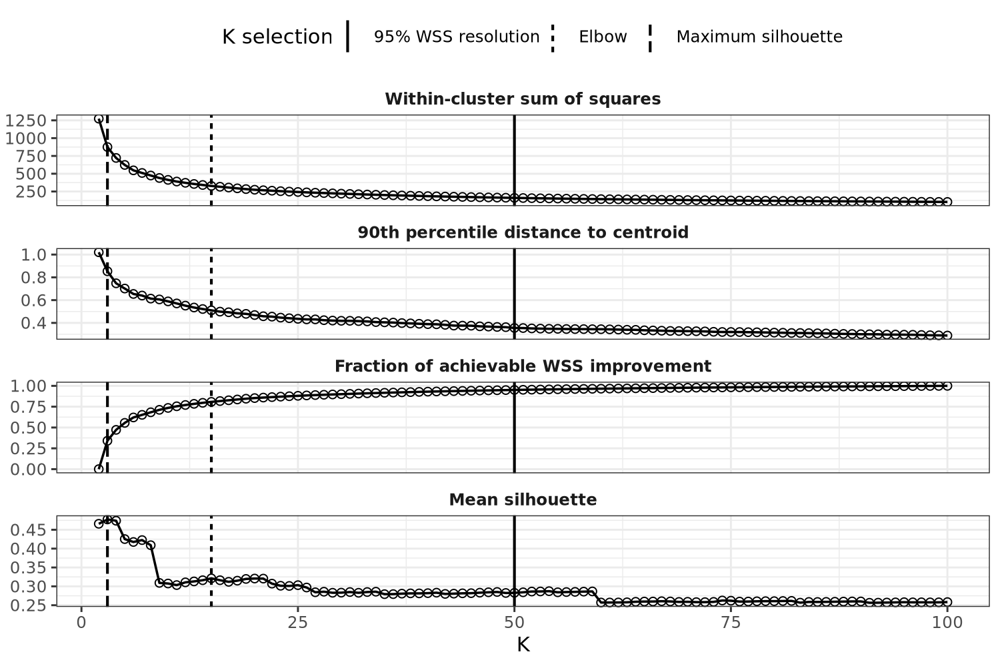

In [2302]:
D_use = D_joint
X_use = X_joint

hc <- hclust(D_use, method = "ward.D2")

clust_eval <- calculate_trajectory_clustering_metrics(X_mat = X_use, D = D_use, hc = hc, K_grid = 2:100, wss_fraction = 0.95, select_k_by = "elbow")
clust_eval$selection

options(repr.plot.width = 7.5, repr.plot.height = 5)
plot_trajectory_clustering_metrics(clust_eval, overlay = FALSE)

In [2309]:
cl <- cutree(hc, k = clust_eval$selection$k_silhouette)
gene_cluster_distance <- rep(NA_real_, nrow(X_use))
names(gene_cluster_distance) <- rownames(X_use)

for (k in sort(unique(cl))) {
  idx <- which(cl == k)
  Xi <- X_use[idx, , drop = FALSE]
  centroid <- colMeans(Xi)
  gene_cluster_distance[idx] <- sqrt(rowSums(sweep(Xi, 2, centroid, "-")^2))
}

disp_df <- data.frame(gene = rownames(X_use), cluster = cl, centroid_dist = gene_cluster_distance, stringsAsFactors = FALSE)

name <- "broad_induced"
cl.ls[[name]] <- cl
sil_df.ls[[name]] <- disp_df

cl <- cutree(hc, k = clust_eval$selection$k_elbow)
gene_cluster_distance <- rep(NA_real_, nrow(X_use))
names(gene_cluster_distance) <- rownames(X_use)

for (k in sort(unique(cl))) {
  idx <- which(cl == k)
  Xi <- X_use[idx, , drop = FALSE]
  centroid <- colMeans(Xi)
  gene_cluster_distance[idx] <- sqrt(rowSums(sweep(Xi, 2, centroid, "-")^2))
}

disp_df <- data.frame(gene = rownames(X_use), cluster = cl, centroid_dist = gene_cluster_distance, stringsAsFactors = FALSE)

name <- "fine_induced"
cl.ls[[name]] <- cl
sil_df.ls[[name]] <- disp_df

for (name in c("broad_induced", "fine_induced")) {
    # Add assignments back into pc_df
    pc_df[[paste0("cluster_", name)]] <- as.factor(cl.ls[[name]][rownames(pc_df)])
    pc_df[[paste0("cluster_dist_", name)]] <- sil_df.ls[[name]]$centroid_dist[match(rownames(pc_df), sil_df.ls[[name]]$gene)]
    
    # inspect cluster sizes
    print(name)
    print(sort(table(cl.ls[[name]]), decreasing = TRUE))
    
    cluster_name = paste0("cluster_", name)
    pc_df[[cluster_name]] <- factor(pc_df[[cluster_name]], levels = c(levels(pc_df[[cluster_name]]), "-1"))
    pc_df[[cluster_name]][is.na(pc_df[[cluster_name]])] <- "-1"
    pc_df[[cluster_name]] <- factor(pc_df[[cluster_name]])
}

[1] "broad_induced"

   2    1    3 
1846  742  623 
[1] "fine_induced"

  2   7   5  13   6   4   3   8  11  10   1   9  12  15  14 
968 613 239 208 204 189 170 165 126  85  72  57  43  43  29 


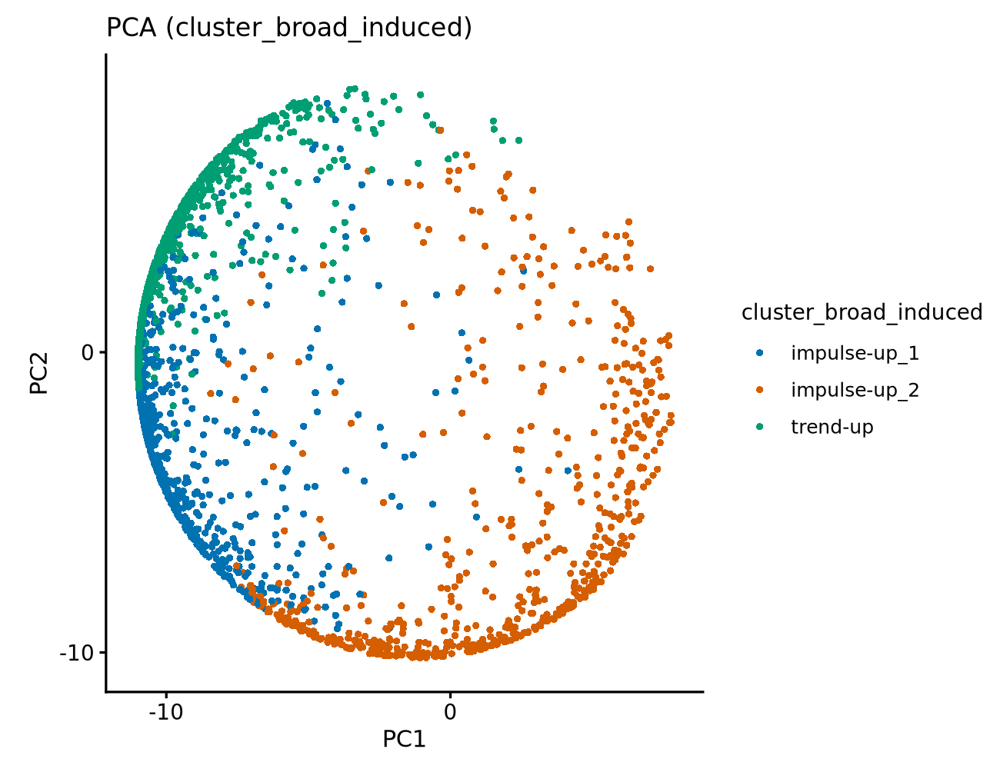

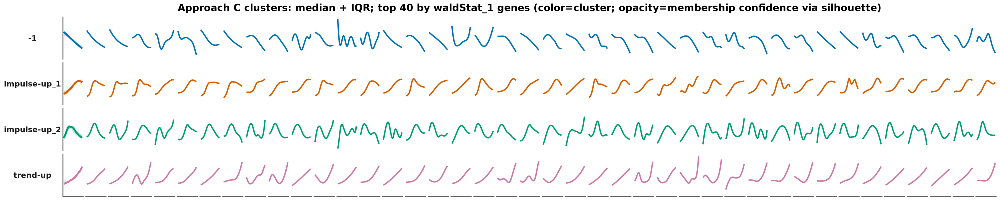

In [2968]:
options(repr.plot.width = 6.5, repr.plot.height = 5)

feature_plot_pc_simple(pc_df %>% filter(cluster_broad_induced != -1), feature = 'cluster_broad_induced', cat_colors = cat_colors_k60, alpha_col = NULL)

p1 <- plot_cluster_medoids_and_top_genes(seed = 10, traj_mat = traj_mat[rownames(X_use), ], cl = pc_df[rownames(X_use), ]$cluster_broad_induced,
  D = D_use, asso_df.ls = asso_df.ls, top_n = 40, show_sil_text = FALSE, show_median_iqr = TRUE, cat_colors = cat_colors_k60, X = X_mat[rownames(X_use), ], tt = tt, gene_selection = 'wald')

options(repr.plot.width = 20, repr.plot.height = length(unique(pc_df$cluster_broad_induced)), repr.plot.res = 200)
print(p1)

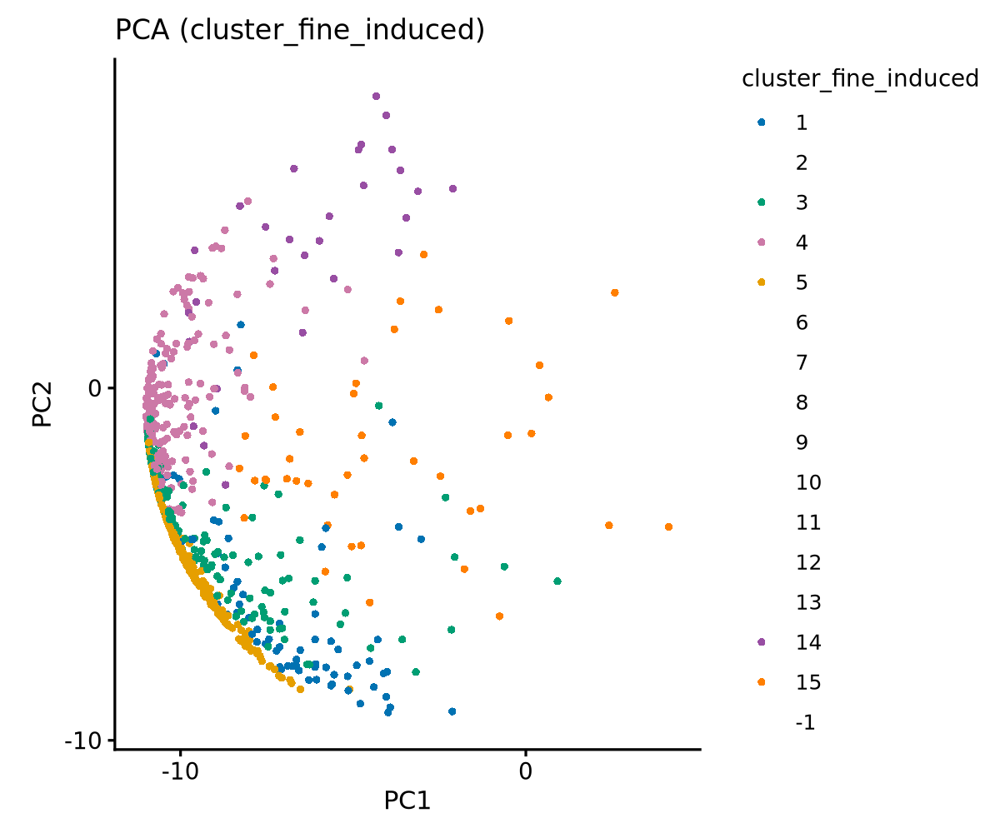

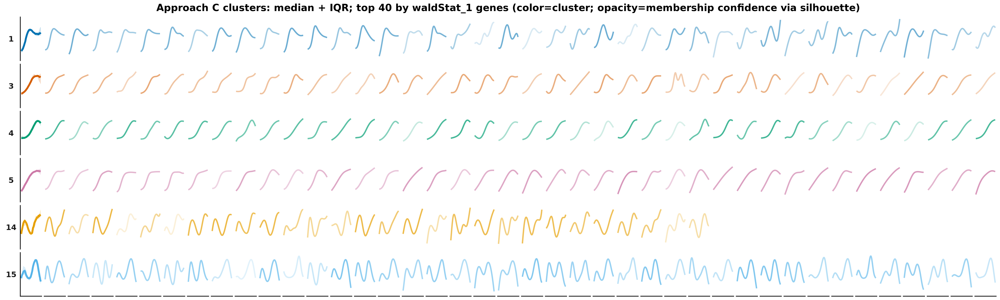

In [2312]:
query.rownames = rownames(pc_df %>% filter(cluster_broad_induced == 1))
query.D = dist(X_joint[query.rownames, ], method = "euclidean")

options(repr.plot.width = 6, repr.plot.height = 5)
feature_plot_pc_simple(pc_df[query.rownames, ], feature = "cluster_fine_induced", cat_colors = cat_colors_k60, alpha_col = NULL)

p1 <- plot_cluster_medoids_and_top_genes(seed = 10, traj_mat = traj_mat[query.rownames, ], cl = pc_df[query.rownames, ]$cluster_fine_induced,
  D = query.D, asso_df.ls = asso_df.ls, top_n = 40, show_sil_text = FALSE, show_median_iqr = TRUE, cat_colors = cat_colors_k60, X = X_mat[query.rownames, ], tt = tt, gene_selection = 'wald')

options(repr.plot.width = 20, repr.plot.height = length(unique(pc_df[query.rownames, ]$cluster_fine_induced)), repr.plot.res = 200)
print(p1)

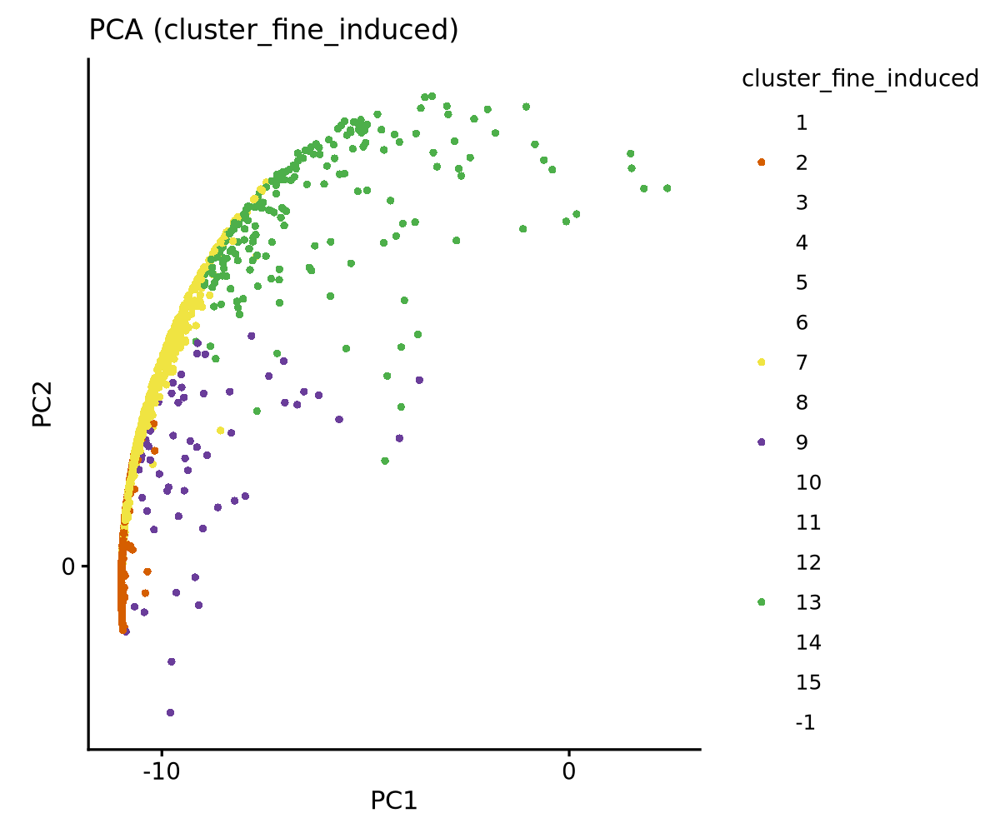

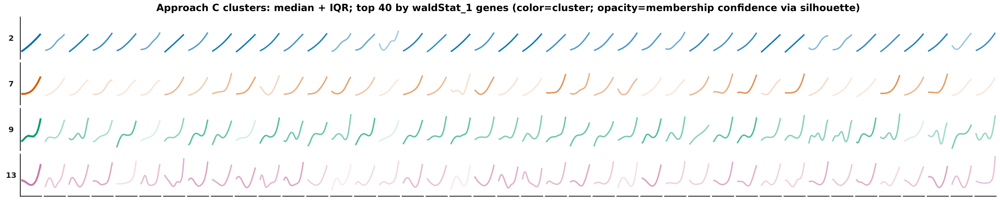

In [2313]:
query.rownames = rownames(pc_df %>% filter(cluster_broad_induced == 2))
query.D = dist(X_joint[query.rownames, ], method = "euclidean")

options(repr.plot.width = 6, repr.plot.height = 5)
feature_plot_pc_simple(pc_df[query.rownames, ], feature = "cluster_fine_induced", cat_colors = cat_colors_k60, alpha_col = NULL)

p1 <- plot_cluster_medoids_and_top_genes(seed = 10, traj_mat = traj_mat[query.rownames, ], cl = pc_df[query.rownames, ]$cluster_fine_induced,
  D = query.D, asso_df.ls = asso_df.ls, top_n = 40, show_sil_text = FALSE, show_median_iqr = TRUE, cat_colors = cat_colors_k60, X = X_mat[query.rownames, ], tt = tt, gene_selection = 'wald')

options(repr.plot.width = 20, repr.plot.height = length(unique(pc_df[query.rownames, ]$cluster_fine_induced)), repr.plot.res = 200)
print(p1)

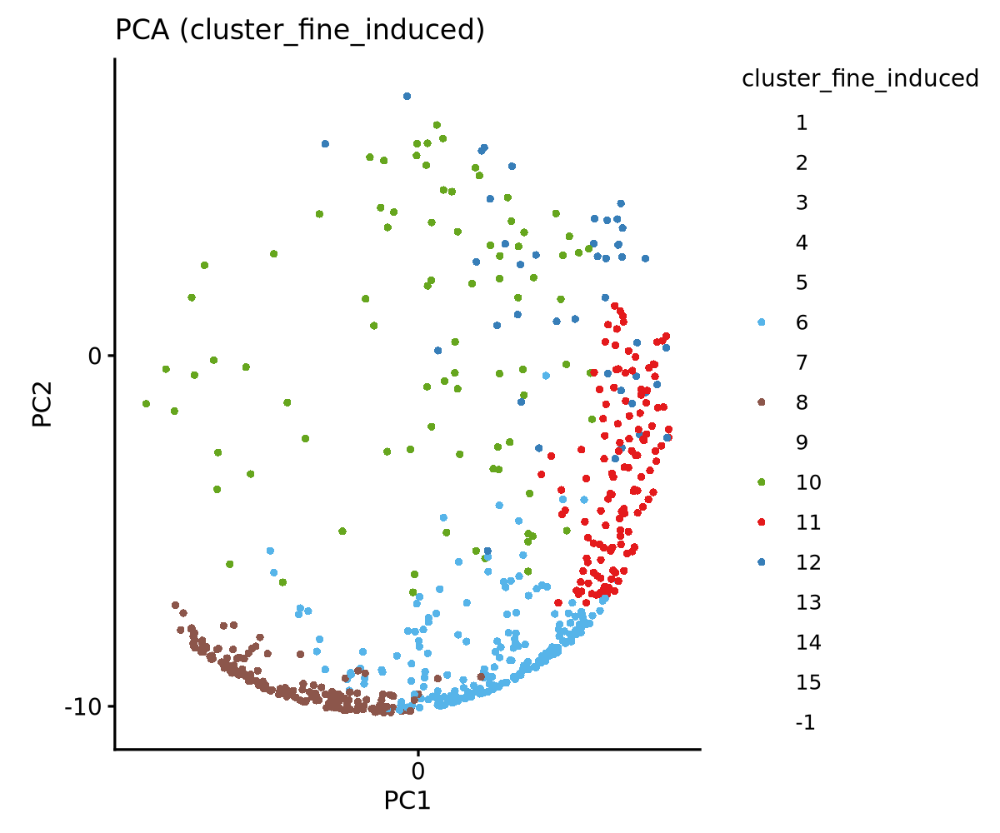

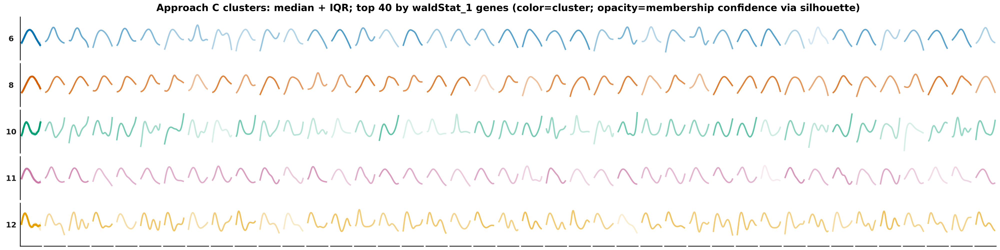

In [2314]:
query.rownames = rownames(pc_df %>% filter(cluster_broad_induced == 3))
query.D = dist(X_joint[query.rownames, ], method = "euclidean")

options(repr.plot.width = 6, repr.plot.height = 5)
feature_plot_pc_simple(pc_df[query.rownames, ], feature = "cluster_fine_induced", cat_colors = cat_colors_k60, alpha_col = NULL)

p1 <- plot_cluster_medoids_and_top_genes(seed = 10, traj_mat = traj_mat[query.rownames, ], cl = pc_df[query.rownames, ]$cluster_fine_induced,
  D = query.D, asso_df.ls = asso_df.ls, top_n = 40, show_sil_text = FALSE, show_median_iqr = TRUE, cat_colors = cat_colors_k60, X = X_mat[query.rownames, ], tt = tt, gene_selection = 'wald')

options(repr.plot.width = 20, repr.plot.height = length(unique(pc_df[query.rownames, ]$cluster_fine_induced)), repr.plot.res = 200)
print(p1)

$select_k_by
[1] "elbow"

$k_selected
[1] 18

$k_resolution
[1] 52

$k_elbow
[1] 18

$k_silhouette
[1] 3

$max_mean_silhouette
[1] 0.5472789

$wss_fraction
[1] 0.95

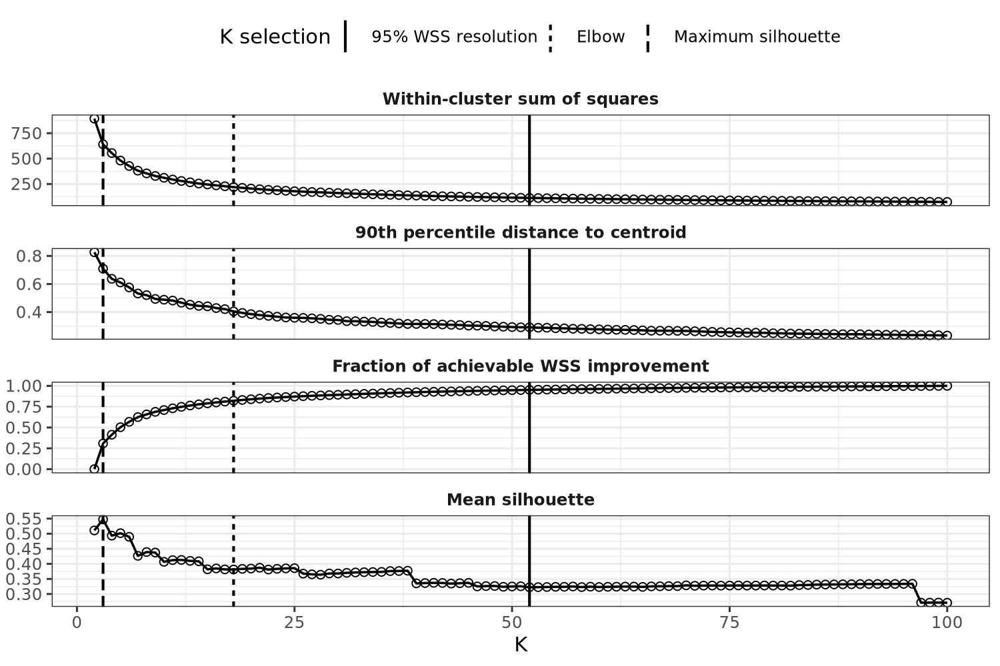

In [2315]:
subset.rownames = rownames(pc_df %>% filter(peak_log2fc < -lt))

X_joint <- cbind(sqrt(1 - alpha)*X_n, sqrt(alpha)*Xd_n)[subset.rownames, ]
D_joint <- dist(X_joint, method = "euclidean")

D_x <- dist(X_mat[subset.rownames, ], method = "euclidean") 
D_pca_x = dist(X_pc[subset.rownames, ], method = "euclidean")
D_pca_dx = dist(Xd_pc[subset.rownames, ], method = "euclidean")

D_use = D_joint
X_use = X_joint

hc <- hclust(D_use, method = "ward.D2")

clust_eval <- calculate_trajectory_clustering_metrics(X_mat = X_use, D = D_use, hc = hc, K_grid = 2:100, wss_fraction = 0.95, select_k_by = "elbow")
clust_eval$selection

options(repr.plot.width = 7.5, repr.plot.height = 5)
plot_trajectory_clustering_metrics(clust_eval, overlay = FALSE)

In [2316]:
cl <- cutree(hc, k = clust_eval$selection$k_silhouette)
gene_cluster_distance <- rep(NA_real_, nrow(X_use))
names(gene_cluster_distance) <- rownames(X_use)

for (k in sort(unique(cl))) {
  idx <- which(cl == k)
  Xi <- X_use[idx, , drop = FALSE]
  centroid <- colMeans(Xi)
  gene_cluster_distance[idx] <- sqrt(rowSums(sweep(Xi, 2, centroid, "-")^2))
}

disp_df <- data.frame(gene = rownames(X_use), cluster = cl, centroid_dist = gene_cluster_distance, stringsAsFactors = FALSE)

name <- "broad_repressed"
cl.ls[[name]] <- cl
sil_df.ls[[name]] <- disp_df

cl <- cutree(hc, k = clust_eval$selection$k_elbow)
gene_cluster_distance <- rep(NA_real_, nrow(X_use))
names(gene_cluster_distance) <- rownames(X_use)

for (k in sort(unique(cl))) {
  idx <- which(cl == k)
  Xi <- X_use[idx, , drop = FALSE]
  centroid <- colMeans(Xi)
  gene_cluster_distance[idx] <- sqrt(rowSums(sweep(Xi, 2, centroid, "-")^2))
}

disp_df <- data.frame(gene = rownames(X_use), cluster = cl, centroid_dist = gene_cluster_distance, stringsAsFactors = FALSE)

name <- "fine_repressed"
cl.ls[[name]] <- cl
sil_df.ls[[name]] <- disp_df

for (name in c("broad_repressed", "fine_repressed")) {
    # Add assignments back into pc_df
    pc_df[[paste0("cluster_", name)]] <- as.factor(cl.ls[[name]][rownames(pc_df)])
    pc_df[[paste0("cluster_dist_", name)]] <- sil_df.ls[[name]]$centroid_dist[match(rownames(pc_df), sil_df.ls[[name]]$gene)]
    
    # inspect cluster sizes
    print(name)
    print(sort(table(cl.ls[[name]]), decreasing = TRUE))
    
    cluster_name = paste0("cluster_", name)
    pc_df[[cluster_name]] <- factor(pc_df[[cluster_name]], levels = c(levels(pc_df[[cluster_name]]), "-1"))
    pc_df[[cluster_name]][is.na(pc_df[[cluster_name]])] <- "-1"
    pc_df[[cluster_name]] <- factor(pc_df[[cluster_name]])
}

[1] "broad_repressed"

   1    2    3 
1993 1210  310 
[1] "fine_repressed"

   1    5    4    3    6   11   12   13    9    8   17   16   14   10    2   18 
1360  356  275  242  226  170  146  137  114  109   84   75   53   48   32   32 
   7   15 
  27   27 


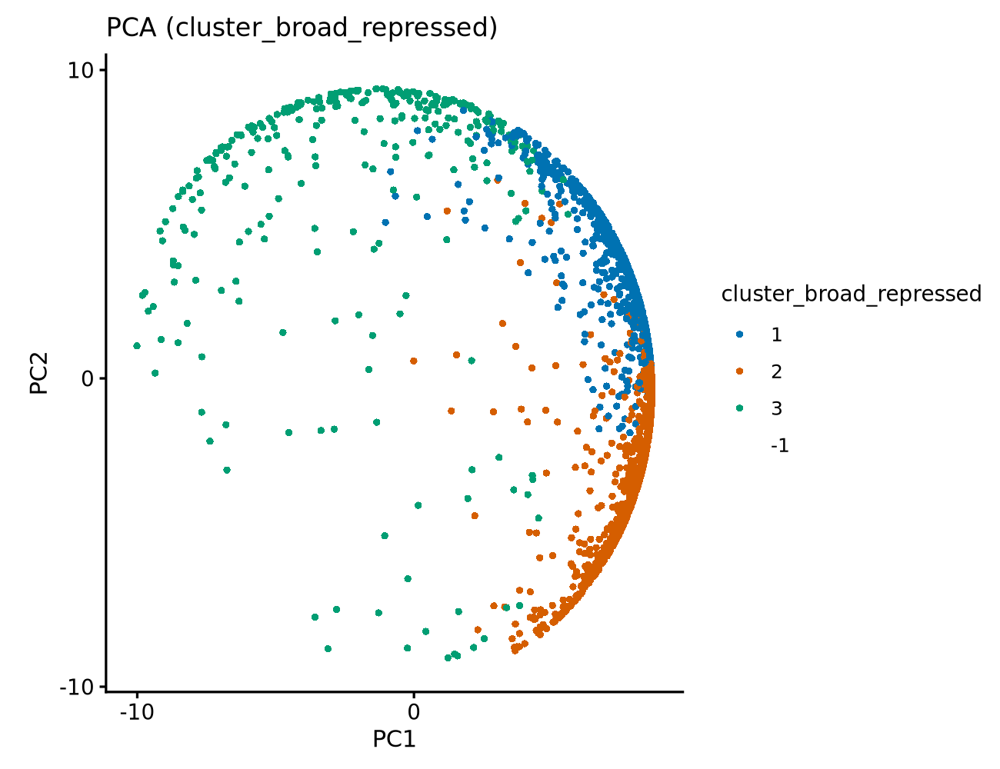

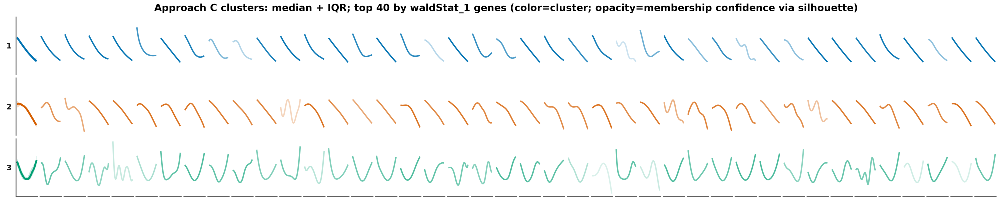

In [2317]:
options(repr.plot.width = 6.5, repr.plot.height = 5)

feature_plot_pc_simple(pc_df %>% filter(cluster_broad_repressed != -1), feature = 'cluster_broad_repressed', cat_colors = cat_colors_k60, alpha_col = NULL)

p1 <- plot_cluster_medoids_and_top_genes(seed = 10, traj_mat = traj_mat[rownames(X_use), ], cl = pc_df[rownames(X_use), ]$cluster_broad_repressed,
  D = D_use, asso_df.ls = asso_df.ls, top_n = 40, show_sil_text = FALSE, show_median_iqr = TRUE, cat_colors = cat_colors_k60, X = X_mat[rownames(X_use), ], tt = tt, gene_selection = 'wald')

options(repr.plot.width = 20, repr.plot.height = length(unique(pc_df$cluster_broad_repressed)), repr.plot.res = 200)
print(p1)

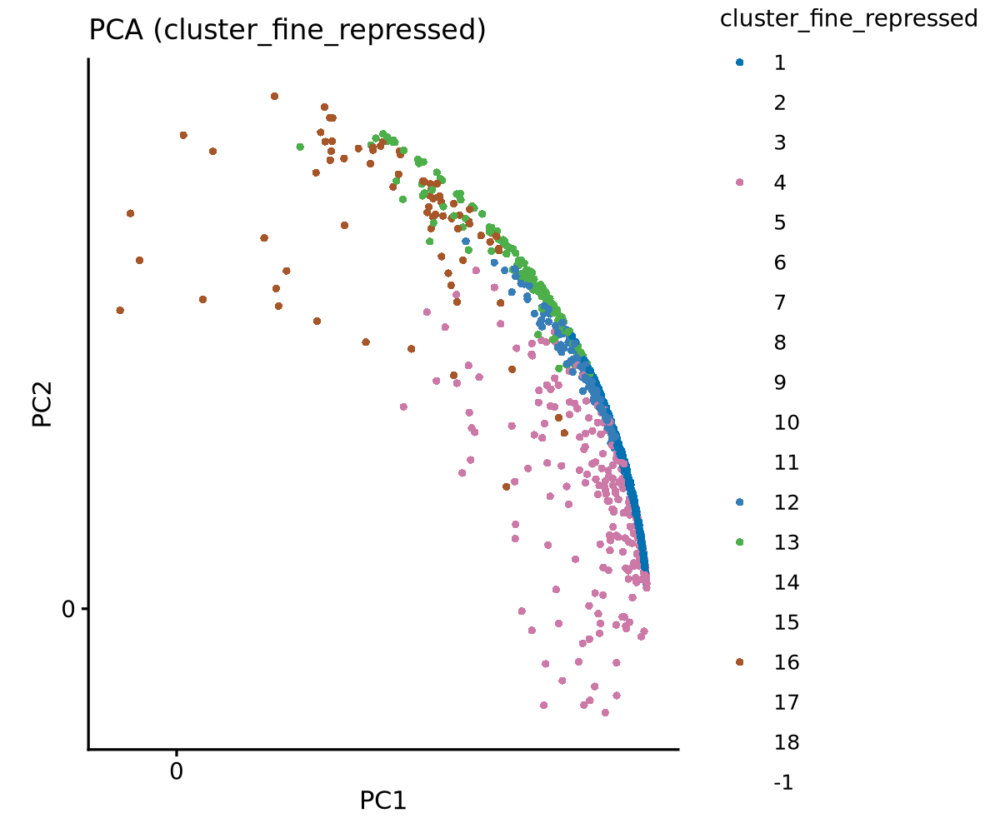

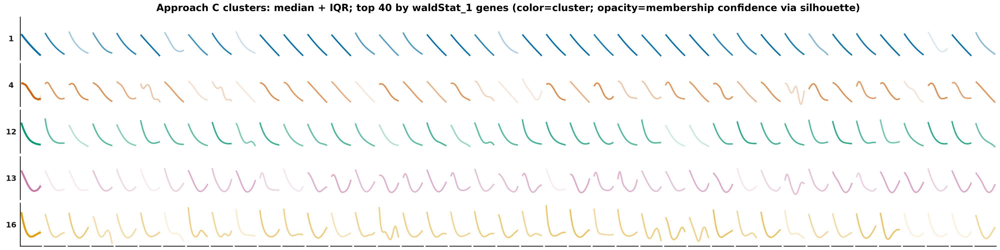

In [2318]:
query.rownames = rownames(pc_df %>% filter(cluster_broad_repressed == 1))
query.D = dist(X_joint[query.rownames, ], method = "euclidean")

options(repr.plot.width = 6, repr.plot.height = 5)
feature_plot_pc_simple(pc_df[query.rownames, ], feature = "cluster_fine_repressed", cat_colors = cat_colors_k60, alpha_col = NULL)

p1 <- plot_cluster_medoids_and_top_genes(seed = 10, traj_mat = traj_mat[query.rownames, ], cl = pc_df[query.rownames, ]$cluster_fine_repressed,
  D = query.D, asso_df.ls = asso_df.ls, top_n = 40, show_sil_text = FALSE, show_median_iqr = TRUE, cat_colors = cat_colors_k60, X = X_mat[query.rownames, ], tt = tt, gene_selection = 'wald')

options(repr.plot.width = 20, repr.plot.height = length(unique(pc_df[query.rownames, ]$cluster_fine_repressed)), repr.plot.res = 200)
print(p1)

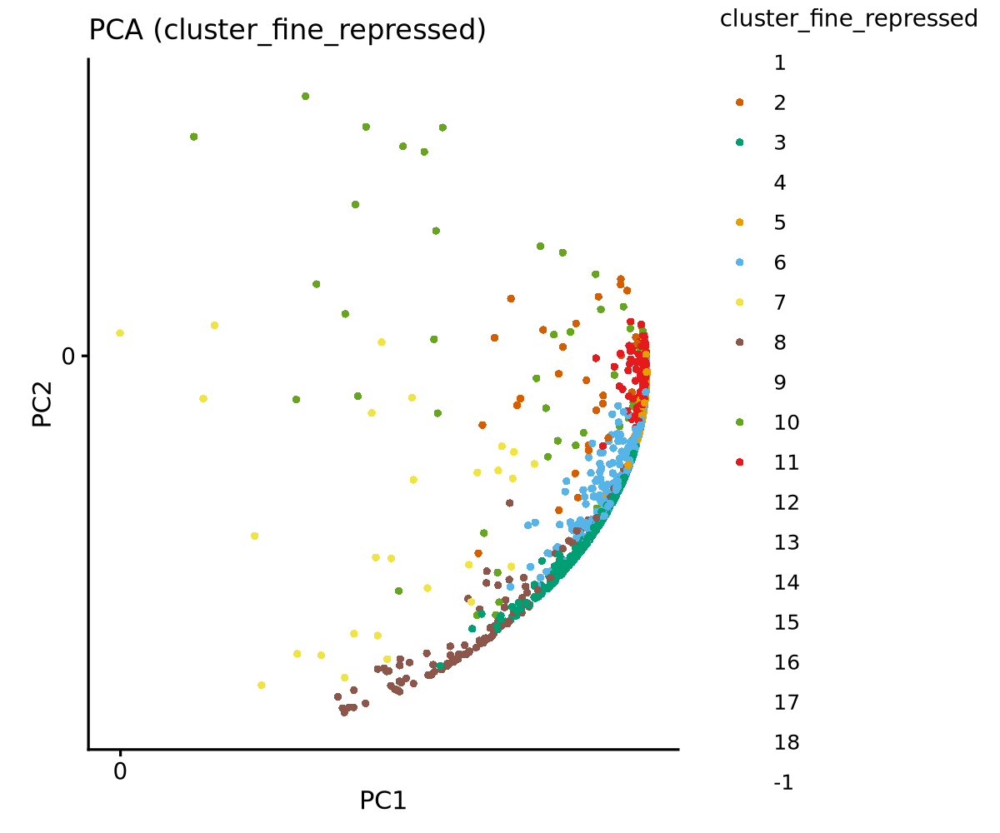

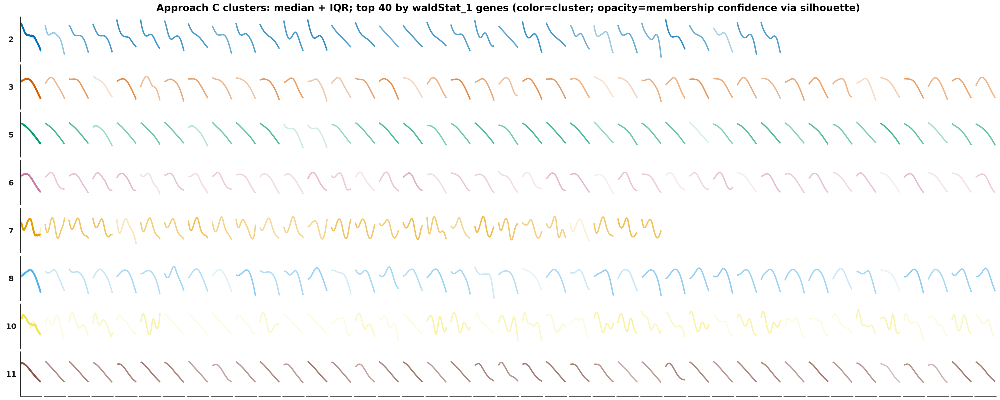

In [2319]:
query.rownames = rownames(pc_df %>% filter(cluster_broad_repressed == 2))
query.D = dist(X_joint[query.rownames, ], method = "euclidean")

options(repr.plot.width = 6, repr.plot.height = 5)
feature_plot_pc_simple(pc_df[query.rownames, ], feature = "cluster_fine_repressed", cat_colors = cat_colors_k60, alpha_col = NULL)

p1 <- plot_cluster_medoids_and_top_genes(seed = 10, traj_mat = traj_mat[query.rownames, ], cl = pc_df[query.rownames, ]$cluster_fine_repressed,
  D = query.D, asso_df.ls = asso_df.ls, top_n = 40, show_sil_text = FALSE, show_median_iqr = TRUE, cat_colors = cat_colors_k60, X = X_mat[query.rownames, ], tt = tt, gene_selection = 'wald')

options(repr.plot.width = 20, repr.plot.height = length(unique(pc_df[query.rownames, ]$cluster_fine_repressed)), repr.plot.res = 200)
print(p1)

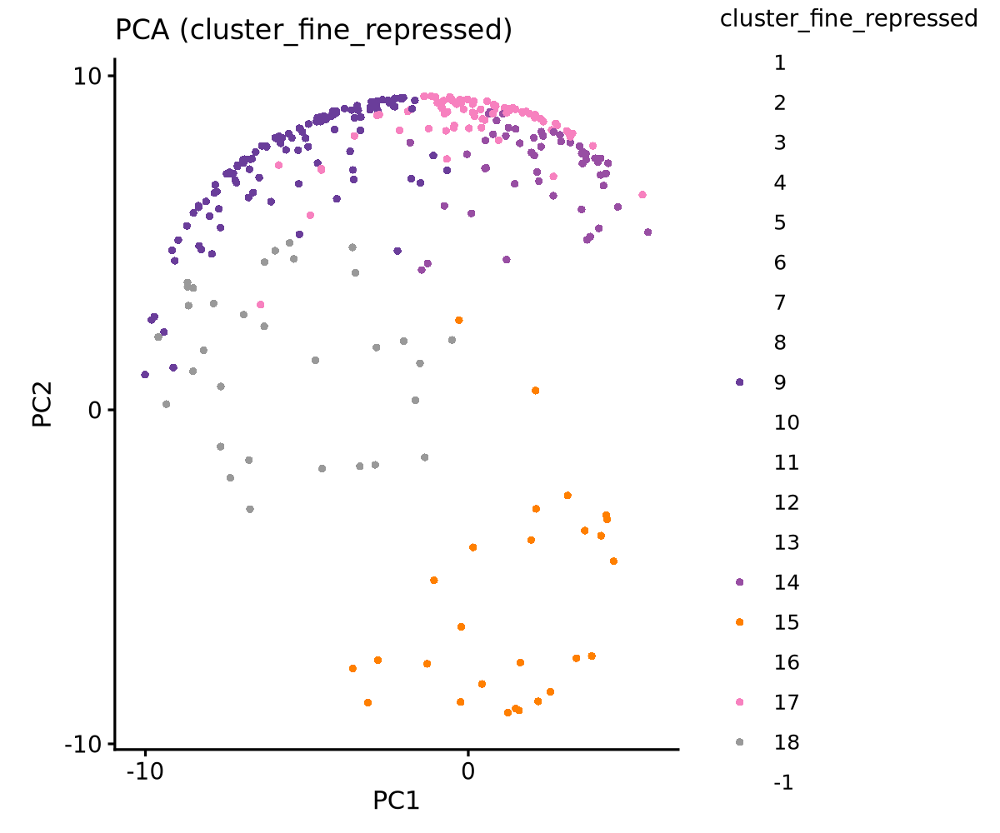

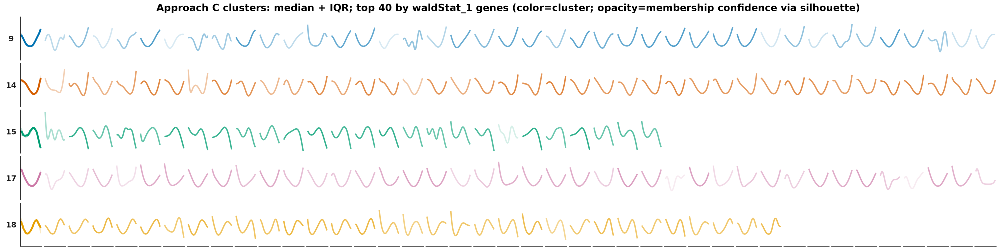

In [2320]:
query.rownames = rownames(pc_df %>% filter(cluster_broad_repressed == 3))
query.D = dist(X_joint[query.rownames, ], method = "euclidean")

options(repr.plot.width = 6, repr.plot.height = 5)
feature_plot_pc_simple(pc_df[query.rownames, ], feature = "cluster_fine_repressed", cat_colors = cat_colors_k60, alpha_col = NULL)

p1 <- plot_cluster_medoids_and_top_genes(seed = 10, traj_mat = traj_mat[query.rownames, ], cl = pc_df[query.rownames, ]$cluster_fine_repressed,
  D = query.D, asso_df.ls = asso_df.ls, top_n = 40, show_sil_text = FALSE, show_median_iqr = TRUE, cat_colors = cat_colors_k60, X = X_mat[query.rownames, ], tt = tt, gene_selection = 'wald')

options(repr.plot.width = 20, repr.plot.height = length(unique(pc_df[query.rownames, ]$cluster_fine_repressed)), repr.plot.res = 200)
print(p1)

In [2321]:
RenameClusters <- function(x) {
    x <- as.character(x)
    if (x == '1') { return('impulse-up_1') }
    if (x == '2') { return('trend-up') }
    if (x == '3') { return('impulse-up_2') }
    else { return(x) }
}

pc_df$cluster_broad_induced = sapply(pc_df$cluster_broad_induced, RenameClusters, USE.NAMES = F)

In [2322]:
RenameClusters <- function(x) {
    x <- as.character(x)
    if (x == '1') { return('trend-down_1') }
    if (x == '2') { return('trend-down_2') }
    if (x == '3') { return('transient-down') }
    else { return(x) }
}

cl_repressed_renamed = sapply(cl_repressed, RenameClusters, USE.NAMES = F)

pc_df$cluster_broad_repressed = sapply(pc_df$cluster_broad_repressed, RenameClusters, USE.NAMES = F)

In [2323]:
pc_df$broad_cluster <- factor(ifelse(pc_df$cluster_broad_induced != "-1", as.character(pc_df$cluster_broad_induced), as.character(pc_df$cluster_broad_repressed)))

table(pc_df$broad_cluster)


  impulse-up_1   impulse-up_2 transient-down   trend-down_1   trend-down_2 
           742            623            310           1993           1210 
      trend-up 
          1846 

In [2327]:
pc_df$cluster_dist_broad <- dplyr::coalesce(pc_df$cluster_dist_broad_induced, pc_df$cluster_dist_broad_repressed)
pc_df$cluster_dist_fine <- dplyr::coalesce(pc_df$cluster_dist_fine_induced, pc_df$cluster_dist_fine_repressed)

In [2980]:
subset.rownames = rownames(pc_df %>% filter(cell_type == 'K562a', abs(peak_log2fc) > 0.5, pvalue_1 < 0.05))
X_joint <- cbind(sqrt(1 - alpha)*X_n, sqrt(alpha)*Xd_n)[subset.rownames, ]
D_joint <- dist(X_joint, method = "euclidean")
D_use = D_joint
X_use = X_joint

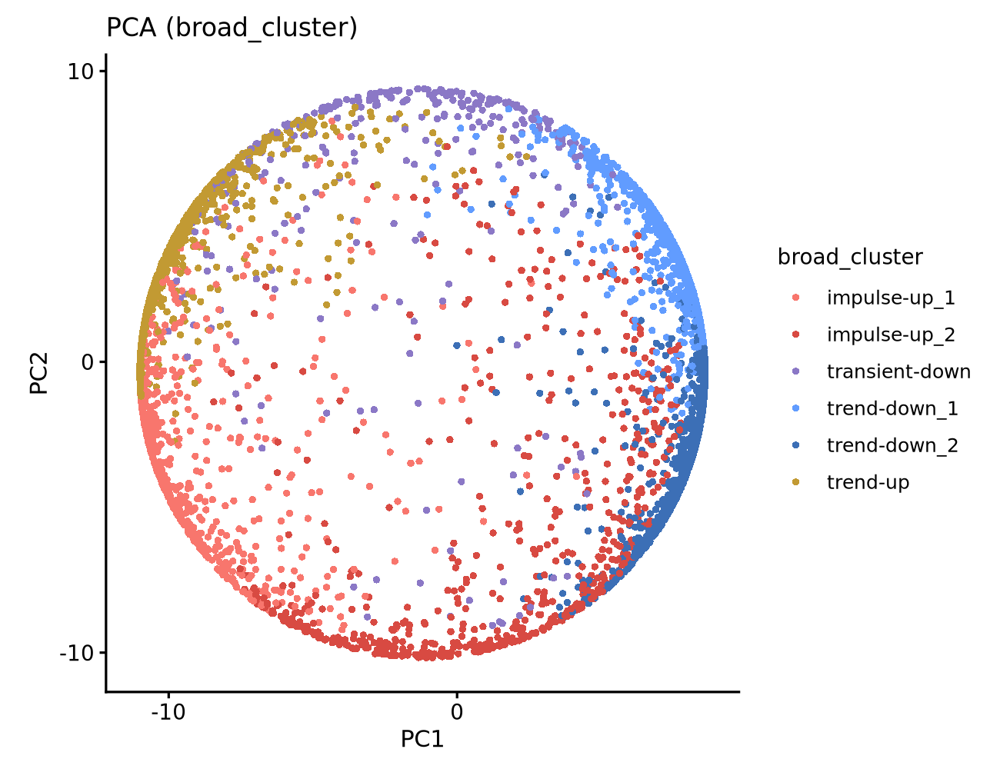

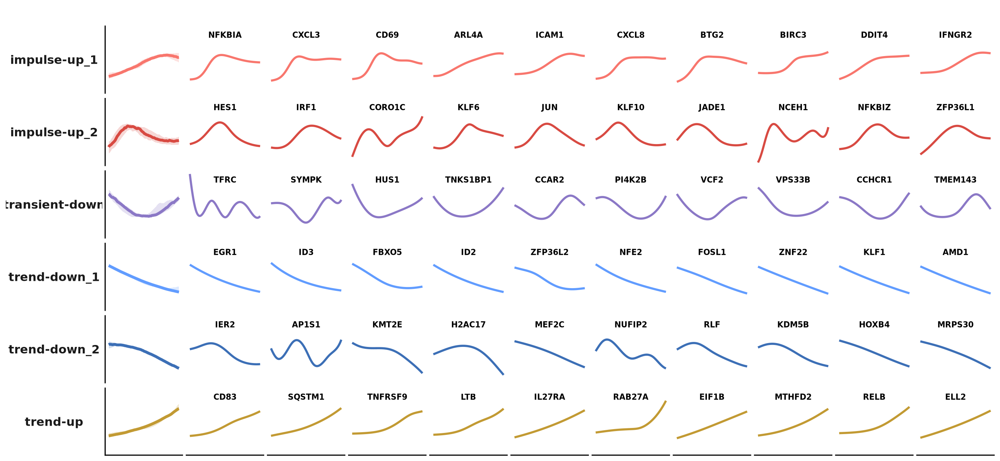

In [2981]:
options(repr.plot.width = 6.5, repr.plot.height = 5)

feature_plot_pc_simple(pc_df, feature = "broad_cluster", cat_colors = cluster_colors, alpha_col = NULL)

p1 <- plot_cluster_medoids_and_top_genes(seed = 10, traj_mat = traj_mat[rownames(X_use), ], cl = pc_df[rownames(X_use), ]$broad_cluster, gene_title_mode = "gene_sym", use_silhouette_alpha = FALSE,
  D = D_use, asso_df.ls = asso_df.ls, top_n = 10, show_sil_text = FALSE, show_median_iqr = TRUE, cat_colors = cluster_colors, X = X_mat[rownames(X_use), ], tt = tt, gene_selection = 'wald', show_gene_titles = TRUE) + ggtitle('')

options(repr.plot.width = 13, repr.plot.height = length(unique(pc_df$broad_cluster)), repr.plot.res = 200)
print(p1)

In [2982]:
ggsave(
  filename = "../../../notebooks/figures/cluster_broad_trajectories.pdf",
  plot = p1,
  width = 13,
  height = length(unique(pc_df$broad_cluster)),
  units = "in",
  device = cairo_pdf
)

In [2474]:
cluster_colors <- c(
  "impulse-up_1"   = "#FF91A4",
  "impulse-up_2"   = "#DE3163",
  "trend-up"       = "#E69F00",
  "transient-down" = "#5D3FD3",
  "trend-down_1"   = "#619CFF",
  "trend-down_2"   = "#3C6FB6"
)

options(repr.plot.width = 3.5, repr.plot.height = 3.5, repr.plot.res = 300)

p1 = feature_plot_pc_simple(pc_df, feature = "broad_cluster", cat_colors = cluster_colors, alpha_col = NULL, show_legend = FALSE,
                       point_size = c("transient-down" = 1.75, "trend-down_1" = 1.75, "trend-down_2" = 1.75, "impulse-up_1" = 1.75, "impulse-up_2" = 1.75, "trend-up" = 1.75)) + ggtitle('')

# ggsave(
#   "../../../notebooks/figures/broad_cluster_PCA.pdf",
#   plot = p1,
#   width = 3.5,
#   height = 3.5,
#   units = "in"
# )

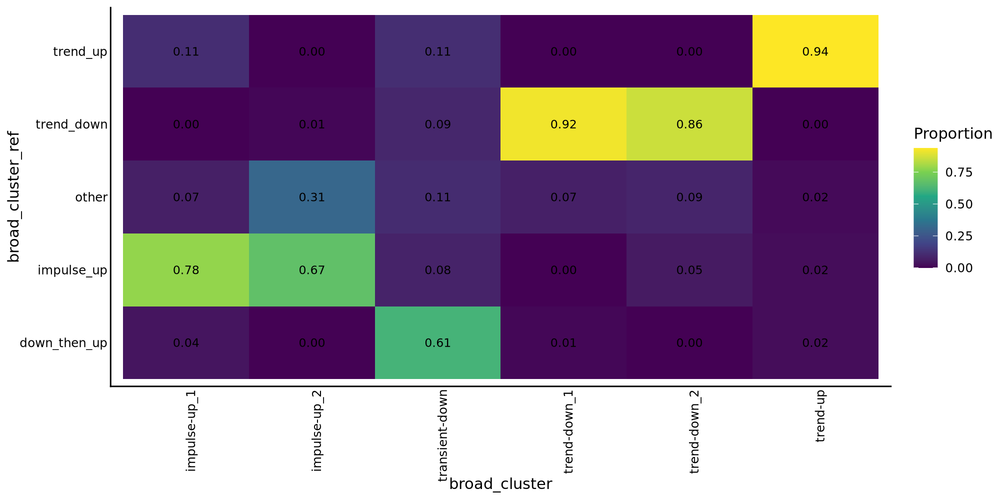

In [2334]:
options(repr.plot.width = 10, repr.plot.height = 5, repr.plot.res = 200)

plot_cluster_confusion(
  pc_df,
  "broad_cluster",
  "broad_cluster_ref",
  normalize = "col"
)

In [2423]:
pc_df$cluster_fine_induced

[1] 1  1  1  2  3  4  5  1  3  5  4  6  7  1  -1 8  2  4  1  5  2  4  2  8 
  [25] 8  1  -1 -1 4  5  3  -1 2  -1 1  3  -1 4  2  -1 7  2  7  2  7  3  -1 -1
  [49] -1 4  -1 7  9  7  -1 7  1  -1 4  -1 -1 -1 5  -1 3  -1 4  4  4  6  10 4 
  [73] -1 -1 -1 -1 -1 -1 11 2  -1 4  10 1  -1 -1 -1 12 -1 7  13 3  7  4  3  7 
  [97] -1 -1 3  8  -1 5  12 -1 -1 7  -1 14 8  7  3  -1 -1 2  4  -1 5  2  -1 3 
 [121] 7  8  -1 1  6  10 13 6  -1 -1 5  -1 -1 11 -1 3  9  14 -1 -1 2  -1 -1 -1
 [145] -1 14 7  2  3  -1 -1 8  1  -1 4  -1 -1 8  10 -1 2  -1 2  -1 -1 5  1  -1
 [169] -1 -1 9  10 12 -1 -1 -1 7  15 -1 7  -1 -1 -1 7  -1 8  12 10 -1 7  2  7 
 [193] -1 -1 -1 10 -1 -1 9  -1 7  8  -1 -1 7  -1 12 -1 -1 7  2  -1 7  -1 -1 15
 [217] -1 13 -1 -1 2  7  -1 -1 -1 6  -1 -1 13 11 13 7  10 14 15 -1 2  -1 -1 2 
 [241] -1 7  -1 -1 -1 10 6  -1 -1 -1 9  8  7  3  -1 -1 -1 7  -1 -1 -1 -1 13 -1
 [265] -1 -1 -1 -1 -1 -1 10 2  7  -1 -1 2  5  -1 8  -1 1  -1 7  -1 -1 -1 3  -1
 [289] 10 -1 -1 -1 7  -1 -1 -1 8  2  2  7  13 -1 -1 3  2  -1 -1 2  -1 -1 11 -1
 [313] 7  7  -1 -1 -1 -1 6  -1 2  7  -1 2  4  -1 -1 15 6  7  -1 -1 -1 -1 -1 2 
 [337] 6  7  -1 2  12 -1 11 -1 7  7  2  10 -1 7  11 -1 11 6  -1 7  5  -1 12 -1
 [361] -1 -1 13 9  10 -1 14 -1 -1 -1 13 -1 7  2  -1 7  -1 -1 -1 7  -1 -1 3  6 
 [385] -1 7  11 -1 2  14 11 -1 -1 2  7  7  -1 -1 7  -1 2  2  -1 -1 6  -1 13 -1
 [409] 6  5  10 -1 -1 15 2  11 -1 -1 -1 -1 13 -1 3  -1 7  3  -1 -1 -1 11 2  11
 [433] -1 -1 -1 13 6  -1 -1 -1 15 4  -1 -1 -1 7  -1 3  -1 -1 -1 6  5  2  -1 -1
 [457] -1 8  -1 -1 14 -1 -1 5  -1 6  7  -1 2  -1 2  8  -1 12 3  -1 -1 -1 -1 -1
 [481] -1 2  -1 -1 2  3  7  -1 7  12 -1 -1 -1 -1 1  -1 -1 7  -1 -1 -1 -1 -1 2 
 [505] 7  2  15 -1 -1 -1 7  2  -1 -1 -1 -1 10 11 -1 2  9  -1 -1 -1 -1 12 -1 8 
 [529] 10 5  1  -1 -1 -1 2  6  3  7  4  -1 -1 -1 -1 -1 -1 -1 10 11 -1 -1 7  10
 [553] -1 -1 2  4  7  -1 -1 2  14 6  11 -1 -1 2  11 -1 2  7  -1 11 11 7  2  -1
 [577] 2  2  -1 -1 -1 6  -1 6  -1 -1 -1 -1 -1 2  13 5  11 3  2  -1 -1 -1 -1 -1
 [601] -1 2  -1 -1 -1 7  -1 -1 3  -1 -1 -1 11 -1 2  -1 -1 -1 -1 -1 -1 8  -1 4 
 [625] 2  6  -1 7  7  -1 2  -1 7  -1 13 -1 -1 2  5  2  15 -1 -1 10 2  12 -1 -1
 [649] -1 -1 3  -1 -1 6  -1 -1 -1 -1 -1 2  5  2  -1 7  -1 7  13 2  -1 -1 -1 13
 [673] 6  -1 8  4  11 -1 7  -1 15 -1 6  5  2  8  -1 2  6  7  7  -1 11 6  11 -1
 [697] -1 -1 2  7  -1 -1 7  -1 -1 -1 -1 -1 5  -1 2  -1 -1 6  -1 13 8  -1 -1 4 
 [721] -1 5  -1 -1 2  2  7  7  -1 5  4  2  6  1  11 2  -1 13 7  -1 9  -1 -1 7 
 [745] 7  2  9  11 -1 7  4  -1 13 -1 -1 -1 11 -1 -1 6  5  5  -1 7  -1 -1 13 8 
 [769] 11 7  -1 -1 -1 2  -1 5  2  3  -1 11 5  6  -1 13 10 6  -1 -1 -1 2  -1 -1
 [793] -1 -1 3  -1 10 2  -1 -1 -1 1  5  2  15 -1 -1 2  2  2  -1 -1 -1 -1 7  -1
 [817] 8  4  2  -1 1  -1 7  -1 -1 -1 -1 -1 7  -1 -1 8  -1 -1 -1 2  -1 11 -1 -1
 [841] 6  -1 -1 7  -1 13 7  -1 4  -1 3  13 6  -1 7  -1 13 -1 5  -1 -1 6  5  -1
 [865] -1 2  2  6  -1 -1 2  -1 -1 14 -1 12 -1 5  11 -1 -1 2  -1 -1 -1 7  -1 13
 [889] -1 2  5  -1 -1 -1 -1 -1 2  -1 7  -1 6  12 7  -1 7  5  -1 -1 7  -1 -1 -1
 [913] 2  13 -1 7  4  -1 -1 13 -1 -1 -1 -1 -1 -1 -1 11 13 8  -1 -1 -1 -1 13 -1
 [937] -1 2  13 4  -1 -1 6  -1 -1 2  6  2  -1 -1 -1 -1 4  -1 -1 8  -1 -1 -1 -1
 [961] 7  -1 11 -1 2  -1 4  3  -1 9  6  4  -1 13 6  -1 -1 -1 -1 2  15 6  -1 2 
 [985] -1 3  -1 2  2  -1 -1 -1 -1 -1 -1 -1 -1 13 11 11 6  2  2  -1 7  11 -1 3 
[1009] 5  -1 -1 15 2  -1 -1 -1 2  -1 -1 -1 -1 -1 11 -1 -1 2  12 -1 -1 -1 -1 6 
[1033] 8  -1 -1 -1 7  -1 -1 11 -1 4  1  5  -1 -1 -1 2  -1 10 -1 -1 -1 8  3  -1
[1057] 8  2  -1 12 7  -1 -1 7  -1 -1 -1 -1 7  6  2  6  -1 -1 7  2  -1 8  -1 13
[1081] 2  -1 7  11 -1 -1 7  -1 -1 2  -1 13 13 2  -1 -1 -1 -1 7  2  -1 -1 9  8 
[1105] 15 -1 15 -1 -1 -1 -1 11 -1 13 -1 -1 -1 1  13 6  2  2  -1 -1 2  2  -1 11
[1129] 2  7  -1 -1 -1 -1 -1 -1 4  6  7  2  4  -1 -1 2  -1 -1 11 3  9  -1 -1 14
[1153] 15 2  2  -1 -1 2  -1 -1 -1 -1 -1 -1 -1 5  -1 2  7  -1 -1 -1 5  8  2  4 
[1177] 10 -1 -1 -1 -1 -1 4  1  -1 -1 -1 -1 -1 -1 11 -1 -1 -1 7  2  -1 -1 -1 11
[1201] 4  2  -1 -1 6  -1 13 7  -1 -1 7  -1 2  -1 -1 6

In [2983]:
write.csv(pc_df, 'pc_df.new.csv')

In [2422]:
saveRDS(pc_df, 'pc_df.new.rds')

In [20]:
pc_df = readRDS('pc_df.new.rds')

In [21]:
1

[1] 1

# 7. Subclustering investigation

In [1944]:
alpha <- 0.25
subset.rownames = rownames(pc_df %>% filter(broad_cluster == 'impulse-up_2'))

In [1945]:
X_joint <- cbind(sqrt(1 - alpha)*X_n, sqrt(alpha)*Xd_n)[subset.rownames, ]
D_joint <- dist(X_joint, method = "euclidean")

In [1946]:
D_use = D_joint
X_use = X_joint

In [1947]:
# hc <- hclust(D_use, method = "ward.D2")
hc <- hclust(D_use, method = "mcquitty")

$select_k_by
[1] "elbow"

$k_selected
[1] 16

$k_resolution
[1] 67

$k_elbow
[1] 16

$k_silhouette
[1] 2

$max_mean_silhouette
[1] 0.3370218

$wss_fraction
[1] 0.95

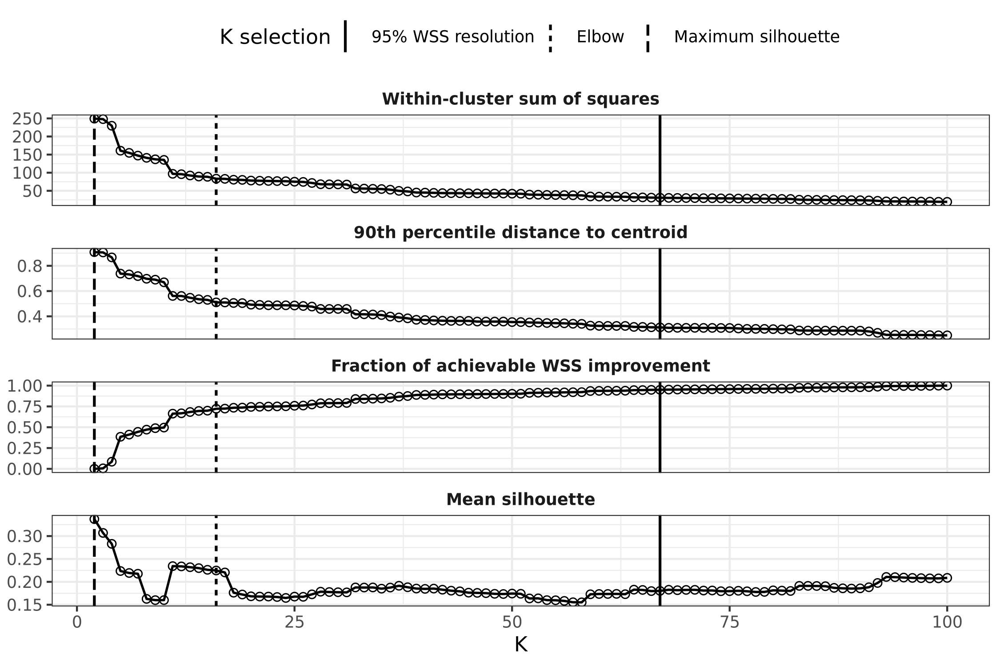

In [1948]:
clust_eval <- calculate_trajectory_clustering_metrics(X_mat = X_use, D = D_use, hc = hc, K_grid = 2:100, wss_fraction = 0.95, select_k_by = "elbow")
clust_eval$selection

options(repr.plot.width = 7.5, repr.plot.height = 5)
plot_trajectory_clustering_metrics(clust_eval, overlay = FALSE)

[1] "tmp"

  3   2   5   7   4   1   8  13  10  11  12   9   6  14  15  16 
202 144  97  55  30  21  17  16   9   9   8   5   3   3   3   1 


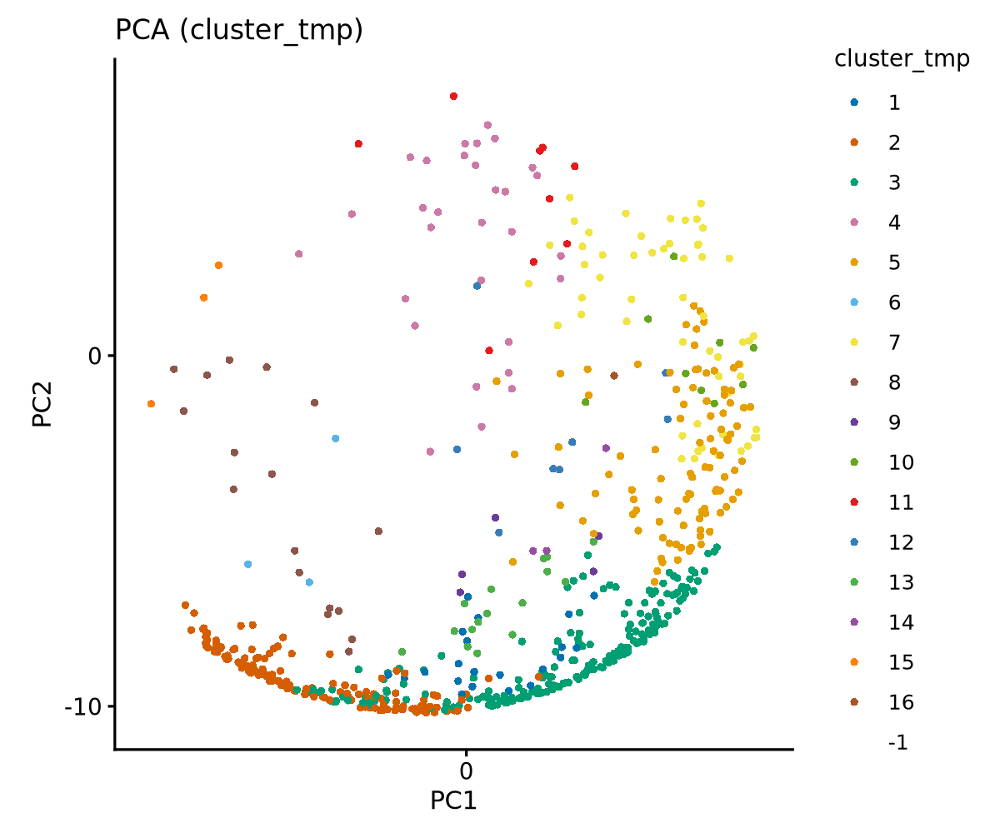

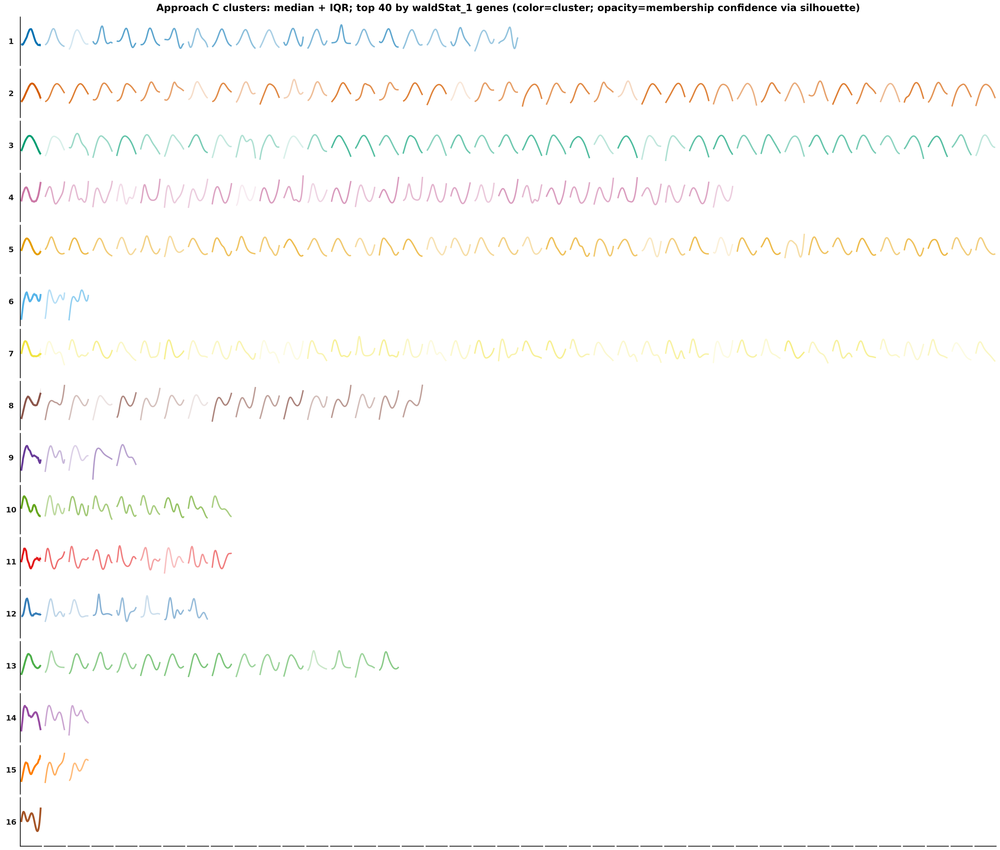

In [1949]:
cl <- cutree(hc, k = 16)

gene_cluster_distance <- rep(NA_real_, nrow(X_use))
names(gene_cluster_distance) <- rownames(X_use)

for (k in sort(unique(cl))) {
  idx <- which(cl == k)
  Xi <- X_use[idx, , drop = FALSE]
  centroid <- colMeans(Xi)
  gene_cluster_distance[idx] <- sqrt(rowSums(sweep(Xi, 2, centroid, "-")^2))
}

disp_df <- data.frame(gene = rownames(X_use), cluster = cl, centroid_dist = gene_cluster_distance, stringsAsFactors = FALSE)

name <- "tmp"
cl.ls[[name]] <- cl

for (name in c("tmp")) {

    # Add assignments back into pc_df
    pc_df[[paste0("cluster_", name)]] <- as.factor(cl.ls[[name]][rownames(pc_df)])
    pc_df[[paste0("cluster_dist_", name)]] <- sil_df.ls[[name]]$centroid_dist[match(rownames(pc_df), sil_df.ls[[name]]$gene)]
    
    # inspect cluster sizes
    print(name)
    print(sort(table(cl.ls[[name]]), decreasing = TRUE))
    
    cluster_name = paste0("cluster_", name)
    pc_df[[cluster_name]] <- factor(pc_df[[cluster_name]], levels = c(levels(pc_df[[cluster_name]]), "-1"))
    pc_df[[cluster_name]][is.na(pc_df[[cluster_name]])] <- "-1"
    pc_df[[cluster_name]] <- factor(pc_df[[cluster_name]])
}

options(repr.plot.width = 6, repr.plot.height = 5)

feature_plot_pc_simple(pc_df %>% filter(cluster_tmp != -1), feature = "cluster_tmp", cat_colors = cat_colors_k60, alpha_col = NULL)

p1 <- plot_cluster_medoids_and_top_genes(seed = 10, traj_mat = traj_mat[rownames(X_use), ], cl = pc_df[rownames(X_use), ]$cluster_tmp,
  D = D_use, asso_df.ls = asso_df.ls, top_n = 40, show_sil_text = FALSE, show_median_iqr = TRUE, cat_colors = cat_colors_k60, X = X_mat[rownames(X_use), ], tt = tt, gene_selection = 'wald')

options(repr.plot.width = 20, repr.plot.height = length(unique(pc_df$cluster_tmp)), repr.plot.res = 200)
print(p1)

In [1952]:
cl['SEPTIN9_K562a']
cl['CORO1C_K562a']
cl['LBR_K562a']

SEPTIN9_K562a 
            7

CORO1C_K562a 
          15

LBR_K562a 
        7

# 8. NEXT

In [3151]:
excl_genes = list()
excl_genes[['K562a']] = unique(c(read.csv('../../../../k562-tnfa.hg38.rep/notebooks/exclude_time-tag-bias_genes.csv')$X0, read.csv('../../../../k562-tnfa.hg38.rep/notebooks/exclude_low-count-genes.k562.csv')$X0))
excl_genes[['K562b']] = unique(c(read.csv('../../../../thp1-k562-lps.hg38.rep/notebooks/exclude_time-tag-bias_genes.k562.csv')$X0, read.csv('../../../../thp1-k562-lps.hg38.rep/notebooks/exclude_low-count-genes.k562.csv')$X0))
excl_genes[['THP1']] = unique(c(read.csv('../../../../thp1-k562-lps.hg38.rep/notebooks/exclude_time-tag-bias_genes.thp1.csv')$X0, read.csv('../../../../thp1-k562-lps.hg38.rep/notebooks/exclude_low-count-genes.thp1.csv')$X0))
excl_genes[['K562_puro']] = unique(c(read.csv('../../../../k562-tnfa-puromycin.hg38/notebooks/exclude_time-tag-bias_genes.csv')$X0, read.csv('../../../../k562-tnfa-puromycin.hg38/notebooks/exclude_low-count-genes.k562.csv')$X0))

pc_df = rbind(pc_df %>% filter(cell_type == 'K562a', !(gene %in% excl_genes[['K562a']])),
              pc_df %>% filter(cell_type == 'K562b', !(gene %in% excl_genes[['K562b']])),
              pc_df %>% filter(cell_type == 'K562_puro', !(gene %in% excl_genes[['K562_puro']])),
              pc_df %>% filter(cell_type == 'THP1', !(gene %in% excl_genes[['THP1']])))

dim(pc_df)

[1] 6724   39

In [3152]:
table(pc_df$broad_cluster)


  impulse-up_1   impulse-up_2 transient-down   trend-down_1   trend-down_2 
           742            623            310           1993           1210 
      trend-up 
          1846 

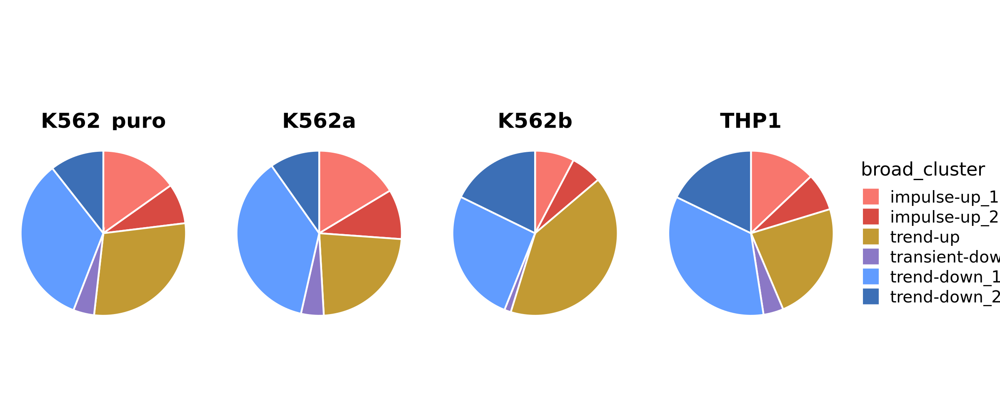

In [3153]:
pc_df_subset <- pc_df %>% rownames_to_column('rn') %>% 
                    # filter(abs(peak_log2fc) >= 0.5, qval_1 < 0.05, qval_1 != -1) %>% 
                    filter(abs(peak_log2fc) >= 0.5, pvalue_1 < 0.05) %>% 
                    dplyr::group_by(cell_type) %>% 
                    dplyr::ungroup() %>% as.data.frame() %>% column_to_rownames('rn')

options(repr.plot.width = 12, repr.plot.height = 5)

cluster_order <- c(
  "impulse-up_1",
  "impulse-up_2",
  "trend-up",
  "transient-down",
  "trend-down_1",
  "trend-down_2"
)

cluster_colors <- c(
  "impulse-up_1"   = "#F8766D",
  "impulse-up_2"   = "#D84A42",
  "trend-up"       = "#C29A33",
  "transient-down" = "#8B78C6",
  "trend-down_1"   = "#619CFF",
  "trend-down_2"   = "#3C6FB6"
)

pie_df <- pc_df_subset %>%
  mutate(
    broad_cluster = factor(broad_cluster, levels = cluster_order)
  ) %>%
  dplyr::count(cell_type, broad_cluster, .drop = FALSE) %>%
  group_by(cell_type) %>%
  mutate(prop = n / sum(n)) %>%
  ungroup()

p_pie <- ggplot(pie_df, aes(x = "", y = prop, fill = broad_cluster)) +
  geom_col(width = 1, color = "white") +
  coord_polar(theta = "y", direction = -1) +
  facet_wrap(~cell_type, nrow = 1) +
  theme_void(base_size = 16) +
  theme(
    strip.text = element_text(face = "bold", size = 18),
    plot.title = element_text(hjust = 0.5, size = 20),
    legend.title = element_text(size = 16),
    legend.text = element_text(size = 14)
  ) +
  labs(
    title = "",
    fill = "broad_cluster"
  ) +
  scale_fill_manual(
    breaks = cluster_order,
    drop = FALSE,
    values = cluster_colors
  )

p_pie

ggsave(
  "../../../notebooks/figures/7a_DynamicModeProportions.pdf",
  plot = p_pie,
  width = 12,
  height = 5,
  units = "in",
  device = cairo_pdf
)

In [3084]:
prop_ranges <- pie_df %>% filter(cell_type != 'K562_puro') %>%
  dplyr::group_by(broad_cluster) %>%
  dplyr::summarise(
    min_prop = min(prop, na.rm = TRUE),
    max_prop = max(prop, na.rm = TRUE),
    range = paste0(
      round(100 * min_prop, 1), "%-",
      round(100 * max_prop, 1), "%"
    ),
    .groups = "drop"
  )

prop_ranges

prop_ranges_grouped <- pie_df %>% filter(cell_type != 'K562_puro') %>%
  dplyr::mutate(
    broad_cluster_grouped = dplyr::case_when(
      broad_cluster %in% c("impulse-up_1", "impulse-up_2") ~ "impulse-up",
      broad_cluster %in% c("trend-down_1", "trend-down_2") ~ "trend-down",
      TRUE ~ as.character(broad_cluster)
    )
  ) %>%
  dplyr::group_by(cell_type, broad_cluster_grouped) %>%
  dplyr::summarise(
    prop = sum(prop),
    .groups = "drop"
  ) %>%
  dplyr::group_by(broad_cluster_grouped) %>%
  dplyr::summarise(
    min_prop = min(prop, na.rm = TRUE),
    min_cell_type = cell_type[which.min(prop)],
    max_prop = max(prop, na.rm = TRUE),
    max_cell_type = cell_type[which.max(prop)],
    range = paste0(
      round(100 * min_prop, 1), "%-",
      round(100 * max_prop, 1), "%"
    ),
    .groups = "drop"
  )

prop_ranges_grouped

broad_cluster,min_prop,max_prop,range
<fct>,<dbl>,<dbl>,<chr>
impulse-up_1,0.07700535,0.16370558,7.7%-16.4%
impulse-up_2,0.06096257,0.09771574,6.1%-9.8%
trend-up,0.22969543,0.40962567,23%-41%
transient-down,0.01283422,0.04441624,1.3%-4.4%
trend-down_1,0.26203209,0.36675127,26.2%-36.7%
trend-down_2,0.09771574,0.17799043,9.8%-17.8%


broad_cluster_grouped,min_prop,min_cell_type,max_prop,max_cell_type,range
<chr>,<dbl>,<chr>,<dbl>,<chr>,<chr>
impulse-up,0.13796791,K562b,0.26142132,K562a,13.8%-26.1%
transient-down,0.01283422,K562b,0.04441624,K562a,1.3%-4.4%
trend-down,0.43957219,K562b,0.52440191,THP1,44%-52.4%
trend-up,0.22969543,K562a,0.40962567,K562b,23%-41%


In [3170]:
prop_ranges <- pie_df %>% filter(cell_type %in% c('K562a', 'K562_puro')) %>%
  dplyr::group_by(broad_cluster) %>%
  dplyr::summarise(
    min_prop = min(prop, na.rm = TRUE),
    max_prop = max(prop, na.rm = TRUE),
    range = paste0(
      round(100 * min_prop, 1), "%-",
      round(100 * max_prop, 1), "%"
    ),
    .groups = "drop"
  )

prop_ranges

prop_ranges_grouped <- pie_df %>% filter(cell_type %in% c('K562a', 'K562_puro'))  %>%
  dplyr::mutate(
    broad_cluster_grouped = dplyr::case_when(
      broad_cluster %in% c("impulse-up_1", "impulse-up_2") ~ "impulse-up",
      broad_cluster %in% c("trend-down_1", "trend-down_2") ~ "trend-down",
      TRUE ~ as.character(broad_cluster)
    )
  ) %>%
  dplyr::group_by(cell_type, broad_cluster_grouped) %>%
  dplyr::summarise(
    prop = sum(prop),
    .groups = "drop"
  ) %>%
  dplyr::group_by(broad_cluster_grouped) %>%
  dplyr::summarise(
    min_prop = min(prop, na.rm = TRUE),
    min_cell_type = cell_type[which.min(prop)],
    max_prop = max(prop, na.rm = TRUE),
    max_cell_type = cell_type[which.max(prop)],
    range = paste0(
      round(100 * min_prop, 1), "%-",
      round(100 * max_prop, 1), "%"
    ),
    .groups = "drop"
  )

prop_ranges_grouped

broad_cluster,min_prop,max_prop,range
<fct>,<dbl>,<dbl>,<chr>
impulse-up_1,0.15169661,0.16370558,15.2%-16.4%
impulse-up_2,0.07884232,0.09771574,7.9%-9.8%
trend-up,0.22969543,0.28742515,23%-28.7%
transient-down,0.04091816,0.04441624,4.1%-4.4%
trend-down_1,0.33532934,0.36675127,33.5%-36.7%
trend-down_2,0.09771574,0.10578842,9.8%-10.6%


broad_cluster_grouped,min_prop,min_cell_type,max_prop,max_cell_type,range
<chr>,<dbl>,<chr>,<dbl>,<chr>,<chr>
impulse-up,0.23053892,K562_puro,0.26142132,K562a,23.1%-26.1%
transient-down,0.04091816,K562_puro,0.04441624,K562a,4.1%-4.4%
trend-down,0.44111776,K562_puro,0.46446701,K562a,44.1%-46.4%
trend-up,0.22969543,K562a,0.28742515,K562_puro,23%-28.7%


# A tibble: 2 x 3
  cell_type     n median
  <fct>     <int>  <dbl>
1 K562a       788 -0.506
2 K562_puro  1002  0.537
# A tibble: 2 x 3
  cell_type     n median
  <fct>     <int>  <dbl>
1 K562a       262  0.793
2 K562_puro   262  0.908

Unpaired Wilcoxon rank-sum p = 0.922 
Paired Wilcoxon signed-rank p = 0.974 
Number of paired genes = 262 


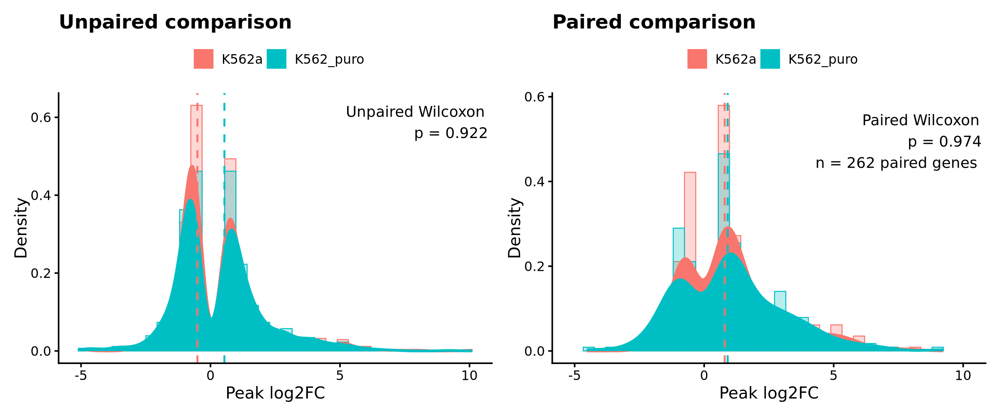

In [3165]:
library(dplyr)
library(tidyr)
library(ggplot2)
library(patchwork)

# ============================================================
# 1. UNPAIRED DATA
#    Use all available genes in each condition
# ============================================================

df_unpaired <- pc_df_subset %>%
  filter(cell_type %in% c("K562a", "K562_puro")) %>%
  select(gene, cell_type, peak_log2fc) %>%
  filter(!is.na(peak_log2fc)) %>%
  distinct() %>%
  mutate(
    cell_type = factor(
      cell_type,
      levels = c("K562a", "K562_puro")
    )
  )

unpaired_res <- wilcox.test(
  peak_log2fc ~ cell_type,
  data = df_unpaired,
  exact = FALSE
)

# ============================================================
# 2. PAIRED DATA
#    Restrict to genes measured in BOTH conditions
# ============================================================

df_wide <- pc_df_subset %>%
  filter(cell_type %in% c("K562a", "K562_puro")) %>%
  select(gene, cell_type, peak_log2fc) %>%
  filter(!is.na(peak_log2fc)) %>%
  distinct() %>%
  pivot_wider(
    names_from = cell_type,
    values_from = peak_log2fc
  ) %>%
  filter(!is.na(K562a), !is.na(K562_puro))

paired_res <- wilcox.test(
  df_wide$K562a,
  df_wide$K562_puro,
  paired = TRUE,
  exact = FALSE
)

df_paired <- df_wide %>%
  pivot_longer(
    cols = c(K562a, K562_puro),
    names_to = "cell_type",
    values_to = "peak_log2fc"
  ) %>%
  mutate(
    cell_type = factor(
      cell_type,
      levels = c("K562a", "K562_puro")
    )
  )

# ============================================================
# 3. Summary statistics
# ============================================================

unpaired_summary <- df_unpaired %>%
  group_by(cell_type) %>%
  summarise(
    n = n(),
    median = median(peak_log2fc),
    .groups = "drop"
  )

paired_summary <- df_paired %>%
  group_by(cell_type) %>%
  summarise(
    n = n(),
    median = median(peak_log2fc),
    .groups = "drop"
  )

print(unpaired_summary)
print(paired_summary)

cat(
  "\nUnpaired Wilcoxon rank-sum p =",
  format.pval(unpaired_res$p.value, digits = 3),
  "\n"
)

cat(
  "Paired Wilcoxon signed-rank p =",
  format.pval(paired_res$p.value, digits = 3),
  "\n"
)

cat(
  "Number of paired genes =", nrow(df_wide),
  "\n"
)

# ============================================================
# 4. Common histogram settings
# ============================================================

all_x <- c(
  df_unpaired$peak_log2fc,
  df_paired$peak_log2fc
)

xrange <- range(all_x, na.rm = TRUE)

# Use identical bins in both panels
binwidth <- diff(xrange) / 35

# ============================================================
# 5. UNPAIRED histogram overlay
# ============================================================

p_unpaired <- ggplot(
  df_unpaired,
  aes(
    x = peak_log2fc,
    fill = cell_type,
    color = cell_type
  )
) +
  geom_histogram(
    aes(y = after_stat(density)),
    position = "identity",
    binwidth = binwidth,
    boundary = xrange[1],
    alpha = 0.28,
    linewidth = 0.4
  ) +
  geom_density(
    linewidth = 1.1,
    adjust = 1
  ) +
  geom_vline(
    data = unpaired_summary,
    aes(
      xintercept = median,
      color = cell_type
    ),
    linetype = "dashed",
    linewidth = 0.8,
    show.legend = FALSE
  ) +
  annotate(
    "text",
    x = Inf,
    y = Inf,
    hjust = 1.05,
    vjust = 1.4,
    label = paste0(
      "Unpaired Wilcoxon\np = ",
      format.pval(unpaired_res$p.value, digits = 3)
    ),
    size = 4.5
  ) +
  coord_cartesian(xlim = xrange) +
  labs(
    title = "Unpaired comparison",
    x = "Peak log2FC",
    y = "Density",
    fill = NULL,
    color = NULL
  ) +
  theme_classic(base_size = 14) +
  theme(
    plot.title = element_text(face = "bold"),
    legend.position = "top"
  )

# ============================================================
# 6. PAIRED histogram overlay
#    Same genes in both conditions
# ============================================================

p_paired <- ggplot(
  df_paired,
  aes(
    x = peak_log2fc,
    fill = cell_type,
    color = cell_type
  )
) +
  geom_histogram(
    aes(y = after_stat(density)),
    position = "identity",
    binwidth = binwidth,
    boundary = xrange[1],
    alpha = 0.28,
    linewidth = 0.4
  ) +
  geom_density(
    linewidth = 1.1,
    adjust = 1
  ) +
  geom_vline(
    data = paired_summary,
    aes(
      xintercept = median,
      color = cell_type
    ),
    linetype = "dashed",
    linewidth = 0.8,
    show.legend = FALSE
  ) +
  annotate(
    "text",
    x = Inf,
    y = Inf,
    hjust = 1.05,
    vjust = 1.4,
    label = paste0(
      "Paired Wilcoxon\np = ",
      format.pval(paired_res$p.value, digits = 3),
      "\nn = ",
      nrow(df_wide),
      " paired genes"
    ),
    size = 4.5
  ) +
  coord_cartesian(xlim = xrange) +
  labs(
    title = "Paired comparison",
    x = "Peak log2FC",
    y = "Density",
    fill = NULL,
    color = NULL
  ) +
  theme_classic(base_size = 14) +
  theme(
    plot.title = element_text(face = "bold"),
    legend.position = "top"
  )

# ============================================================
# 7. Display together
# ============================================================

p_unpaired + p_paired


================ UNPAIRED ================
# A tibble: 6 x 6
  broad_cluster  n_K562a n_K562_puro median_K562a median_K562_puro  p_value
  <fct>            <int>       <int>        <dbl>            <dbl>    <dbl>
1 impulse-up_1       129         152        1.10             1.18  0.486   
2 impulse-up_2        77          79        0.951            0.931 0.595   
3 transient-down      35          41       -0.857           -0.908 0.404   
4 trend-down_1       289         336       -0.764           -0.880 0.000170
5 trend-down_2        77         106       -0.636           -0.712 0.00686 
6 trend-up           181         288        0.923            1.09  0.0261  

================ PAIRED ==================
# A tibble: 6 x 5
  broad_cluster      n median_K562a median_K562_puro p_value
  <fct>          <int>        <dbl>            <dbl>   <dbl>
1 impulse-up_1      76        1.56             1.60  0.834  
2 impulse-up_2      26        0.976            0.957 0.859  
3 transient-down     1  

Warning message:
"Groups with fewer than two data points have been dropped."
Warning message:
"Groups with fewer than two data points have been dropped."
Warning message:
"Removed 2 rows containing missing values or values outside the scale range
(`geom_density()`)."


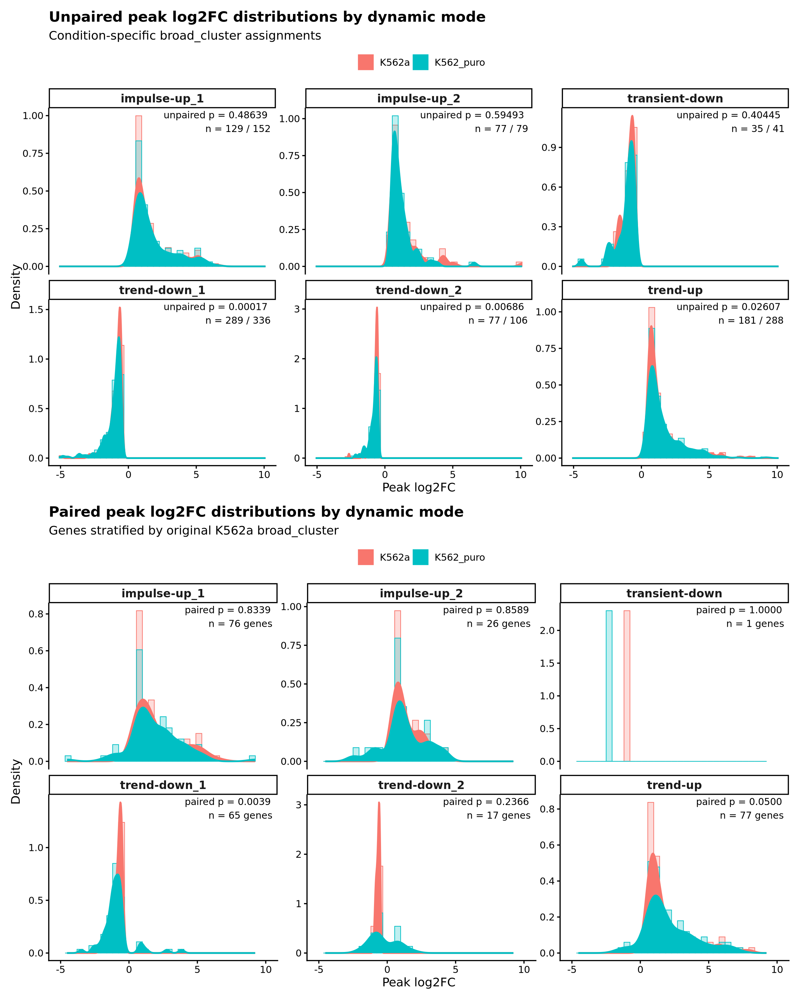

In [3167]:
library(dplyr)
library(tidyr)
library(ggplot2)
library(patchwork)

# ============================================================
# CONFIG
# ============================================================

cell_types <- c("K562a", "K562_puro")

# Use original K562a mode to define strata for paired comparisons
pair_cluster_source <- "K562a"

# ============================================================
# 1. Prepare base data
# ============================================================

df_base <- pc_df_subset %>%
  filter(cell_type %in% cell_types) %>%
  select(gene, cell_type, peak_log2fc, broad_cluster) %>%
  filter(
    !is.na(peak_log2fc),
    !is.na(broad_cluster)
  ) %>%
  distinct() %>%
  mutate(
    cell_type = factor(cell_type, levels = cell_types),
    broad_cluster = as.character(broad_cluster)
  )

# Preserve sensible cluster order
if (is.factor(pc_df_subset$broad_cluster)) {
  cluster_levels <- levels(pc_df_subset$broad_cluster)
  cluster_levels <- cluster_levels[
    cluster_levels %in% unique(df_base$broad_cluster)
  ]
} else {
  cluster_levels <- unique(
    df_base %>%
      filter(cell_type == "K562a") %>%
      pull(broad_cluster)
  )
}

# Add any modes present only in puromycin
cluster_levels <- c(
  cluster_levels,
  setdiff(unique(df_base$broad_cluster), cluster_levels)
)

df_base <- df_base %>%
  mutate(
    broad_cluster = factor(
      broad_cluster,
      levels = cluster_levels
    )
  )

# ============================================================
# 2. UNPAIRED comparison within each condition-specific mode
# ============================================================

df_unpaired <- df_base

unpaired_stats <- df_unpaired %>%
  group_by(broad_cluster) %>%
  group_modify(~{
    
    x <- .x$peak_log2fc[.x$cell_type == "K562a"]
    y <- .x$peak_log2fc[.x$cell_type == "K562_puro"]
    
    x <- x[is.finite(x)]
    y <- y[is.finite(y)]
    
    p <- if (length(x) > 0 && length(y) > 0) {
      wilcox.test(
        x, y,
        paired = FALSE,
        exact = FALSE
      )$p.value
    } else {
      NA_real_
    }
    
    tibble(
      n_K562a = length(x),
      n_K562_puro = length(y),
      median_K562a = if (length(x)) median(x) else NA_real_,
      median_K562_puro = if (length(y)) median(y) else NA_real_,
      p_value = p
    )
  }) %>%
  ungroup() %>%
  mutate(
    label = paste0(
      "unpaired p = ",
      format.pval(p_value, digits = 2, eps = 1e-4),
      "\n",
      "n = ", n_K562a, " / ", n_K562_puro
    )
  )

# ============================================================
# 3. PAIRED comparison
#    Define mode using ORIGINAL K562a broad_cluster
# ============================================================

cluster_ref <- df_base %>%
  filter(cell_type == pair_cluster_source) %>%
  select(
    gene,
    broad_cluster_ref = broad_cluster
  ) %>%
  distinct()

df_wide_paired <- df_base %>%
  select(gene, cell_type, peak_log2fc) %>%
  pivot_wider(
    names_from = cell_type,
    values_from = peak_log2fc
  ) %>%
  filter(
    !is.na(K562a),
    !is.na(K562_puro)
  ) %>%
  inner_join(cluster_ref, by = "gene") %>%
  mutate(
    broad_cluster = factor(
      broad_cluster_ref,
      levels = cluster_levels
    )
  )

paired_stats <- df_wide_paired %>%
  group_by(broad_cluster) %>%
  summarise(
    n = n(),
    
    median_K562a = median(K562a, na.rm = TRUE),
    median_K562_puro = median(K562_puro, na.rm = TRUE),
    
    p_value = if (n() > 0) {
      wilcox.test(
        K562a,
        K562_puro,
        paired = TRUE,
        exact = FALSE
      )$p.value
    } else {
      NA_real_
    },
    
    .groups = "drop"
  ) %>%
  mutate(
    label = paste0(
      "paired p = ",
      format.pval(p_value, digits = 2, eps = 1e-4),
      "\n",
      "n = ", n, " genes"
    )
  )

df_paired <- df_wide_paired %>%
  select(
    gene,
    broad_cluster,
    K562a,
    K562_puro
  ) %>%
  pivot_longer(
    cols = c(K562a, K562_puro),
    names_to = "cell_type",
    values_to = "peak_log2fc"
  ) %>%
  mutate(
    cell_type = factor(
      cell_type,
      levels = cell_types
    )
  )

# ============================================================
# 4. Print statistics
# ============================================================

cat("\n================ UNPAIRED ================\n")
print(
  unpaired_stats %>%
    select(
      broad_cluster,
      n_K562a,
      n_K562_puro,
      median_K562a,
      median_K562_puro,
      p_value
    )
)

cat("\n================ PAIRED ==================\n")
print(
  paired_stats %>%
    select(
      broad_cluster,
      n,
      median_K562a,
      median_K562_puro,
      p_value
    )
)

# ============================================================
# 5. Common histogram binning
# ============================================================

all_vals <- df_base$peak_log2fc
xr <- range(all_vals, na.rm = TRUE)

binwidth <- diff(xr) / 35

# ============================================================
# 6. UNPAIRED histogram overlays by broad_cluster
# ============================================================

p_unpaired_modes <- ggplot(
  df_unpaired,
  aes(
    x = peak_log2fc,
    fill = cell_type,
    color = cell_type
  )
) +
  geom_histogram(
    aes(y = after_stat(density)),
    position = "identity",
    binwidth = binwidth,
    boundary = xr[1],
    alpha = 0.25,
    linewidth = 0.35
  ) +
  geom_density(
    linewidth = 0.9,
    adjust = 1
  ) +
  geom_text(
    data = unpaired_stats,
    aes(
      x = Inf,
      y = Inf,
      label = label
    ),
    inherit.aes = FALSE,
    hjust = 1.08,
    vjust = 1.15,
    size = 3.6
  ) +
  facet_wrap(
    ~ broad_cluster,
    scales = "free_y"
  ) +
  coord_cartesian(xlim = xr) +
  labs(
    title = "Unpaired peak log2FC distributions by dynamic mode",
    subtitle = "Condition-specific broad_cluster assignments",
    x = "Peak log2FC",
    y = "Density",
    fill = NULL,
    color = NULL
  ) +
  theme_classic(base_size = 13) +
  theme(
    strip.text = element_text(
      face = "bold",
      size = 12
    ),
    plot.title = element_text(face = "bold"),
    legend.position = "top"
  )

# ============================================================
# 7. PAIRED histogram overlays by ORIGINAL K562a mode
# ============================================================

p_paired_modes <- ggplot(
  df_paired,
  aes(
    x = peak_log2fc,
    fill = cell_type,
    color = cell_type
  )
) +
  geom_histogram(
    aes(y = after_stat(density)),
    position = "identity",
    binwidth = binwidth,
    boundary = xr[1],
    alpha = 0.25,
    linewidth = 0.35
  ) +
  geom_density(
    linewidth = 0.9,
    adjust = 1
  ) +
  geom_text(
    data = paired_stats,
    aes(
      x = Inf,
      y = Inf,
      label = label
    ),
    inherit.aes = FALSE,
    hjust = 1.08,
    vjust = 1.15,
    size = 3.6
  ) +
  facet_wrap(
    ~ broad_cluster,
    scales = "free_y"
  ) +
  coord_cartesian(xlim = xr) +
  labs(
    title = "Paired peak log2FC distributions by dynamic mode",
    subtitle = "Genes stratified by original K562a broad_cluster",
    x = "Peak log2FC",
    y = "Density",
    fill = NULL,
    color = NULL
  ) +
  theme_classic(base_size = 13) +
  theme(
    strip.text = element_text(
      face = "bold",
      size = 12
    ),
    plot.title = element_text(face = "bold"),
    legend.position = "top"
  )

# ============================================================
# 8. Display
# ============================================================

options(repr.plot.width = 12, repr.plot.height = 15)

p_unpaired_modes / p_paired_modes

In [3168]:
paired_stats <- df_wide_paired %>%
  group_by(broad_cluster) %>%
  summarise(
    n = n(),

    median_K562a = median(K562a, na.rm = TRUE),
    median_K562_puro = median(K562_puro, na.rm = TRUE),

    median_delta = median(
      K562_puro - K562a,
      na.rm = TRUE
    ),

    p_value = if (n() >= 3) {
      wilcox.test(
        K562a,
        K562_puro,
        paired = TRUE,
        exact = FALSE
      )$p.value
    } else {
      NA_real_
    },

    .groups = "drop"
  )

paired_stats

broad_cluster,n,median_K562a,median_K562_puro,median_delta,p_value
<fct>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
impulse-up_1,76,1.5588227,1.5985703,0.03556715,0.833915265
impulse-up_2,26,0.9755237,0.9568953,0.03397214,0.858891168
transient-down,1,-1.0378463,-2.4652253,-1.42737899,NA
trend-down_1,65,-0.7393229,-0.9296398,-0.21134526,0.003871559
trend-down_2,17,-0.6339998,-0.6635849,0.10349170,0.236629793
trend-up,77,1.2159790,1.4055307,0.17320554,0.050007216


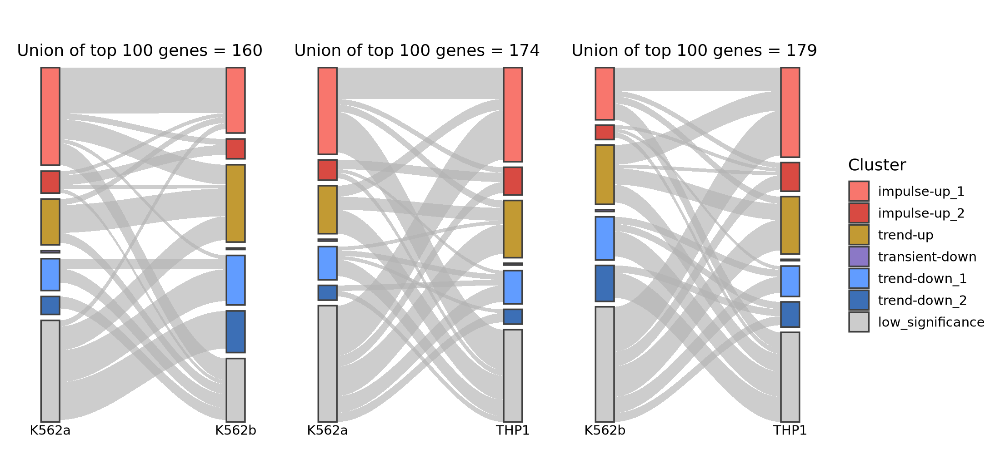

In [3086]:
clusters_use <- c("impulse-up_1", "impulse-up_2", "trend-up", "transient-down", "trend-down_1", "trend-down_2", "low_significance")

cluster_palette <- list("impulse-up_1" = "#F8766D", "impulse-up_2" = "#D84A42", "trend-up" = "#C29A33", "transient-down" = "#8B78C6",
                        "trend-down_1" = "#619CFF", "trend-down_2" = "#3C6FB6", "low_significance" = "#D1D1D1")

K = 100

p1 <- (plot_cluster_reassignment_sankey(
  pc_df = pc_df_subset, top_k = K,
  source_cell_type = "K562a", target_cell_type = "K562b",
  treat_missing_as_low_significance = TRUE, low_significance_action = "show",
  cluster_col = "broad_cluster", gene_col = "gene", rank_col = "waldStat_1",
  clusters_use = clusters_use,
  min_flow = 2, stratum_gap = 3, stratum_width = 0.10,
  cluster_palette = cluster_palette,
  show_legend = FALSE
))$plot + ggtitle("")

p2 <- (plot_cluster_reassignment_sankey(
  pc_df = pc_df_subset, top_k = K,
  source_cell_type = "K562a", target_cell_type = "THP1",
  treat_missing_as_low_significance = TRUE, low_significance_action = "show",
  cluster_col = "broad_cluster", gene_col = "gene", rank_col = "waldStat_1",
  clusters_use = clusters_use,
  min_flow = 2, stratum_gap = 3, stratum_width = 0.10,
  cluster_palette = cluster_palette,
  show_legend = FALSE
))$plot + ggtitle("")

p3 <- (plot_cluster_reassignment_sankey(
  pc_df = pc_df_subset, top_k = K,
  source_cell_type = "K562b", target_cell_type = "THP1",
  treat_missing_as_low_significance = TRUE, low_significance_action = "show",
  cluster_col = "broad_cluster", gene_col = "gene", rank_col = "waldStat_1",
  clusters_use = clusters_use,
  min_flow = 2, stratum_gap = 3, stratum_width = 0.10,
  cluster_palette = cluster_palette,
  show_legend = TRUE
))$plot + ggtitle("")

options(repr.plot.width = 11, repr.plot.height = 5)
p_all <- p1 + p2 + p3
p_all

ggsave(
  filename = "../../../notebooks/figures/S7a_ClusterReassignmentSankeys.pdf",
  plot = p_all,
  width = 11,
  height = 5,
  units = "in",
  device = cairo_pdf
)

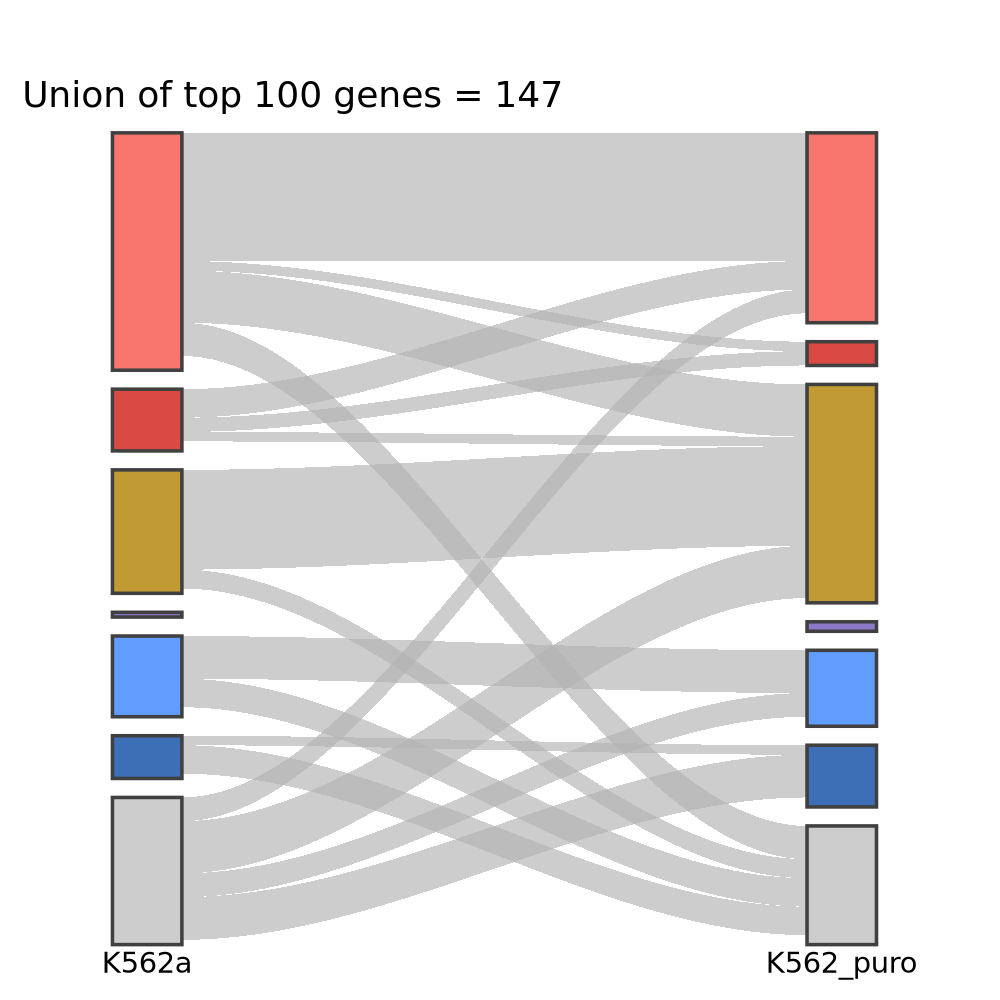

In [3067]:
p1 <- (plot_cluster_reassignment_sankey(
  pc_df = pc_df_subset %>% filter(qval_1 < 0.05), top_k = 100,
  source_cell_type = "K562a", target_cell_type = "K562_puro",
  treat_missing_as_low_significance = TRUE, low_significance_action = "show",
  cluster_col = "broad_cluster", gene_col = "gene", rank_col = "waldStat_1",
  clusters_use = clusters_use,
  min_flow = 2, stratum_gap = 4, stratum_width = 0.10,
  cluster_palette = cluster_palette,
  show_legend = FALSE
))$plot + ggtitle("")

options(repr.plot.width = 5, repr.plot.height = 5)
p1

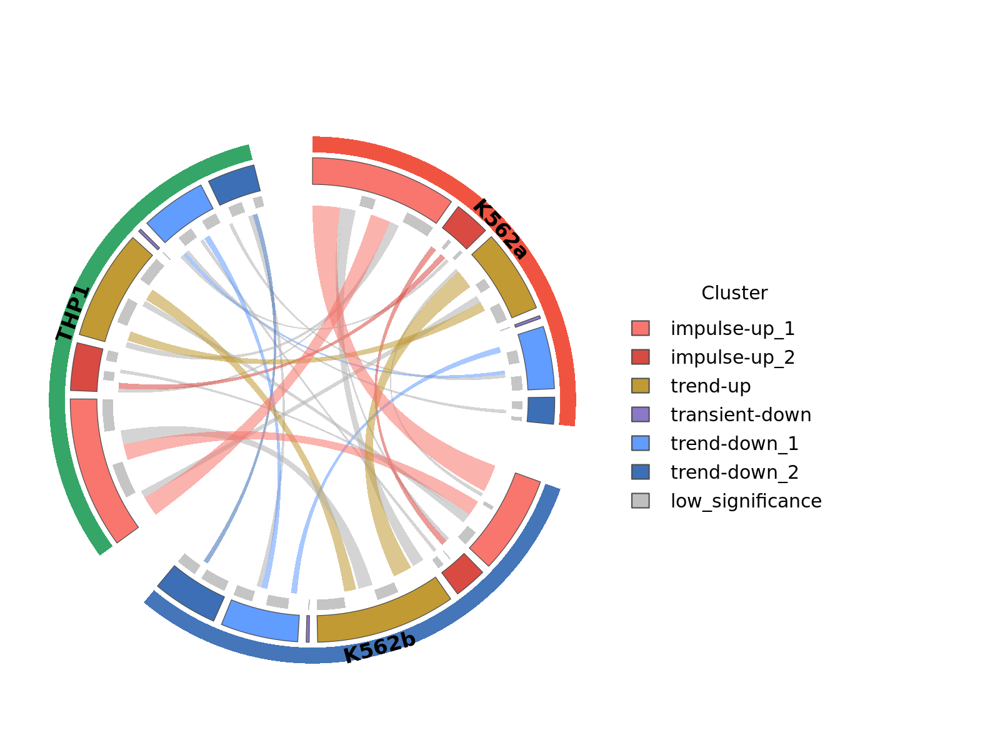

In [3088]:
options(repr.plot.width = 8, repr.plot.height = 6)

# pdf(
#   file = "../../../notebooks/figures/7a_ClusterReassignmentChord.pdf",
#   width = 8,
#   height = 6,
#   bg = "white"
# )

res <- plot_cluster_reassignment_chord_pairwise(
  pc_df = pc_df_subset,
  compare_cell_types = c("K562a", "K562b", "THP1"),
  # compare_cell_types = c("K562a", "K562b"),
  cell_type_palette = c(
    K562b = "#3b6fb6",
    K562a = "#f04b37",
    THP1  = "#2ca25f"
  ),
  treat_missing_as_low_significance = TRUE,
  celltype_track_height = 0.06,
  cluster_col = "broad_cluster",
  rank_col = "waldStat_1",
  top_k = 100,
  min_flow = 3,
  legend_inset = c(-0.45, 0),
  topk_set_mode = "union",
  clusters_use = clusters_use,
  cluster_palette = cluster_palette,
  show_low_significance = FALSE,
  hidden_low_significance_mode = "bar",
  hidden_bar_col = "grey75",
  hidden_bar_track_height = 0.04,
  return_data = TRUE
)

# dev.off()

In [3136]:
pc_df <- pc_df %>%
  mutate(
    response_direction = case_when(
      broad_cluster %in% c(
        "impulse-up_1",
        "impulse-up_2",
        "trend-up"
      ) ~ "induced",

      broad_cluster %in% c(
        "trend-down_1",
        "trend-down_2",
        "transient-down"
      ) ~ "repressed",

      TRUE ~ NA_character_
    )
  )


In [3137]:
calc_topk_mode_recovery <- function(
  pc_df,
  source,
  target,
  mode,
  mode_col = "broad_cluster",
  k = 100,
  q_cut = 0.05,
  rank_col = "waldStat_1",
  q_col = "qval_1",
  gene_col = "gene"
) {

  src <- pc_df %>%
    dplyr::filter(
      .data$cell_type == source,
      .data[[mode_col]] == mode,
      .data[[q_col]] < q_cut
    ) %>%
    dplyr::arrange(
      dplyr::desc(.data[[rank_col]])
    ) %>%
    dplyr::slice_head(n = k)

  tgt <- pc_df %>%
    dplyr::filter(
      .data$cell_type == target,
      .data[[mode_col]] == mode,
      .data[[q_col]] < q_cut
    )

  mean(
    src[[gene_col]] %in% tgt[[gene_col]]
  )
}

In [3149]:
calc_topk_mode_recovery(
  pc_df %>% filter(pvalue_1 < 0.05, abs(peak_log2fc) > 0.5),
  source = "K562a",
  target = "K562b",
  mode = "repressed",
  mode_col = "response_direction",
  k = 100
)

calc_topk_mode_recovery(
  pc_df,
  source = "K562a",
  target = "THP1",
  mode = "repressed",
  mode_col = "response_direction",
  k = 100
)

calc_topk_mode_recovery(
  pc_df,
  source = "THP1",
  target = "K562b",
  mode = "repressed",
  mode_col = "response_direction",
  k = 100
)

[1] 0.11

[1] 0.14

[1] 0.22

In [3150]:
calc_topk_mode_recovery(
  pc_df %>% filter(pvalue_1 < 0.05, abs(peak_log2fc) > 0.5),
  source = "K562a",
  target = "K562b",
  mode = "induced",
  mode_col = "response_direction",
  k = 100
)

calc_topk_mode_recovery(
  pc_df,
  source = "K562a",
  target = "THP1",
  mode = "induced",
  mode_col = "response_direction",
  k = 100
)

calc_topk_mode_recovery(
  pc_df,
  source = "THP1",
  target = "K562b",
  mode = "induced",
  mode_col = "response_direction",
  k = 100
)

[1] 0.6

[1] 0.35

[1] 0.32

[1] "NFKBIA_K562_puro" "NFKBIA_K562a"     "NFKBIA_K562b"     "NFKBIA_THP1"     


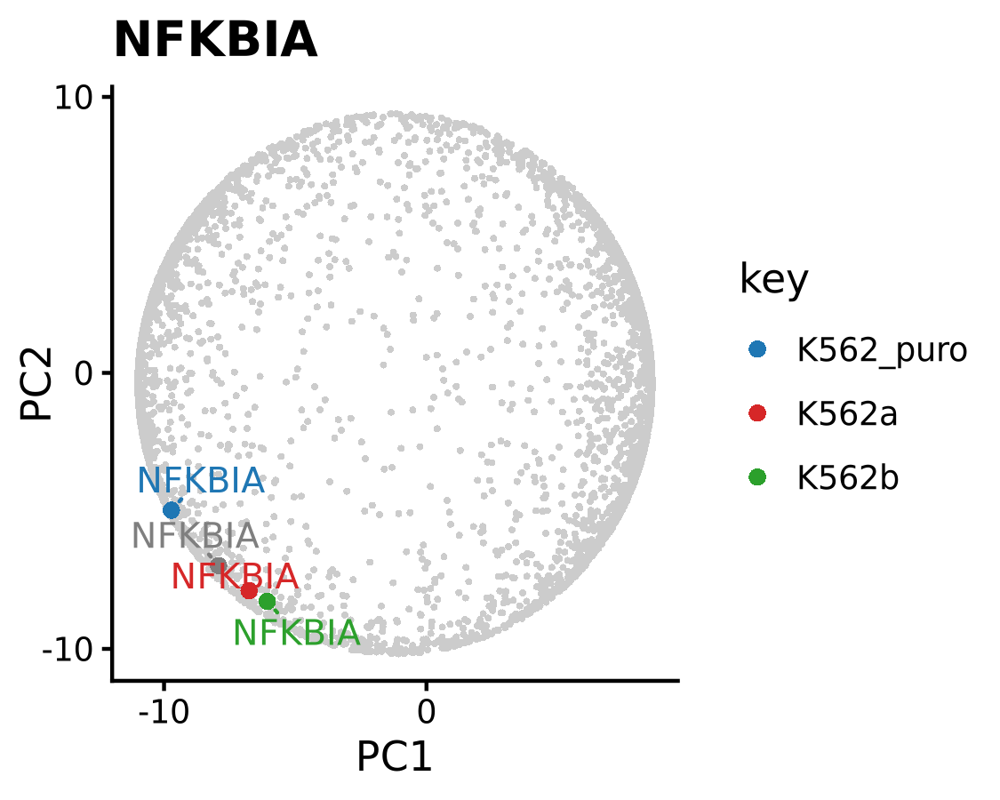

In [2773]:
query_gene = 'NFKBIA'

res1 = PlotGeneKeyHighlight(query_gene, pc_df, width = 3.75, height = 3)

In [2774]:
options(repr.plot.width = 8, repr.plot.height = 6)

pdf(
  file = "../../../notebooks/figures/7a_ClusterReassignmentChord.pdf",
  width = 8,
  height = 6,
  bg = "white"
)

res <- plot_cluster_reassignment_chord_pairwise(
  pc_df = pc_df_subset,
  compare_cell_types = c("K562a", "K562b", "THP1"),
  # compare_cell_types = c("K562a", "K562b"),
  cell_type_palette = c(
    K562b = "#3b6fb6",
    K562a = "#f04b37",
    THP1  = "#2ca25f"
  ),
  treat_missing_as_low_significance = TRUE,
  celltype_track_height = 0.06,
  cluster_col = "broad_cluster",
  rank_col = "waldStat_1",
  top_k = 100,
  min_flow = 3,
  legend_inset = c(-0.45, 0),
  topk_set_mode = "union",
  clusters_use = clusters_use,
  cluster_palette = cluster_palette,
  show_low_significance = FALSE,
  hidden_low_significance_mode = "bar",
  hidden_bar_col = "grey75",
  hidden_bar_track_height = 0.04,
  return_data = TRUE
)

dev.off()

pdf 
  2

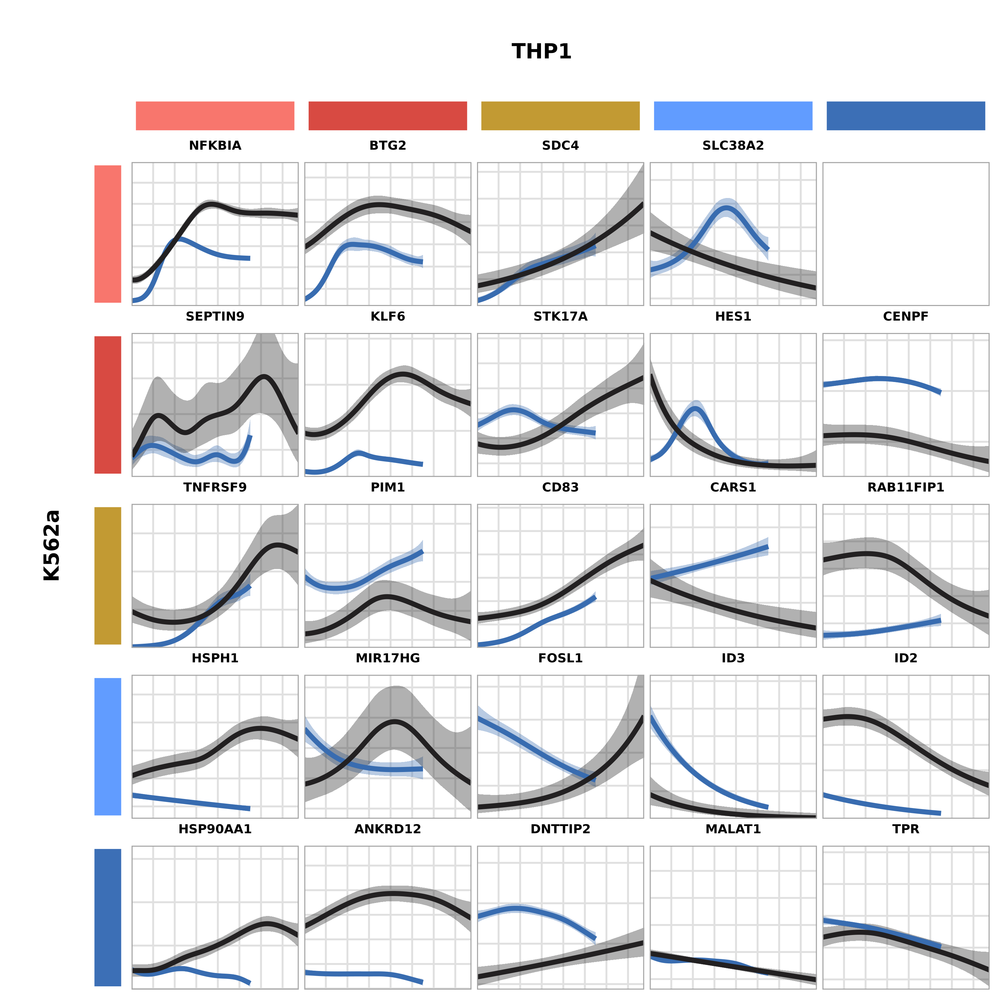

In [2775]:
options(repr.plot.width = 10, repr.plot.height = 10)

res_conf <- plot_cluster_pair_representative_genes(
  pc_df = pc_df,
  cluster_list = setdiff(clusters_use, c('transient-down', 'low_significance')),
  row_cell_type = "K562a",
  col_cell_type = "THP1",
  cluster_col = "broad_cluster",
  gamList_ls = gamList.ls,
  sce_ls = sce.ls,
  counts_sub_ls = counts_sub.ls,
  PT_ls = PT.ls,
  sf_ls = sf.ls,
  CW_ls = CW.ls,
  colours = c(THP1 = "#222021", K562a = "#386cb0"),
  qval_cut = 1,
  time_max_map = time_map,
  offset_map = offset_map,
  hide_subplot_axes = TRUE,
  hide_mean_fit_points = TRUE,
  omit_points = TRUE,
  trim_before_zero = TRUE,
  print_gene_table = FALSE,
  cluster_palette = unlist(cluster_palette),

  exclude_genes = c('LAMTOR2', 'SEPTIN9', 'AP1S1', 'CORO1C', 'CTSZ', 'LBR', 'ZFP69B'),

    
  top_annotation_box_rel_size = 0.20,    
)

ggsave(
  "../../../notebooks/figures/7b_ReassignedGenes.pdf",
  plot = res_conf$plot,
  width = 5,
  height = 5,
  units = "in",
  dpi = 300,
  bg = "white"
)

In [3176]:
pc_df_subset <- pc_df_subset %>%
  dplyr::mutate(
    broad_cluster2 = dplyr::case_when(
      broad_cluster %in% c("impulse-up_1", "impulse-up_2") ~ "impulse-up",
      broad_cluster %in% c("trend-down_1", "trend-down_2") ~ "trend-down",
      TRUE ~ broad_cluster
    )
  )

table(pc_df_subset$broad_cluster2)


    impulse-up transient-down     trend-down       trend-up 
           778            129           1767           1096 

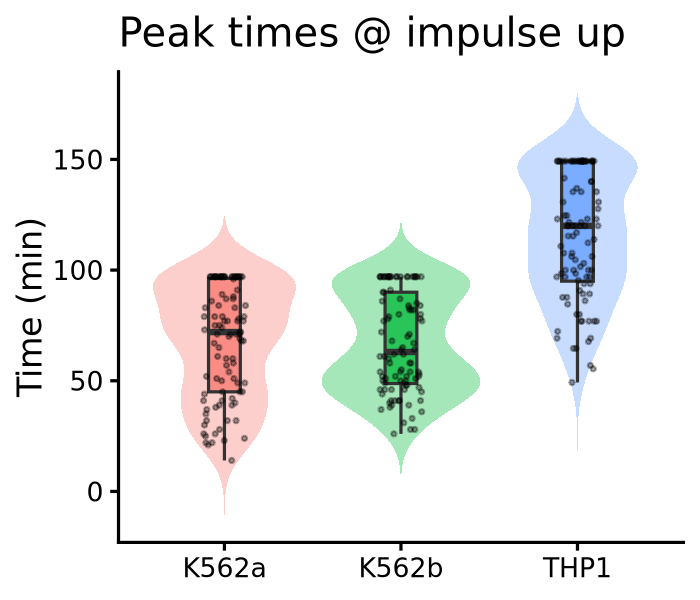

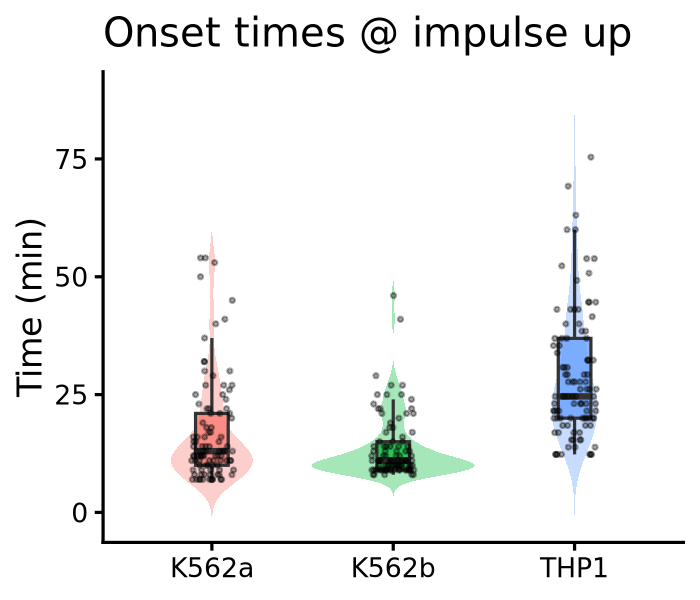

In [3179]:
library(patchwork)

p1 <- plot_cluster_violin(
  y_title = 'Time (min)',
  plot_title = 'Peak times @ impulse up',
  plot_width = 3.5, plot_height = 3,
  print_summary = FALSE, print_top_genes = FALSE,
  pc_df_subset, feature = 't_peak',
  keys_use = c("K562a", "K562b", "THP1"),
  cluster_col = 'broad_cluster2',
  compare_mode = "across_keys_for_cluster",
  cluster_use = 'impulse-up',
  use_top_k = TRUE, top_k = 100, topk_mode = "per_key",
  trim_percentiles = TRUE, trim_lower = 0, trim_upper = 1
)

p2 <- plot_cluster_violin(
  y_title = 'Time (min)',
  plot_title = 'Onset times @ impulse up',
  plot_width = 3.5, plot_height = 3,
  print_summary = FALSE, print_top_genes = FALSE,
  pc_df_subset, feature = 't_onset',
  keys_use = c("K562a", "K562b", "THP1"),
  cluster_col = 'broad_cluster2',
  compare_mode = "across_keys_for_cluster",
  cluster_use = 'impulse-up',
  use_top_k = TRUE, top_k = 100, topk_mode = "per_key",
  trim_percentiles = TRUE, trim_lower = 0, trim_upper = 1
)

fig <- p1$plot + p2$plot

ggsave(
  "../../../notebooks/figures/7c_ImpulseUp1-PeakOnsetTimes.pdf",
  plot = fig,
  width = 3.5,
  height = 6.5,
  units = "in"
)

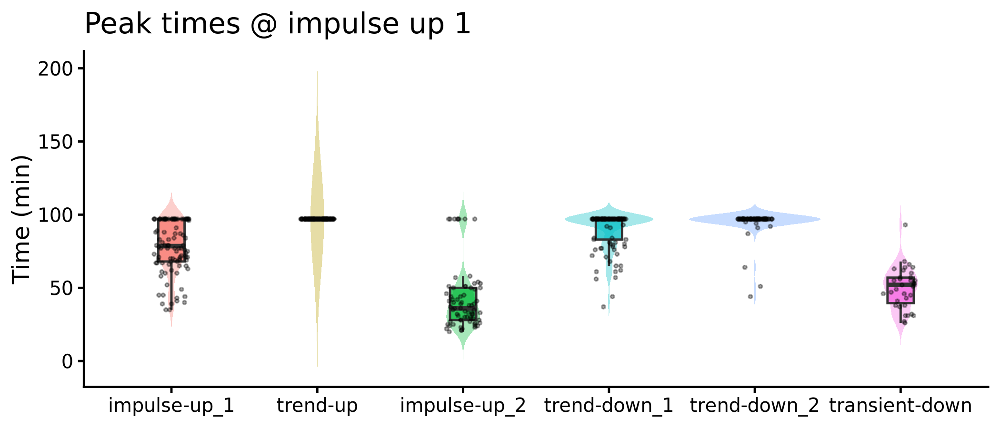

In [2912]:
p1 <- plot_cluster_violin(
  y_title = 'Time (min)',
  plot_title = 'Peak times @ impulse up 1',
  plot_width = 7, plot_height = 3,
  print_summary = FALSE, print_top_genes = FALSE,
  pc_df_subset, feature = 't_peak',
  keys_use = c("K562a", "K562b", "THP1"),
  cluster_col = 'broad_cluster',
  compare_mode = "across_clusters_for_key",
  key_use = 'K562a',
  use_top_k = TRUE, top_k = 100, topk_mode = "per_key",
  trim_percentiles = TRUE, trim_lower = 0.01, trim_upper = 0.99
)

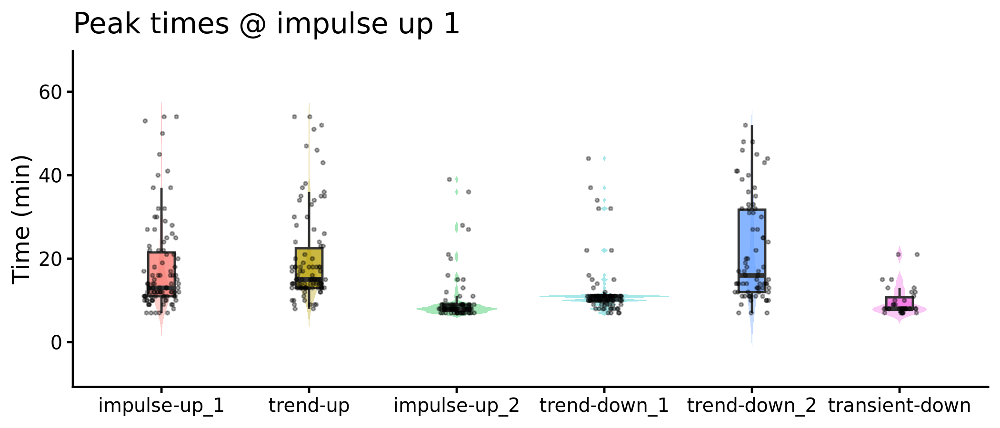

In [2908]:
p1 <- plot_cluster_violin(
  y_title = 'Time (min)',
  plot_title = 'Peak times @ impulse up 1',
  plot_width = 7, plot_height = 3,
  print_summary = FALSE, print_top_genes = FALSE,
  pc_df_subset, feature = 't_onset',
  keys_use = c("K562a", "K562b", "THP1"),
  cluster_col = 'broad_cluster',
  compare_mode = "across_clusters_for_key",
  key_use = 'K562a',
  use_top_k = TRUE, top_k = 100, topk_mode = "per_key",
  trim_percentiles = TRUE, trim_lower = 0.01, trim_upper = 0.99
)

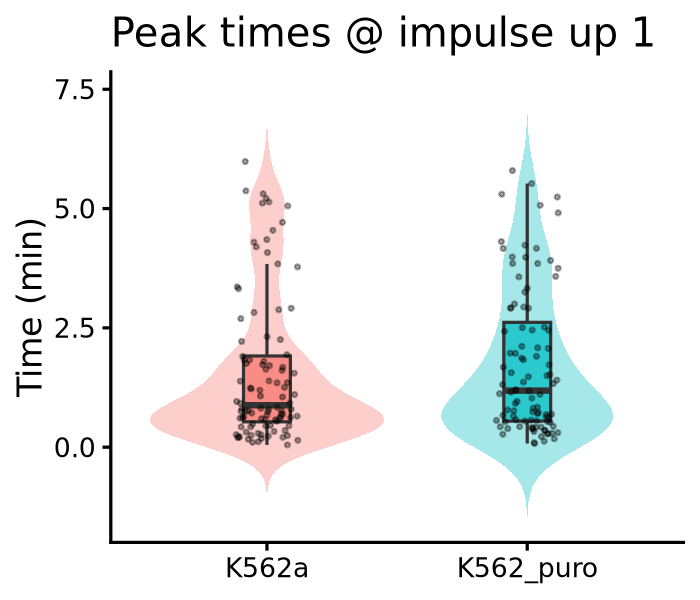

In [3011]:
p1 <- plot_cluster_violin(
  y_title = 'Time (min)',
  plot_title = 'Peak times @ impulse up 1',
  plot_width = 3.5, plot_height = 3,
  print_summary = FALSE, print_top_genes = FALSE,
  pc_df, feature = 'peak_log2fc',
  keys_use = c("K562a", "K562_puro"),
  cluster_col = 'broad_cluster',
  compare_mode = "across_keys_for_cluster",
  cluster_use = 'impulse-up_1',
  use_top_k = TRUE, top_k = 100, topk_mode = "per_key",
  trim_percentiles = TRUE, trim_lower = 0, trim_upper = 1
)

In [2816]:
sapply(tmp$plot_df, class)
sapply(tmp$plot_df, is.list)

row_id            tp         value      gene_sym           key 
  "character"   "character"     "numeric"   "character"   "character" 
requested_idx         label broad_cluster  colour_group  is_highlight 
    "integer"   "character"   "character"   "character"     "logical" 
   line_alpha   label_alpha        tp_idx             t             y 
    "numeric"     "numeric"     "integer"     "numeric"     "numeric"

row_id            tp         value      gene_sym           key 
        FALSE         FALSE         FALSE         FALSE         FALSE 
requested_idx         label broad_cluster  colour_group  is_highlight 
        FALSE         FALSE         FALSE         FALSE         FALSE 
   line_alpha   label_alpha        tp_idx             t             y 
        FALSE         FALSE         FALSE         FALSE         FALSE

In [2913]:
k562a = pc_df %>% filter(cell_type == 'K562a')
cluster_palette <- unlist(cluster_palette, use.names = TRUE)

p1 = feature_plot_pc_simple(k562a, feature = "t_onset", palette = "viridis", title = "Onset time",
                            floor = 0, cap = 100, alpha_col = NULL, plot_order = 'plot_highest_last', 
                            show_legend = TRUE, show_ticks = FALSE, 
                            show_genes = c('ZFP36', 'IRF1', 'IFNGR2', 'ZFP36L2'),
                            cat_colors = cluster_palette,
                            gene_label_style = "box",
                            gene_label_size = 12)


p2 = feature_plot_pc_simple(k562a, feature = "t_peak", palette = "viridis", title = "Peak time", 
                            floor = 0, cap = NULL, alpha_col = NULL, plot_order = 'plot_highest_last', 
                            show_legend = TRUE, show_ticks = FALSE, 
                            show_genes = c('ICAM1', 'IL32', 'NFKBIA', 'SCAF11'),
                            cat_colors = cluster_palette,
                            gene_label_style = "box",
                            gene_label_size = 12)

p4 = plot_selected_genes_same_plot(title='',
  traj_mat = traj_mat[rownames(k562a), ],
  tt = tt*97,
  genes = c('TNFRSF9', 'KLF1', 'BIRC2', 'IFNGR2'),
  highlight_pos = 4,
  normalize = FALSE,
  normalize_method = 'zscore',
  pc_df = pc_df,
  cat_to_color = cluster_palette
)

p5 = plot_selected_genes_same_plot(title='',
  traj_mat = traj_mat[rownames(k562a), ],
  tt = tt*97,
  genes = c('ICAM1', 'RELB', 'NFKBIA', 'SCAF11'), 
  highlight_pos = 3,
  normalize = FALSE,
  normalize_method = 'zscore',
  pc_df = pc_df,
  cat_to_color = cluster_palette
)

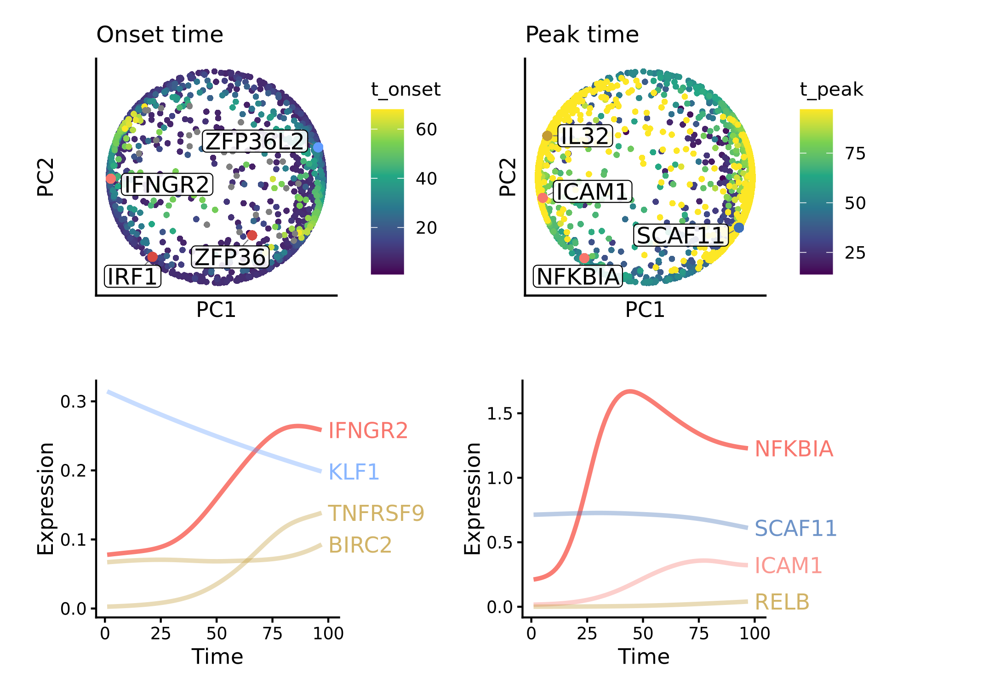

In [2876]:
# options(repr.plot.width = 7.25, repr.plot.height = 5)
# fig <- (p1 + p2)/(p4 + p5)
# fig

# # save as PDF
# ggsave(
#   filename = "../../../notebooks/figures/3c_OnsetPeakTimeExamples.pdf",
#   plot = fig,
#   width = 7.25,
#   height = 5,
#   units = "in",
#   device = cairo_pdf,
#   bg = "white"
# )

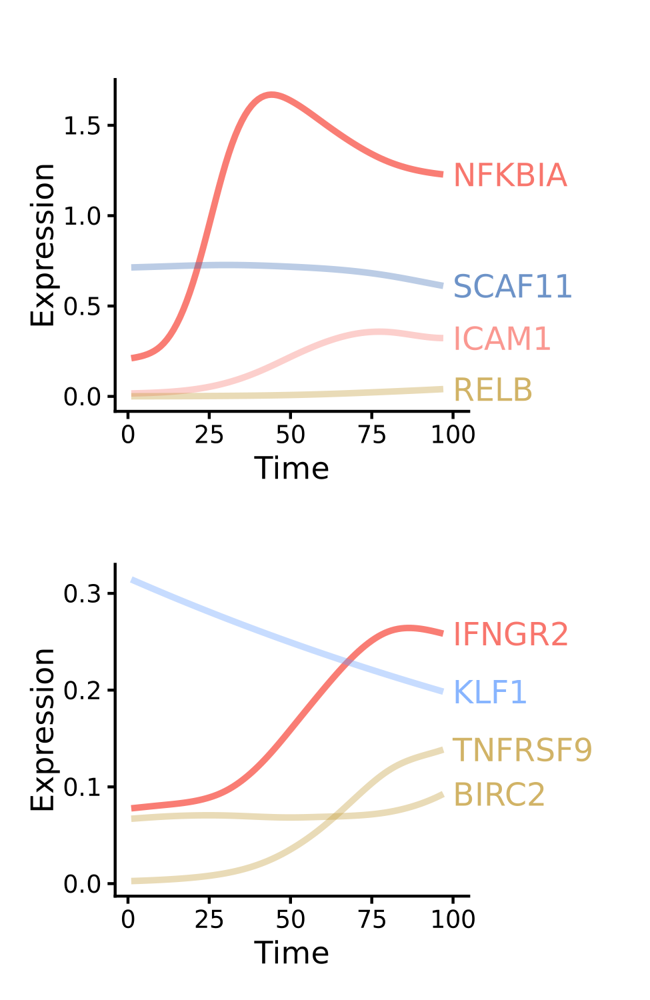

In [2918]:
options(repr.plot.width = 3.25, repr.plot.height = 5)
fig <- p5 / p4
fig

ggsave(
  filename = "../../../notebooks/figures/3c_OnsetPeakTimeExamples.pdf",
  plot = fig,
  width = 3.25,
  height = 5,
  units = "in",
  device = cairo_pdf,
  bg = "white"
)

  K562a 
"K562a" 


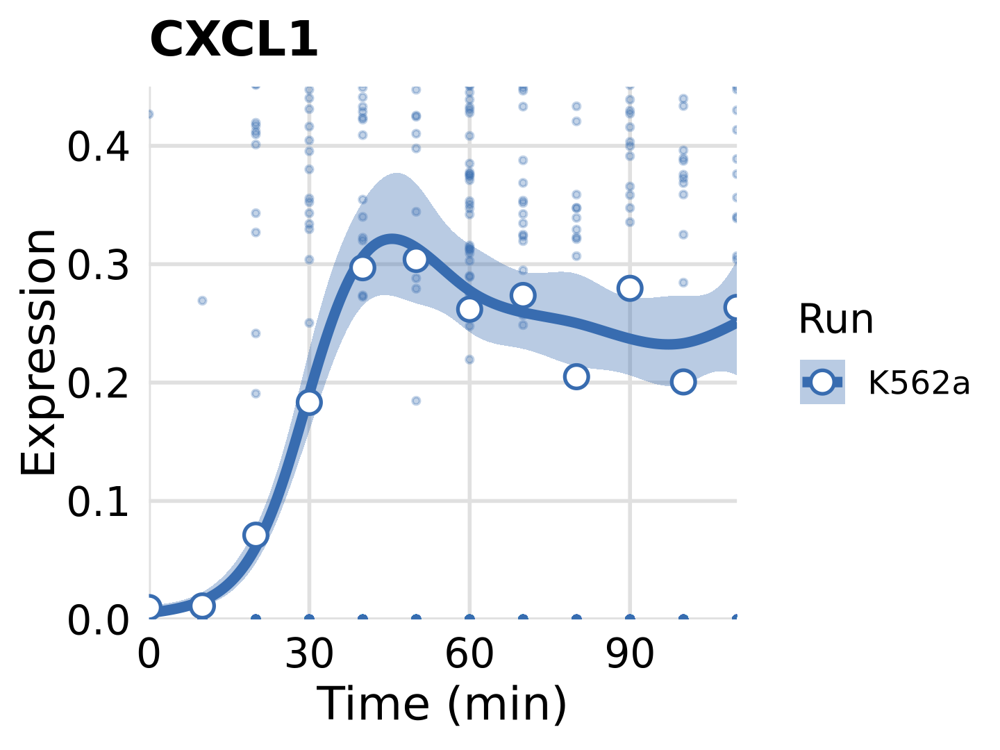

In [2952]:
options(repr.plot.width = 4.8, repr.plot.height = 3.6, repr.plot.res = 300)

time_map <- c(K562a = 110, K562_puro = 110, THP1 = 165, K562b = 165)  # adjust as needed
offset_map   = c(K562a = 0, K562_puro = 0, THP1 = -10, K562b = -68)

p <- plot_tradeSeq_gene_multirun_pub(
  gamList_ls     = gamList.ls,
  sce_ls         = sce.ls,
  counts_sub_ls  = counts_sub.ls,
  PT_ls          = PT.ls,
  sf_ls          = sf.ls,
  CW_ls          = CW.ls,          # or NULL
  # keys           = c("THP1","K562a","K562b", "K562_puro"),
  # keys           = c("K562a", "THP1"),
  keys           = c("K562a"),


  key_labels     = NULL,
  colours        = c(THP1="#222021", K562a="#386cb0", K562b="#DC143C", K562_puro="#FFA500"),

  offset_map = offset_map,
  time_max_map   = time_map,
  plot_normalized_pt = FALSE,

  x_tick_step    = 30,
  color_points_by_run = TRUE,
  points_size    = 0.75,
  points_alpha   = 0.30,

  show_legend    = TRUE,
  trim_before_zero = TRUE,

  gene = "CXCL1"
)
print(p)

In [2734]:
tmp = pc_df %>%
  filter(
    cell_type %in% cell_types,
    broad_cluster %in% dynamic_modes,
    qval_1 < 0.01, qval_1 != -1,
    abs(peak_log2fc) > 0.5
  )

In [2735]:
tmp %>% filter(cell_type == 'K562a', broad_cluster == 'impulse-up_1') %>% select(gene, cell_type, broad_cluster, qval_1, peak_log2fc)

,gene,cell_type,broad_cluster,qval_1,peak_log2fc
,<chr>,<chr>,<fct>,<dbl>,<dbl>
NFKBIA_K562a,NFKBIA,K562a,impulse-up_1,0.000000e+00,4.1966029
CXCL3_K562a,CXCL3,K562a,impulse-up_1,0.000000e+00,4.3506997
CD69_K562a,CD69,K562a,impulse-up_1,0.000000e+00,5.3710978
ARL4A_K562a,ARL4A,K562a,impulse-up_1,0.000000e+00,0.7649345
ICAM1_K562a,ICAM1,K562a,impulse-up_1,0.000000e+00,4.7119704
CXCL8_K562a,CXCL8,K562a,impulse-up_1,0.000000e+00,4.5447981
BTG2_K562a,BTG2,K562a,impulse-up_1,0.000000e+00,2.8236546
BIRC3_K562a,BIRC3,K562a,impulse-up_1,0.000000e+00,5.0546051
DDIT4_K562a,DDIT4,K562a,impulse-up_1,0.000000e+00,2.2167684


In [2738]:
cell_types <- c("THP1", "K562a")
dynamic_modes <- levels(pc_df$broad_cluster)

foreground_df <- pc_df %>%
  filter(
    cell_type %in% cell_types,
    broad_cluster %in% dynamic_modes,
    qval_1 < 0.05, qval_1 != -1,
    abs(peak_log2fc) > 0.5
  ) %>%
  arrange(cell_type, broad_cluster, desc(waldStat_1)) %>%
  group_by(cell_type, broad_cluster) %>%
  summarise(
    foreground_genes = paste(gene, collapse = ", "),
    n_genes = dplyr::n(),
    .groups = "drop"
  ) %>%
  transmute(
    cell_type,
    dynamic_mode = broad_cluster,
    foreground_genes,
    n_genes
  ) %>%
  complete(
    cell_type = cell_types,
    dynamic_mode = dynamic_modes,
    fill = list(
      foreground_genes = "",
      n_genes = 0L
    )
  ) %>%
  arrange(
    match(cell_type, cell_types),
    match(dynamic_mode, dynamic_modes)
  )

foreground_df
# write.csv(foreground_df, 'foreground_df.q001.fc05.csv')

cell_type,dynamic_mode,foreground_genes,n_genes
<chr>,<chr>,<chr>,<int>
THP1,impulse-up_1,"CXCL8, CCL4, TNFAIP2, CCL4L2, NFKBIA, SOD2, CCL3, CXCL3, CXCL1, CCL3L3, CCL20, PLEK, G0S2, IL1B, BTG1, ICAM1, PNRC1, NFE2L2, RND3, CXCL2, MFSD2A, MARCKS, OGFRL1, MSC, HSP90AA1, REL, ZBTB10, CD44, PTGER4, EBI3, HSPA1B, PIM3, SAT1, ATP2B1, BIRC3, IFNGR2, NRP2, ZC3H12A, EIF1, NINJ1, HSPA1A, NBN, ZC3H12C, BHLHE22, SLC2A6, GBP2, ACVR2A, CD40, ETV3, LUCAT1, TWIST1, HSPH1, ATP2B1-AS1, RNF228, SERPINE2, OTUD1, IER5, KLF3, TNFRSF9, B4GALT5, NKX3-1, TXNRD1, BCL6, ITGAV, DUSP1, SQLE, ATF3, RAP2C, TNFSF15, IER3, SGTB, ALAS1, CCN2, TIFA, ZEB2, SAMTOR, TLR2, CPEB2, RSRC2, ATF5, LINC01050, NPLOC4, DUSP4, CFLAR, HS3ST3B1, SWAP70, SVBP, MTF1, KLF7, MTSS1, HMGCS1, GUCY1A2, PDE4B",93
THP1,impulse-up_2,"TNFAIP3, CITED4, NFKBIZ, KLF6, JUN, ZFP36L1, TNF, PPP1R15A, ARRDC3, MAILR, MIR155HG, ZFP36, GEM, BTG2, RUNX3, ANKRD12, JUNB, RASGEF1B, TNFSF9, TPRA1, RHOQ, CITED2, NOTCH1",23
THP1,transient-down,"HSD17B4, CFL1, XACT",3
THP1,trend-down_1,"HES1, TIPARP, TENT5A, MEF2C, FOXO3, ELF1, IRF2BP2, PDK4, ARL4C, LPAR6, SLA, RCSD1, FGD4, RNF19A, MALAT1, AKAP13, MAFB, ARHGAP30, GZF1, TLN1, P2RY6, IPCEF1, MIDEAS, CREBRF, TALAM1, MAP3K5-AS2, IFI16, DAB2, N4BP2L2, MBNL1, TASOR, TBL1XR1, MTF2, PLEKHF1, SRSF5, MARCHF1, GALM, CYTH4, MTUS1-DT, CXCR4, FNDC3A, PTPRC, MAF, REV3L, TRPS1, XPO1, RNPC3, LINC01094, CNST, SAMHD1, HIC1, GADD45B, TAGAP, SPN, ITSN1, ABHD2, SETX, ZBTB1, RLF, OFD1, BNIP2, ATM, RCBTB2, CNTRL, CCDC144NL-AS1, ZFX, RESF1, OSGEP, NR4A2, ERV3-1, PTPRE, SATB1, NABP1, C3orf62, LCA5, AP1S2, SLC11A1, CSTF1, RANBP2, ZRANB2, FBXO32, KLF10, STARD13, PAG1, OSBPL1A, FCGR1A, MR1, SF3A3, SNX2, IGF2R, ENOSF1, INPP4A, BCOR, RELL1, PDP1, CRYBG3",96
THP1,trend-down_2,"PCM1, CYP1B1, FYB1, MBP, PHF3, SCAF11, SNHG14, BHLHE41, ZNF292, ARID4A, CEP170, CD14, CEBPA, TNFRSF1B, GPR183, LBR, PABPC4, PIK3R1, ZNF106, KIAA0930, SMARCA2, PPCS, GCLC, TSNAX, SETDB2, THRAP3, RBPJ, PNISR, ACTR2, IL6R, HMGB3, BAZ2B, RAB11FIP1, CSF3R, ESCO1, AAK1, TNRC18, PRDM1, TOB2, VPS13C",40
THP1,trend-up,"TNFAIP6, DNAJA1, TNFAIP8, NFKB1, CD83, USP12, CCL5, EHD1, KYNU, FTH1, TNIP1, PPP1R15B, PEA15, CEBPD, MSANTD3, BTG3, TRAF1, KMO, TXN, EMP3, TANK, DRAM1, BCL2A1, TPM4, KANK1, XBP1, SLC7A11, ACSL1, STK17A, LGALS3, CTSZ, GRAMD2B, GBP1, KDM6B, TNIP2, PTX3, IGFBP3, WTAPP2, IL7R, BAZ1A, RNF19B, TRIP10, NIFK, DNAJB6, VASP, SOCS3, VIM, CLIC4, SQOR, RASSF5, ETS1, KCNN2, PVR, CRIM1, MCOLN2, IL32, RELB, TP53BP2, ASAP1, FOSL1, KCNJ2, NID1, RDX, SDC4, AMPD3, ELOA, NMT2, HCK, PITPNB, MSC-AS1, CDC42SE1, NUB1, CHMP4B, DOT1L, CSTB, IL4I1, S100A10, FABP4, RNF145, NOP16, CHORDC1, ZNF697, PDE4DIP, EPOP, CCL2, VCP, RIT1, OPN3, DNAJB1, PHLDA2, MGLL, KLF2-DT, STK26, PPP1R2, CD58, CDC37L1, RABIF, EFHD2, PDGFB, TCF7L2, PSD3, IRAK2, OPTN",103
K562a,impulse-up_1,"NFKBIA, CXCL3, CD69, ARL4A, ICAM1, CXCL8, BTG2, BIRC3, DDIT4, IFNGR2, CXCL1, NINJ1, IER3, BTG1, LRG1, JUNB, SERPINE1, SDC4, MYC, CXCL2, TIFA, NFKBIE, PIM3, TAPBP, PLAU, BBC3, TNFAIP3, MXD1, RRAD, SESN2, BCL3, FBXO48, REL, CCND1, TLNRD1, PPP1R10, E2F3, DDX3X, CCL2, PMAIP1, TAL2, TGIF1, FOXA3, TM9SF2, MIR223HG, ALDOA, CCDC174, GADD45A, ANLN, SLC43A3, TMOD1, NFKBIB, EFNA1, TMEM131L, CHAC1, ATF3, CNEP1R1, PLK3, RHOG, PRPF8, PARD6B, PANX1, IL6, DDB1, N4BP3, PFKL, SEL1L3, SLC39A1, KLRK1-AS1, MTCO1P2, COG4",71
K562a,impulse-up_2,"HES1, IRF1, KLF6, JUN, KLF10, NCEH1, NFKBIZ, ZFP36L1, GADD45B, NAB2, ATP2C1, ACTN4, SERBP1P3, ARCN1, ZFP36, PHLDA1, GDF15, NEK7, AMN1, RRP36, BPNT2, ARHGEF26, IKZF5, KDM3A, EXPH5, CLASRP, EPC1, KIF18A, TPM3P8, NLRP2, SMURF2, TNFRSF12A, ATF1, ASAP3, ZNF92, ADAM15, ZNF816, CENPQ",38
K562a,transient-down,"SYMPK, HUS1, TNKS1BP1, PI4K2B, VCF2, VPS33B, CCHCR1",7


  K562a    THP1 
"K562a"  "THP1" 


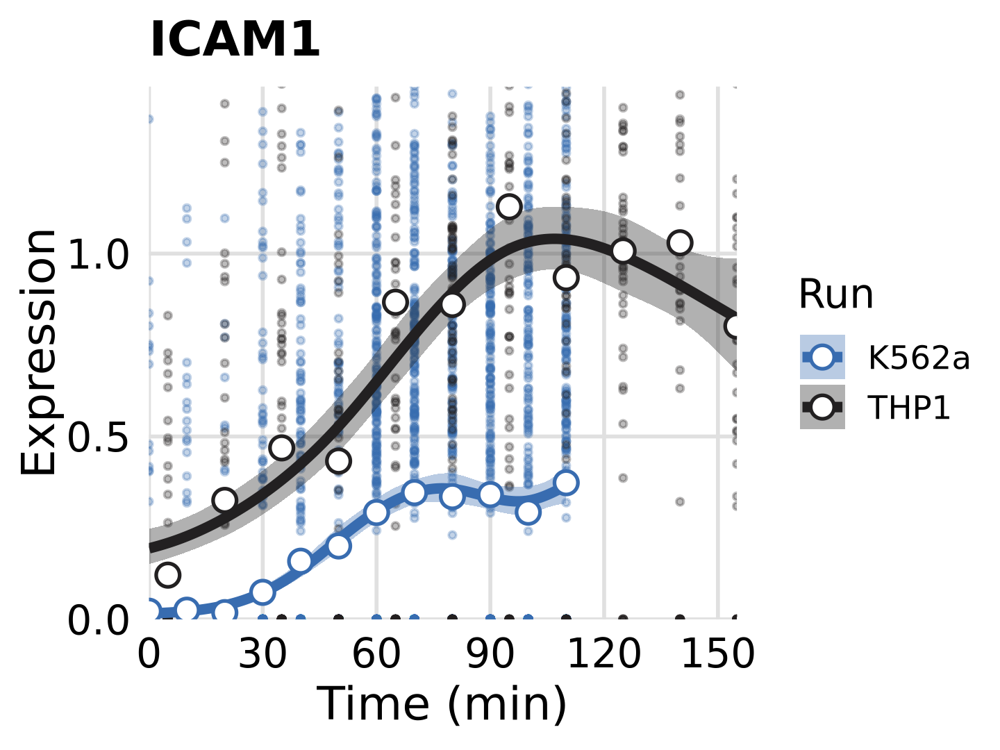

In [2742]:
options(repr.plot.width = 4.8, repr.plot.height = 3.6, repr.plot.res = 300)

time_map <- c(K562a = 110, K562_puro = 110, THP1 = 165, K562b = 165)  # adjust as needed
offset_map   = c(K562a = 0, K562_puro = 0, THP1 = -10, K562b = -68)

p <- plot_tradeSeq_gene_multirun_pub(
  gamList_ls     = gamList.ls,
  sce_ls         = sce.ls,
  counts_sub_ls  = counts_sub.ls,
  PT_ls          = PT.ls,
  sf_ls          = sf.ls,
  CW_ls          = CW.ls,          # or NULL
  # keys           = c("THP1","K562a","K562b", "K562_puro"),
  keys           = c("K562a", "THP1"),


  key_labels     = NULL,
  colours        = c(THP1="#222021", K562a="#386cb0", K562b="#DC143C", K562_puro="#FFA500"),

  offset_map = offset_map,
  time_max_map   = time_map,
  plot_normalized_pt = FALSE,

  x_tick_step    = 30,
  color_points_by_run = TRUE,
  points_size    = 0.75,
  points_alpha   = 0.30,

  show_legend    = TRUE,
  trim_before_zero = TRUE,

  gene = "ICAM1"
)
print(p)

In [2746]:
cell_types <- c("THP1", "K562a")
dynamic_modes <- levels(pc_df$broad_cluster)

foreground_df <- pc_df %>%
  filter(
    cell_type %in% cell_types,
    broad_cluster %in% dynamic_modes,
    pvalue_1 < 0.05,
    abs(peak_log2fc) > 0.5
  ) %>%
  arrange(cell_type, broad_cluster, desc(waldStat_1)) %>%
  group_by(cell_type, broad_cluster) %>%
  slice_head(n = 100) %>%
  summarise(
    foreground_genes = paste(gene, collapse = ", "),
    .groups = "drop"
  ) %>%
  transmute(
    cell_type,
    dynamic_mode = broad_cluster,
    foreground_genes
  ) %>%
  complete(
    cell_type = cell_types,
    dynamic_mode = dynamic_modes,
    fill = list(foreground_genes = "")
  ) %>%
  arrange(
    match(cell_type, cell_types),
    match(dynamic_mode, dynamic_modes)
  )

foreground_df <- foreground_df %>%
  mutate(
    n_genes = if_else(
      is.na(foreground_genes) | foreground_genes == "",
      0L,
      str_count(foreground_genes, ",") + 1L
    )
  )

foreground_df

cell_type,dynamic_mode,foreground_genes,n_genes
<chr>,<chr>,<chr>,<int>
THP1,impulse-up_1,"CXCL8, CCL4, TNFAIP2, CCL4L2, NFKBIA, SOD2, CCL3, WTAP, CXCL3, CXCL1, CCL3L3, CCL20, PLEK, G0S2, IL1B, BTG1, ICAM1, PNRC1, NFE2L2, RND3, CXCL2, MFSD2A, MARCKS, OGFRL1, MSC, HSP90AA1, REL, ZBTB10, CD44, PTGER4, EBI3, HSPA1B, PIM3, SAT1, ATP2B1, BIRC3, IFNGR2, NRP2, ZC3H12A, EIF1, NINJ1, HSPA1A, NBN, ZC3H12C, BHLHE22, SLC2A6, GBP2, ACVR2A, CD40, ETV3, LUCAT1, TWIST1, HSPH1, ATP2B1-AS1, RNF228, SERPINE2, OTUD1, IER5, KLF3, TNFRSF9, B4GALT5, NKX3-1, TXNRD1, BCL6, ITGAV, DUSP1, SQLE, ATF3, RAP2C, TNFSF15, IER3, SGTB, ALAS1, LRP12, CCN2, TIFA, ZEB2, SAMTOR, TLR2, CPEB2, RSRC2, ATF5, LINC01050, NPLOC4, DUSP4, CFLAR, HS3ST3B1, SWAP70, SVBP, MTF1, KLF7, MTSS1, HMGCS1, GUCY1A2, PDE4B, FMNL3, RNF144B, DNAJB4, GLIS3, NFKBIE",100
THP1,impulse-up_2,"TNFAIP3, CITED4, NFKBIZ, KLF6, JUN, ZFP36L1, TNF, PPP1R15A, ARRDC3, MAILR, MIR155HG, ZFP36, GEM, BTG2, RUNX3, SGK1, ANKRD12, JUNB, RASGEF1B, TNFSF9, TPRA1, RHOQ, CITED2, NOTCH1, USP1, RGS1, MROCKI, JUND, IWS1, MIR3142HG, EMSY, GAS7, RREB1, DDX59, TMEM86A, SH3BP2, LINC03108, PUS3, TMEM245, CASP3, DTX3L, PIM1, UGCG, DUSP10, MIR17HG, ACBD6, TMEM51, RNF24, ENG, VDR, PPP6C, NFKBID, DUSP2, SNRNP25, LEMD2, MAP7, DSN1, SUMF2, MAFF, DSC2, SUPT4H1, SMURF2, MYADM, RDH14, ICAM4, PPP3CC, HIPK3, TTK, G6PD, SLCO3A1, TCEAL1, SETD7, MSH2, TICAM1, ZYX, ASTE1, ZNG1B",77
THP1,transient-down,"HSD17B4, CFL1, XACT, MCL1, CC2D1B, ASH1L, ARID5B, NAV3, PHF13, DNAJC2, C2, TAB2, CDK5RAP2, NUPR1, TMED9, ARHGAP26, PIAS2, CKS1B, BBS2, PTCD3, BACH1, DHFR, DDX55, B4GAT1, FAM98C, ZNF383, NDUFAF1, SPIN1, JOSD2, SLC16A1, TPM1, INTU, HSPA14, PPP4C, PTPA, APBA2, CYTIP, PRKACA, TFRC, CDK5RAP1, SNRNP200",41
THP1,trend-down_1,"HES1, TIPARP, TENT5A, MEF2C, FOXO3, ELF1, IRF2BP2, PDK4, ARL4C, LPAR6, SLA, JMJD1C, RCSD1, FGD4, RNF19A, MALAT1, AKAP13, MAFB, ARHGAP30, GZF1, TLN1, P2RY6, IPCEF1, PARP1, MIDEAS, MIS18BP1, CREBRF, TALAM1, MAP3K5-AS2, IFI16, DAB2, N4BP2L2, MBNL1, TASOR, TBL1XR1, MTF2, PLEKHF1, SRSF5, MARCHF1, GALM, CYTH4, MTUS1-DT, CXCR4, FNDC3A, PTPRC, MAF, REV3L, TRPS1, XPO1, RNPC3, LINC01094, CNST, SAMHD1, HIC1, GADD45B, TAGAP, SPN, ITSN1, ABHD2, SETX, ZBTB1, RLF, OFD1, BNIP2, ATM, RCBTB2, CNTRL, CCDC144NL-AS1, ZFX, RESF1, OSGEP, NR4A2, ERV3-1, PTPRE, SATB1, NABP1, C3orf62, LCA5, AP1S2, SLC11A1, CSTF1, RANBP2, ZRANB2, FBXO32, KLF10, STARD13, PAG1, OSBPL1A, FCGR1A, MR1, SF3A3, SNX2, IGF2R, ENOSF1, INPP4A, BCOR, RELL1, PDP1, CRYBG3, CEPT1",100
THP1,trend-down_2,"PCM1, SMAP2, ID2, CYP1B1, FYB1, MBP, PHF3, SCAF11, SNHG14, BHLHE41, ZNF292, ARID4A, CEP170, CD14, CEBPA, TNFRSF1B, GPR183, LBR, PABPC4, PIK3R1, PHIP, ZNF106, EPRS1, KIAA0930, SMARCA2, U2SURP, PPCS, GCLC, TSNAX, SETDB2, THRAP3, RBPJ, PNISR, ACTR2, IL6R, HMGB3, TAOK3, BAZ2B, RAB11FIP1, CSF3R, ESCO1, AAK1, TNRC18, LCORL, PRDM1, TOB2, VPS13C, TPP2, ZFP36L2, AFF4, GIGYF2, DDX6, ELF2, OGA, PTP4A2, TXNIP, PHLDA1, PRR14L, SREK1, TMF1, WNK1, ETV5, TPR, CPM, NUFIP2, WHAMM, WASHC4, TNPO1, ZNF366, YTHDC1, MNDA, KLHL24, SRRM2, DOK2, FNIP2, VIRMA, USP2, SBNO1, PRPF38B, CEP350, MFSD4B, ZNF217, PSIP1, CMIP, RABL6, ZYG11B, ZKSCAN1, UBASH3B, FCHO2, SHOX2, C5AR1, PCF11, KDM5A, ZCCHC2, METTL14, PPP4R3A, PCMTD1, SYK, H1-0, MANBA",100
THP1,trend-up,"SQSTM1, TNFAIP6, DNAJA1, TNFAIP8, NFKB1, CD83, USP12, CCL5, EHD1, KYNU, FTH1, TNIP1, PPP1R15B, PEA15, B2M, CEBPD, MSANTD3, EIF5, BTG3, TRAF1, KMO, TXN, EMP3, TANK, DRAM1, BCL2A1, TPM4, KANK1, XBP1, SLC7A11, ACSL1, STK17A, LGALS3, CTSZ, GRAMD2B, GBP1, KDM6B, TNIP2, PTX3, IGFBP3, WTAPP2, IL7R, BAZ1A, RNF19B, TRIP10, MSN, NIFK, DNAJB6, VASP, SOCS3, VIM, CLIC4, SQOR, RASSF5, ETS1, KCNN2, PVR, CORO1C, CRIM1, MCOLN2, IL32, RELB, TP53BP2, ASAP1, FOSL1, LMNA, KCNJ2, NID1, RDX, SDC4, GCLM, AMPD3, ELOA, TUBA1C, NMT2, HCK, PITPNB, MSC-AS1, CDC42SE1, NUB1, CHMP4B, DOT1L, CSTB, IL4I1, ARF1, PLIN2, S100A10, FABP4, RNF145, NOP16, CHORDC1, ZNF697, PDE4DIP, EPOP, CCL2, VCP, RIT1, OPN3, DNAJB1, PHLDA2",100
K562a,impulse-up_1,"NFKBIA, CXCL3, CD69, ARL4A, ICAM1, CXCL8, BTG2, BIR

In [2385]:
foreground_df_ref = read.csv('foreground_df.2.csv')

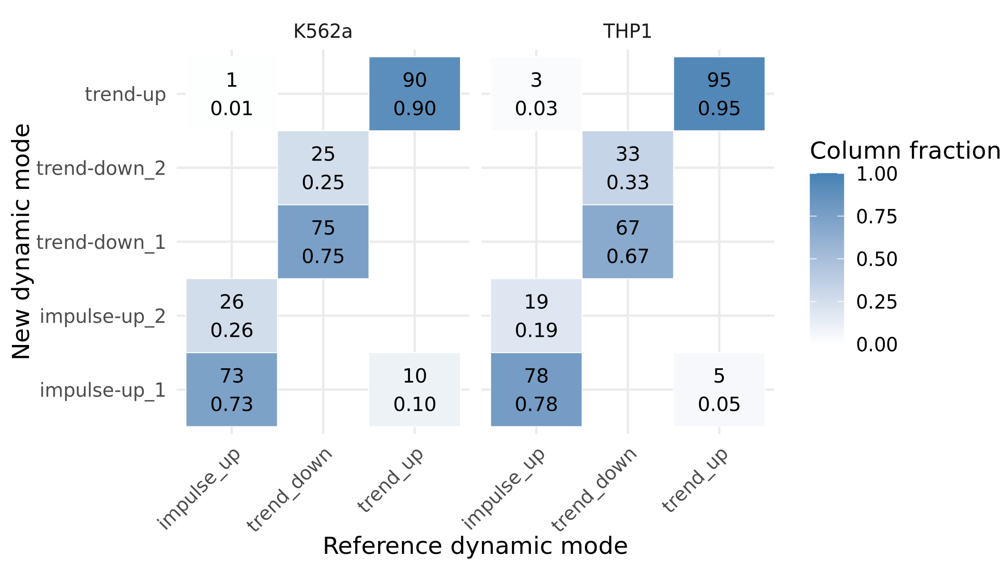

In [2402]:
library(dplyr)
library(tidyr)
library(stringr)
library(ggplot2)

plot_dynamic_mode_confusion <- function(
  foreground_df,
  foreground_df_ref,
  cell_types = c("THP1", "K562a"),
  plot_width = 10,
  plot_height = 10,
  plot_res = 300,
  text_size = 3.5
) {

  expand_foreground_genes <- function(df, mode_name) {
    out <- df %>%
      transmute(
        cell_type,
        mode = .data[["dynamic_mode"]],
        foreground_genes
      ) %>%
      mutate(gene = strsplit(foreground_genes, ",\\s*")) %>%
      unnest(gene) %>%
      mutate(gene = str_trim(gene)) %>%
      filter(!is.na(gene), gene != "") %>%
      select(cell_type, gene, mode)

    names(out)[names(out) == "mode"] <- mode_name
    out
  }

  fg_new <- expand_foreground_genes(
    foreground_df,
    "dynamic_mode_new"
  )

  fg_ref <- expand_foreground_genes(
    foreground_df_ref,
    "dynamic_mode_ref"
  )

  conf_long <- fg_new %>%
    inner_join(
      fg_ref,
      by = c("cell_type", "gene")
    )

  conf_df <- conf_long %>%
    dplyr::count(
      cell_type,
      dynamic_mode_new,
      dynamic_mode_ref,
      name = "n"
    )

  # ------------------------------------------------------------
  # Column-normalized:
  # for each reference mode, what fraction maps to each new mode?
  # ------------------------------------------------------------
  conf_prop <- conf_df %>%
    group_by(cell_type, dynamic_mode_ref) %>%
    mutate(
      prop = n / sum(n)
    ) %>%
    ungroup()

  options(
    repr.plot.width = plot_width,
    repr.plot.height = plot_height,
    repr.plot.res = plot_res
  )

  p <- ggplot(
    conf_prop %>%
      filter(cell_type %in% cell_types),
    aes(
      x = dynamic_mode_ref,
      y = dynamic_mode_new,
      fill = prop
    )
  ) +
    geom_tile(color = "white") +
    geom_text(
      aes(
        label = paste0(
          n, "\n",
          sprintf("%.2f", prop)
        )
      ),
      size = text_size
    ) +
    facet_wrap(~cell_type) +
    scale_fill_gradient(
      low = "white",
      high = "steelblue",
      limits = c(0, 1)
    ) +
    labs(
      x = "Reference dynamic mode",
      y = "New dynamic mode",
      fill = "Column fraction"
    ) +
    theme_minimal(base_size = 12) +
    theme(
      axis.text.x = element_text(
        angle = 45,
        hjust = 1
      )
    )

  print(p)

  invisible(list(
    plot = p,
    counts = conf_df,
    proportions = conf_prop,
    assignments = conf_long
  ))
}


# Example
res_conf <- plot_dynamic_mode_confusion(
  plot_width = 7,
  plot_height = 4,
  foreground_df = foreground_df,
  foreground_df_ref = foreground_df_ref,
  cell_types = c("THP1", "K562a")
)

In [2403]:
trendup_to_impulse <- conf_long %>%
  filter(
    dynamic_mode_ref == "trend_up",
    dynamic_mode_new %in% c("impulse-up_1", "impulse-up_2")
  ) %>%
  arrange(cell_type, dynamic_mode_new, gene)

trendup_to_impulse

cell_type,gene,dynamic_mode_new,dynamic_mode_ref
<chr>,<chr>,<chr>,<chr>
K562a,CNEP1R1,impulse-up_1,trend_up
K562a,COG4,impulse-up_1,trend_up
K562a,FOXA3,impulse-up_1,trend_up
K562a,GATA2,impulse-up_1,trend_up
K562a,LRG1,impulse-up_1,trend_up
K562a,MIR223HG,impulse-up_1,trend_up
K562a,MYC,impulse-up_1,trend_up
K562a,PANX1,impulse-up_1,trend_up
K562a,SLC39A1,impulse-up_1,trend_up
